In [1]:
import numpy as np
import pandas as pd
import os
from urllib.parse import unquote
import random
from time import sleep
import pickle
import json
import copy
import re
import regex
import matplotlib.pyplot as plt
import numpy as np
import ast
import parse
from glob import glob
import yaml
from itertools import cycle
import sys
import seaborn as sns
from transformers import AutoTokenizer
sys.path.append('../')
from utils import effective_path, extract_json_from_response, get_paths_real_sample, wikify_article_name, un_wikify_article_name
from urllib.parse import unquote
import math

#change default font size
plt.rcParams.update({'font.size': 14})



%load_ext autoreload
%autoreload 2

random.seed(42)
pd.set_option('display.max_colwidth', 1000)

PATH_IN = '../../data/wikispeedia/wikispeedia_paths-and-graph/'
LOGS_PATH = '../../logs/inference/'

/dlabdata1/charneca/miniconda3/envs/wikinav/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Functions and useful dfs

# Load real paths data
paths_real_df = pd.read_csv(os.path.join(PATH_IN, 'paths_real_processed.tsv'), sep='\t', low_memory=False)
shpl_paths_real_df = paths_real_df.query('is_path_finished==1').groupby(['src','tgt']).agg({'hpl':'min'}).reset_index()
spl_paths_real_df = paths_real_df.groupby(['src','tgt']).agg({'spl':'min'}).reset_index()
shepl_paths_real_df = paths_real_df.query('is_path_finished==1').groupby(['src','tgt']).agg({'shepl':'min'}).reset_index()
mhepl_paths_real_df = paths_real_df.query('is_path_finished==1').groupby(['src','tgt']).agg({'mhepl':'min'}).reset_index()

grouped_df = paths_real_df.groupby(['src','tgt','hepl']).agg({'path':'first'}).reset_index()

# get path with eff_length = mhepl
mhepl = mhepl_paths_real_df['mhepl'] # to save original

# round mhepl to nearest int (round up if .5)
mhepl_paths_real_df['mhepl'] = mhepl_paths_real_df['mhepl'].apply(lambda x: math.ceil(x))
print(mhepl_paths_real_df.query("src=='Anarcho-capitalism' and tgt=='Winston_Churchill'"))
mhepl_paths_real_df = mhepl_paths_real_df.rename(columns={'mhepl':'hepl'})
mhepl_paths_real_df = mhepl_paths_real_df.merge(grouped_df, on=['src','tgt','hepl'], how='left')
mhepl_paths_real_df = mhepl_paths_real_df.rename(columns={'hepl':'mhepl'})
mhepl_paths_real_df['mhepl'] = mhepl # restore original
mhepl_paths_real_df['effective_path_human'] = mhepl_paths_real_df['path'].apply(lambda x: effective_path(str(x)))
mhepl_paths_real_df = mhepl_paths_real_df.rename(columns={'path':'path_human'})

# the above as a function
def get_all_runs_df(folders, identifiers):
    all_runs_df = pd.DataFrame() # DataFrame to hold all runs

    for folder in folders:
        # Load the configuration for each run
        with open(os.path.join(folder, '.hydra/config.yaml'), 'r') as f:
            config = yaml.safe_load(f)
            config_dict = {}                  
            for identifier in identifiers:
                identifier_keys = identifier.split('.')
                # Extract the identifier value from the config
                config_value = config
                for key in identifier_keys:
                    config_value = config_value.get(key)
                config_dict[identifier] = config_value

        config_dict['run_id'] = folder.split('/')[-2]
        print(config_dict)

        # Load the run data
        run_df = pd.read_csv(os.path.join(folder, 'agent_runs.tsv'), sep='\t')
        
        run_df['src'] = run_df['src'].apply(lambda x: unquote(unquote(x)))
        run_df['tgt'] = run_df['tgt'].apply(lambda x: unquote(unquote(x)))
        run_df['cur'] = run_df['cur'].apply(lambda x: unquote(unquote(x)))

        # unquote path_so_far
        run_df['path_so_far'] = run_df['path_so_far'].apply(lambda x: unquote(unquote(x)))
        
        # add columns
        run_df = run_df.merge(shpl_paths_real_df, on=['src', 'tgt'], how='left')
        run_df = run_df.merge(spl_paths_real_df, on=['src', 'tgt'], how='left')
        run_df = run_df.merge(shepl_paths_real_df, on=['src', 'tgt'], how='left')
        run_df = run_df.merge(mhepl_paths_real_df, on=['src', 'tgt'], how='left')
        run_df['error_type'] = run_df['action'].apply(lambda x: "no_error" if "{'next_page'" in x else "PageNotInCands" if "Try a different page" in x else "BackOnFirstPage" if "Cannot go back any further" in x else "BadResponse")
        run_df['path_len'] = run_df['path_so_far'].apply(lambda x: len(x.split(';'))) #should be len-1 but we automatically click on final page
        run_df['effective_path_so_far'] = run_df['path_so_far'].apply(lambda x: effective_path(x))
        run_df['effective_path_len'] = run_df['path_so_far'].apply(lambda x: len(effective_path(x).split(';')))
        run_df['diff_from_best_human'] = run_df['path_len'] - run_df['hpl']
        run_df['overhead_spl'] = run_df['effective_path_len']/run_df['spl']
        run_df['overhead_shepl'] = run_df['effective_path_len']/run_df['shepl']
        run_df['overhead_mhepl'] = run_df['effective_path_len']/run_df['mhepl']
        run_df['human_overhead_spl'] = run_df['mhepl']/run_df['spl']
        run_df['success'] = run_df['is_finished_reason'].apply(lambda x: 1 if x=='success' else 0)
        run_df['long_path'] = run_df['overhead_spl'].apply(lambda x: 1 if x>2 else 0)



        # Add identifier columns to the run data DataFrame
        for key, value in config_dict.items():
            run_df[key] = value

        ### careful with this one
        def get_prompting_type(row):
            string = ""
            if 'embedding' in row['agent.agent_name']:
                return "Embedding"
            if 'reason' in row['agent.agent_name']:
                string += "ReAct_"
            else:
                string += "Act_"
            if "link_click" in row['agent.agent_name']:
                string += "linkclick"
            elif "navigate" in row['agent.agent_name']:
                string += "navigate"
            else:
                string += "other"

            if not "lmql" in row['agent.agent_name']:
                string += "_unconstrained"

            return string
        
        run_df['prompting'] = run_df.apply(lambda row: get_prompting_type(row), axis=1)

        # Concatenate this run's DataFrame to the main DataFrame
        all_runs_df = pd.concat([run_df, all_runs_df], ignore_index=True)

    return all_runs_df

articles_file = os.path.join(PATH_IN, 'articles-new.tsv')
articles_df = pd.read_csv(articles_file, sep='\t', header=None, names=['article'])
# decode the articles
articles_df['article'] = articles_df['article'].apply(lambda x: unquote(unquote(x)))

article_spl_file = os.path.join(PATH_IN, 'shortest-path-distance-matrix-new.txt')
# this file is a matrix with the shortest path length between each pair of articles, in the same order as in articles.tsv. A row of the matrix is like:___121__1, where _ is when the article cannot be reached from the other article
# let's open it and translate it to a dataframe with columns: src, tgt, spl
with open(article_spl_file, 'r') as f:
    spl_file_text = f.readlines()

#function that, given a src and tgt article, finds the spl between them
def get_spl(src, tgt):
    src_id = articles_df[articles_df['article']==src].index[0]
    tgt_id = articles_df[articles_df['article']==tgt].index[0]
    spl = spl_file_text[src_id][tgt_id]
    if spl=='_':
        return np.nan
    else:
        return int(spl)


                     src                tgt  mhepl
1482  Anarcho-capitalism  Winston_Churchill      3


In [9]:
get_spl('Anarcho-capitalism', 'Winston_Churchill')

2

In [68]:
paths_real_df.query('src=="Anarcho-capitalism" and tgt=="Winston_Churchill"')

,hashed_ip,timestamp,src,tgt,is_path_finished,failure_type,path,hpl,spl,duration_in_sec,target_in_degree,user_path_rating,effective_path,hepl,shpl,shepl,mhepl
32350,3cccd5193ac6e50b,1248794917,Anarcho-capitalism,Winston_Churchill,1,NaN,Anarcho-capitalism;Political_philosophy;Democracy;World_War_I;British_Empire;United_Kingdom;Prime_Minister_of_the_United_Kingdom;Winston_Churchill,7,2,133,85,1.0,Anarcho-capitalism;Political_philosophy;Democracy;World_War_I;British_Empire;United_Kingdom;Prime_Minister_of_the_United_Kingdom;Winston_Churchill,7,2.0,2.0,2.5
32351,2b0643e36ee3b23f,1256432681,Anarcho-capitalism,Winston_Churchill,1,NaN,Anarcho-capitalism;John_Locke;England;Winston_Churchill,3,2,36,85,2.0,Anarcho-capitalism;John_Locke;England;Winston_Churchill,3,2.0,2.0,2.5
32352,790e35411b2987eb,1274052798,Anarcho-capitalism,Winston_Churchill,1,NaN,Anarcho-capitalism;Capitalism;<;Cold_War;United_Kingdom;<;Winston_Churchill,6,2,192,85,NaN,Anarcho-capitalism;Cold_War;Winston_Churchill,2,2.0,2.0,2.5
32353,23e9898629635546,1298829895,Anarcho-capitalism,Winston_Churchill,1,NaN,Anarcho-capitalism;Cold_War;Winston_Churchill,2,2,67,85,1.0,Anarcho-capitalism;Cold_War;Winston_Churchill,2,2.0,2.0,2.5


In [18]:
# list all agent_ids that haven't finished the game (their last action has is_finished=False)
# group by agent_id and get the last action for each agent_id

unfinished = all_runs_df.groupby('agent_id').agg({'is_finished':'last'}).query('is_finished==False').reset_index()['agent_id'].unique().tolist()
print(unfinished)

[3, 5, 7, 8, 12, 15, 16, 17, 19, 21, 24, 28, 30, 32, 33, 34, 36, 37, 40, 51, 54, 56, 59, 60, 67, 72, 73, 78, 80, 81, 84, 85, 86, 87, 89, 91, 95, 99, 100, 101, 102, 104, 105, 107, 112, 114, 117, 124, 125, 130, 134, 141, 143, 144, 146, 148, 155, 156, 157, 159, 165, 166, 168, 172, 173, 177, 180, 183, 185, 186, 189, 194, 195, 196, 197, 198, 201, 204, 206, 212, 215, 221, 223, 224, 227, 228, 229, 234, 235, 236, 237, 240, 241, 242, 250, 252, 255, 257, 259, 262, 263, 269, 272, 277, 283, 285, 286, 291, 292, 295, 300, 302, 308, 312, 313, 314, 316]


# Part 1 - LinkClick Hyperparams

## Plot 1 - Constrained vs Unconstrained decoding - Act prompt
Bar plot: Constrained vs Unconstrained decoding - Act prompt
- y-axis is the success rate
- each x-tick is a model name with 2 bars (unconstrained, constrained)


In [68]:

# Specify the paths to the folders containing the runs
folders = []
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_1_1/2023-12-18_18-49-40/*/"))] #mistral const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_1_2/2023-12-18_19-03-33/*/"))] #llama 7b const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_4/2023-12-18_20-20-08/*/"))] #llama 7b unconst
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_4/2023-12-18_19-21-40/*/"))] #mistral unconst
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_5/2023-12-22_15-43-25/*/"))] #llama 70b unconst
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_3_1/2023-12-21_10-45-05/*/"))] #llama 70b const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_5_gpt/2023-12-20_12-50-18/*/"))] # gpt-3.5 unconst with no backtrack

identifiers = ['model.model_name','agent.fewshot','agent.agent_name']

all_runs_df = get_all_runs_df(folders, identifiers)

# keep only relevant runs
all_runs_df = all_runs_df[
    ((all_runs_df['model.model_name']=='mistralai/Mistral-7B-Instruct-v0.2') & (all_runs_df['agent.fewshot']==1) & ((all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back') | (all_runs_df['agent.agent_name']=='link_click/dfs_back'))) |
    ((all_runs_df['model.model_name']=='meta-llama/Llama-2-7b-chat-hf') & (all_runs_df['agent.fewshot']==2) & ((all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back') | (all_runs_df['agent.agent_name']=='link_click/dfs_back'))) |
    ((all_runs_df['model.model_name']=='meta-llama/Llama-2-70b-chat-hf') & (all_runs_df['agent.fewshot']==2) & ((all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back') | (all_runs_df['agent.agent_name']=='link_click/dfs_back'))) |
    ((all_runs_df['model.model_name']=='gpt-3.5-turbo-1106') & (all_runs_df['agent.fewshot']==2) & ((all_runs_df['agent.agent_name']=='link_click/gpt_dfs')))
]
print(all_runs_df.columns)

{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 2, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '6'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 2, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '2'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 3, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '3'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 1, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '5'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 3, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '7'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 0, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 0, 'agent.agent_name': 'link_click/lmql_dfs_back_re

                     model.model_name  agent.fewshot  \
0                  gpt-3.5-turbo-1106              2   
1      meta-llama/Llama-2-70b-chat-hf              2   
5  mistralai/Mistral-7B-Instruct-v0.2              1   
3       meta-llama/Llama-2-7b-chat-hf              2   
6  mistralai/Mistral-7B-Instruct-v0.2              1   
2      meta-llama/Llama-2-70b-chat-hf              2   
4       meta-llama/Llama-2-7b-chat-hf              2   

           agent.agent_name                    prompting  success     error  
0        link_click/gpt_dfs  Act_linkclick_unconstrained    0.830  0.052191  
1       link_click/dfs_back  Act_linkclick_unconstrained    0.610  0.067768  
5       link_click/dfs_back  Act_linkclick_unconstrained    0.475  0.069383  
3       link_click/dfs_back  Act_linkclick_unconstrained    0.315  0.064540  
6  link_click/lmql_dfs_back                Act_linkclick    0.850  0.049612  
2  link_click/lmql_dfs_back                Act_linkclick    0.695  0.063969  
4  li

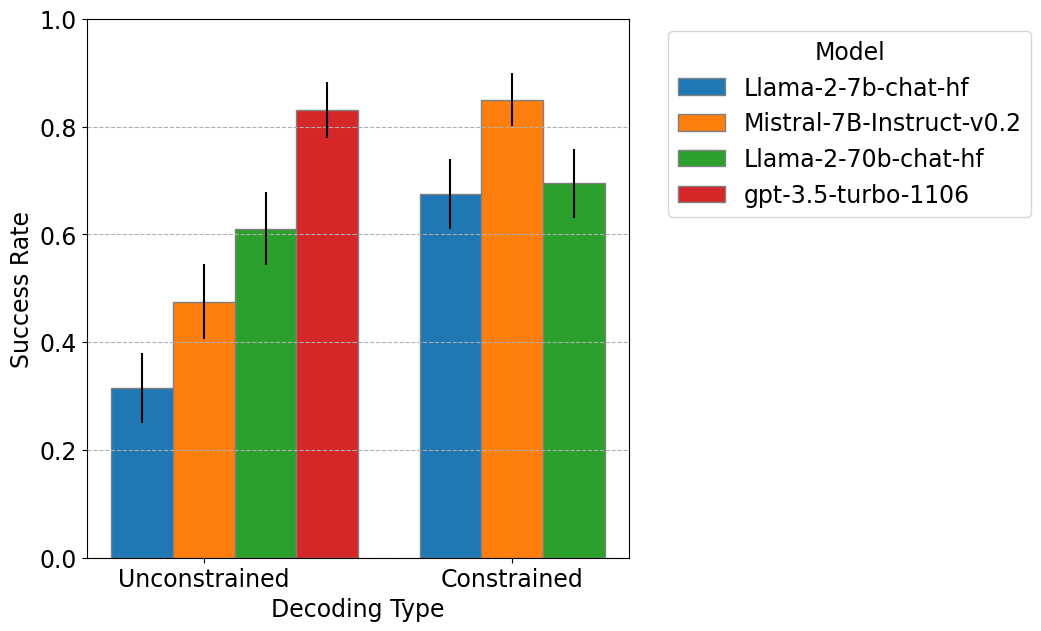

In [81]:
success_df = all_runs_df.query("is_finished==True").groupby(['model.model_name', 'agent.fewshot', 'agent.agent_name', 'prompting']).agg({'success':'mean'}).reset_index()
success_df['error'] = 1.96*all_runs_df.query("is_finished==True").groupby(['model.model_name', 'agent.fewshot', 'agent.agent_name', 'prompting']).agg({'success':'sem'}).reset_index()['success']

# Get unique model names and prompting types
# order the models by unconstrained success
success_df = success_df.sort_values(by=['prompting', 'success'], ascending=False)
print(success_df)

models = ['meta-llama/Llama-2-7b-chat-hf', 'mistralai/Mistral-7B-Instruct-v0.2', 'meta-llama/Llama-2-70b-chat-hf', 'gpt-3.5-turbo-1106']
prompting_types = success_df['prompting'].unique()
model_names = [model.split('/')[-1] for model in models]
fontsize=17

# Initialize the matplotlib figure
plt.figure(figsize=(7,7))

# Width of a bar
barWidth = 0.2

# Set positions of the bars on x-axis
positions = np.arange(len(prompting_types))

# Create bars for each model
for i, model in enumerate(models):
    model_data = success_df[success_df['model.model_name'] == model]
    if model=='gpt-3.5-turbo-1106':
        # only plot the unconstrained
        positions = np.arange(1)
    plt.bar(positions + i * barWidth, model_data['success'], yerr=model_data['error'], width=barWidth, edgecolor='grey', label=model_names[i])

# Add features to the plot
plt.xlabel('Decoding Type', fontsize=fontsize)
plt.ylabel('Success Rate', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.ylim(0,1)
plt.yticks(fontsize=fontsize)
plt.xticks(np.arange(len(prompting_types)) + barWidth, ['Unconstrained', 'Constrained'], fontsize=fontsize)
plt.legend(title='Model', title_fontsize=fontsize, bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=fontsize)
plt.savefig('plots/hyper_const_unconst_success.pdf', bbox_inches='tight')

# Create title & Show graphic
plt.show()


## Table 1 - Unconstrained decoding error types
- Each column a different type of error (PageNotInCands, etc), with %occurrence among all actions
- Final column with the total %errors among all actions
- Each row a different model (llama small, mistral, gpt, llama big)


In [89]:
full_error_type_df = all_runs_df.query('prompting=="Act_linkclick_unconstrained"')
full_error_type_df['is_no_error'] = full_error_type_df['error_type'].apply(lambda x: 1 if x=='no_error' else 0)
full_error_type_df['is_PageNotInCands'] = full_error_type_df['error_type'].apply(lambda x: 1 if x=='PageNotInCands' else 0)
full_error_type_df['is_BackOnFirstPage'] = full_error_type_df['error_type'].apply(lambda x: 1 if x=='BackOnFirstPage' else 0)
full_error_type_df['is_BadResponse'] = full_error_type_df['error_type'].apply(lambda x: 1 if x=='BadResponse' else 0)

error_type_df = full_error_type_df.groupby(['model.model_name']).agg({'is_no_error':['mean', 'sem'], 'is_PageNotInCands':['mean', 'sem'], 'is_BackOnFirstPage':['mean', 'sem'], 'is_BadResponse':['mean', 'sem']}).reset_index()
error_type_df['is_no_error_error'] = error_type_df['is_no_error']['sem']*1.96
error_type_df['is_PageNotInCands_error'] = error_type_df['is_PageNotInCands']['sem']*1.96
error_type_df['is_BackOnFirstPage_error'] = error_type_df['is_BackOnFirstPage']['sem']*1.96
error_type_df['is_BadResponse_error'] = error_type_df['is_BadResponse']['sem']*1.96

full_finished_reason_df_unconst = all_runs_df.query('prompting=="Act_linkclick_unconstrained" and is_finished==True')
full_finished_reason_df_unconst['is_success'] = full_finished_reason_df_unconst['is_finished_reason'].apply(lambda x: 1 if x=='success' else 0)
full_finished_reason_df_unconst['is_max_tries'] = full_finished_reason_df_unconst['is_finished_reason'].apply(lambda x: 1 if x=='max_tries' else 0)
full_finished_reason_df_unconst['is_max_actions'] = full_finished_reason_df_unconst['is_finished_reason'].apply(lambda x: 1 if x=='max_actions' else 0)

finished_reason_df_unconst = full_finished_reason_df_unconst.groupby(['model.model_name']).agg({'is_success':['mean', 'sem'], 'is_max_tries':['mean', 'sem'], 'is_max_actions':['mean', 'sem']}).reset_index()
finished_reason_df_unconst['is_success_error'] = finished_reason_df_unconst['is_success']['sem']*1.96
finished_reason_df_unconst['is_max_tries_error'] = finished_reason_df_unconst['is_max_tries']['sem']*1.96
finished_reason_df_unconst['is_max_actions_error'] = finished_reason_df_unconst['is_max_actions']['sem']*1.96

full_finished_reason_df_const = all_runs_df.query('prompting=="Act_linkclick" and is_finished==True')
full_finished_reason_df_const['is_success'] = full_finished_reason_df_const['is_finished_reason'].apply(lambda x: 1 if x=='success' else 0)
full_finished_reason_df_const['is_max_actions'] = full_finished_reason_df_const['is_finished_reason'].apply(lambda x: 1 if x=='max_actions' else 0)

finished_reason_df_const = full_finished_reason_df_const.groupby(['model.model_name']).agg({'is_success':['mean', 'sem'], 'is_max_actions':['mean', 'sem']}).reset_index()
finished_reason_df_const['is_success_error'] = finished_reason_df_const['is_success']['sem']*1.96
finished_reason_df_const['is_max_actions_error'] = finished_reason_df_const['is_max_actions']['sem']*1.96



/tmp/ipykernel_4175623/1102950427.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  full_error_type_df['is_no_error'] = full_error_type_df['error_type'].apply(lambda x: 1 if x=='no_error' else 0)
/tmp/ipykernel_4175623/1102950427.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  full_error_type_df['is_PageNotInCands'] = full_error_type_df['error_type'].apply(lambda x: 1 if x=='PageNotInCands' else 0)
/tmp/ipykernel_4175623/1102950427.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy o

In [97]:
error_type_df[['model.model_name', 'is_no_error', 'is_no_error_error', 'is_PageNotInCands', 'is_PageNotInCands_error', 'is_BackOnFirstPage', 'is_BackOnFirstPage_error', 'is_BadResponse', 'is_BadResponse_error']]

model.model_name is_no_error           is_no_error_error  \
                                             mean       sem                     
0                  gpt-3.5-turbo-1106    0.807587  0.009245          0.018121   
1      meta-llama/Llama-2-70b-chat-hf    0.623382  0.007238          0.014187   
2       meta-llama/Llama-2-7b-chat-hf    0.537008  0.006960          0.013641   
3  mistralai/Mistral-7B-Instruct-v0.2    0.622233  0.010877          0.021318   

  is_PageNotInCands           is_PageNotInCands_error is_BackOnFirstPage  \
               mean       sem                                       mean   
0          0.166575  0.008739                0.017128           0.000000   
1          0.376394  0.007238                0.014186           0.000000   
2          0.462992  0.006960                0.013641           0.000000   
3          0.350604  0.010704                0.020981           0.027163   

            is_BackOnFirstPage_error is_BadResponse            \
        sem                                    mean       sem   
0  0.000000                 0.000000       0.025838  0.003721   
1  0.000000                 0.000000       0.000223  0.000223   
2  0.000000                 0.000000       0.000000  0.000000   
3  0.003647                 0.007148       0.000000  0.000000   

  is_BadResponse_error  
                        
0             0.007293  
1             0.000437  
2             0.000000  
3             0.000000

In [100]:
finished_reason_df_unconst[['model.model_name', 'is_success', 'is_success_error', 'is_max_tries', 'is_max_tries_error', 'is_max_actions', 'is_max_actions_error']]

model.model_name is_success           is_success_error  \
                                            mean       sem                    
0                  gpt-3.5-turbo-1106      0.830  0.026628         0.052191   
1      meta-llama/Llama-2-70b-chat-hf      0.610  0.034576         0.067768   
2       meta-llama/Llama-2-7b-chat-hf      0.315  0.032929         0.064540   
3  mistralai/Mistral-7B-Instruct-v0.2      0.475  0.035400         0.069383   

  is_max_tries           is_max_tries_error is_max_actions            \
          mean       sem                              mean       sem   
0        0.130  0.023840           0.046726          0.040  0.013891   
1        0.205  0.028618           0.056091          0.185  0.027526   
2        0.445  0.035229           0.069049          0.240  0.030275   
3        0.505  0.035442           0.069467          0.020  0.009924   

  is_max_actions_error  
                        
0             0.027227  
1             0.053950  
2             0.059339  
3             0.019452

In [99]:
finished_reason_df_const

model.model_name is_success           is_max_actions  \
                                            mean       sem           mean   
0      meta-llama/Llama-2-70b-chat-hf      0.695  0.032637          0.305   
1       meta-llama/Llama-2-7b-chat-hf      0.675  0.033202          0.325   
2  mistralai/Mistral-7B-Instruct-v0.2      0.850  0.025312          0.150   

            is_success_error is_max_actions_error  
        sem                                        
0  0.032637         0.063969             0.063969  
1  0.033202         0.065076             0.065076  
2  0.025312         0.049612             0.049612

In [82]:
all_runs_df[
    (all_runs_df['model.model_name']=='meta-llama/Llama-2-70b-chat-hf') &
    (all_runs_df['prompting']=='Act_linkclick_unconstrained') &
    (all_runs_df['error_type']=='BadResponse')
][['src','tgt','cur','action', 'user_prompt', 'response']]

,src,tgt,cur,action,user_prompt,response
10264,Kurt_Cobain,Multiple_sclerosis,Osteomalacia,Error: Invalid page Osteomalacia.,Error: Link Multiple_sclerosis not on current page. Try a different page.,{'next_page': 'Osteomalacia'}


## Plot 2 - Fewshot Constrained Success Rate

In [12]:
# Specify the paths to the folders containing the runs
folders = []
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_1_1/2023-12-18_18-49-40/*/"))] #mistral const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_1_2/2023-12-18_19-03-33/*/"))] #llama 7b const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_2/2023-12-21_10-44-46/*/"))] #llama 13b const



identifiers = ['model.model_name','agent.fewshot','agent.agent_name']

all_runs_df = get_all_runs_df(folders, identifiers)

print(all_runs_df.columns)

{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 2, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '6'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 2, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '2'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 3, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '3'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 1, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '5'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 3, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '7'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 0, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 0, 'agent.agent_name': 'link_click/lmql_dfs_back_re

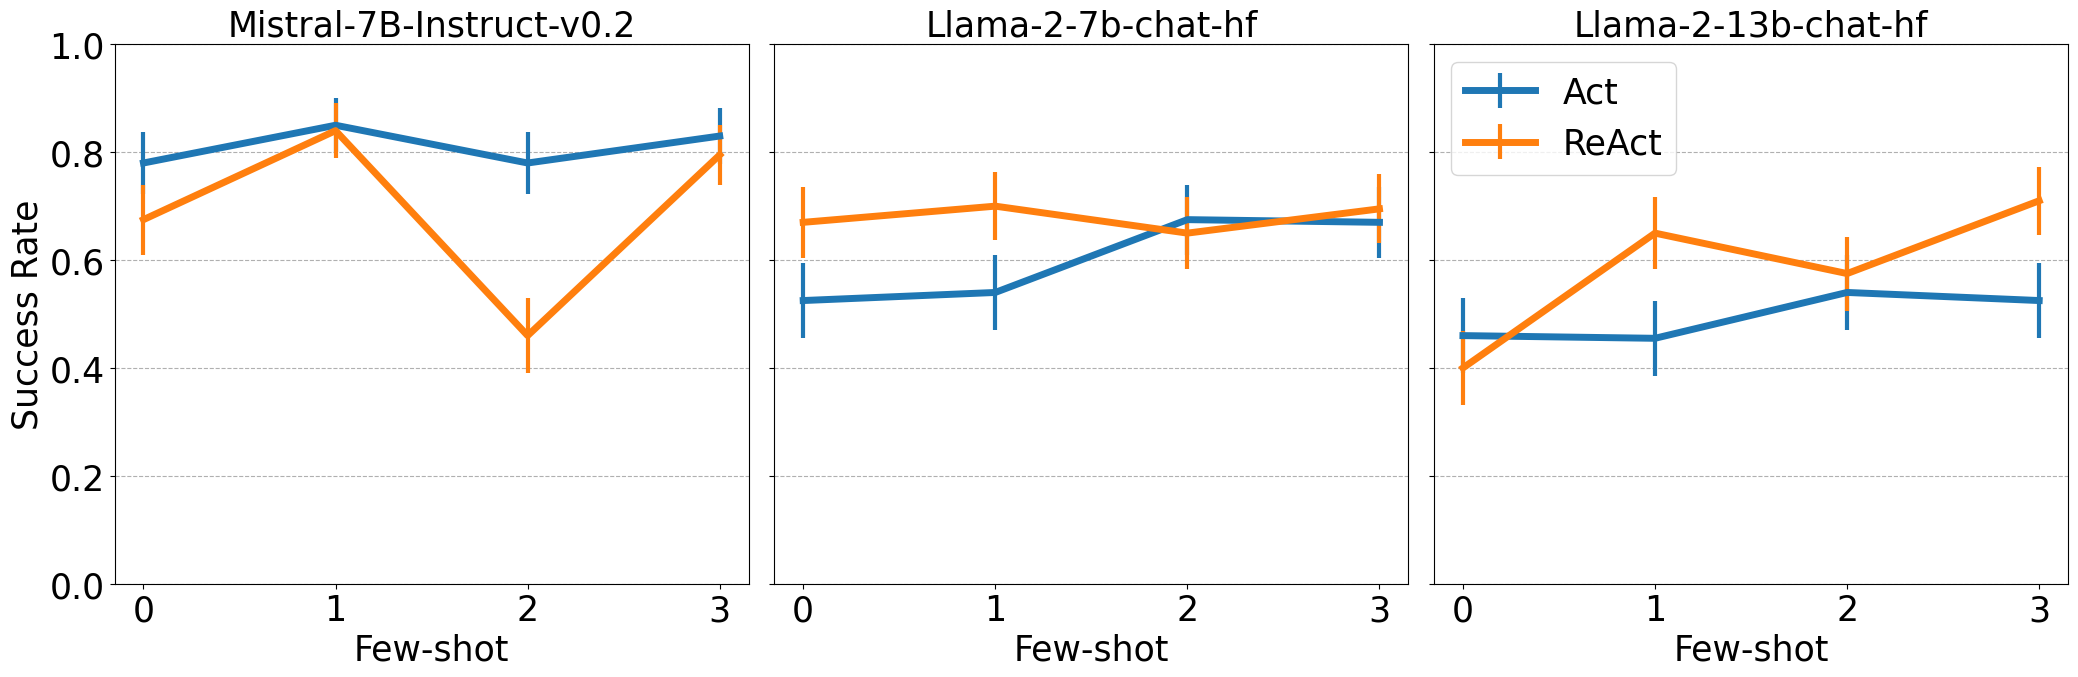

In [13]:
success_df = all_runs_df.query("is_finished==True").groupby(['model.model_name', 'agent.fewshot', 'agent.agent_name', 'prompting']).agg({'success':['mean', 'sem']}).reset_index()
success_df['error'] = success_df['success']['sem']*1.96


# Visual settings
fontsize=25
markersize=12
linewidth=5

# reorder models
models = ['mistralai/Mistral-7B-Instruct-v0.2', 'meta-llama/Llama-2-7b-chat-hf', 'meta-llama/Llama-2-13b-chat-hf']
prompting_types = success_df['prompting'].unique()

# Number of models determines the number of subplots
n_models = len(models)
fig, axes = plt.subplots(1, n_models, figsize=(7 * n_models, 7), sharey=True)  # Adjust the figsize as needed
model_names = [model.split('/')[-1] for model in models]
prompting_type_names = [word.split('_')[0] for word in prompting_types]

# Ensure axes is an array, even if there's only one model
if n_models == 1:
    axes = [axes]

# Iterate over models and create a subplot for each
for i, model in enumerate(models):
    ax = axes[i]  # Current subplot axis
    model_data = success_df[success_df['model.model_name'] == model]
    for j,prompting_type in enumerate(prompting_types):
        model_data_prompting = model_data[model_data['prompting'] == prompting_type]
        # ax.plot(model_data_prompting['agent.fewshot'], model_data_prompting['success'], label=prompting_type_names[j], marker='o', markersize=markersize, linewidth=linewidth)
        # plot error bars
        ax.errorbar(model_data_prompting['agent.fewshot'], model_data_prompting['success']['mean'], yerr=model_data_prompting['error'], label=prompting_type_names[j],markersize=markersize, linewidth=linewidth, elinewidth=linewidth-2)
    
    ax.set_xlabel('Few-shot', fontsize=fontsize)
    if i == 0:
        ax.set_ylabel('Success Rate', fontsize=fontsize)
    ax.grid(axis='y', linestyle='--')
    ax.set_ylim(0,1)
    ax.set_xticks([0,1,2,3])
    ax.tick_params(axis='both', which='major', labelsize=fontsize)
    ax.set_title(model_names[i], fontsize=fontsize)
ax.legend(title_fontsize=fontsize, loc='upper left', fontsize=fontsize)


# Adjust layout to prevent overlap
plt.tight_layout()
# plt.savefig('plots/hyper_fewshot_success.pdf', bbox_inches='tight')
plt.show()


{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 2, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '6'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 2, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '2'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 3, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '3'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 1, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '5'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 3, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '7'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 0, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 0, 'agent.agent_name': 'link_click/lmql_dfs_back_re

/tmp/ipykernel_211389/1743963703.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  model_data['next_in_thought'] = model_data['response'].apply(lambda x: is_next_page_in_thought(x))
/tmp/ipykernel_211389/1743963703.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  model_data['next_in_thought'] = model_data['response'].apply(lambda x: is_next_page_in_thought(x))
/tmp/ipykernel_211389/1743963703.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using 

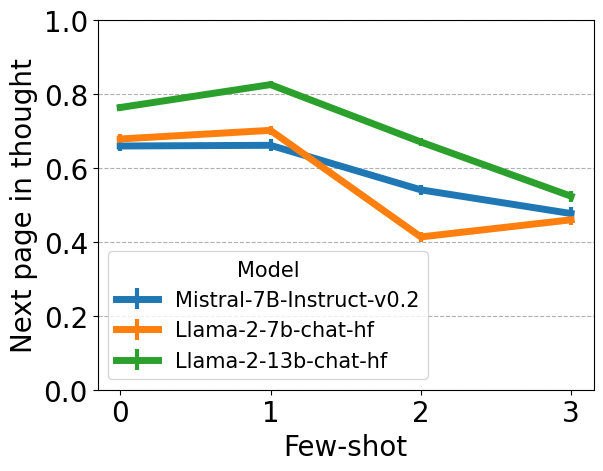

In [14]:
# get an array of dicts, each dict is the response field of a row in the df, which has to be converted to a dict
# Specify the paths to the folders containing the runs
folders = []
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_1_1/2023-12-18_18-49-40/*/"))] #mistral const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_1_2/2023-12-18_19-03-33/*/"))] #llama 7b const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_2/2023-12-21_10-44-46/*/"))] #llama 13b const

fontsize=15
linewidth=4
markersize=12

identifiers = ['model.model_name','agent.fewshot','agent.agent_name']

all_runs_df = get_all_runs_df(folders, identifiers)

print(all_runs_df.columns)

def is_next_page_in_thought(response):
    response_dict = ast.literal_eval(response)
    if 'next_article' not in response_dict.keys() and 'next_page' not in response_dict.keys():
        return False
    if 'next_article' in response_dict.keys():
        response_dict['next_page'] = response_dict['next_article']
    # if the next page is NA, then return True also if the words "back" or "backtrack" or "NA" are in the thought
    if response_dict['next_page'] == 'NA':
        return ("back" in response_dict['thought'].lower()) or ("backtrack" in response_dict['thought'].lower()) or ("NA" in response_dict['thought'])

    return (response_dict['next_page'].lower() in response_dict['thought'].lower()) or (response_dict['next_page'].lower() in wikify_article_name(response_dict['thought'].lower()))

fontsize=15
linewidth=5
models = ['mistralai/Mistral-7B-Instruct-v0.2', 'meta-llama/Llama-2-7b-chat-hf', 'meta-llama/Llama-2-13b-chat-hf']
model_names = [model.split('/')[-1] for model in models]
for i, model in enumerate(models):
    model_data = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['prompting'].apply(lambda x: 'ReAct' in x))]
    # a series of booleans, each boolean is whether the next page is in the thought
    model_data['next_in_thought'] = model_data['response'].apply(lambda x: is_next_page_in_thought(x))

    # plot error bars
    plt.errorbar(model_data.groupby('agent.fewshot').agg({'next_in_thought':'mean'}).index, model_data.groupby('agent.fewshot').agg({'next_in_thought':'mean'})['next_in_thought'], yerr=model_data.groupby('agent.fewshot').agg({'next_in_thought':'sem'})['next_in_thought']*1.96, label=model_names[i], elinewidth=linewidth-2, linewidth=linewidth)

plt.xlabel('Few-shot', fontsize=fontsize+5)
plt.ylabel('Next page in thought', fontsize=fontsize+5)
plt.grid(axis='y', linestyle='--')
plt.ylim(0,1)
plt.xticks([0,1,2,3], fontsize=fontsize+5)
plt.yticks(fontsize=fontsize+5)
plt.legend(title='Model', title_fontsize=fontsize, loc='lower left', fontsize=fontsize)
# plt.savefig('plots/hyper_fewshot_next_in_thought.pdf', bbox_inches='tight')
plt.show()


In [ ]:
Blade_Runner	Newspaper	Mass_media

In [57]:
get_spl("Blade_Runner", "Newspaper")

nan

In [37]:
# print responses of the model when the next page is not in the thought
model_data = all_runs_df[
    (all_runs_df['model.model_name'] == 'meta-llama/Llama-2-13b-chat-hf') &
    (all_runs_df['prompting']=='ReAct_linkclick') &
    (all_runs_df['agent.fewshot']==3)
]
model_data['next_in_thought'] = model_data['response'].apply(lambda x: is_next_page_in_thought(x))
model_data[(model_data['next_in_thought']==False)][['src','tgt','cur','action', 'response','path_so_far']].head(30)


/tmp/ipykernel_211389/1546942003.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  model_data['next_in_thought'] = model_data['response'].apply(lambda x: is_next_page_in_thought(x))


,src,tgt,cur,action,response,path_so_far
21908,Calgary,Zebra,Asia,{'next_page': 'Asia'},"{'thought': 'Zebra is an animal that is commonly found in Africa, so clicking on Africa brings us closer to the page for Zebra. ', 'next_page': 'Asia'}",Calgary;Asia
21911,Banana,Monty_Python,United_States,{'next_page': 'United_States'},"{'thought': ""Monty Python is a British comedy group, so let's click on the United Kingdom to get closer to the target page."", 'next_page': 'United_States'}",Banana;United_States
21912,Somalia,Henry_III_of_England,France,{'next_page': 'France'},"{'thought': ""Henry III of England ruled during a time of great change and upheaval in Europe, so let's click on Europe to learn more about this period. "", 'next_page': 'France'}",Somalia;France
21916,Lake_Malawi,Time,World_War_I,{'next_page': 'World_War_I'},"{'thought': 'Time is a concept that is closely related to the history of Lake Malawi and its surrounding regions. Clicking on Time will allow us to explore the historical events and cultural traditions that have shaped this region over the centuries. ', 'next_page': 'World_War_I'}",Lake_Malawi;World_War_I
21919,Richard_Nixon,Optical_telescope,Space_Shuttle_program,{'next_page': 'Space_Shuttle_program'},"{'thought': 'Optical telescopes are used to study the universe, and one of the most famous optical telescopes is the Hubble Space Telescope, which was launched by NASA in 1990. Clicking on NASA brings us closer to the page for the Hubble Space Telescope.', 'next_page': 'Space_Shuttle_program'}",Richard_Nixon;Space_Shuttle_program
21923,Fiji,Conakry,Hinduism,{'next_page': 'Hinduism'},"{'thought': 'Conakry is the capital of Guinea, a country in West Africa, so clicking on Africa brings us closer to the page for Conakry. ', 'next_page': 'Hinduism'}",Fiji;Hinduism
21924,Palladium,Vancouver,Australia,{'next_page': 'Australia'},"{'thought': 'Vancouver is a city located in Canada, so we should click on Canada to get closer to the target page. ', 'next_page': 'Australia'}",Palladium;Australia
21930,Winston_Churchill,Cell_(biology),Adolf_Hitler,{'next_page': 'Adolf_Hitler'},"{'thought': ""Cell biology is a fascinating field that has made significant contributions to our understanding of the human body. As Winston Churchill once said, 'The greatest glory in living lies not in never falling, but in rising every time we fall.' Let's explore the links between cell biology and some of the notable figures and events in history. Perhaps we'll discover some unexpected connections!"", 'next_page': 'Adolf_Hitler'}",Winston_Churchill;Adolf_Hitler
21935,Blade_Runner,Newspaper,Mass_media,{'next_page': 'Mass_media'},"{'thought': 'Newspaper is a medium for disseminating news and information, so clicking on Media brings us closer to the page for Newspaper. ', 'next_page': 'Mass_media'}",Blade_Runner;Mass_media
21942,Hubble_Deep_Field,Musical_instrument,Hubble_Space_Telescope,{'next_page': 'Hubble_Space_Telescope'},"{'thought': 'Musical instruments are not mentioned in the list of links for Hubble Deep Field, so we cannot proceed further. The current page is the target page, so we will stop here.""}{""next_article"": null}', 'next_page': 'Hubble_Space_Telescope'}",Hubble_Deep_Field;Hubble_Space_Telescope


## Plot - Temperature vs Success Rate

In [10]:
# Specify the paths to the folders containing the runs
folders = []
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_6_1/2023-12-18_19-33-23/*/"))] #mistral const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_6_2/2023-12-18_19-42-51/*/"))] #llama 7b const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_7/2023-12-18_20-17-52/*/"))] #llama 13b const


identifiers = ['model.model_name','model.temperature','agent.agent_name']

all_runs_df = get_all_runs_df(folders, identifiers)

print(all_runs_df.columns)

{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 1, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '6'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 1, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '2'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 1.5, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '3'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 0.5, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '5'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 1.5, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '7'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 0.2, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 0.2, 'agent.age

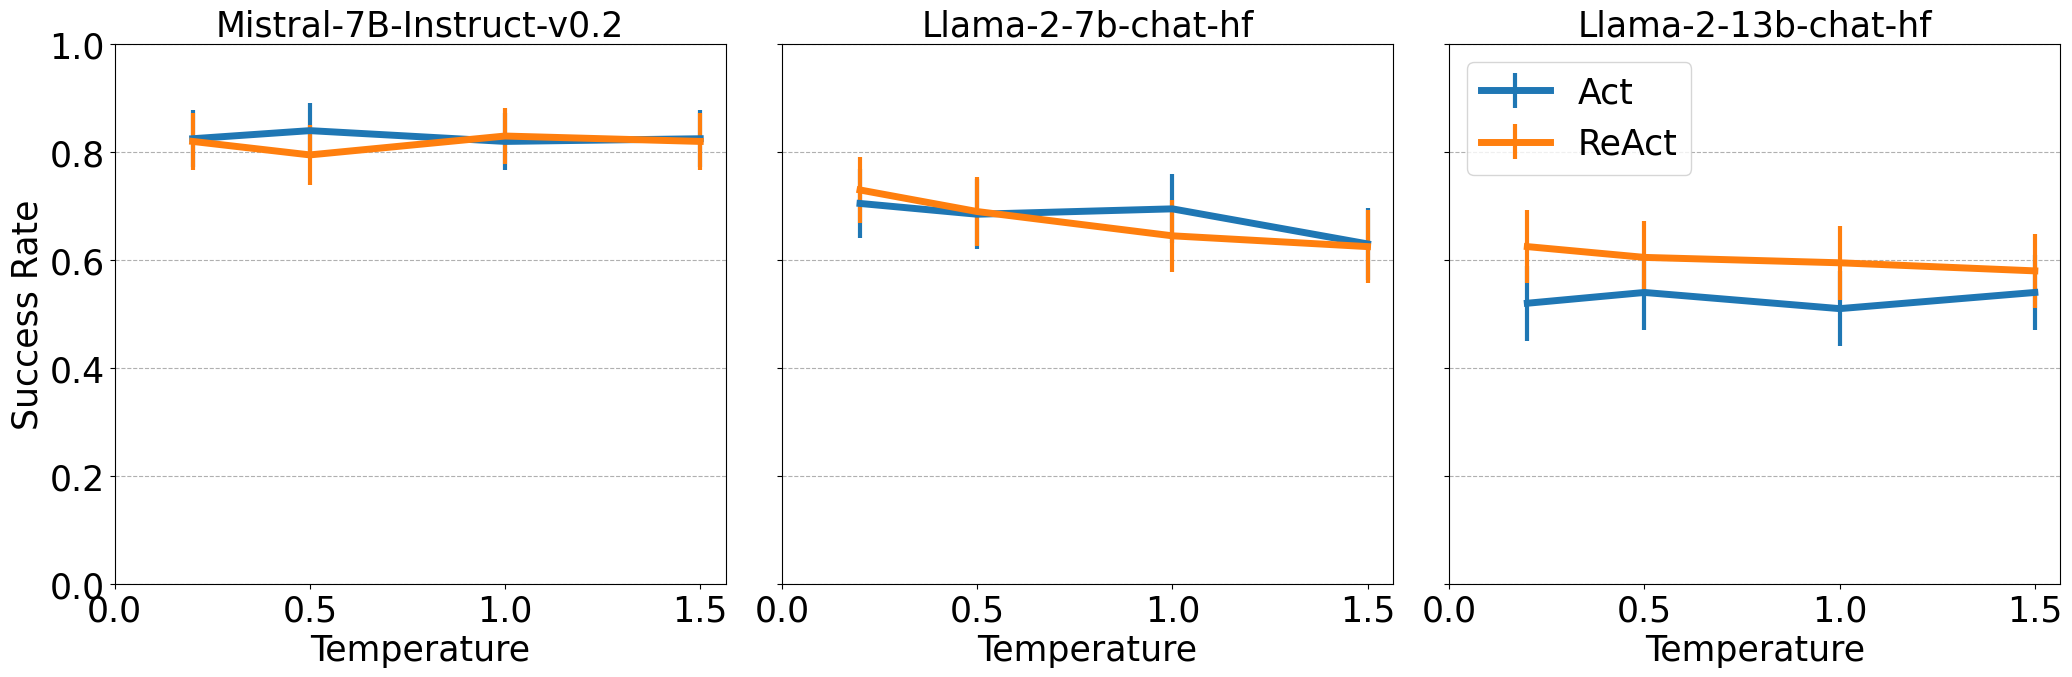

In [11]:
success_df = all_runs_df.query("is_finished==True").groupby(['model.model_name', 'model.temperature', 'agent.agent_name', 'prompting']).agg({'success':['mean', 'sem']}).reset_index()
success_df['error'] = success_df['success']['sem']*1.96

# Visual settings
fontsize=25
markersize=12
linewidth=5

# reorder models
models = ['mistralai/Mistral-7B-Instruct-v0.2', 'meta-llama/Llama-2-7b-chat-hf', 'meta-llama/Llama-2-13b-chat-hf']
prompting_types = success_df['prompting'].unique()

# Number of models determines the number of subplots
n_models = len(models)
fig, axes = plt.subplots(1, n_models, figsize=(7 * n_models, 7), sharey=True)  # Adjust the figsize as needed
model_names = [model.split('/')[-1] for model in models]
prompting_type_names = [word.split('_')[0] for word in prompting_types]

# Ensure axes is an array, even if there's only one model
if n_models == 1:
    axes = [axes]

# Iterate over models and create a subplot for each
for i, model in enumerate(models):
    ax = axes[i]  # Current subplot axis
    model_data = success_df[success_df['model.model_name'] == model]
    for j,prompting_type in enumerate(prompting_types):
        model_data_prompting = model_data[model_data['prompting'] == prompting_type]
        ax.errorbar(model_data_prompting['model.temperature'], model_data_prompting['success']['mean'], yerr=model_data_prompting['error'], label=prompting_type_names[j],markersize=markersize, linewidth=linewidth, elinewidth=linewidth-2)
    
    ax.set_xlabel('Temperature', fontsize=fontsize)
    if i == 0:
        ax.set_ylabel('Success Rate', fontsize=fontsize)
    ax.grid(axis='y', linestyle='--')
    ax.set_ylim(0,1)
    ax.set_xticks([0,0.5,1,1.5])
    ax.tick_params(axis='both', which='major', labelsize=fontsize)
    ax.set_title(model_names[i], fontsize=fontsize)
ax.legend(title_fontsize=fontsize, loc='upper left', fontsize=fontsize)


# Adjust layout to prevent overlap
plt.tight_layout()
# plt.savefig('plots/hyper_temperature_success.pdf', bbox_inches='tight')
plt.show()


## Plot - Temperature vs Next Page in Thought

{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 1, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '6'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 1, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '2'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 1.5, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '3'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 0.5, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '5'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 1.5, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '7'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 0.2, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'model.temperature': 0.2, 'agent.age

/tmp/ipykernel_4175623/592595826.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  model_data['next_in_thought'] = model_data['response'].apply(lambda x: is_next_page_in_thought(x))
/tmp/ipykernel_4175623/592595826.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  model_data['next_in_thought'] = model_data['response'].apply(lambda x: is_next_page_in_thought(x))
/tmp/ipykernel_4175623/592595826.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using 

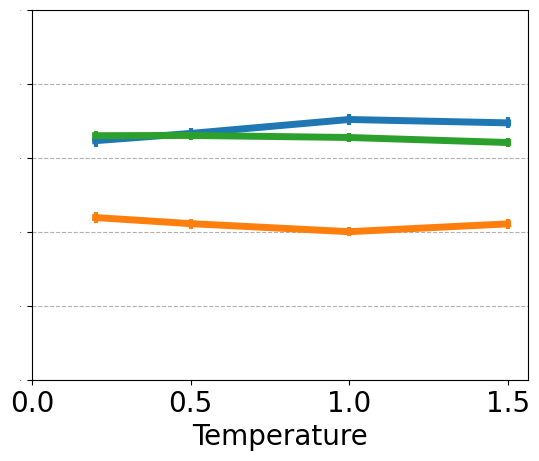

In [120]:
# get an array of dicts, each dict is the response field of a row in the df, which has to be converted to a dict
# Specify the paths to the folders containing the runs
folders = []
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_6_1/2023-12-18_19-33-23/*/"))] #mistral const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_6_2/2023-12-18_19-42-51/*/"))] #llama 7b const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_7/2023-12-18_20-17-52/*/"))] #llama 13b const


identifiers = ['model.model_name','model.temperature','agent.agent_name']

all_runs_df = get_all_runs_df(folders, identifiers)

print(all_runs_df.columns)

def is_next_page_in_thought(response):
    response_dict = ast.literal_eval(response)
    if 'next_article' not in response_dict.keys() and 'next_page' not in response_dict.keys():
        return False
    if 'next_article' in response_dict.keys():
        response_dict['next_page'] = response_dict['next_article']
    # if the next page is NA, then return True also if the words "back" or "backtrack" or "NA" are in the thought
    if response_dict['next_page'] == 'NA':
        return ("back" in response_dict['thought'].lower()) or ("backtrack" in response_dict['thought'].lower()) or ("NA" in response_dict['thought'])

    return (response_dict['next_page'].lower() in response_dict['thought'].lower()) or (response_dict['next_page'].lower() in wikify_article_name(response_dict['thought'].lower()))

fontsize=15
linewidth=5
models = ['mistralai/Mistral-7B-Instruct-v0.2', 'meta-llama/Llama-2-7b-chat-hf', 'meta-llama/Llama-2-13b-chat-hf']
model_names = [model.split('/')[-1] for model in models]
for i, model in enumerate(models):
    model_data = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['prompting'].apply(lambda x: 'ReAct' in x))]
    # a series of booleans, each boolean is whether the next page is in the thought
    model_data['next_in_thought'] = model_data['response'].apply(lambda x: is_next_page_in_thought(x))

    # plot error bars
    plt.errorbar(model_data.groupby('model.temperature').agg({'next_in_thought':'mean'}).index, model_data.groupby('model.temperature').agg({'next_in_thought':'mean'})['next_in_thought'], yerr=model_data.groupby('model.temperature').agg({'next_in_thought':'sem'})['next_in_thought']*1.96, label=model_names[i], elinewidth=linewidth-2, linewidth=linewidth)
    
plt.xlabel('Temperature', fontsize=fontsize+5)
# plt.ylabel('Next page in thought', fontsize=fontsize+5)
plt.grid(axis='y', linestyle='--')
plt.ylim(0,1)
plt.yticks(fontsize=0)
plt.xticks([0,0.5,1,1.5], fontsize=fontsize+5)
# plt.legend(title='Model', title_fontsize=fontsize, bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=fontsize)
plt.savefig('plots/hyper_temperature_next_in_thought.pdf', bbox_inches='tight')
plt.show()


## Plot - Model Size vs Success Rate

In [58]:
# Specify the paths to the folders containing the runs
folders = []
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_1_2/2023-12-18_19-03-33/*/"))] #llama 7b const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_2/2023-12-21_10-44-46/*/"))] #llama 13b const
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_3_1/2023-12-21_10-45-05/*/"))] #llama 70b const act
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_3_2/2023-12-22_15-12-22/*/"))] #llama 70b const react


identifiers = ['model.model_name','agent.fewshot','agent.agent_name']

all_runs_df = get_all_runs_df(folders, identifiers)

# keep only relevant runs
all_runs_df = all_runs_df[
    ((all_runs_df['model.model_name']=='meta-llama/Llama-2-7b-chat-hf') & (all_runs_df['agent.fewshot']==2) & ((all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back') | (all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back_reason'))) |
    ((all_runs_df['model.model_name']=='meta-llama/Llama-2-13b-chat-hf') & (all_runs_df['agent.fewshot']==2) & ((all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back') | (all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back_reason'))) |
    ((all_runs_df['model.model_name']=='meta-llama/Llama-2-70b-chat-hf') & (all_runs_df['agent.fewshot']==2) & ((all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back') | (all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back_reason')))
]
print(all_runs_df.columns)

{'model.model_name': 'meta-llama/Llama-2-7b-chat-hf', 'agent.fewshot': 2, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '6'}
{'model.model_name': 'meta-llama/Llama-2-7b-chat-hf', 'agent.fewshot': 2, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '2'}
{'model.model_name': 'meta-llama/Llama-2-7b-chat-hf', 'agent.fewshot': 3, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '3'}
{'model.model_name': 'meta-llama/Llama-2-7b-chat-hf', 'agent.fewshot': 1, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '5'}
{'model.model_name': 'meta-llama/Llama-2-7b-chat-hf', 'agent.fewshot': 3, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '7'}
{'model.model_name': 'meta-llama/Llama-2-7b-chat-hf', 'agent.fewshot': 0, 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'meta-llama/Llama-2-7b-chat-hf', 'agent.fewshot': 0, 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '4'}
{'model.model

                 model.model_name                 agent.agent_name  \
                                                                     
4   meta-llama/Llama-2-7b-chat-hf         link_click/lmql_dfs_back   
5   meta-llama/Llama-2-7b-chat-hf  link_click/lmql_dfs_back_reason   
0  meta-llama/Llama-2-13b-chat-hf         link_click/lmql_dfs_back   
1  meta-llama/Llama-2-13b-chat-hf  link_click/lmql_dfs_back_reason   
2  meta-llama/Llama-2-70b-chat-hf         link_click/lmql_dfs_back   
3  meta-llama/Llama-2-70b-chat-hf  link_click/lmql_dfs_back_reason   

         prompting success               error  
                      mean       sem            
4    Act_linkclick   0.675  0.033202  0.065076  
5  ReAct_linkclick   0.650  0.033811  0.066270  
0    Act_linkclick   0.540  0.035330  0.069248  
1  ReAct_linkclick   0.575  0.035043  0.068684  
2    Act_linkclick   0.695  0.032637  0.063969  
3  ReAct_linkclick   0.820  0.027234  0.053379  


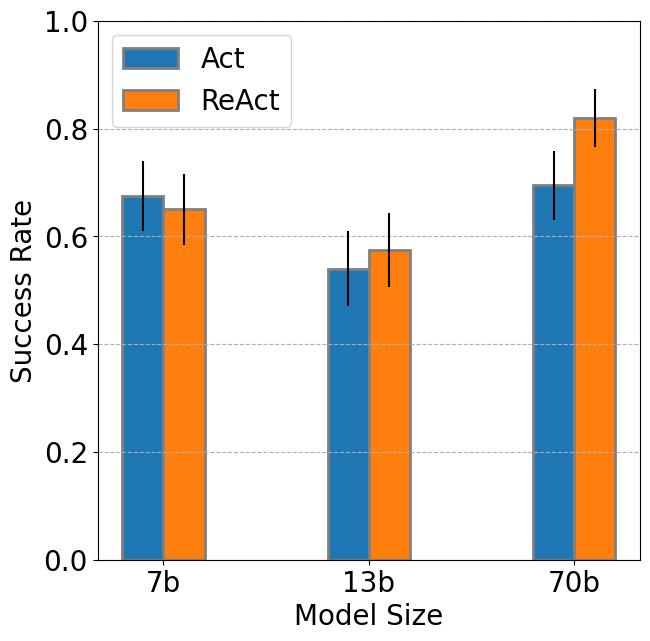

In [59]:
success_df = all_runs_df.query("is_finished==True").groupby(['model.model_name', 'agent.agent_name', 'prompting']).agg({'success':['mean', 'sem']}).reset_index()
success_df['error'] = success_df['success']['sem']*1.96

# Visual settings
fontsize=25
markersize=12
linewidth=2

# sort success df by model name
success_df = success_df.loc[[4,5,0,1,2,3]]
fontsize=20
markersize=12
print(success_df)

model_sizes = ['7b', '13b', '70b']
model_names = ['meta-llama/Llama-2-7b-chat-hf', 'meta-llama/Llama-2-13b-chat-hf', 'meta-llama/Llama-2-70b-chat-hf']
prompting_types = success_df['prompting'].unique()
prompting_type_names = [word.split('_')[0] for word in prompting_types]

# bar plot: y-axis is success rate, x-axis is model size, each x-tick has a bar for each prompting type
plt.figure(figsize=(7,7))
barWidth = 0.2
for i, prompting_type in enumerate(prompting_types):
    # plot error bars
    plt.bar(np.arange(len(model_sizes)) + i * barWidth - barWidth/2, success_df[success_df['prompting']==prompting_type]['success']['mean'], yerr=success_df[success_df['prompting']==prompting_type]['error'], width=barWidth, edgecolor='grey', label=prompting_type_names[i], linewidth=linewidth)
    
plt.xlabel('Model Size', fontsize=fontsize)
plt.ylabel('Success Rate', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.ylim(0,1)
plt.yticks(fontsize=fontsize)
plt.xticks(np.arange(len(model_sizes)), model_sizes, fontsize=fontsize)
plt.legend(fontsize=fontsize)
# plt.savefig('plots/hyper_model_size_success.pdf', bbox_inches='tight')
plt.show()


/tmp/ipykernel_211389/2162593162.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['next_in_thought'] = data['response'].apply(lambda x: is_next_page_in_thought(x))


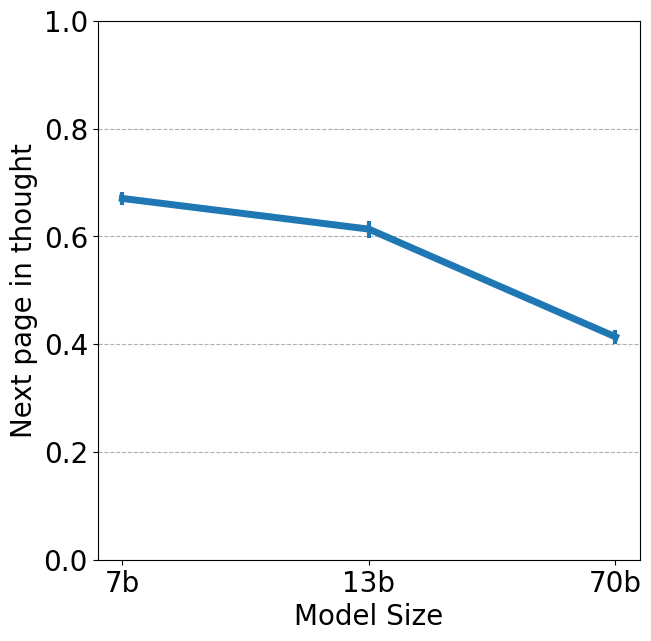

In [61]:
def is_next_page_in_thought(response):
    response_dict = ast.literal_eval(response)
    if 'next_article' not in response_dict.keys() and 'next_page' not in response_dict.keys():
        return False
    if 'next_article' in response_dict.keys():
        response_dict['next_page'] = response_dict['next_article']
    # if the next page is NA, then return True also if the words "back" or "backtrack" or "NA" are in the thought
    if response_dict['next_page'] == 'NA':
        return ("back" in response_dict['thought'].lower()) or ("backtrack" in response_dict['thought'].lower()) or ("NA" in response_dict['thought'])

    return (response_dict['next_page'].lower() in response_dict['thought'].lower()) or (response_dict['next_page'].lower() in wikify_article_name(response_dict['thought'].lower()))

fontsize=20
linewidth=5
model_sizes = ['7b', '13b', '70b']
model_names = ['meta-llama/Llama-2-7b-chat-hf', 'meta-llama/Llama-2-13b-chat-hf', 'meta-llama/Llama-2-70b-chat-hf']

# a series of booleans, each boolean is whether the next page is in the thought
data = all_runs_df[(all_runs_df['prompting'].apply(lambda x: 'ReAct' in x))]
data['next_in_thought'] = data['response'].apply(lambda x: is_next_page_in_thought(x))

# plot a line of the percentage of times the next page is in the thought vs fewshot
plt.figure(figsize=(7,7))
# plot with error
plt.errorbar(data.groupby(['model.model_name']).agg({'next_in_thought':'mean'}).index, data.groupby(['model.model_name']).agg({'next_in_thought':'mean'})['next_in_thought'], yerr=data.groupby(['model.model_name', 'agent.fewshot']).agg({'next_in_thought':'sem'})['next_in_thought']*1.96, elinewidth=linewidth-2, linewidth=linewidth)

plt.xlabel('Model Size', fontsize=fontsize)
plt.ylabel('Next page in thought', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.ylim(0,1)
plt.yticks(fontsize=fontsize)
plt.xticks(np.arange(len(model_sizes)), model_sizes, fontsize=fontsize)
# plt.savefig('plots/hyper_model_size_next_in_thought.pdf', bbox_inches='tight')
plt.show()



In [64]:
# print responses of the model when the next page is not in the thought
model_data = all_runs_df[
    (all_runs_df['model.model_name'] == 'meta-llama/Llama-2-70b-chat-hf') &
    (all_runs_df['prompting']=='ReAct_linkclick') &
    (all_runs_df['agent.fewshot']==2)
]
model_data['next_in_thought'] = model_data['response'].apply(lambda x: is_next_page_in_thought(x))
model_data[model_data['next_in_thought']==False][['src','tgt','cur','action', 'response']].head(10)


/tmp/ipykernel_211389/1506096010.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  model_data['next_in_thought'] = model_data['response'].apply(lambda x: is_next_page_in_thought(x))


,src,tgt,cur,action,response
1,Flamingo,Gold(III)_chloride,Fossil_record,{'next_page': 'Fossil_record'},"{'thought': ""The target page Gold(III) chloride is not directly related to flamingos, but the word 'gold' made me think of the gold-colored flamingos, so let's choose it."", 'next_page': 'Fossil_record'}"
4,Calgary,Zebra,Baseball,{'next_page': 'Baseball'},"{'thought': ""Zebra is not directly related to Calgary, but the link for Zebra is on the page. Let's choose Zebra as the next article to explore."", 'next_page': 'Baseball'}"
5,Diabetes_mellitus,Adolf_Hitler,Myocardial_infarction,{'next_page': 'Myocardial_infarction'},"{'thought': ""Adolf Hitler is not directly related to diabetes mellitus, but there are some interesting connections. For example, Hitler had a number of health problems, including a heart condition, which may have been related to his heavy smoking habit. Smoking is a major risk factor for heart disease and other health problems, including diabetes. Additionally, Hitler's regime was responsible for the deaths of millions of people, many of whom may have had diabetes or other health conditions that were not properly treated or managed. Therefore, while there is no direct connection between Hitler and diabetes mellitus, there are some indirect connections that are worth noting."", 'next_page': 'Myocardial_infarction'}"
8,Vampire,Anglicanism,Organism,{'next_page': 'Organism'},"{'thought': 'Anglicanism is not directly related to vampires, but the article mentions that some people believe that vampires exist and that they might be found in places like Africa and Latin America, where Anglicanism is practiced. Therefore, we can choose Anglicanism as the next article to read.', 'next_page': 'Organism'}"
10,Richard_Nixon,Optical_telescope,Taiwan,{'next_page': 'Taiwan'},"{'thought': ""Optical telescope is not directly related to Richard Nixon, but it is mentioned in the context of space exploration, which was a significant area of interest during Nixon's presidency. Let's choose Optical telescope as the next article to read."", 'next_page': 'Taiwan'}"
12,The_Marriage_of_Figaro,Rainbow,The_Magic_Flute,{'next_page': 'The_Magic_Flute'},"{'thought': ""The target page Rainbow doesn't seem to be related to any of the links provided. Let's choose a different link. Which one do you want to choose?"", 'next_page': 'The_Magic_Flute'}"
14,Peanut,Geometry,Argentina,{'next_page': 'Argentina'},"{'thought': 'Geometry is not directly related to peanuts, but the link for Geometry is present on this page. Therefore, we should choose it as the next article to visit.', 'next_page': 'Argentina'}"
17,John_Calvin,George_I_of_Great_Britain,Martin_Luther,{'next_page': 'Martin_Luther'},"{'thought': ""George I of Great Britain is not directly related to John Calvin, but they both lived during the same time period and had some influence on each other's work. However, the link between them is weak, and there are many other relevant links that could be explored. Let's choose a different link."", 'next_page': 'Martin_Luther'}"
20,Desert_locust,Chlorine,Chad,{'next_page': 'Chad'},"{'thought': 'Chlorine is not directly related to desert locusts, but it is a chemical element that can be used as a pesticide to kill locusts. Therefore, it could be a useful link to explore.', 'next_page': 'Chad'}"
23,Apollo_8,Tropical_Storm_Leslie_(2000),Television,{'next_page': 'Television'},"{'thought': 'Tropical Storm Leslie (2000) is not directly related to Apollo 8, but they both have connections to meteorology and weather. There is a link for Tropical Storm Leslie (2000) on this page, so we should choose it.', 'next_page': 'Television'}"


# Part 2 - Random Game Analysis

In [5]:
# Specify the paths to the folders containing the runs
folders = []
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/hyper_1_1/2023-12-18_18-49-40/*/")) if folder.endswith('0/') or folder.endswith('5/')] #equivalent to random_link_0
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_link_1/2023-12-22_17-29-00/*/"))] 
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_link_2/2023-12-22_17-55-51/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_link_3/2023-12-24_12-08-13/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_link_4/2023-12-24_12-08-14/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_link_openai_embeddings/2024-01-04_12-32-03/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_link_deepwalk_embeddings/2024-01-04_12-32-49/*/"))]

folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_0/2023-12-22_18-08-48/*/"))] 
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_1/2023-12-22_18-19-44/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_2/2023-12-24_12-04-12/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_3/2023-12-24_12-06-35/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_4/2023-12-24_13-19-13/*/"))]





identifiers = ['model.model_name','agent.agent_name']

all_runs_df = get_all_runs_df(folders, identifiers)

{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '5'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '1'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '1'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '

## Table - Success Rate Bar plot


In [16]:
success_df = all_runs_df.query("is_finished==True").groupby(['agent.agent_name', 'prompting']).agg({'success':['mean', 'sem']}).reset_index()
success_df['error'] = success_df['success']['sem']*1.96

success_df


agent.agent_name        prompting success            \
                                                         mean       sem   
0  link_click/embedding_deepwalk_dfs        Embedding   0.978  0.004641   
1    link_click/embedding_openai_dfs        Embedding   0.939  0.007572   
2           link_click/lmql_dfs_back    Act_linkclick   0.823  0.012075   
3    link_click/lmql_dfs_back_reason  ReAct_linkclick   0.817  0.012234   
4             navigate/lmql_headings     Act_navigate   0.537  0.015776   
5      navigate/lmql_headings_reason   ReAct_navigate   0.683  0.014722   

      error  
             
0  0.009096  
1  0.014841  
2  0.023668  
3  0.023978  
4  0.030921  
5  0.028854

In [18]:
# human success rate (when hpl is Nan, no human finished the game)

print(f"Human success rate: {all_runs_df.query('is_finished==True')['mhepl'].apply(lambda x: 0 if np.isnan(x) else 1).mean()}")
print(f"Human success rate error: {all_runs_df.query('is_finished==True')['mhepl'].apply(lambda x: 0 if np.isnan(x) else 1).sem()*1.96}")
print(f"Human overhead spl mean: {all_runs_df.query('is_finished==True and not mhepl.isna()')['human_overhead_spl'].mean()}")
print(f"Human overhead spl median: {all_runs_df.query('is_finished==True and not mhepl.isna()')['human_overhead_spl'].median()}")
print(f"Human long path rate: {all_runs_df.query('is_finished==True and not mhepl.isna()')['human_overhead_spl'].apply(lambda x: 1 if x>2 else 0).mean()}")
print(f"Human long path rate error: {all_runs_df.query('is_finished==True and not mhepl.isna()')['human_overhead_spl'].apply(lambda x: 1 if x>2 else 0).sem()*1.96}")


Human success rate: 0.6653333333333333
Human success rate error: 0.011941049827007999
Human overhead spl mean: 1.635754843019372
Human overhead spl median: 1.5
Human long path rate: 0.12324649298597194
Human long path rate error: 0.010198616198304419


In [20]:
overhead_df = all_runs_df.query("success==1").groupby(['agent.agent_name', 'prompting']).agg({'overhead_spl':['median', 'mean'], 'long_path': ['mean', 'sem']}).reset_index()
overhead_df['long_path_error'] = overhead_df['long_path']['sem']*1.96

overhead_df

agent.agent_name        prompting overhead_spl            \
                                                            median      mean   
0  link_click/embedding_deepwalk_dfs        Embedding     1.333333  1.843575   
1    link_click/embedding_openai_dfs        Embedding     1.666667  2.583475   
2           link_click/lmql_dfs_back    Act_linkclick     2.000000  3.011827   
3    link_click/lmql_dfs_back_reason  ReAct_linkclick     1.500000  2.173949   
4             navigate/lmql_headings     Act_navigate     3.500000  4.648956   
5      navigate/lmql_headings_reason   ReAct_navigate     2.333333  3.011993   

  long_path           long_path_error  
       mean       sem                  
0  0.183027  0.012371        0.024248  
1  0.334398  0.015404        0.030192  
2  0.460510  0.017385        0.034075  
3  0.304774  0.016114        0.031584  
4  0.664804  0.020390        0.039964  
5  0.515373  0.019137        0.037508

In [16]:
all_runs_df[
    (all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back')
].groupby(['src','tgt']).agg({'is_finished':'last'})

is_finished
src            tgt                           
10th_century   Marco_Polo                True
               Soviet_Union              True
18th_century   Sumer                     True
1st_century_BC Mixed-breed_dog           True
               Ocean                     True
...                                       ...
York           Ethnic_group              True
ZX_Spectrum    Retinol                   True
Zambia         Paris                     True
Zimbabwe       Manorialism               True
Zinc           Great_Rift_Valley         True

[1000 rows x 1 columns]

In [18]:
all_runs_df[
    (all_runs_df['agent.agent_name']=='navigate/lmql_headings')
].groupby(['src','tgt']).agg({'is_finished':'last'})

is_finished
src                          tgt                                                           
10th_century                 Marco_Polo                                                True
                             Soviet_Union                                              True
18th_century                 Sumer                                                     True
1st_century_BC               Mixed-breed_dog                                           True
2004_Indian_Ocean_earthquake List_of_European_Union_member_states_by_accession         True
...                                                                                     ...
Worm                         Barbary_Lion                                              True
York                         Ethnic_group                                              True
ZX_Spectrum                  Retinol                                                   True
Zambia                       Paris                                                     True
Zinc                         Great_Rift_Valley                                         True

[800 rows x 1 columns]

## Plot - Cumulative Search Time

                src                tgt  num_games
0      10th_century         Marco_Polo        270
1      10th_century       Soviet_Union         38
2      18th_century              Sumer        166
3    1st_century_BC    Mixed-breed_dog        556
4    1st_century_BC              Ocean        111
..              ...                ...        ...
995            York       Ethnic_group        245
996     ZX_Spectrum            Retinol        686
997          Zambia              Paris         77
998        Zimbabwe        Manorialism        686
999            Zinc  Great_Rift_Valley        370

[1000 rows x 3 columns]


/tmp/ipykernel_1228522/3919413515.py:13: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  bins_, edges_ = np.histogram(all_runs_df.query("is_finished==True")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings')]['spl'], bins=np.arange(0, 50, 2))
/tmp/ipykernel_1228522/3919413515.py:21: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings')]['effective_path_len'], bins=np.arange(0, 50, 2))
/tmp/ipykernel_1228522/3919413515.py:28: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings_reason')]['effective_path_len'], bins=np.arange(0, 50, 2))
/tmp/ipykernel_1228522/3919413515.py:35: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  bins_, edges

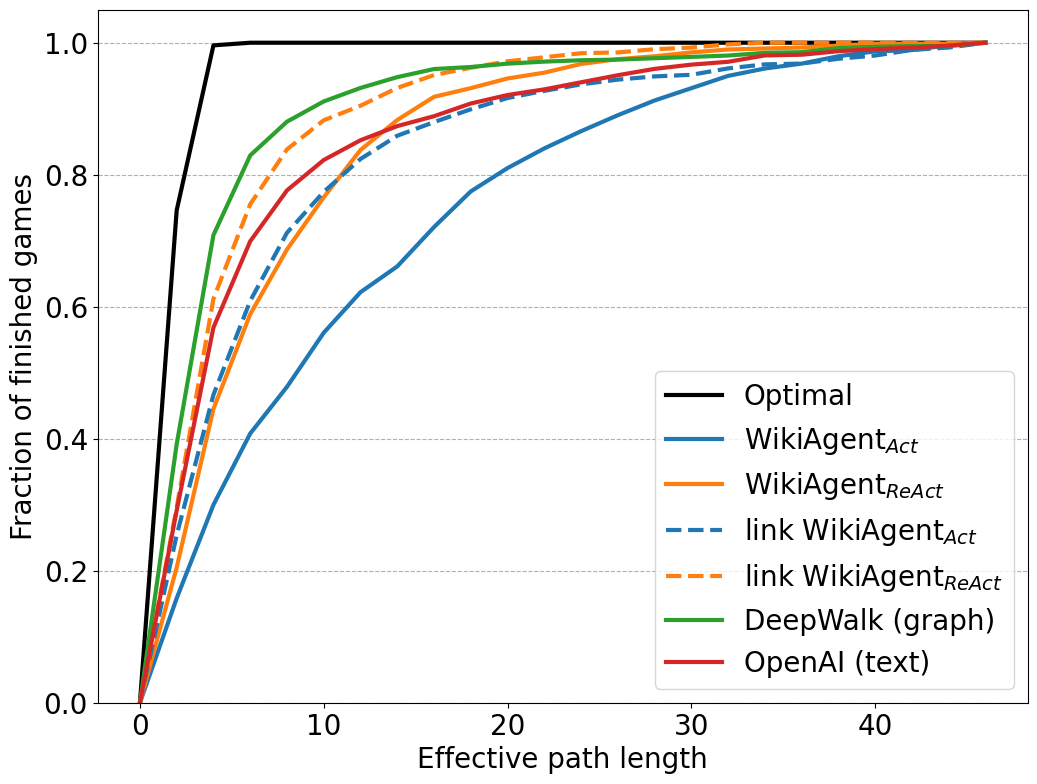

In [6]:

# make line plot
fontsize=20
markersize=12
linewidth=3

plt.figure(figsize=(12,9))

num_games = all_runs_df.groupby(['src', 'tgt']).size().reset_index().rename(columns={0:'num_games'})
print(num_games)

bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("is_finished==True")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings')]['spl'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='Optimal', linewidth=linewidth, color='black')


bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings')]['effective_path_len'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='WikiAgent$_{Act}$', linewidth=linewidth, color='tab:blue')

bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings_reason')]['effective_path_len'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='WikiAgent$_{ReAct}$', linewidth=linewidth, color='tab:orange')

bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back')]['effective_path_len'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='link WikiAgent$_{Act}$', linewidth=linewidth, color='tab:blue', linestyle='--')

bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back_reason')]['effective_path_len'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='link WikiAgent$_{ReAct}$', linewidth=linewidth, color='tab:orange', linestyle='--')


bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='link_click/embedding_deepwalk_dfs')]['effective_path_len'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='DeepWalk (graph)', linewidth=linewidth, color='tab:green')

bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='link_click/embedding_openai_dfs')]['effective_path_len'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='OpenAI (text)', linewidth=linewidth, color='tab:red')




plt.ylabel('Fraction of finished games', fontsize=fontsize)
plt.xlabel('Effective path length', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.ylim(0,1.05)
plt.yticks(fontsize=fontsize)
plt.xticks(fontsize=fontsize)

# plt.legend(fontsize=fontsize-3)
# plt.savefig('plots/random_cum_finished_length.pdf', bbox_inches='tight')

plt.legend(fontsize=fontsize)
plt.savefig('plots/random_cum_finished_length_with_legend.pdf', bbox_inches='tight')

# all_runs_df.query("success==1")[
#     (all_runs_df['agent.agent_name']=='navigate/lmql_headings_reason')
# ]['effective_path_len'].hist(density=True, bins=20, alpha=0.5, label='navigate/lmql_headings_reason')


## Plot - Success Rate and Overhead vs SPL of game




 Success 


agent: navigate/lmql_headings
navigate/lmql_headings 2 0.8403755868544601 0.04930313229409755 0.7910724545603626 0.8896787191485577

navigate/lmql_headings 3 0.5862745098039216 0.04278621073825917 0.5434882990656624 0.6290607205421808

navigate/lmql_headings 4 0.23333333333333334 0.057342234389352376 0.17599109894398096 0.2906755677226857

navigate/lmql_headings 5 0.0 0.0 0 0.0

agent: navigate/lmql_headings_reason
navigate/lmql_headings_reason 2 0.9436619718309859 0.03103824730721405 0.9126237245237718 0.9747002191381999

navigate/lmql_headings_reason 3 0.7745098039215687 0.036305671359389446 0.7382041325621792 0.8108154752809581

navigate/lmql_headings_reason 4 0.3619047619047619 0.06515126145123262 0.2967535004535293 0.4270560233559945

navigate/lmql_headings_reason 5 0.04484848484848485 0.04484848484848485 0 0.0896969696969697

agent: link_click/lmql_dfs_back
link_click/lmql_dfs_back 2 0.9819819819819819 0.01753739979310387 0.9644445821888781 0.9995193817750858

link_

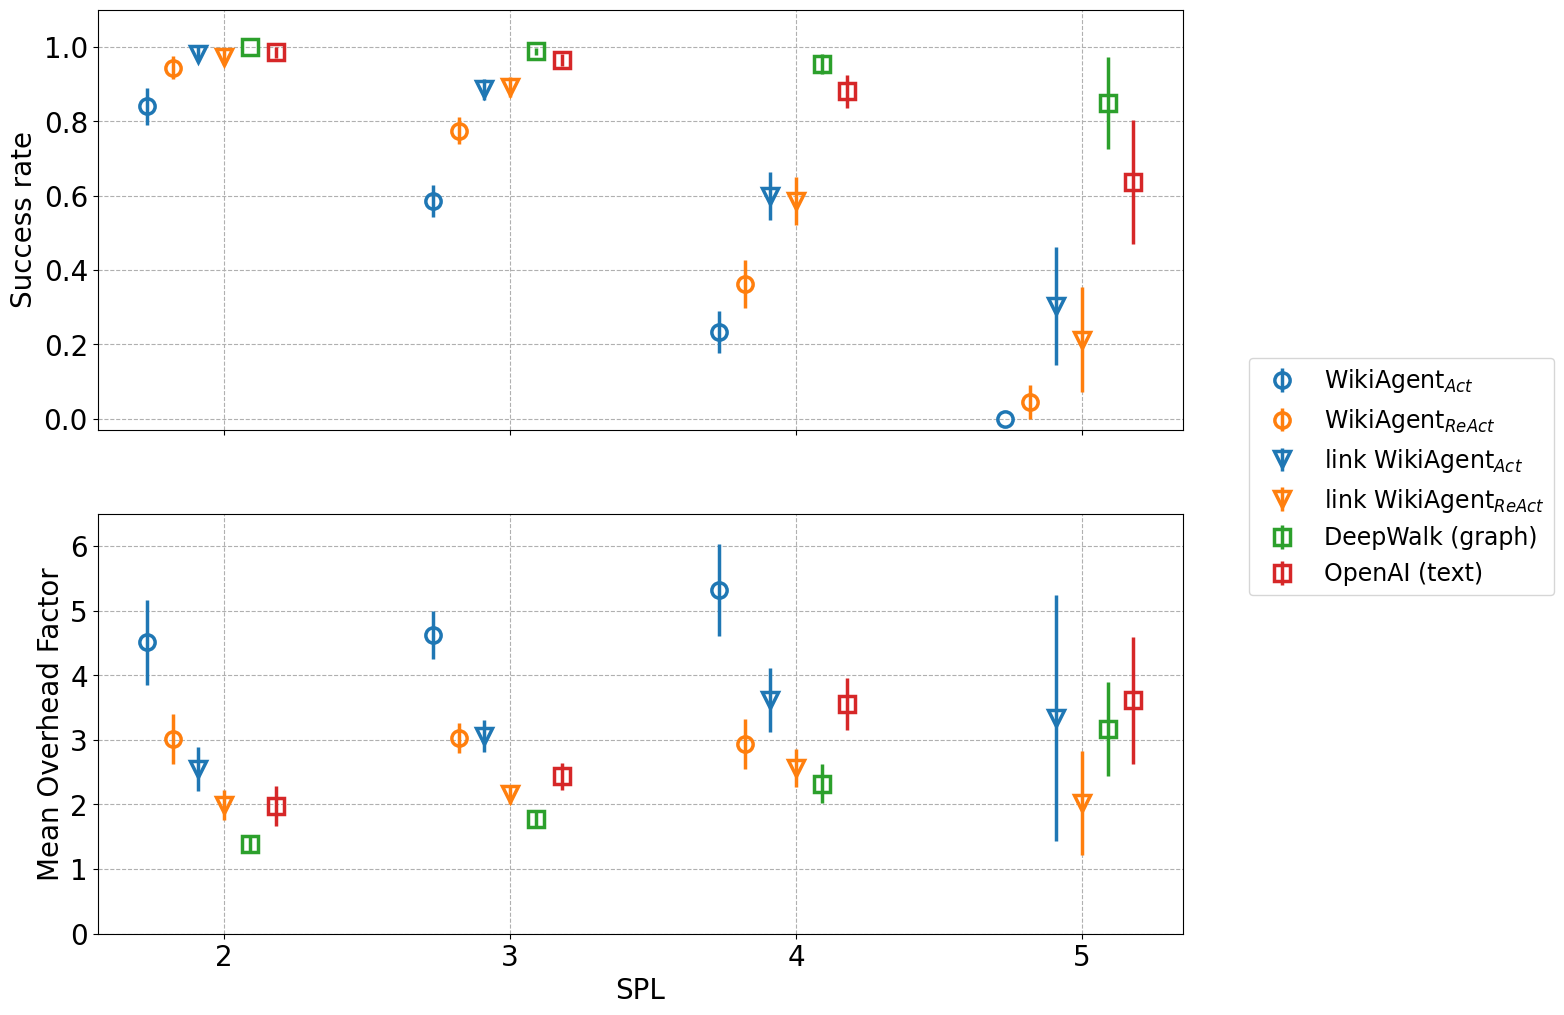

In [130]:
# make line plot
fontsize=20
markersize=11
markeredgewidth=2.5
linewidth=3
markerspacing=0.09
data = all_runs_df.query("is_finished==True")
spl_values = np.array([2,3,4,5])
# keep only games with spl in spl_values
data = data[data['spl'].isin(spl_values)]

def compute_mean_and_errors_by_spl(agent, field='success', operation='mean', max_val=1, min_val=0):
    print(f"agent: {agent}")
    means = []
    errors = []
    for spl in spl_values:
        try:
            lower = max(min_val, data[data['agent.agent_name']==agent].groupby('spl').agg({field:operation}).reset_index().query(f"spl=={spl}")[field].values[0] - data[data['agent.agent_name']==agent].groupby('spl').agg({field:'sem'}).reset_index().query(f"spl=={spl}")[field].values[0]*1.96)
            upper = min(max_val, data[data['agent.agent_name']==agent].groupby('spl').agg({field:operation}).reset_index().query(f"spl=={spl}")[field].values[0] + data[data['agent.agent_name']==agent].groupby('spl').agg({field:'sem'}).reset_index().query(f"spl=={spl}")[field].values[0]*1.96)
            mean = lower + (upper - lower)/2
            error = (upper - lower)/2
        except Exception as e:
            lower = min_val
            upper = max_val

        print(f"{agent} {spl} {mean} {error} {lower} {upper}\n")

        if lower==min_val and upper==max_val:
            mean = -1000
            error = 0
        means.append(mean)
        errors.append(error)
            
    return means, errors

fig, axes = plt.subplots(2,1, figsize=(14,12), sharex=True)  # Adjust the figsize as needed

# set active axis
plt.sca(axes[0])

# plot the success rate for grouped by spl
print("\n\n Success \n\n")
agent = 'navigate/lmql_headings'
means, errors = compute_mean_and_errors_by_spl(agent, field='success', operation='mean')
plt.errorbar(spl_values - markerspacing*3, means, yerr=errors, label='WikiAgent$_{Act}$', linewidth=0, marker='o', markersize=markersize, mfc='none', color='tab:blue', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)


agent = 'navigate/lmql_headings_reason'
means, errors = compute_mean_and_errors_by_spl(agent, field='success', operation='mean')
plt.errorbar(spl_values - markerspacing*2, means, yerr=errors, label='WikiAgent$_{ReAct}$', linewidth=0, marker='o', markersize=markersize, mfc='none', color='tab:orange', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/lmql_dfs_back'
means, errors = compute_mean_and_errors_by_spl(agent, field='success', operation='mean')
plt.errorbar(spl_values - markerspacing*1, means, yerr=errors, label='link WikiAgent$_{Act}$', linewidth=0, marker='v', markersize=markersize, mfc='none', color='tab:blue', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/lmql_dfs_back_reason'
means, errors = compute_mean_and_errors_by_spl(agent, field='success', operation='mean')
plt.errorbar(spl_values, means, yerr=errors, label='link WikiAgent$_{ReAct}$', linewidth=0, marker='v', markersize=markersize, mfc='none', color='tab:orange', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/embedding_deepwalk_dfs'
means, errors = compute_mean_and_errors_by_spl(agent, field='success', operation='mean')
plt.errorbar(spl_values + markerspacing*1, means, yerr=errors, label='DeepWalk (graph)', linewidth=0, marker='s', markersize=markersize, mfc='none', color='tab:green', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/embedding_openai_dfs'
means, errors = compute_mean_and_errors_by_spl(agent, field='success', operation='mean')
plt.errorbar(spl_values + markerspacing*2, means, yerr=errors, label='OpenAI (text)', linewidth=0, marker='s', markersize=markersize, mfc='none', color='tab:red', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

plt.ylabel('Success rate', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.grid(axis='x', linestyle='--')
plt.ylim(-0.03,1.1)
plt.yticks(fontsize=fontsize)

data = all_runs_df.query("success==1")

#####################################################
# set active axis
plt.sca(axes[1])

print("\n\n Overhead \n\n")

agent = 'navigate/lmql_headings'
print(f"agent: {agent}")
means = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'mean'}).reset_index()['overhead_spl']
errors = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'sem'}).reset_index()['overhead_spl']*1.96
valid_spl_values = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'sem'}).reset_index()['spl']
plt.errorbar(valid_spl_values - markerspacing*3, means, yerr=errors, label='WikiAgent$_{Act}$', linewidth=0, marker='o', markersize=markersize, mfc='none', color='tab:blue', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'navigate/lmql_headings_reason'
print(f"agent: {agent}")

valid_spl_values = np.array([2,3,4])
means = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'mean'}).reset_index().query("spl in [2,3,4]")['overhead_spl']
errors = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'sem'}).reset_index().query("spl in [2,3,4]")['overhead_spl']*1.96
plt.errorbar(valid_spl_values - markerspacing*2, means, yerr=errors, label='WikiAgent$_{ReAct}$', linewidth=0, marker='o', markersize=markersize, mfc='none', color='tab:orange', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)
# we wont draw this because it only finished 1 game

agent = 'link_click/lmql_dfs_back'
print(f"agent: {agent}")
valid_spl_values = np.array([2,3,4,5])
means = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'mean'}).reset_index().query("spl in [2,3,4,5]")['overhead_spl']
errors = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'sem'}).reset_index().query("spl in [2,3,4,5]")['overhead_spl']*1.96
plt.errorbar(valid_spl_values - markerspacing*1, means, yerr=errors, label='link WikiAgent$_{Act}$', linewidth=0, marker='v', markersize=markersize, mfc='none', color='tab:blue', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/lmql_dfs_back_reason'
print(f"agent: {agent}")
means, errors = compute_mean_and_errors_by_spl(agent, field='overhead_spl', operation='mean', max_val=1000, min_val=1)
plt.errorbar(spl_values, means, yerr=errors, label='link WikiAgent$_{ReAct}$', linewidth=0, marker='v', markersize=markersize, mfc='none', color='tab:orange', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/embedding_deepwalk_dfs'
means, errors = compute_mean_and_errors_by_spl(agent, field='overhead_spl', operation='mean', max_val=1000, min_val=1)
plt.errorbar(spl_values + markerspacing*1, means, yerr=errors, label='DeepWalk (graph)', linewidth=0, marker='s', markersize=markersize, mfc='none', color='tab:green', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/embedding_openai_dfs'
means, errors = compute_mean_and_errors_by_spl(agent, field='overhead_spl', operation='mean', max_val=1000, min_val=1)
plt.errorbar(spl_values + markerspacing*2, means, yerr=errors, label='OpenAI (text)', linewidth=0, marker='s', markersize=markersize, mfc='none', color='tab:red', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

plt.xlabel('SPL', fontsize=fontsize)
plt.ylabel('Mean Overhead Factor', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.grid(axis='x', linestyle='--')
plt.ylim(0,6.5)
plt.yticks(fontsize=fontsize)
plt.xticks([2,3,4,5], fontsize=fontsize)
plt.legend(fontsize=fontsize-3, bbox_to_anchor=(1.05, 1.4), loc='upper left')


plt.savefig('plots/random_success_overhead_spl.pdf', bbox_inches='tight')

In [126]:
data[data['agent.agent_name']=='link_click/lmql_dfs_back'].groupby('spl').agg({'overhead_spl':['mean','sem']}).reset_index()
data[data['agent.agent_name']=='navigate/lmql_headings_reason'].groupby('spl').agg({'success': 'count'}).reset_index()

,spl,success
0,2.0,201
1,3.0,395
2,4.0,76
3,5.0,1
4,6.0,1


# Part 3 - Human Game Analysis

In [5]:
# Remove unfinished games from the agent_runs.csv
## RUN ONLY ONCE ##

# files = [os.path.join(LOGS_PATH, "multiruns/human_nav_0/2023-12-26_11-27-51/1/agent_runs.tsv"),
#          os.path.join(LOGS_PATH, "multiruns/human_nav_1/2023-12-26_11-27-46/1/agent_runs.tsv"),
#          os.path.join(LOGS_PATH, "multiruns/human_nav_2/2023-12-27_13-34-59/0/agent_runs.tsv"),
#          os.path.join(LOGS_PATH, "multiruns/human_nav_4/2023-12-27_13-36-54/0/agent_runs.tsv"),
# ]

# for file in files:
#     df = pd.read_csv(file, sep='\t')

#     # show all agent_ids which the last is_finished is False
#     unfinished_ids = df.groupby('agent_id').agg({'is_finished':'last'}).query('is_finished==False').index.tolist()
#     print(unfinished_ids)
#     # remove all rows with these agent_ids
#     df = df[~df['agent_id'].isin(unfinished_ids)]

#     print(df.groupby('agent_id').agg({'is_finished':'last'}).query('is_finished==False').index.tolist())
#     # save the new file
#     df.to_csv(file, sep='\t', index=False)


In [3]:
# Specify the paths to the folders containing the runs
folders = []
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_link_0/2023-12-26_11-23-32/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_link_1/2023-12-26_11-28-20/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_link_2/2023-12-28_15-54-46/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_link_3/2023-12-27_13-37-05/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_link_4/2023-12-27_13-37-25/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_link_5/2023-12-27_13-37-53/*/"))]

folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_link_openai_embeddings/2024-01-08_16-32-22/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_link_deepwalk_embeddings/2024-01-07_17-56-46/*/"))]

folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_nav_0/2023-12-26_11-27-51/*/"))] # act and part of react
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_nav_0/2024-01-03_12-09-55/*/"))] # rest of react

folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_nav_1/2023-12-26_11-27-46/*/"))] # act and part of react
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_nav_1/2024-01-03_12-09-55/*/"))] # rest of react

folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_nav_2/2023-12-27_13-34-59/*/"))] # act
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_nav_2/2024-01-03_12-09-55/*/"))] # rest of act
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_nav_2/2024-01-04_22-51-19/*/"))] # react

folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_nav_3/2023-12-27_13-34-55/*/"))]

folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_nav_4/2023-12-27_13-36-54/*/"))] # act
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_nav_4/2024-01-03_10-32-14/*/"))] # rest of act
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_nav_4/2024-01-05_11-44-30/*/"))] # react

folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/human_nav_5/2023-12-27_15-41-49/*/"))]

identifiers = ['model.model_name','agent.agent_name']

all_runs_df = get_all_runs_df(folders, identifiers)

# merge paths_real_df to keep only src,tgt pairs that are present in all_runs_df
filtered_paths_real_df = paths_real_df.copy()
filtered_paths_real_df = pd.merge(filtered_paths_real_df, all_runs_df.groupby(['src', 'tgt']).agg({'agent_id':'last'}).reset_index(), on=['src', 'tgt'], how='inner')
filtered_paths_real_df['overhead_spl'] = filtered_paths_real_df['hepl']/filtered_paths_real_df['spl']
filtered_paths_real_df['long_path'] = filtered_paths_real_df['overhead_spl'].apply(lambda x: 1 if x>2 else 0)


{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '1'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '1'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '1'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/lmql_dfs_back_reason', 'run_id': '

In [26]:
all_runs_df[all_runs_df['agent.agent_name']=='navigate/lmql_headings'][all_runs_df['agent_id'].isin(agent_ids_act)].groupby('agent_id').size().mean()

/tmp/ipykernel_280439/322596196.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  all_runs_df[all_runs_df['agent.agent_name']=='navigate/lmql_headings'][all_runs_df['agent_id'].isin(agent_ids_act)].groupby('agent_id').size().mean()


128.16430171769977

In [28]:

# for navigate/lmql_headings, get the list of agent_ids whose last success is 1
agent_ids_act = all_runs_df[all_runs_df['agent.agent_name']=='navigate/lmql_headings'].groupby('agent_id').agg({'success':'last'}).query('success==1').index.tolist()
# for navigate/lmql_headings_reason, get the list of agent_ids whose last success is 1
agent_ids_react = all_runs_df[all_runs_df['agent.agent_name']=='navigate/lmql_headings_reason'].groupby('agent_id').agg({'success':'last'}).query('success==1').index.tolist()

# print average number of actions per agent_id for navigate/lmql_headings and navigate/lmql_headings_reason, for successful agents only
print(f"navigate/lmql_headings: {all_runs_df[all_runs_df['agent.agent_name']=='navigate/lmql_headings'][all_runs_df['agent_id'].isin(agent_ids_act)].groupby('agent_id').size().mean()}")
print(f"navigate/lmql_headings_reason: {all_runs_df[all_runs_df['agent.agent_name']=='navigate/lmql_headings_reason'][all_runs_df['agent_id'].isin(agent_ids_react)].groupby('agent_id').size().mean()}")

/tmp/ipykernel_280439/3637845464.py:7: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  print(f"navigate/lmql_headings: {all_runs_df[all_runs_df['agent.agent_name']=='navigate/lmql_headings'][all_runs_df['agent_id'].isin(agent_ids_act)].groupby('agent_id').size().mean()}")


navigate/lmql_headings: 128.16430171769977
navigate/lmql_headings_reason: 47.59073359073359


/tmp/ipykernel_280439/3637845464.py:8: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  print(f"navigate/lmql_headings_reason: {all_runs_df[all_runs_df['agent.agent_name']=='navigate/lmql_headings_reason'][all_runs_df['agent_id'].isin(agent_ids_react)].groupby('agent_id').size().mean()}")


## Table - Performance metrics

In [8]:
success_df = all_runs_df.query("is_finished==True").groupby(['agent.agent_name', 'prompting']).agg({'success':['mean', 'sem']}).reset_index()
success_df['error'] = success_df['success']['sem']*1.96

success_df

agent.agent_name        prompting   success            \
                                                           mean       sem   
0  link_click/embedding_deepwalk_dfs        Embedding  0.995820  0.001475   
1    link_click/embedding_openai_dfs        Embedding  0.993730  0.001805   
2           link_click/lmql_dfs_back    Act_linkclick  0.957680  0.004603   
3    link_click/lmql_dfs_back_reason  ReAct_linkclick  0.911181  0.006504   
4             navigate/lmql_headings     Act_navigate  0.704284  0.010434   
5      navigate/lmql_headings_reason   ReAct_navigate  0.815047  0.008877   

      error  
             
0  0.002891  
1  0.003537  
2  0.009022  
3  0.012748  
4  0.020451  
5  0.017399

In [9]:
overhead_df = all_runs_df.query("success==1").groupby(['agent.agent_name', 'prompting']).agg({'overhead_spl':['median', 'mean'], 'long_path': ['mean', 'sem']}).reset_index()
overhead_df['long_path_error'] = overhead_df['long_path']['sem']*1.96

overhead_df

agent.agent_name        prompting overhead_spl            \
                                                            median      mean   
0  link_click/embedding_deepwalk_dfs        Embedding     1.333333  1.553603   
1    link_click/embedding_openai_dfs        Embedding     1.500000  1.992928   
2           link_click/lmql_dfs_back    Act_linkclick     2.000000  2.724905   
3    link_click/lmql_dfs_back_reason  ReAct_linkclick     1.666667  2.035044   
4             navigate/lmql_headings     Act_navigate     3.000000  4.039960   
5      navigate/lmql_headings_reason   ReAct_navigate     2.333333  2.950534   

  long_path           long_path_error  
       mean       sem                  
0  0.123295  0.007533        0.014764  
1  0.250789  0.009942        0.019486  
2  0.460993  0.011646        0.022826  
3  0.278670  0.010739        0.021048  
4  0.669881  0.012813        0.025113  
5  0.524359  0.012648        0.024791

In [11]:
# human success rate
print(f"Human success rate: {all_runs_df.query('is_finished==True')['mhepl'].apply(lambda x: 0 if np.isnan(x) else 1).mean()}")
print(f"Human success rate error: {all_runs_df.query('is_finished==True')['mhepl'].apply(lambda x: 0 if np.isnan(x) else 1).sem()*1.96}")

print(f"Human overhead spl median: {filtered_paths_real_df.query('is_path_finished==1')['overhead_spl'].median()}")
print(f"Human overhead spl mean: {filtered_paths_real_df.query('is_path_finished==1')['overhead_spl'].mean()}")
print(f"Human long path rate: {filtered_paths_real_df.query('is_path_finished==1')['long_path'].mean()}")
print(f"Human long path rate error: {filtered_paths_real_df.query('is_path_finished==1')['long_path'].sem()*1.96}")


Human success rate: 1.0
Human success rate error: 0.0
Human overhead spl median: 1.6666666666666667
Human overhead spl mean: 1.9179063077871377
Human long path rate: 0.252722416272858
Human long path rate error: 0.007049243352794682


## Plot - Cumulative Search Time

                src                   tgt  num_games
0      12th_century                Guitar        616
1      12th_century              Zimbabwe        396
2      14th_century               Rainbow        537
3      15th_century         Sulfuric_acid        257
4      15th_century         Windows_Vista        558
...             ...                   ...        ...
1909          Zebra                 Lemon        745
1910           Zeus     Amazon_Rainforest         85
1911           Zeus        Michael_Jordan        423
1912           Zeus           North_Korea        217
1913  Zinc_chloride  Age_of_Enlightenment        113

[1914 rows x 3 columns]


/tmp/ipykernel_147976/1868133981.py:21: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  bins_, edges_ = np.histogram(all_runs_df.query("is_finished==True")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings')]['spl'], bins=np.arange(0, 50, 2))
/tmp/ipykernel_147976/1868133981.py:29: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings')]['effective_path_len'], bins=np.arange(0, 50, 2))
/tmp/ipykernel_147976/1868133981.py:36: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings_reason')]['effective_path_len'], bins=np.arange(0, 50, 2))
/tmp/ipykernel_147976/1868133981.py:43: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  bins_, edges_ = 

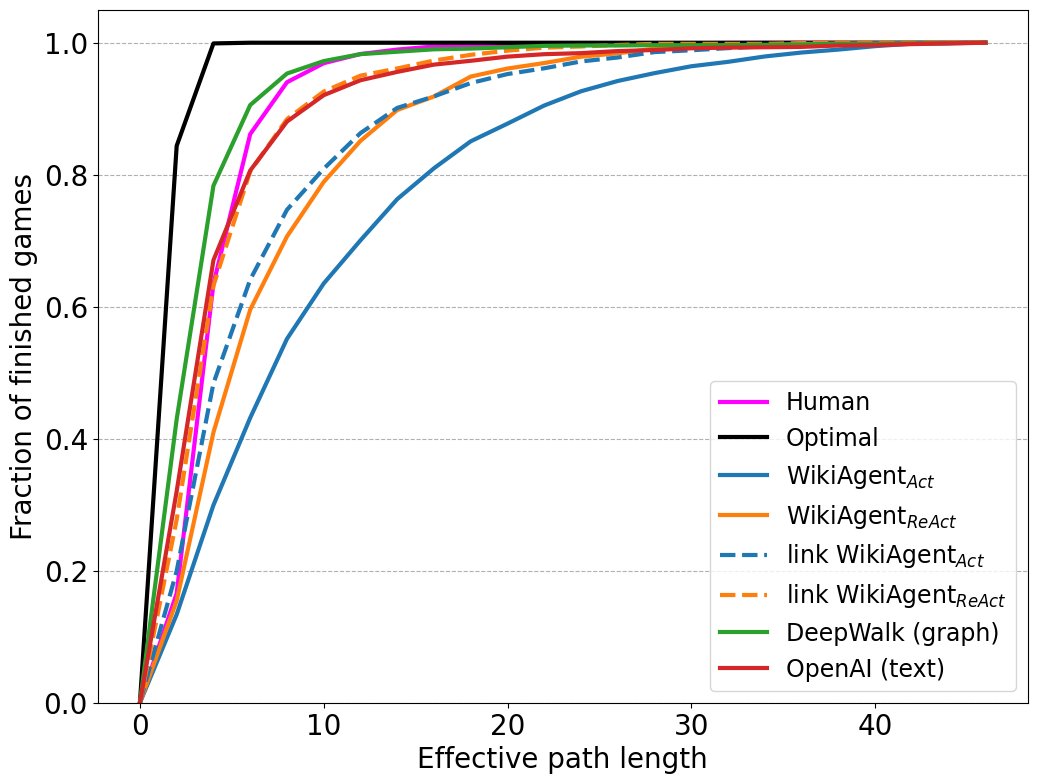

In [25]:

# make line plot
fontsize=20
markersize=12
linewidth=3

plt.figure(figsize=(12,9))

num_games = all_runs_df.groupby(['src', 'tgt']).size().reset_index().rename(columns={0:'num_games'})
print(num_games)


bins = [0]
edges = [0]
bins_, edges_ = np.histogram(filtered_paths_real_df.query("is_path_finished==1")['hepl'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='Human', linewidth=linewidth, color='magenta')

bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("is_finished==True")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings')]['spl'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='Optimal', linewidth=linewidth, color='black')


bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings')]['effective_path_len'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='WikiAgent$_{Act}$', linewidth=linewidth, color='tab:blue')

bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings_reason')]['effective_path_len'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='WikiAgent$_{ReAct}$', linewidth=linewidth, color='tab:orange')

bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back')]['effective_path_len'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='link WikiAgent$_{Act}$', linewidth=linewidth, color='tab:blue', linestyle='--')

bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back_reason')]['effective_path_len'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='link WikiAgent$_{ReAct}$', linewidth=linewidth, color='tab:orange', linestyle='--')


bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='link_click/embedding_deepwalk_dfs')]['effective_path_len'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='DeepWalk (graph)', linewidth=linewidth, color='tab:green')

bins = [0]
edges = [0]
bins_, edges_ = np.histogram(all_runs_df.query("success==1")[(all_runs_df['agent.agent_name']=='link_click/embedding_openai_dfs')]['effective_path_len'], bins=np.arange(0, 50, 2))
bins += bins_.tolist()
edges += edges_.tolist()
plt.plot(edges[:-1], np.cumsum(bins)/np.sum(bins), label='OpenAI (text)', linewidth=linewidth, color='tab:red')




plt.ylabel('Fraction of finished games', fontsize=fontsize)
plt.xlabel('Effective path length', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.ylim(0,1.05)
plt.yticks(fontsize=fontsize)
plt.xticks(fontsize=fontsize)
plt.legend(fontsize=fontsize-3)
plt.savefig('plots/human_cum_finished_length.pdf', bbox_inches='tight')


# all_runs_df.query("success==1")[
#     (all_runs_df['agent.agent_name']=='navigate/lmql_headings_reason')
# ]['effective_path_len'].hist(density=True, bins=20, alpha=0.5, label='navigate/lmql_headings_reason')


## Plot - Success Rate and Overhead vs SPL of game




 Success 


agent: navigate/lmql_headings
navigate/lmql_headings 2 0.9047619047619048 0.026796502435605163 0.8779654023262996 0.9315584071975099

navigate/lmql_headings 3 0.717948717948718 0.026237811088908103 0.6917109068598098 0.744186529037626

navigate/lmql_headings 4 0.39416058394160586 0.05796823893483083 0.33619234500677503 0.4521288228764367

navigate/lmql_headings 5 0.0925 0.0925 0 0.185

agent: navigate/lmql_headings_reason
navigate/lmql_headings_reason 2 0.9508547008547008 0.019606302614683768 0.931248398240017 0.9704610034693846

navigate/lmql_headings_reason 3 0.8325991189427313 0.02172933258903187 0.8108697863536994 0.8543284515317632

navigate/lmql_headings_reason 4 0.5776173285198556 0.05827398038713194 0.5193433481327236 0.6358913089069875

navigate/lmql_headings_reason 5 0.25 0.21913466179497937 0.03086533820502063 0.46913466179497937

agent: link_click/lmql_dfs_back
link_click/lmql_dfs_back 2 0.9932047091189524 0.006795290881047578 0.9864094182379048 1

link_click/

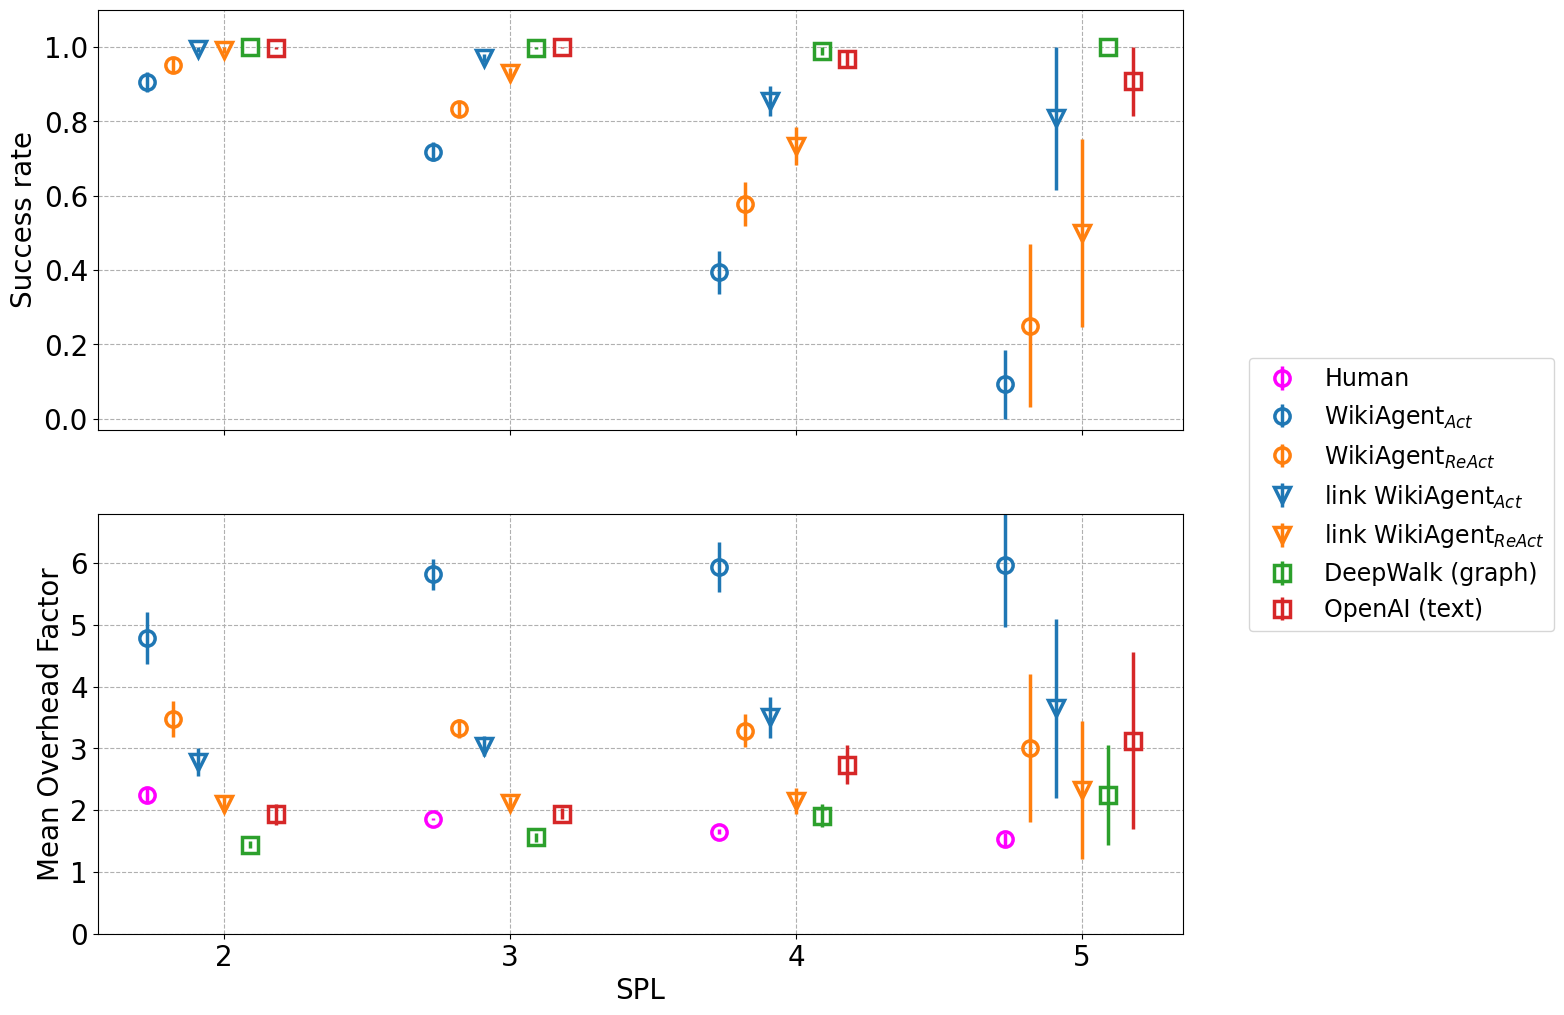

In [29]:
# make line plot
fontsize=20
markersize=11
markeredgewidth=2.5
linewidth=3
markerspacing=0.09
data = all_runs_df.query("is_finished==True")
spl_values = np.array([2,3,4,5])
# keep only games with spl in spl_values
data = data[data['spl'].isin(spl_values)]

def compute_mean_and_errors_by_spl(agent, field='success', operation='mean', max_val=1, min_val=0, data=data):
    print(f"agent: {agent}")
    means = []
    errors = []
    for spl in spl_values:
        try:
            lower = max(min_val, data[data['agent.agent_name']==agent].groupby('spl').agg({field:operation}).reset_index().query(f"spl=={spl}")[field].values[0] - data[data['agent.agent_name']==agent].groupby('spl').agg({field:'sem'}).reset_index().query(f"spl=={spl}")[field].values[0]*1.96)
            upper = min(max_val, data[data['agent.agent_name']==agent].groupby('spl').agg({field:operation}).reset_index().query(f"spl=={spl}")[field].values[0] + data[data['agent.agent_name']==agent].groupby('spl').agg({field:'sem'}).reset_index().query(f"spl=={spl}")[field].values[0]*1.96)
            mean = lower + (upper - lower)/2
            error = (upper - lower)/2
        except Exception as e:
            lower = min_val
            upper = max_val

        print(f"{agent} {spl} {mean} {error} {lower} {upper}\n")

        if lower==min_val and upper==max_val:
            mean = -1000
            error = 0
        means.append(mean)
        errors.append(error)
            
    return means, errors

fig, axes = plt.subplots(2,1, figsize=(14,12), sharex=True)  # Adjust the figsize as needed

# set active axis
plt.sca(axes[0])

# plot the success rate for grouped by spl
print("\n\n Success \n\n")
agent = 'navigate/lmql_headings'
means, errors = compute_mean_and_errors_by_spl(agent, field='success', operation='mean')
plt.errorbar(spl_values - markerspacing*3, means, yerr=errors, label='WikiAgent$_{Act}$', linewidth=0, marker='o', markersize=markersize, mfc='none', color='tab:blue', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)


agent = 'navigate/lmql_headings_reason'
means, errors = compute_mean_and_errors_by_spl(agent, field='success', operation='mean')
plt.errorbar(spl_values - markerspacing*2, means, yerr=errors, label='WikiAgent$_{ReAct}$', linewidth=0, marker='o', markersize=markersize, mfc='none', color='tab:orange', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/lmql_dfs_back'
means, errors = compute_mean_and_errors_by_spl(agent, field='success', operation='mean')
plt.errorbar(spl_values - markerspacing*1, means, yerr=errors, label='link WikiAgent$_{Act}$', linewidth=0, marker='v', markersize=markersize, mfc='none', color='tab:blue', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/lmql_dfs_back_reason'
means, errors = compute_mean_and_errors_by_spl(agent, field='success', operation='mean')
plt.errorbar(spl_values, means, yerr=errors, label='link WikiAgent$_{ReAct}$', linewidth=0, marker='v', markersize=markersize, mfc='none', color='tab:orange', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/embedding_deepwalk_dfs'
means, errors = compute_mean_and_errors_by_spl(agent, field='success', operation='mean')
plt.errorbar(spl_values + markerspacing*1, means, yerr=errors, label='DeepWalk (graph)', linewidth=0, marker='s', markersize=markersize, mfc='none', color='tab:green', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/embedding_openai_dfs'
means, errors = compute_mean_and_errors_by_spl(agent, field='success', operation='mean')
plt.errorbar(spl_values + markerspacing*2, means, yerr=errors, label='OpenAI (text)', linewidth=0, marker='s', markersize=markersize, mfc='none', color='tab:red', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

plt.ylabel('Success rate', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.grid(axis='x', linestyle='--')
plt.ylim(-0.03,1.1)
plt.yticks(fontsize=fontsize)

data = all_runs_df.query("success==1")

#####################################################
# set active axis
plt.sca(axes[1])

print("\n\n Overhead \n\n")

# for human
valid_spl_values = np.array([2,3,4,5])
means = filtered_paths_real_df.query("is_path_finished==1").groupby('spl').agg({'overhead_spl':'mean'}).reset_index().query("spl in [2,3,4,5]")['overhead_spl']
errors = filtered_paths_real_df.query("is_path_finished==1").groupby('spl').agg({'overhead_spl':'sem'}).reset_index().query("spl in [2,3,4,5]")['overhead_spl']*1.96
plt.errorbar(valid_spl_values - markerspacing*3, means, yerr=errors, label='Human', linewidth=0, marker='o', markersize=markersize, mfc='none', color='magenta', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'navigate/lmql_headings'
# means = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'mean'}).reset_index()['overhead_spl']
# errors = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'sem'}).reset_index()['overhead_spl']*1.96
# valid_spl_values = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'sem'}).reset_index()['spl']
# plt.errorbar(valid_spl_values - markerspacing*3, means, yerr=errors, label='WikiAgent$_{Act}$', linewidth=0, marker='o', markersize=markersize, mfc='none', color='tab:blue', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)
print(f"agent: {agent}")
means, errors = compute_mean_and_errors_by_spl(agent, field='overhead_spl', operation='mean', max_val=1000, min_val=1)
plt.errorbar(spl_values - markerspacing*3, means, yerr=errors, label='WikiAgent$_{Act}$', linewidth=0, marker='o', markersize=markersize, mfc='none', color='tab:blue', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)
agent = 'navigate/lmql_headings_reason'
print(f"agent: {agent}")
means, errors = compute_mean_and_errors_by_spl(agent, field='overhead_spl', operation='mean', max_val=1000, min_val=1)
plt.errorbar(spl_values - markerspacing*2, means, yerr=errors, label='WikiAgent$_{ReAct}$', linewidth=0, marker='o', markersize=markersize, mfc='none', color='tab:orange', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

# valid_spl_values = np.array([2,3,4])
# means = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'mean'}).reset_index().query("spl in [2,3,4]")['overhead_spl']
# errors = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'sem'}).reset_index().query("spl in [2,3,4]")['overhead_spl']*1.96
# plt.errorbar(valid_spl_values - markerspacing*2, means, yerr=errors, label='WikiAgent$_{ReAct}$', linewidth=0, marker='o', markersize=markersize, mfc='none', color='tab:orange', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)
# # we wont draw this because it only finished 1 game

agent = 'link_click/lmql_dfs_back'
print(f"agent: {agent}")
# valid_spl_values = np.array([2,3,4,5])
# means = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'mean'}).reset_index().query("spl in [2,3,4,5]")['overhead_spl']
# errors = data[data['agent.agent_name']==agent].groupby('spl').agg({'overhead_spl':'sem'}).reset_index().query("spl in [2,3,4,5]")['overhead_spl']*1.96
# plt.errorbar(valid_spl_values - markerspacing*1, means, yerr=errors, label='link WikiAgent$_{Act}$', linewidth=0, marker='v', markersize=markersize, mfc='none', color='tab:blue', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)
means, errors = compute_mean_and_errors_by_spl(agent, field='overhead_spl', operation='mean', max_val=1000, min_val=1)
plt.errorbar(spl_values - markerspacing*1, means, yerr=errors, label='link WikiAgent$_{Act}$', linewidth=0, marker='v', markersize=markersize, mfc='none', color='tab:blue', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/lmql_dfs_back_reason'
print(f"agent: {agent}")
means, errors = compute_mean_and_errors_by_spl(agent, field='overhead_spl', operation='mean', max_val=1000, min_val=1)
plt.errorbar(spl_values, means, yerr=errors, label='link WikiAgent$_{ReAct}$', linewidth=0, marker='v', markersize=markersize, mfc='none', color='tab:orange', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/embedding_deepwalk_dfs'
means, errors = compute_mean_and_errors_by_spl(agent, field='overhead_spl', operation='mean', max_val=1000, min_val=1)
plt.errorbar(spl_values + markerspacing*1, means, yerr=errors, label='DeepWalk (graph)', linewidth=0, marker='s', markersize=markersize, mfc='none', color='tab:green', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

agent = 'link_click/embedding_openai_dfs'
means, errors = compute_mean_and_errors_by_spl(agent, field='overhead_spl', operation='mean', max_val=1000, min_val=1)
plt.errorbar(spl_values + markerspacing*2, means, yerr=errors, label='OpenAI (text)', linewidth=0, marker='s', markersize=markersize, mfc='none', color='tab:red', elinewidth=markeredgewidth, markeredgewidth=markeredgewidth)

plt.xlabel('SPL', fontsize=fontsize)
plt.ylabel('Mean Overhead Factor', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.grid(axis='x', linestyle='--')
plt.ylim(0,6.8)
plt.yticks(fontsize=fontsize)
plt.xticks([2,3,4,5], fontsize=fontsize)
plt.legend(fontsize=fontsize-3, bbox_to_anchor=(1.05, 1.4), loc='upper left')


# plt.savefig('plots/human_success_overhead_spl.pdf', bbox_inches='tight')

In [39]:
# see successful games for navigate/lmql_headings_reason with spl=5
all_runs_df.query("is_finished_reason=='max_actions'")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings_reason') & (all_runs_df['spl']==4)][['src', 'tgt', 'spl', 'path_so_far', 'effective_path_so_far']].head(10)

/tmp/ipykernel_280439/1134874803.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  all_runs_df.query("is_finished_reason=='max_actions'")[(all_runs_df['agent.agent_name']=='navigate/lmql_headings_reason') & (all_runs_df['spl']==4)][['src', 'tgt', 'spl', 'path_so_far', 'effective_path_so_far']].head(10)


,src,tgt,spl,path_so_far,effective_path_so_far
19008,Kestrel,Apatosaurus,4,Kestrel;Scientific_classification;Mammal;Dinosaur;Sauropodomorpha;Saurischia;Theropoda;<;Ornithischia;<;Herbivore;Animal;Chordate;Vertebrate;Whale;<;Reptile;Bird;Jurassic;Cretaceous;Cretaceous-Tertiary_extinction_event;Photosynthesis;<;Oligocene;<;Insect;Pollinator_decline;<;<;Worm;<;Tuatara;<;Geology;Fossil;Mineral;Feldspar;<;Gypsum;<;Mining;Copper;Arthropod;<;Zinc;<;Sumer;Mesopotamia;<;<;China,Kestrel;Scientific_classification;Mammal;Dinosaur;Sauropodomorpha;Saurischia;Herbivore;Animal;Chordate;Vertebrate;Reptile;Bird;Jurassic;Cretaceous;Cretaceous-Tertiary_extinction_event;Geology;Fossil;Mineral;Mining;Copper;China
19727,Damascus,Imperative_programming,4,Damascus;Ancient_Egypt;Culture;Religion;<;Multiculturalism;Society;<;Ireland;<;Ayaan_Hirsi_Ali;Political_science;Political_economy;History;Humanities;China;Civilization;Technology;Computer_science;Alan_Turing;Princeton_University;Engineering;Science;Physics;Mathematics;Mathematical_analysis;Ordinary_differential_equation;<;<;Differential_equation;Schrödinger_equation;Quantum_mechanics;<;<;<;American_English;<;Business;Mining;<;Manufacturing;Electronics;Computer;Computer_and_video_games;Nintendo_Entertainment_System;Super_Mario_Bros.;<;Soviet_Union;United_States;World_War_II;<,Damascus;Ancient_Egypt;Culture;Multiculturalism;Ayaan_Hirsi_Ali;Political_science;Political_economy;History;Humanities;China;Civilization;Technology;Computer_science;Alan_Turing;Princeton_University;Engineering;Science;Physics;Mathematics;Business;Manufacturing;Electronics;Computer;Computer_and_video_games;Nintendo_Entertainment_System;Soviet_Union;United_States
20128,Kangaroo,House,4,"Kangaroo;Continent;<;Australia;Constitutional_monarchy;Italy;Medieval_commune;Guild;Germany;<;Europe;European_Union;Greece;Currency;Country;Government;Education;<;Democracy;United_States_Constitution;United_States_House_of_Representatives;<;Rhode_Island;Atlantic_Ocean;Mediterranean_Sea;Spain;Istanbul;United_States;Grenada;United_Kingdom;Canterbury_Cathedral;Bede;Durham_Cathedral;Canute_the_Great;Jomsvikings;Baltic_Sea;Sweden;Chicago;Michael_Jordan;<;<;Minnesota;U.S._state;United_States_Congress;United_States_Senate;American_Civil_War;Abraham_Lincoln;Richmond,_Virginia;Thomas_Jefferson;John_Locke;Bristol","Kangaroo;Australia;Constitutional_monarchy;Italy;Medieval_commune;Guild;Europe;European_Union;Greece;Currency;Country;Government;Democracy;United_States_Constitution;Rhode_Island;Atlantic_Ocean;Mediterranean_Sea;Spain;Istanbul;United_States;Grenada;United_Kingdom;Canterbury_Cathedral;Bede;Durham_Cathedral;Canute_the_Great;Jomsvikings;Baltic_Sea;Sweden;Minnesota;U.S._state;United_States_Congress;United_States_Senate;American_Civil_War;Abraham_Lincoln;Richmond,_Virginia;Thomas_Jefferson;John_Locke;Bristol"
20235,Wikimedia_Foundation,Dr._Seuss,4,Wikimedia_Foundation;Jimmy_Wales;Chicago;University_of_Chicago;University_of_Cambridge;United_States;Christopher_Columbus;Italy;<;India;<;Europe;<;China;<;Japan;Buddhism;Mind;Emotion;Human;Tokyo;People's_Republic_of_China;Vietnam;<;Hanoi;<;France;French_language;<;<;<;Beijing;<;Indonesia;<;Cairo;<;United_Kingdom;English_language;Drama;Ming_Dynasty;Chinese_language;Arabic_language;<;Cambodia;<;<;<;Opera;Giuseppe_Verdi;William_Shakespeare,Wikimedia_Foundation;Jimmy_Wales;Chicago;University_of_Chicago;University_of_Cambridge;United_States;Christopher_Columbus;Japan;Buddhism;Mind;Emotion;Human;Tokyo;United_Kingdom;English_language;Drama;Opera;Giuseppe_Verdi;William_Shakespeare
20973,United_States_Declaration_of_Independence,Wayne_Rooney,4,United_States_Declaration_of_Independence;John_Adams;United_States;British_Virgin_Islands;English_language;<;Elizabeth_II_of_the_United_Kingdom;Buckingham_Palace;<;George_VI_of_the_United_Kingdom;<;London;Arsenal_F.C.;<;Football_(soccer);Japan;Sumo;<;Saudi_Arabia;Basketball;Netball;<;Michael_Jordan;<;Volleyball;Olympic_Games;England;Football;American_football;<;Sphere;<;Edward_

In [34]:
filtered_paths_real_df.query("is_path_finished==1 and spl==5")

,hashed_ip,timestamp,src,tgt,is_path_finished,failure_type,path,hpl,spl,duration_in_sec,target_in_degree,user_path_rating,effective_path,hepl,shpl,shepl,mhepl,agent_id,overhead_spl,long_path
3543,5b11385708a32c11,1251289204,Colombia,Menthol,1,NaN,Colombia;Caribbean_Sea;James_Bond;Switzerland;Cheese;Lemon;Chemistry;Medicine;Tobacco;Tea;Flower;<;Ethanol;Alcohol;Vanilla;Essential_oil;List_of_essential_oils;Star_anise;<;Basil;Essential_oil;List_of_essential_oils;Rosemary;<;Tarragon;<;Fennel;Mentha;Menthol,28,5,1762,2,5.0,Colombia;Caribbean_Sea;James_Bond;Switzerland;Cheese;Lemon;Chemistry;Medicine;Tobacco;Tea;Ethanol;Alcohol;Vanilla;Essential_oil;List_of_essential_oils;Basil;Essential_oil;List_of_essential_oils;Fennel;Mentha;Menthol,20,7.0,7.0,8.5,1175,4.0,1
3544,614f1f9a3c5772c5,1265720024,Colombia,Menthol,1,NaN,Colombia;English_language;<;Pacific_Ocean;Japan;<;Earth;Oxygen;Plant;Flower;Fruit;Halloween;<;Olive_oil;Chemistry;<;Mentha;Menthol,17,5,586,2,NaN,Colombia;Pacific_Ocean;Earth;Oxygen;Plant;Flower;Fruit;Olive_oil;Mentha;Menthol,9,7.0,7.0,8.5,1175,1.8,0
3545,614f1f9a3c5772c5,1265720200,Colombia,Menthol,1,NaN,Colombia;Petroleum;Ethanol;Alcohol;Sulfuric_acid;<;Vanilla;Essential_oil;Medicine;<;<;Fruit;Halloween;<;<;<;Benzene;<;Arabic_language;<;Alchemy;Japan;<;<;<;<;Ethanol;<;Ethanol;Alcohol;Vanilla;Fruit;Olive_oil;Mentha;Menthol,34,5,764,2,4.0,Colombia;Petroleum;Ethanol;Alcohol;Vanilla;Fruit;Olive_oil;Mentha;Menthol,8,7.0,7.0,8.5,1175,1.6,0
3546,614f1f9a3c5772c5,1265720238,Colombia,Menthol,1,NaN,Colombia;Petroleum;Oxygen;Plant;Fruit;Olive_oil;Mentha;Menthol,7,5,59,2,NaN,Colombia;Petroleum;Oxygen;Plant;Fruit;Olive_oil;Mentha;Menthol,7,7.0,7.0,8.5,1175,1.4,0
4498,47af05d72be2b67a,1274727129,Fertilizer,Animal_law,1,NaN,Fertilizer;Plant;Animal;Human;Law;Human_rights;Animal_rights;Animal_law,7,5,229,1,NaN,Fertilizer;Plant;Animal;Human;Law;Human_rights;Animal_rights;Animal_law,7,5.0,5.0,7.0,1820,1.4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17145,101779c07d4d00f0,1252228700,Richard_II_of_England,Windows_2000,1,NaN,Richard_II_of_England;William_Shakespeare;<;England;Football;United_States;Computer;Microsoft_Windows;Windows_2000,8,5,290,10,2.0,Richard_II_of_England;England;Football;United_States;Computer;Microsoft_Windows;Windows_2000,6,5.0,5.0,6.0,1305,1.2,0
17146,1b4d820134d8ae92,1255644714,Richard_II_of_England,Windows_2000,1,NaN,Richard_II_of_England;England;Finance;Mathematics;Computer_science;Internet;Microsoft;Microsoft_Windows;Windows_2000,8,5,322,10,4.0,Richard_II_of_England;England;Finance;Mathematics;Computer_science;Internet;Microsoft;Microsoft_Windows;Windows_2000,8,5.0,5.0,6.0,1305,1.6,0
17147,5c47b517641e8486,1259423566,Richard_II_of_England,Windows_2000,1,NaN,Richard_II_of_England;England;Tim_Berners-Lee;Computer;Microsoft_Windows;Windows_2000,5,5,95,10,2.0,Richard_II_of_England;England;Tim_Berners-Lee;Computer;Microsoft_Windows;Windows_2000,5,5.0,5.0,6.0,1305,1.0,0
17148,7c39b1c4391c4fb5,1260293628,Richard_II_of_England,Windows_2000,1,NaN,Richard_II_of_England;England;<;Spain;California;Computer;Microsoft_Windows;Windows_2000,7,5,201,10,2.0,Richard_II_of_England;Spain;California;Computer;Microsoft_Windows;Windows_2000,5,5.0,5.0,6.0,1305,1.0,0


## Plot - Human SPL Distribution

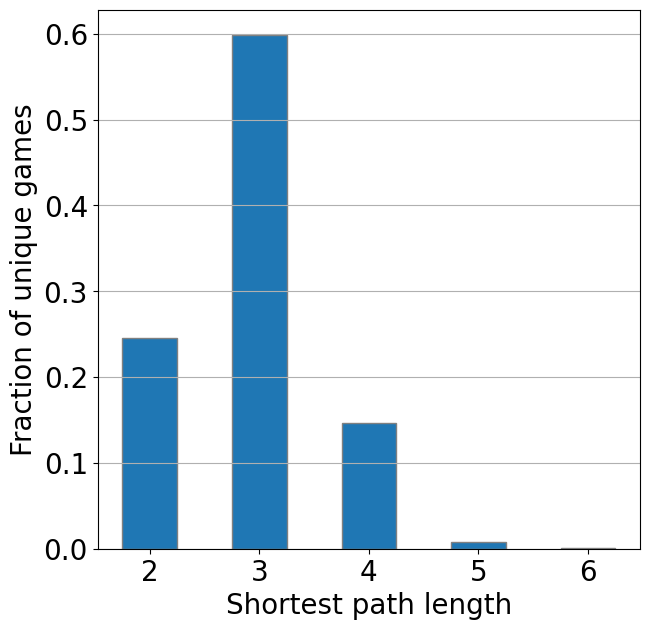

In [47]:
# Visual settings
fontsize=20
markersize=11
markeredgewidth=2.5
linewidth=3
barWidth = 0.5

#plot hist of spl distribution in games
fractions = all_runs_df[all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back'].query("is_finished==True").groupby('spl').size()/all_runs_df[all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back'].query("is_finished==True").shape[0]
plt.figure(figsize=(7,7))
plt.bar(fractions.index, fractions, width=barWidth, color='tab:blue', edgecolor='gray')
plt.ylabel('Fraction of unique games', fontsize=fontsize)
plt.xlabel('Shortest path length', fontsize=fontsize)
plt.xticks(fontsize=fontsize)
plt.yticks(fontsize=fontsize)
plt.grid(axis='y', linestyle='-')
plt.savefig('plots/human_spl_distribution.pdf', bbox_inches='tight')


In [43]:
print(all_runs_df[all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back'].query("is_finished==True")['spl'].describe())
print(all_runs_df[all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back'].query("is_finished==True")['spl'].median())

count    1914.000000
mean        2.921108
std         0.655145
min         2.000000
25%         3.000000
50%         3.000000
75%         3.000000
max         6.000000
Name: spl, dtype: float64
3.0


In [46]:
all_runs_df[all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back'].query("is_finished==True").groupby('spl').size()

spl
2     470
3    1145
4     281
5      16
6       2
dtype: int64

## Plot - Out-degree Distribution vs Clicks to Target

In [4]:
article_links_file = os.path.join(PATH_IN, 'article_links.tsv')
article_links_df = pd.read_csv(article_links_file, sep='\t')
article_links_df['out_degree'] = article_links_df['links'].apply(lambda x: len(x.split(';')))

missing_articles = set(all_runs_df['effective_path_so_far'].str.split(';', expand=True).values.flatten()) - set(article_links_df['article'].values)
missing_articles = [article for article in missing_articles if article != None]

# keep only finished runs without missing articles
# get ilocs of rows with missing
missing_idx = all_runs_df.query("is_finished==True").index[all_runs_df.query("is_finished==True")['effective_path_so_far'].str.split(';', expand=True).isin(missing_articles).any(axis=1)]

all_runs_df = all_runs_df.drop(missing_idx)

# in all_runs_df, add a column with the progression of the out_degree of the effective_path_so_far (like Hand;Portugal;Fire;Burn), outputting something like: 2;14;500;2
def get_out_degree_progression(row, is_finished_col='is_finished', path_col='effective_path_so_far'):
    out_degrees = []
    if row[is_finished_col]==False:
        return ''
    
    for article in row[path_col].split(';'):
        out_degrees.append(article_links_df[article_links_df['article']==article]['out_degree'].values[0])
    return ';'.join([str(x) for x in out_degrees])

all_runs_df['out_degree_progression'] = all_runs_df.apply(get_out_degree_progression, axis=1)
filtered_paths_real_df['out_degree_progression'] = filtered_paths_real_df.apply(get_out_degree_progression, axis=1, args=('is_path_finished', 'effective_path'))
# remove last out_degree_progression element because it is the target
filtered_paths_real_df['out_degree_progression'] = filtered_paths_real_df['out_degree_progression'].apply(lambda x: ';'.join(x.split(';')[:-1]) if x!='' else '')

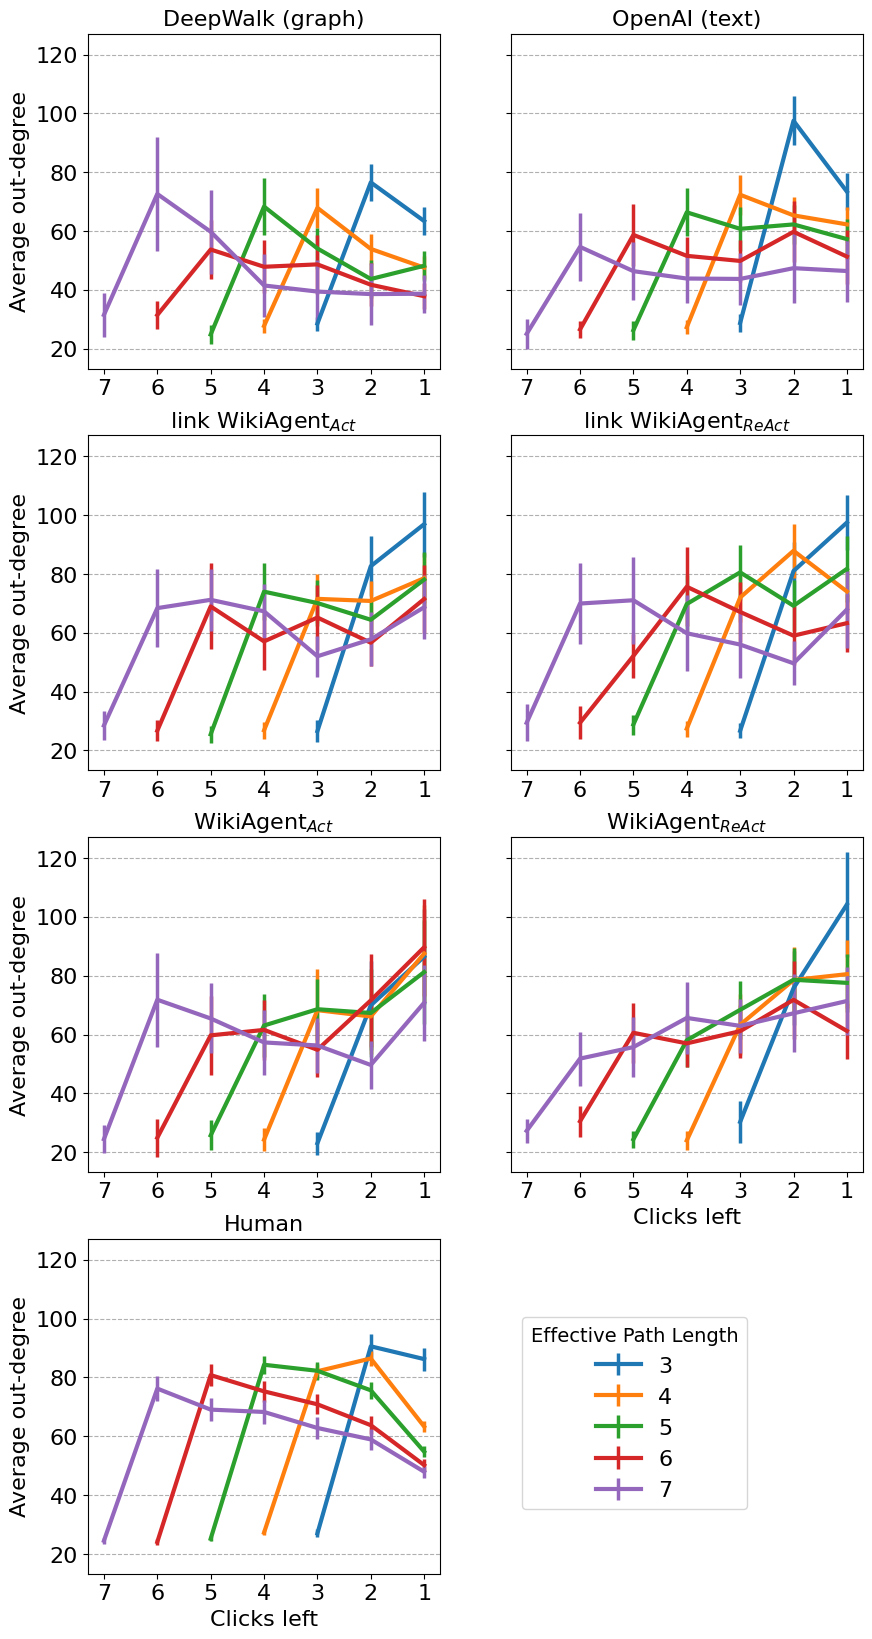

In [10]:
# Visual settings
fontsize=20
markersize=11
markeredgewidth=2.5
linewidth=3


agents = ['link_click/embedding_deepwalk_dfs', 'link_click/embedding_openai_dfs', 'link_click/lmql_dfs_back', 'link_click/lmql_dfs_back_reason', 'navigate/lmql_headings', 'navigate/lmql_headings_reason', 'human']
agents_to_coord = {'link_click/embedding_deepwalk_dfs': (0,0), 'link_click/embedding_openai_dfs': (0,1), 'link_click/lmql_dfs_back': (1,0), 'link_click/lmql_dfs_back_reason': (1,1), 'navigate/lmql_headings': (2,0), 'navigate/lmql_headings_reason': (2,1), 'human': (3,0)}
agents_to_title = {'link_click/lmql_dfs_back': 'link WikiAgent$_{Act}$', 'link_click/lmql_dfs_back_reason': 'link WikiAgent$_{ReAct}$', 'link_click/embedding_deepwalk_dfs': 'DeepWalk (graph)', 'link_click/embedding_openai_dfs': 'OpenAI (text)', 'navigate/lmql_headings': 'WikiAgent$_{Act}$', 'navigate/lmql_headings_reason': 'WikiAgent$_{ReAct}$', 'human': 'Human'}
game_lengths = [3,4,5,6,7]
# make 4x2 plot
fig, axes = plt.subplots(4,2, figsize=(10,20), sharex=False, sharey=True)  # Adjust the figsize as needed
# fix the spl at 3
spl = 3
for agent in agents:
    # set active axis
    plt.sca(axes[agents_to_coord[agent][0], agents_to_coord[agent][1]])
    for game_length in game_lengths:
        if agent!='human':
            data = all_runs_df[(all_runs_df['agent.agent_name']==agent)].query("success==1 and spl==@spl and effective_path_len==@game_length")['out_degree_progression'].values
        else:
            data = filtered_paths_real_df.query("is_path_finished==1 and spl==@spl and hepl==@game_length")['out_degree_progression'].values
        out_degree_progressions = [prog.split(";") for prog in data]
        out_degree_progressions = np.array([np.array(list(map(int, prog))) for prog in out_degree_progressions])
        avg_out_degree_progression = np.mean(out_degree_progressions, axis=0)
        # use SEM to compute 95% confidence interval
        error_out_degree_progression = np.std(out_degree_progressions, axis=0)/np.sqrt(out_degree_progressions.shape[0])*1.96
        x_array = np.arange(max(game_lengths)-game_length, max(game_lengths))
        plt.errorbar(x_array, avg_out_degree_progression, yerr=error_out_degree_progression, label=f"{game_length}", linewidth=linewidth, marker='', elinewidth=markeredgewidth)
        plt.title(agents_to_title[agent], fontsize=fontsize-4)
        plt.xticks(range(game_length), [game_length-x for x in range(game_length)], fontsize=fontsize-4)
        plt.yticks(fontsize=fontsize-4)
        plt.grid(axis='y', linestyle='--')
        plt.xlabel('Clicks left', fontsize=fontsize-4) if agent=='human' or agent=='navigate/lmql_headings_reason' else None
        plt.ylabel('Average out-degree', fontsize=fontsize-4) if agents_to_coord[agent][1]==0 else None

fig.delaxes(axes[3,1])

# xticks are the clicks left to reach the target, that is, game_length - clicks_so_far
plt.legend(fontsize=fontsize-4, title='Effective Path Length', bbox_to_anchor=(1.2, 0.8), loc='upper left')
plt.savefig('plots/out_degree_progression.pdf', bbox_inches='tight')



In [9]:
all_runs_df[(all_runs_df['agent.agent_name']=='navigate/lmql_headings_reason')].query("success==1 and spl==3 and effective_path_len==3")[['src', 'tgt', 'effective_path_so_far', 'out_degree_progression', 'effective_path_len']]

,src,tgt,effective_path_so_far,out_degree_progression,effective_path_len
888,Pea,Sea,Pea;France;Atlantic_Ocean,26;85;125,3
1245,Vietnam_War,Anglicanism,Vietnam_War;Soviet_Union;Christianity,31;65;49,3
1372,Animal_law,Coffee,Animal_law;Animal_rights;Brazil,1;26;80,3
1441,Watchmen,Dresden,Watchmen;Soviet_Union;Germany,22;65;169,3
1446,Graphic_novel,Political_philosophy,Graphic_novel;Publishing;Law,12;14;98,3
...,...,...,...,...,...
451495,Asia,Neil_Armstrong,Asia;China;United_States,137;90;294,3
451577,Brain,Television,Brain;Computer_science;Game_theory,54;17;24,3
452490,John_Adams,Train,John_Adams;Netherlands;Transport,22;116;30,3
454221,Ant,Avalanche,Ant;Earth;Mount_Everest,31;118;28,3


## Plot - Click Precision vs SPL to Target

In [7]:
article_links_file = os.path.join(PATH_IN, 'article_links.tsv')
article_links_df = pd.read_csv(article_links_file, sep='\t')
article_links_df['out_degree'] = article_links_df['links'].apply(lambda x: len(x.split(';')))

missing_articles = set(all_runs_df['effective_path_so_far'].str.split(';', expand=True).values.flatten()) - set(article_links_df['article'].values)
missing_articles = [article for article in missing_articles if article != None]

# keep only finished runs without missing articles
# get ilocs of rows with missing
missing_idx = all_runs_df.query("is_finished==True").index[all_runs_df.query("is_finished==True")['effective_path_so_far'].str.split(';', expand=True).isin(missing_articles).any(axis=1)]

all_runs_df = all_runs_df.drop(missing_idx)

# precision is 1 if the spl to tgt decreased and 0 if it increased or stayed the same
def get_precision_progression(row, is_finished_col='is_finished', path_col='effective_path_so_far'):
    precisions = []
    if row[is_finished_col]==False:
        return ''
    
    for i, article in enumerate(row[path_col].split(';')):
        if i==0:
            precisions.append(0)
        else:
            prev_spl = get_spl(row[path_col].split(';')[i-1], row['tgt'])
            spl = get_spl(article, row['tgt'])
            if spl<prev_spl:
                precisions.append(1)
            else:
                precisions.append(0)
    return ';'.join([str(x) for x in precisions])

def get_spl_progression(row, is_finished_col='is_finished', path_col='effective_path_so_far'):
    spls = []
    if row[is_finished_col]==False:
        return ''
    
    for i, article in enumerate(row[path_col].split(';')):
        spl = get_spl(article, row['tgt'])
        spls.append(str(spl))
    return ';'.join(spls)

all_runs_df['precision_progression'] = all_runs_df.apply(get_precision_progression, axis=1)
# remove first precision_progression element because it is always 0, and we add 1 at the end because the agent always clicks on the target
all_runs_df['precision_progression'] = all_runs_df['precision_progression'].apply(lambda x: ';'.join(x.split(';')[1:]+['1']) if x!='' else '')
all_runs_df['spl_progression'] = all_runs_df.apply(get_spl_progression, axis=1)

filtered_paths_real_df['precision_progression'] = filtered_paths_real_df.apply(get_precision_progression, axis=1, args=('is_path_finished', 'effective_path'))
# remove last precision_progression element because it is the target
# filtered_paths_real_df['precision_progression'] = filtered_paths_real_df['precision_progression'].apply(lambda x: ';'.join(x.split(';')[:-1]) if x!='' else '')
# remove first precision_progression element because it is always 0
filtered_paths_real_df['precision_progression'] = filtered_paths_real_df['precision_progression'].apply(lambda x: ';'.join(x.split(';')[1:]) if x!='' else '')
filtered_paths_real_df['spl_progression'] = filtered_paths_real_df.apply(get_spl_progression, axis=1, args=('is_path_finished', 'effective_path'))
# remove last spl_progression element because it is always 0
filtered_paths_real_df['spl_progression'] = filtered_paths_real_df['spl_progression'].apply(lambda x: ';'.join(x.split(';')[:-1]) if x!='' else '')


In [230]:
filtered_paths_real_df

,hashed_ip,timestamp,src,tgt,is_path_finished,failure_type,path,hpl,spl,duration_in_sec,...,hepl,shpl,shepl,mhepl,agent_id,overhead_spl,long_path,out_degree_progression,precision_progression,spl_progression
0,20418ff4797f96be,1229188046,14th_century,Rainbow,1,NaN,14th_century;Time;Isaac_Newton;Light;Color;Rainbow,5,3,139,...,5,3.0,3.0,4.0,1012,1.666667,0,31;42;56;55;19,1;1;0;0;1,3;2;1;1;1
1,08888b1b428dd90e,1232241510,14th_century,Rainbow,1,NaN,14th_century;Time;Light;Rainbow,3,3,74,...,3,3.0,3.0,4.0,1012,1.000000,0,31;42;55,1;1;1,3;2;1
2,08888b1b428dd90e,1232241601,14th_century,Rainbow,1,NaN,14th_century;15th_century;Plato;Nature;Ultraviolet;Color;Rainbow,6,3,167,...,6,3.0,3.0,4.0,1012,2.000000,0,31;57;44;69;34;19,1;0;0;1;1;1,3;2;3;3;2;1
3,4cb0068c36658716,1248654953,14th_century,Rainbow,1,NaN,14th_century;Time;Science;Nature;Weather;Sunlight;<;Sun;Earth's_atmosphere;Ultraviolet;Color;Light;Rainbow,12,3,253,...,10,3.0,3.0,4.0,1012,3.333333,1,31;42;40;69;43;74;27;34;19;55,1;0;0;0;1;0;1;1;0;1,3;2;3;3;3;2;3;2;1;1
4,1082b6b8501a04b1,1248791776,14th_century,Rainbow,1,NaN,14th_century;Christianity;Bible;God;Nature;Earth's_atmosphere;Ultraviolet;Optical_fiber;Light;Rainbow,9,3,218,...,9,3.0,3.0,4.0,1012,3.000000,1,31;49;21;36;69;27;34;10;55,0;0;1;0;0;1;0;1;1,3;3;3;2;3;3;2;2;1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19659,13353b56792b791c,1250715110,Milkshake,Utilitarianism,1,NaN,Milkshake;United_States;History_of_slavery;Human_rights;Philosophy;Ethics;Utilitarianism,6,3,116,...,6,4.0,4.0,5.5,874,2.000000,0,10;294;78;71;87;20,1;0;1;1;0;1,3;2;3;2;1;1
19660,097a33801004befa,1250715112,Milkshake,Utilitarianism,1,NaN,Milkshake;United_Kingdom;Capitalism;Political_economy;Karl_Marx;Socialism;Utilitarianism,6,3,120,...,6,4.0,4.0,5.5,874,2.000000,0,10;168;47;19;63;41,1;0;0;0;1;1,3;2;2;2;2;1
19661,110178ca619f324a,1254834481,Milkshake,Utilitarianism,1,NaN,Milkshake;United_States;United_States_Declaration_of_Independence;<;United_States_Constitution;Government;Libertarianism;Utilitarianism,7,3,94,...,5,4.0,4.0,5.5,874,1.666667,0,10;294;25;28;26,1;0;0;1;1,3;2;2;2;1
19662,77c7dba82bdc0ee4,1323409770,Milkshake,Utilitarianism,1,NaN,Milkshake;United_Kingdom;Bertrand_Russell;Philosophy;Utilitarianism,4,3,144,...,4,4.0,4.0,5.5,874,1.333333,0,10;168;69;87,1;1;0;1,3;2;1;1


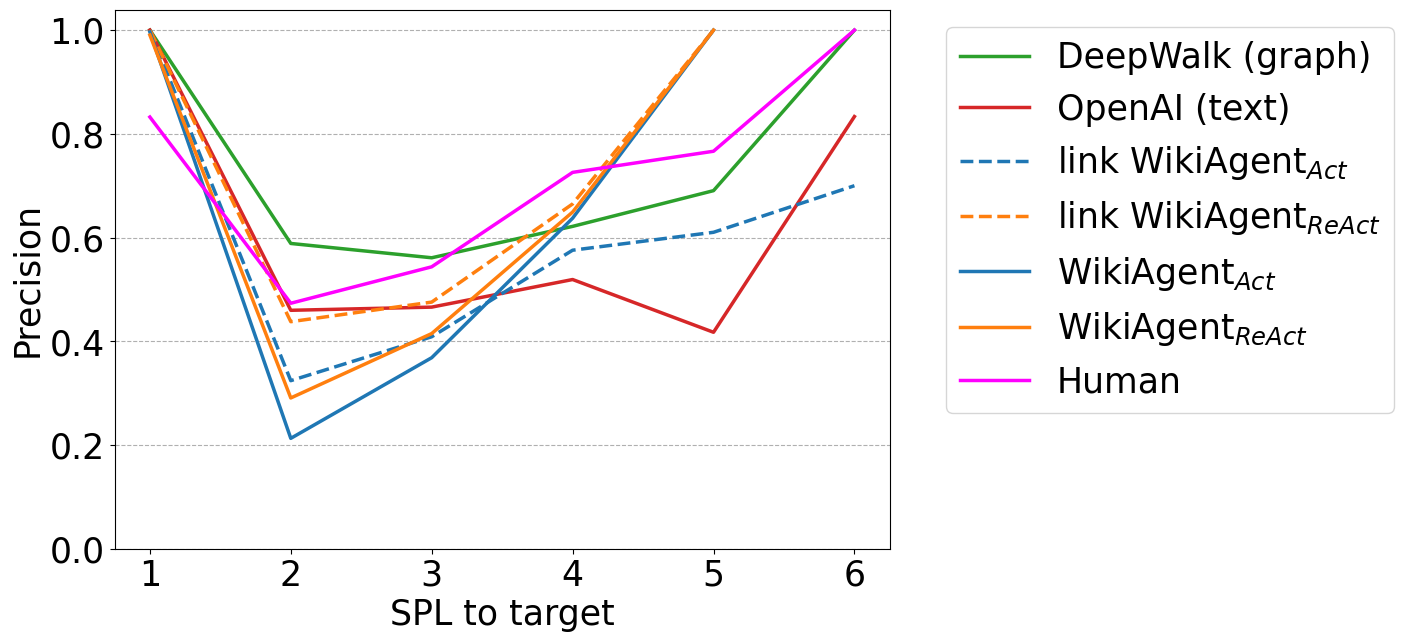

In [12]:
# Visual settings
fontsize=20
markersize=11
markeredgewidth=2.5
linewidth=2.5
agents = ['link_click/embedding_deepwalk_dfs', 'link_click/embedding_openai_dfs', 'link_click/lmql_dfs_back', 'link_click/lmql_dfs_back_reason', 'navigate/lmql_headings', 'navigate/lmql_headings_reason', 'human']
agents_to_title = {'link_click/lmql_dfs_back': 'link WikiAgent$_{Act}$', 'link_click/lmql_dfs_back_reason': 'link WikiAgent$_{ReAct}$', 'link_click/embedding_deepwalk_dfs': 'DeepWalk (graph)', 'link_click/embedding_openai_dfs': 'OpenAI (text)', 'navigate/lmql_headings': 'WikiAgent$_{Act}$', 'navigate/lmql_headings_reason': 'WikiAgent$_{ReAct}$', 'human': 'Human'}
agents_to_color = {'link_click/lmql_dfs_back': 'tab:blue', 'link_click/lmql_dfs_back_reason': 'tab:orange', 'link_click/embedding_deepwalk_dfs': 'tab:green', 'link_click/embedding_openai_dfs': 'tab:red', 'navigate/lmql_headings': 'tab:blue', 'navigate/lmql_headings_reason': 'tab:orange', 'human': 'magenta'}
agents_to_linestyle = {'link_click/lmql_dfs_back': '--', 'link_click/lmql_dfs_back_reason': '--', 'link_click/embedding_deepwalk_dfs': '-', 'link_click/embedding_openai_dfs': '-', 'navigate/lmql_headings': '-', 'navigate/lmql_headings_reason': '-', 'human': '-'}
plt.figure(figsize=(10,7))


for agent in agents:
    if agent!='human':
        spl_progressions = all_runs_df[(all_runs_df['agent.agent_name']==agent)].query("success==1")['spl_progression'].values
        precision_progressions = all_runs_df[(all_runs_df['agent.agent_name']==agent)].query("success==1")['precision_progression'].values
    else:
        spl_progressions = filtered_paths_real_df.query("is_path_finished==1")['spl_progression'].values
        precision_progressions = filtered_paths_real_df.query("is_path_finished==1")['precision_progression'].values
    spl_dict = {1:[],2:[], 3:[], 4:[], 5:[], 6:[]}
    for i, spl_progression in enumerate(spl_progressions):
        spls = [int(x) for x in spl_progression.split(';')]
        for j, precision in enumerate(precision_progressions[i].split(';')):
            spl_dict[spls[j]].append(int(precision))

    # compute average for each spl and errorbar
    spls = []
    means = []
    errors = []
    for spl in spl_dict:

        spls.append(spl)
        means.append(np.mean(spl_dict[spl]))
        errors.append(np.std(spl_dict[spl])/np.sqrt(len(spl_dict[spl]))*1.96)
    plt.errorbar(spls, means, linewidth=linewidth, mfc='none', elinewidth=markeredgewidth, label=agents_to_title[agent], color=agents_to_color[agent], linestyle=agents_to_linestyle[agent])

plt.xlabel('SPL to target', fontsize=fontsize+5)
plt.ylabel('Precision', fontsize=fontsize+5)
plt.xticks(fontsize=fontsize+5)
plt.yticks(np.arange(0,1.1,0.2), fontsize=fontsize+5)
plt.grid(axis='y', linestyle='--')

plt.legend(fontsize=fontsize+5, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('plots/human_precision_spl.pdf', bbox_inches='tight')


## Plot - Embedding distance vs Clicks to Target

In [12]:
article_links_file = os.path.join(PATH_IN, 'article_links.tsv')
article_links_df = pd.read_csv(article_links_file, sep='\t')

missing_articles = set(all_runs_df['effective_path_so_far'].str.split(';', expand=True).values.flatten()) - set(article_links_df['article'].values)
missing_articles = [article for article in missing_articles if article != None]

# keep only finished runs without missing articles
# get ilocs of rows with missing
missing_idx = all_runs_df.query("is_finished==True").index[all_runs_df.query("is_finished==True")['effective_path_so_far'].str.split(';', expand=True).isin(missing_articles).any(axis=1)]

all_runs_df = all_runs_df.drop(missing_idx)

# View embedding pickles at PATH_EMB
PATH_EMB = '../../data/wikispeedia/embeddings/'
deepwalk_path = PATH_EMB + 'deepwalk_wikispeedia_undirected.pickle'
openai_path = PATH_EMB + 'openai_wikispeedia.pickle'

# open pickle files
with open(deepwalk_path, 'rb') as f:
    deepwalk = pickle.load(f)

with open(openai_path, 'rb') as f:
    openai = pickle.load(f)

# compute cosine similarity
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

def get_similarity_progression(row, is_finished_col='is_finished', path_col='effective_path_so_far', embeddings=openai):
    """ Compute the progression of the embedding similarity to target"""
    similarities = []
    if row[is_finished_col]==False:
        return ''
    tgt_emb = embeddings[row['tgt']]

    for i, article in enumerate(row[path_col].split(';')):
        emb = embeddings[article]
        similarities.append(cosine_similarity(emb, tgt_emb))

    return ';'.join([str(x) for x in similarities])

all_runs_df['similarity_progression'] = all_runs_df.apply(get_similarity_progression, axis=1, args=('is_finished', 'effective_path_so_far', openai))

filtered_paths_real_df['similarity_progression'] = filtered_paths_real_df.apply(get_similarity_progression, axis=1, args=('is_path_finished', 'effective_path', openai))
# remove last similarity_progression element because it is the target
filtered_paths_real_df['similarity_progression'] = filtered_paths_real_df['similarity_progression'].apply(lambda x: ';'.join(x.split(';')[:-1]) if x!='' else '')


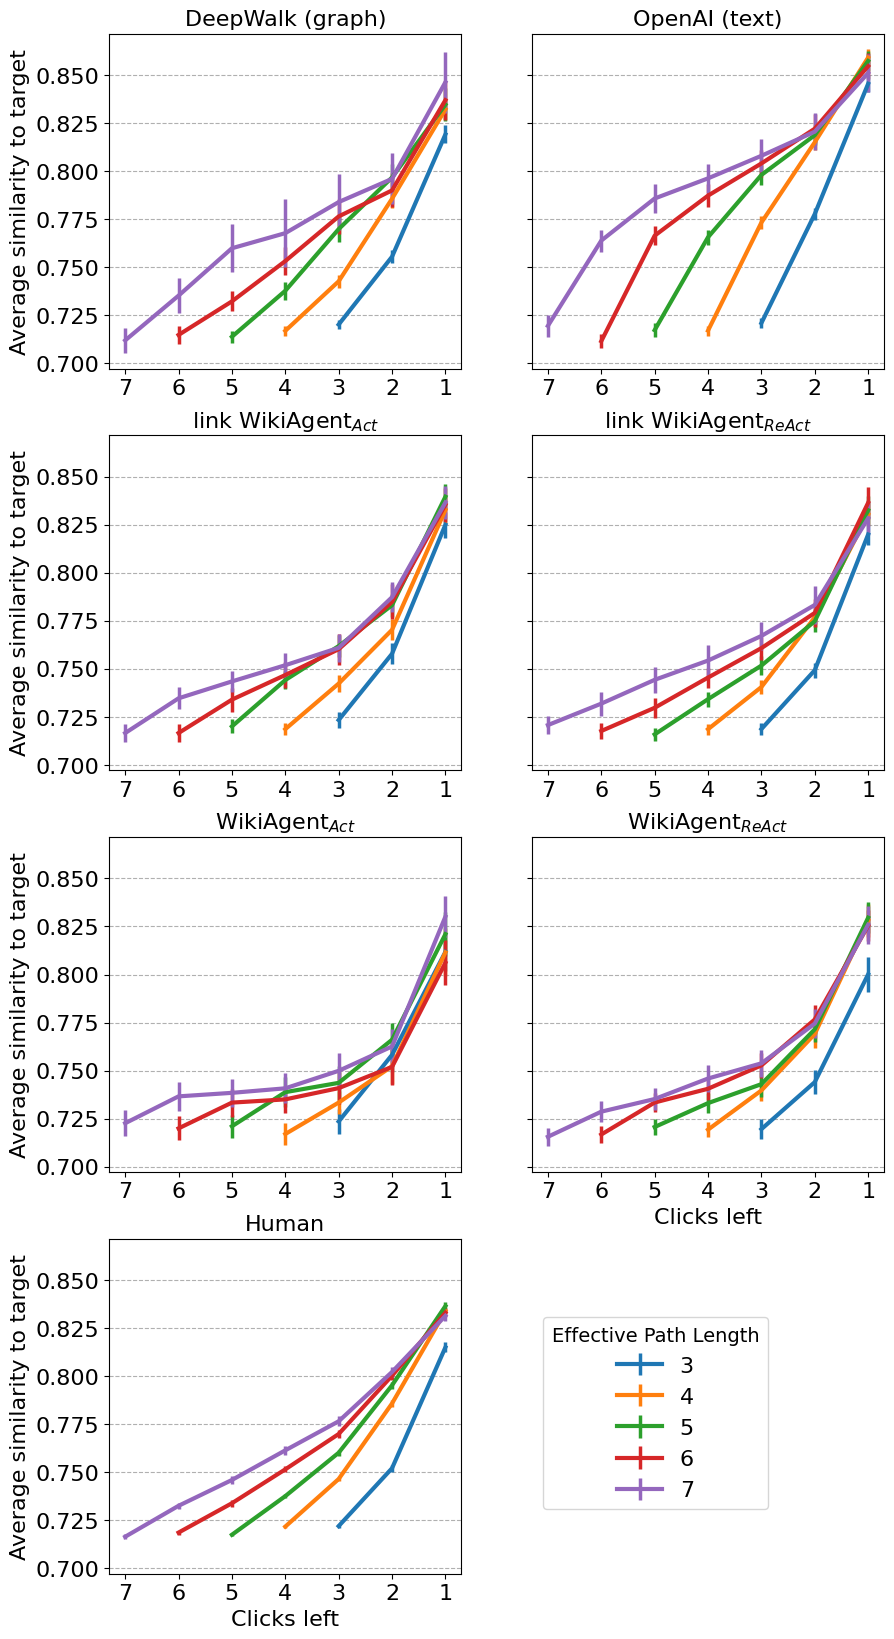

In [14]:
# Visual settings
fontsize=20
markersize=11
markeredgewidth=2.5
linewidth=3


agents = ['link_click/embedding_deepwalk_dfs', 'link_click/embedding_openai_dfs', 'link_click/lmql_dfs_back', 'link_click/lmql_dfs_back_reason', 'navigate/lmql_headings', 'navigate/lmql_headings_reason', 'human']
agents_to_coord = {'link_click/embedding_deepwalk_dfs': (0,0), 'link_click/embedding_openai_dfs': (0,1), 'link_click/lmql_dfs_back': (1,0), 'link_click/lmql_dfs_back_reason': (1,1), 'navigate/lmql_headings': (2,0), 'navigate/lmql_headings_reason': (2,1), 'human': (3,0)}
agents_to_title = {'link_click/lmql_dfs_back': 'link WikiAgent$_{Act}$', 'link_click/lmql_dfs_back_reason': 'link WikiAgent$_{ReAct}$', 'link_click/embedding_deepwalk_dfs': 'DeepWalk (graph)', 'link_click/embedding_openai_dfs': 'OpenAI (text)', 'navigate/lmql_headings': 'WikiAgent$_{Act}$', 'navigate/lmql_headings_reason': 'WikiAgent$_{ReAct}$', 'human': 'Human'}
game_lengths = [3,4,5,6,7]

# make 4x2 plot
fig, axes = plt.subplots(4,2, figsize=(10,20), sharex=False, sharey=True)  # Adjust the figsize as needed
# fix spl to 3
spl = 3
for agent in agents:
    # set active axis
    plt.sca(axes[agents_to_coord[agent][0], agents_to_coord[agent][1]])
    for game_length in game_lengths:
        if agent!='human':
            data = all_runs_df[(all_runs_df['agent.agent_name']==agent)].query("success==1 and spl==@spl and effective_path_len==@game_length")['similarity_progression'].values
        else:
            data = filtered_paths_real_df.query("is_path_finished==1 and spl==@spl and hepl==@game_length")['similarity_progression'].values
        similarity_progressions = [prog.split(";") for prog in data]
        similarity_progressions = np.array([np.array(list(map(float, prog))) for prog in similarity_progressions])
        avg_similarity_progression = np.mean(similarity_progressions, axis=0)
        # use SEM to compute 95% confidence interval
        error_similarity_progression = np.std(similarity_progressions, axis=0)/np.sqrt(similarity_progressions.shape[0])*1.96
        x_array = np.arange(max(game_lengths)-game_length, max(game_lengths))
        plt.errorbar(x_array, avg_similarity_progression, yerr=error_similarity_progression, label=f"{game_length}", linewidth=linewidth, marker='', elinewidth=markeredgewidth)
        plt.title(agents_to_title[agent], fontsize=fontsize-4)
        plt.xticks(range(game_length), [game_length-x for x in range(game_length)], fontsize=fontsize-4)
        plt.yticks(fontsize=fontsize-4)
        plt.grid(axis='y', linestyle='--')
        plt.xlabel('Clicks left', fontsize=fontsize-4) if agent=='human' or agent=='navigate/lmql_headings_reason' else None
        plt.ylabel('Average similarity to target', fontsize=fontsize-4) if agents_to_coord[agent][1]==0 else None

fig.delaxes(axes[3,1])

# xticks are the clicks left to reach the target, that is, game_length - clicks_so_far
plt.legend(fontsize=fontsize-4, title='Effective Path Length', bbox_to_anchor=(1.2, 0.8), loc='upper left')
plt.savefig('plots/similarity_progression.pdf', bbox_inches='tight')



In [28]:
filtered_paths_real_df.query("is_path_finished==1 and src=='Asteroid' and tgt=='Viking'")

,hashed_ip,timestamp,src,tgt,is_path_finished,failure_type,path,hpl,spl,duration_in_sec,...,user_path_rating,effective_path,hepl,shpl,shepl,mhepl,agent_id,overhead_spl,long_path,similarity_progression
7354,35a662d145537c73,1249427342,Asteroid,Viking,1,NaN,Asteroid;Solar_System;Mars;Deity;Mythology;Norse_mythology;Iceland;Viking,7,3,127,...,4.0,Asteroid;Solar_System;Mars;Deity;Mythology;Norse_mythology;Iceland;Viking,7,3.0,3.0,5.0,1248,2.333333,1,0.7324042373100463;0.7248149818885476;0.7381112890523807;0.7580571930151341;0.7612261998951686;0.8576302502292001;0.7996186603648138
7355,30c351e319347c92,1249645488,Asteroid,Viking,1,NaN,Asteroid;Trojan_War;Bronze_Age;Stonehenge;Norfolk;Viking,5,3,173,...,NaN,Asteroid;Trojan_War;Bronze_Age;Stonehenge;Norfolk;Viking,5,3.0,3.0,5.0,1248,1.666667,0,0.7324042373100463;0.7976625194911866;0.7884420857632001;0.7441958976413428;0.7685781917523042
7356,54914f8f4bc66bb0,1299641948,Asteroid,Viking,1,NaN,Asteroid;Earth;Human;Society;United_Kingdom;North_Sea;Netherlands;<;Denmark;Viking,9,3,493,...,2.0,Asteroid;Earth;Human;Society;United_Kingdom;North_Sea;Denmark;Viking,7,3.0,3.0,5.0,1248,2.333333,1,0.7324042373100463;0.7376812613510623;0.7511333833644939;0.7612377159282192;0.7880502594795615;0.7842928057478653;0.8076811361189272
7357,731bd0691807e96f,1299651825,Asteroid,Viking,1,NaN,Asteroid;Jupiter;Ancient_Rome;1st_century_BC;1st_century;4th_century;8th_century;Viking,7,3,160,...,NaN,Asteroid;Jupiter;Ancient_Rome;1st_century_BC;1st_century;4th_century;8th_century;Viking,7,3.0,3.0,5.0,1248,2.333333,1,0.7324042373100463;0.7148644687451478;0.790809732889408;0.7476451514912724;0.751131312058949;0.7572431468797395;0.7886209266893895
7358,7f9ffb9053fec999,1299686309,Asteroid,Viking,1,NaN,Asteroid;3_Juno;Germany;Netherlands;<;Denmark;Viking,6,3,200,...,NaN,Asteroid;3_Juno;Germany;Denmark;Viking,4,3.0,3.0,5.0,1248,1.333333,0,0.7324042373100463;0.7239170524261495;0.7479692580024246;0.8076811361189272
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8392,5849f8dc1eab9f2f,1389621857,Asteroid,Viking,1,NaN,Asteroid;Jupiter;Roman_mythology;Mythology;Norse_mythology;Denmark;Viking,6,3,221,...,NaN,Asteroid;Jupiter;Roman_mythology;Mythology;Norse_mythology;Denmark;Viking,6,3.0,3.0,5.0,1248,2.000000,0,0.7324042373100463;0.7148644687451478;0.780543468684689;0.7612261998951686;0.8576302502292001;0.8076811361189272
8393,5b35782e77227b54,1389638017,Asteroid,Viking,1,NaN,Asteroid;Earth;Dutch_language;Netherlands;France;Franks;<;Charlemagne;6th_century;<;7th_century;8th_century;Viking,12,3,405,...,NaN,Asteroid;Earth;Dutch_language;Netherlands;France;Charlemagne;7th_century;8th_century;Viking,8,3.0,3.0,5.0,1248,2.666667,1,0.7324042373100463;0.7376812613510623;0.7580861942685599;0.7731833462358497;0.7546144288106197;0.7801931749644117;0.7827501973024102;0.7886209266893895
8394,3f166d0a191b66e6,1389686302,Asteroid,Viking,1,NaN,Asteroid;Solar_System;Earth;United_Nations;United_States;Country;Iceland;Viking,7,3,249,...,3.0,Asteroid;Solar_System;Earth;United_Nations;United_States;Country;Iceland;Viking,7,3.0,3.0,5.0,1248,2.333333,1,0.7324042373100463;0.7248149818885476;0.7376812613510623;0.7368071455160686;0.7462202223144522;0.7672222035272965;0.7996186603648138
8395,3f166d0a191b66e6,1389688426,Asteroid,Viking,1,NaN,Asteroid;Carl_Friedrich_Gauss;Germany;Denmark;Viking,4,3,44,...,2.0,Asteroid;Carl_Friedrich_Gauss;Germany;Denmark;Viking,4,3.0,3.0,5.0,1248,1.333333,0,0.7324042373100463;0.7314975443714996;0.7479692580024246;0.8076811361189272


In [26]:
all_runs_df[all_runs_df['agent.agent_name']=='link_click/lmql_dfs_back'].query("is_finished==True and src=='12th_century' and tgt=='Guitar'")[['src', 'tgt', 'effective_path_so_far', 'effective_path_len']]

,src,tgt,effective_path_so_far,effective_path_len
558534,12th_century,Guitar,12th_century;Iran;Music;Musical_instrument,4


## Plot - Average Page Human-ness vs Method

In [58]:
article_links_file = os.path.join(PATH_IN, 'article_links.tsv')
article_links_df = pd.read_csv(article_links_file, sep='\t')
article_links_df['out_degree'] = article_links_df['links'].apply(lambda x: len(x.split(';')))

missing_articles = set(all_runs_df['effective_path_so_far'].str.split(';', expand=True).values.flatten()) - set(article_links_df['article'].values)
missing_articles = [article for article in missing_articles if article != None]

# keep only finished runs without missing articles
# get ilocs of rows with missing
missing_idx = all_runs_df.query("is_finished==True").index[all_runs_df.query("is_finished==True")['effective_path_so_far'].str.split(';', expand=True).isin(missing_articles).any(axis=1)]

all_runs_df = all_runs_df.drop(missing_idx)

# the humanness of a page is 1 if the page is in ANY human effective path with the same target, and 0 otherwise
def get_page_humanness_progression(row, is_finished_col='is_finished', path_col='effective_path_so_far'):
    humanness = []
    if row[is_finished_col]==False:
        return ''
    # human_paths = paths_real_df[paths_real_df['tgt']==row['tgt']][paths_real_df['is_path_finished']==1]['effective_path'].values
    # for exact same src and tgt
    human_paths = paths_real_df[
        (paths_real_df['src']==unquote(row['src'])) &
        (paths_real_df['tgt']==unquote(row['tgt'])) &
        (paths_real_df['is_path_finished']==1)]['effective_path'].values
    for i, article in enumerate(row[path_col].split(';')):
        humanness_value = 0
        for human_path in human_paths:
            if article in human_path.split(';'):
                humanness_value += 1
        humanness.append(humanness_value/ len(human_paths))
    return ';'.join([str(x) for x in humanness])

all_runs_df['humanness_progression'] = all_runs_df.apply(get_page_humanness_progression, axis=1)
# remove first humanness_progression element because it is always 1, since the first page is always the src
all_runs_df['humanness_progression'] = all_runs_df['humanness_progression'].apply(lambda x: ';'.join(x.split(';')[1:]) if x!='' else '')

In [67]:
get_spl("Archaeology", "Ecuador")

3

In [65]:
all_runs_df.query("`agent.agent_name`=='link_click/lmql_dfs_back' and success==1")[['src', 'tgt', 'effective_path_so_far', 'humanness_progression']].head(5)

,src,tgt,effective_path_so_far,humanness_progression
542843,Archaeology,Ecuador,Archaeology;Peru,0.3333333333333333
542848,Postage_stamp,Cheese,Postage_stamp;Switzerland,0.4
542859,Necktie,Lion,Necktie;England,0.3
542867,Banjul,England,Banjul;United_Kingdom,0.5
542871,Internet,Human_rights,Internet;People's_Republic_of_China,0.5


In [66]:
filtered_paths_real_df.query("is_path_finished==1 and src=='Archaeology' and tgt=='Ecuador'")

,hashed_ip,timestamp,src,tgt,is_path_finished,failure_type,path,hpl,spl,duration_in_sec,...,effective_path,hepl,shpl,shepl,mhepl,agent_id,overhead_spl,long_path,out_degree_progression,similarity_progression
691,0e3bb70c598a6520,1261127446,Archaeology,Ecuador,1,NaN,Archaeology;United_States;North_America;South_America;Brazil;Ecuador,5,2,47,...,Archaeology;United_States;North_America;South_America;Brazil;Ecuador,5,2.0,2.0,3.0,1619,2.5,1,43;294;77;99;80,0.7354048283161582;0.8130024117790868;0.8143832449610653;0.8414015740397057;0.8496165247377522
692,080e46323ec75be2,1343892160,Archaeology,Ecuador,1,NaN,Archaeology;United_States;North_America;South_America;Ecuador,4,2,57,...,Archaeology;United_States;North_America;South_America;Ecuador,4,2.0,2.0,3.0,1619,2.0,0,43;294;77;99,0.7354048283161582;0.8130024117790868;0.8143832449610653;0.8414015740397057
693,221fbacf705b37fa,1345045530,Archaeology,Ecuador,1,NaN,Archaeology;North_America;South_America;Ecuador,3,2,49,...,Archaeology;North_America;South_America;Ecuador,3,2.0,2.0,3.0,1619,1.5,0,43;77;99,0.7354048283161582;0.8143832449610653;0.8414015740397057
694,3a960fe56f4c9590,1350825472,Archaeology,Ecuador,1,NaN,Archaeology;Peru;Ecuador,2,2,59,...,Archaeology;Peru;Ecuador,2,2.0,2.0,3.0,1619,1.0,0,43;93,0.7354048283161582;0.9062925324701631
695,675c490b71f72a57,1353024035,Archaeology,Ecuador,1,NaN,Archaeology;Peru;Ecuador,2,2,23,...,Archaeology;Peru;Ecuador,2,2.0,2.0,3.0,1619,1.0,0,43;93,0.7354048283161582;0.9062925324701631
696,66ab67f67b567f06,1353535934,Archaeology,Ecuador,1,NaN,Archaeology;Anthropology;Pacific_Ocean;Ecuador,3,2,47,...,Archaeology;Anthropology;Pacific_Ocean;Ecuador,3,2.0,2.0,3.0,1619,1.5,0,43;42;87,0.7354048283161582;0.7257928163162319;0.8035406356446029


In [34]:
get_page_humanness_progression(all_runs_df.query("is_finished==True").iloc[3])

'1.0;0.0;0.5'

link_click/lmql_dfs_back_reason 0.17508258315243921 0.0062755678132565915
link_click/embedding_deepwalk_dfs 0.16369590934476924 0.006705135427417912
link_click/embedding_openai_dfs 0.15060880448101693 0.005613553559937735
link_click/lmql_dfs_back 0.12377730967925385 0.004437017435114004
navigate/lmql_headings_reason 0.09616895320045077 0.004236121593862333
navigate/lmql_headings 0.059572202768354746 0.003095583324243697


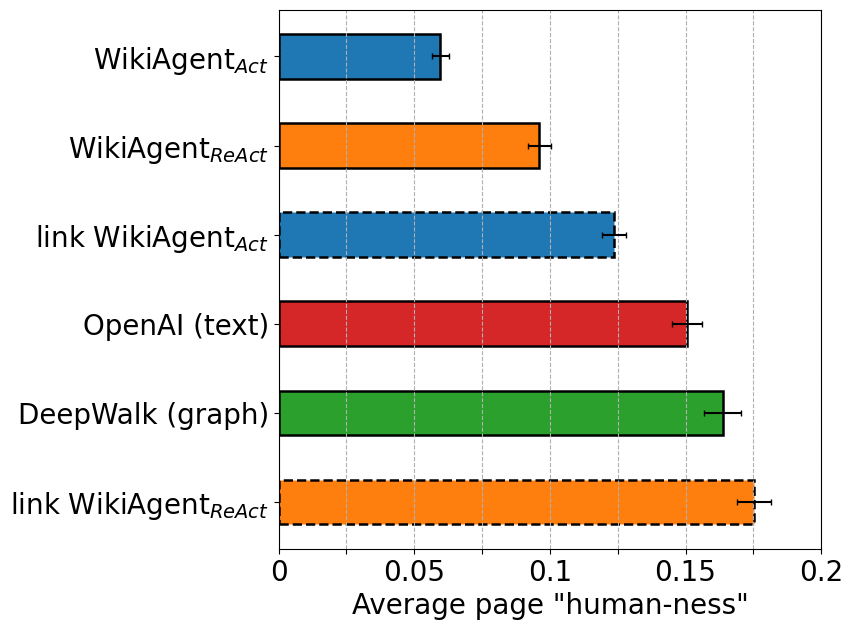

In [64]:
# Visual settings
fontsize=20
markersize=11
markeredgewidth=2.5
linewidth=2.5
barWidth = 0.5

agents = ['navigate/lmql_headings', 'navigate/lmql_headings_reason', 'link_click/lmql_dfs_back', 'link_click/embedding_openai_dfs', 'link_click/embedding_deepwalk_dfs', 'link_click/lmql_dfs_back_reason']
# reverse agents order
agents = agents[::-1]
agents_to_title = {'link_click/lmql_dfs_back': 'link WikiAgent$_{Act}$', 'link_click/lmql_dfs_back_reason': 'link WikiAgent$_{ReAct}$', 'link_click/embedding_deepwalk_dfs': 'DeepWalk (graph)', 'link_click/embedding_openai_dfs': 'OpenAI (text)', 'navigate/lmql_headings': 'WikiAgent$_{Act}$', 'navigate/lmql_headings_reason': 'WikiAgent$_{ReAct}$'}
agents_to_color = {'link_click/lmql_dfs_back': 'tab:blue', 'link_click/lmql_dfs_back_reason': 'tab:orange', 'link_click/embedding_deepwalk_dfs': 'tab:green', 'link_click/embedding_openai_dfs': 'tab:red', 'navigate/lmql_headings': 'tab:blue', 'navigate/lmql_headings_reason': 'tab:orange'}
agents_to_linestyle = {'link_click/lmql_dfs_back': '--', 'link_click/lmql_dfs_back_reason': '--', 'link_click/embedding_deepwalk_dfs': '-', 'link_click/embedding_openai_dfs': '-', 'navigate/lmql_headings': '-', 'navigate/lmql_headings_reason': '-'}


# bar plot with error bars, turned on the side, the bars are sideways, and the agent names are the yticks
plt.figure(figsize=(7,7))
for agent in agents:
    humanness_progressions = all_runs_df[(all_runs_df['agent.agent_name']==agent)].query("success==1")['humanness_progression'].values
    # unroll to list
    humanness_progressions = [prog.split(";") for prog in humanness_progressions]
    # conver to single list
    humanness_list = []
    for prog in humanness_progressions:
        humanness_list.extend(map(float, prog))

    humanness_list=np.array(humanness_list)

    avg_humanness = np.mean(humanness_list)
    error_humanness = np.std(humanness_list)/np.sqrt(len(humanness_list))*1.96
    print(agent, avg_humanness, error_humanness)

    plt.barh(agents_to_title[agent], avg_humanness, xerr=error_humanness, color=agents_to_color[agent], edgecolor='black', height=barWidth, linewidth=linewidth-0.7, linestyle=agents_to_linestyle[agent], capsize=markeredgewidth)
plt.xticks(np.arange(0,0.21, 0.025), [0,'',0.05,'',0.1,'',0.15,'',0.2], fontsize=fontsize)
plt.yticks(fontsize=fontsize)
plt.xlim(0,0.2)
plt.xlabel('Average page "human-ness"', fontsize=fontsize)
plt.grid(axis='x', linestyle='--')
plt.savefig('plots/page_humanness.pdf', bbox_inches='tight')


## Plot - Average Click Rank amongst Humans vs Method

In [4]:
article_links_file = os.path.join(PATH_IN, 'article_links.tsv')
article_links_df = pd.read_csv(article_links_file, sep='\t')
article_links_df['out_degree'] = article_links_df['links'].apply(lambda x: len(x.split(';')))

missing_articles = set(all_runs_df['effective_path_so_far'].str.split(';', expand=True).values.flatten()) - set(article_links_df['article'].values)
missing_articles = [article for article in missing_articles if article != None]

# keep only finished runs without missing articles
# get ilocs of rows with missing
missing_idx = all_runs_df.query("is_finished==True").index[all_runs_df.query("is_finished==True")['effective_path_so_far'].str.split(';', expand=True).isin(missing_articles).any(axis=1)]

all_runs_df = all_runs_df.drop(missing_idx)


In [5]:
# unroll paths: for example, the path Hand;Portugal;Fire;Burn becomes a df with columns (cur,tgt,click) like this [cur=Hand, tgt=Burn, click=Portugal; cur=Portugal, tgt=Burn, click=Fire; cur=Fire, tgt=Burn, click=Burn]
def unroll_paths(row, path_col='effective_path_so_far', agent_name=None):
    paths = []
    if len(row[path_col].split(';'))==1:
        return []
    for i, article in enumerate(row[path_col].split(';')):
        if i==0:
            continue
        row_to_append = [row[path_col].split(';')[i-1], row['tgt'], article]
        if agent_name!=None:
            row_to_append.append(agent_name)
        paths.append(row_to_append)
    return paths

unrolled_human_paths_df = pd.DataFrame()
# data = filtered_paths_real_df.query("is_path_finished==1")
data = paths_real_df.query("is_path_finished==1")
for i in range(data.shape[0]):
    unrolled_human_paths_df = pd.concat([unrolled_human_paths_df, pd.DataFrame(unroll_paths(data.iloc[i], path_col='effective_path'))])

unrolled_human_paths_df.columns = ['cur', 'tgt', 'click']

# remove rows where tgt==click
unrolled_human_paths_df = unrolled_human_paths_df[unrolled_human_paths_df['tgt']!=unrolled_human_paths_df['click']]
# remove rows where cur==tgt
unrolled_human_paths_df = unrolled_human_paths_df[unrolled_human_paths_df['cur']!=unrolled_human_paths_df['tgt']]


# now unroll the agent paths, keep a column with the agent name
agents = ['navigate/lmql_headings', 'navigate/lmql_headings_reason', 'link_click/lmql_dfs_back', 'link_click/embedding_openai_dfs', 'link_click/lmql_dfs_back_reason', 'link_click/embedding_deepwalk_dfs']
unrolled_agent_paths_df = pd.DataFrame()
for agent in agents:
    data = all_runs_df.query("is_finished==True and `agent.agent_name`==@agent")
    for i in range(data.shape[0]):
        unrolled_agent_paths_df = pd.concat([unrolled_agent_paths_df, pd.DataFrame(unroll_paths(data.iloc[i], agent_name=agent))])


unrolled_agent_paths_df.columns = ['cur', 'tgt', 'click', 'agent']


In [6]:
# see cur-tgt pairs that are both in unrolled_human_paths_df and unrolled_agent_paths_df
unrolled_agents_paths_filtered_dfs = {}
agents = ['navigate/lmql_headings', 'navigate/lmql_headings_reason', 'link_click/lmql_dfs_back', 'link_click/embedding_openai_dfs', 'link_click/lmql_dfs_back_reason', 'link_click/embedding_deepwalk_dfs']

for agent in agents:
    data = unrolled_agent_paths_df[unrolled_agent_paths_df['agent']==agent]
    human_agent_pairs = set(zip(unrolled_human_paths_df['cur'], unrolled_human_paths_df['tgt'])) & set(zip(data['cur'], data['tgt']))                                                                                           
    # keep only rows where cur-tgt is in human_agent_pairs
    unrolled_agents_paths_filtered_dfs[agent] = data[data.apply(lambda x: (x['cur'], x['tgt']) in human_agent_pairs, axis=1)].reset_index(drop=True)


In [7]:
human_curtgt_counts = unrolled_human_paths_df.groupby(['cur', 'tgt']).size().reset_index(name='count').sort_values(by='count', ascending=False)
agents_curtgt_counts = {}
for agent in agents:
    agents_curtgt_counts[agent] = unrolled_agents_paths_filtered_dfs[agent].groupby(['cur', 'tgt']).size().reset_index(name='count').sort_values(by='count', ascending=False)

# merge human and agent counts on cur-tgt
agents_curtgt_counts_merged = {}
for agent in agents:
    agents_curtgt_counts_merged[agent] = pd.merge(human_curtgt_counts, agents_curtgt_counts[agent], on=['cur', 'tgt'], how='left').fillna(0)
    # rename columns
    agents_curtgt_counts_merged[agent].columns = ['cur', 'tgt', 'human_count', 'agent_count']

    

In [8]:
unrolled_human_paths_df.groupby(['cur', 'tgt', 'click']).size().reset_index(name='count').sort_values(by='count', ascending=False).query("cur=='Asteroid' and tgt=='Viking'")

,cur,tgt,click,count
12573,Asteroid,Viking,Earth,284
12582,Asteroid,Viking,Trojan_War,125
12576,Asteroid,Viking,Jupiter,123
12580,Asteroid,Viking,Sun,104
12568,Asteroid,Viking,Carl_Friedrich_Gauss,96
12579,Asteroid,Viking,Solar_System,71
12565,Asteroid,Viking,1_Ceres,63
12577,Asteroid,Viking,Mars,33
12572,Asteroid,Viking,Dinosaur,25
12570,Asteroid,Viking,Comet,24


In [56]:
unrolled_human_paths_df.groupby(['cur', 'tgt', 'click']).size().reset_index(name='count').sort_values(by='count', ascending=False).query("cur=='Asteroid' and tgt=='Viking'")['count'].sum()

1043

In [9]:
# compute the human-ness of clicks for every agent
def compute_click_humanness(row):
    cur = unquote(row['cur'])
    tgt = unquote(row['tgt'])
    click = unquote(row['click'])
    # humanness = # times the exact cur-tgt-click triplet appears in human paths / # times the cur-tgt pair appears in human paths
    humanness = unrolled_human_paths_df.query("cur==@cur and tgt==@tgt and click==@click").shape[0] / unrolled_human_paths_df.query("cur==@cur and tgt==@tgt").shape[0]
    return humanness


# number of cur-tgt pairs by each agent, that has a corresponding human cur-tgt pair with more than 5 counts #10 counts
curtgt_pairs_agents = {}
human_count=10
for agent in agents:
    # keep cur-tgt pairs where human_count>=10 and agent_count>=1
    curtgt_pairs_agents[agent] = agents_curtgt_counts_merged[agent].query('human_count>=@human_count and agent_count>=1')[['cur', 'tgt']]
    print(agent, len(curtgt_pairs_agents[agent]))
    # keep only these pairs
    unrolled_agents_paths_filtered_dfs[agent] = unrolled_agents_paths_filtered_dfs[agent].merge(curtgt_pairs_agents[agent], on=['cur', 'tgt'], how='inner')
    # add click_humanness column
    unrolled_agents_paths_filtered_dfs[agent]['click_humanness'] = unrolled_agents_paths_filtered_dfs[agent].apply(compute_click_humanness, axis=1)



navigate/lmql_headings 398
navigate/lmql_headings_reason 415
link_click/lmql_dfs_back 430
link_click/embedding_openai_dfs 360
link_click/lmql_dfs_back_reason 430
link_click/embedding_deepwalk_dfs 319


link_click/embedding_openai_dfs 0.3407326365188606 0.0317338550736921
link_click/lmql_dfs_back_reason 0.3157607278479265 0.02826479695907015
link_click/embedding_deepwalk_dfs 0.291911824276543 0.03380916397191894
navigate/lmql_headings_reason 0.2676117112022891 0.027972638509980323
link_click/lmql_dfs_back 0.24309557373695834 0.02635973366532214
navigate/lmql_headings 0.18254098082542852 0.024774421295526216


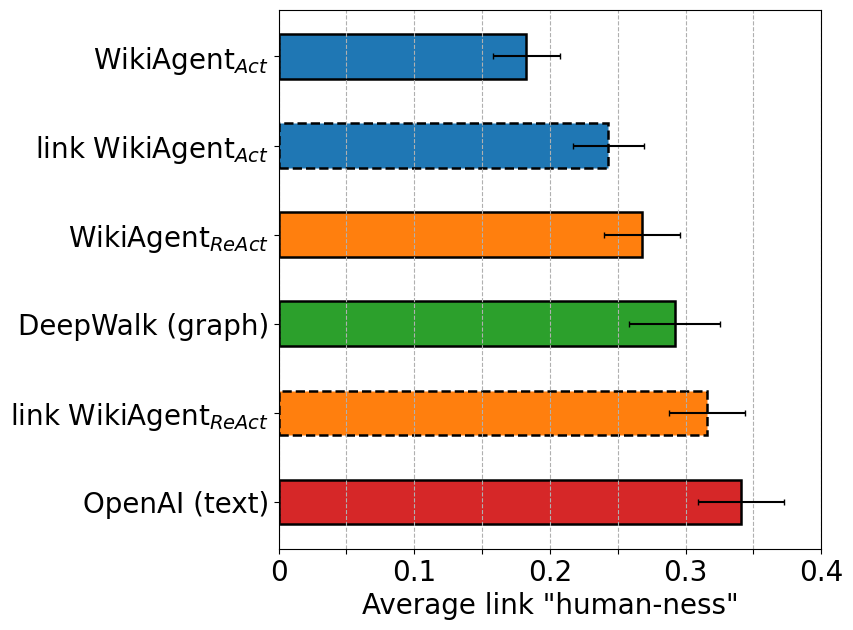

In [10]:
# Visual settings
fontsize=20
markersize=11
markeredgewidth=2.5
linewidth=2.5
barWidth = 0.5

agents = ['navigate/lmql_headings','link_click/lmql_dfs_back', 'navigate/lmql_headings_reason', 'link_click/embedding_deepwalk_dfs',  'link_click/lmql_dfs_back_reason', 'link_click/embedding_openai_dfs']
# reverse agents order
agents = agents[::-1]
agents_to_title = {'link_click/lmql_dfs_back': 'link WikiAgent$_{Act}$', 'link_click/lmql_dfs_back_reason': 'link WikiAgent$_{ReAct}$', 'link_click/embedding_deepwalk_dfs': 'DeepWalk (graph)', 'link_click/embedding_openai_dfs': 'OpenAI (text)', 'navigate/lmql_headings': 'WikiAgent$_{Act}$', 'navigate/lmql_headings_reason': 'WikiAgent$_{ReAct}$'}
agents_to_color = {'link_click/lmql_dfs_back': 'tab:blue', 'link_click/lmql_dfs_back_reason': 'tab:orange', 'link_click/embedding_deepwalk_dfs': 'tab:green', 'link_click/embedding_openai_dfs': 'tab:red', 'navigate/lmql_headings': 'tab:blue', 'navigate/lmql_headings_reason': 'tab:orange'}
agents_to_linestyle = {'link_click/lmql_dfs_back': '--', 'link_click/lmql_dfs_back_reason': '--', 'link_click/embedding_deepwalk_dfs': '-', 'link_click/embedding_openai_dfs': '-', 'navigate/lmql_headings': '-', 'navigate/lmql_headings_reason': '-'}

# horizontal bar plot with error bars, the bars are sideways, and the agent names are the yticks
plt.figure(figsize=(7,7))
for agent in agents:
    avg_click_humanness = unrolled_agents_paths_filtered_dfs[agent]['click_humanness'].mean()
    error_click_humanness = unrolled_agents_paths_filtered_dfs[agent]['click_humanness'].std()/np.sqrt(unrolled_agents_paths_filtered_dfs[agent].shape[0])*1.96
    print(agent, avg_click_humanness, error_click_humanness)
    plt.barh(agents_to_title[agent], avg_click_humanness, xerr=error_click_humanness, color=agents_to_color[agent], edgecolor='black', height=barWidth, linewidth=linewidth-0.7, linestyle=agents_to_linestyle[agent], capsize=markeredgewidth)
plt.xticks(np.arange(0,0.5,0.05), [0, '', 0.1, '', 0.2, '', 0.3, '', 0.4, ''],fontsize=fontsize)
plt.xlim(0,0.4)
plt.yticks(fontsize=fontsize)
plt.xlabel('Average link "human-ness"', fontsize=fontsize)
plt.grid(axis='x', linestyle='--')
# plt.savefig('plots/link_humanness.pdf', bbox_inches='tight')

In [18]:
unrolled_human_paths_df.query("cur=='Asteroid' and tgt=='Viking'").groupby(['cur', 'tgt', 'click']).size().reset_index(name='count').sort_values(by='count', ascending=False)

,cur,tgt,click,count
8,Asteroid,Viking,Earth,284
17,Asteroid,Viking,Trojan_War,125
11,Asteroid,Viking,Jupiter,123
15,Asteroid,Viking,Sun,104
3,Asteroid,Viking,Carl_Friedrich_Gauss,96
14,Asteroid,Viking,Solar_System,71
0,Asteroid,Viking,1_Ceres,63
12,Asteroid,Viking,Mars,33
7,Asteroid,Viking,Dinosaur,25
5,Asteroid,Viking,Comet,24


In [21]:
compute_click_humanness(unrolled_human_paths_df.query("cur=='Asteroid' and tgt=='Viking'").groupby(['cur', 'tgt', 'click']).size().reset_index(name='count').sort_values(by='count', ascending=False).iloc[1])

0.11984659635666348

In [1]:
# see most frequent clicks for each cur-tgt pair, along with the count
unrolled_human_paths_df.groupby(['cur', 'tgt', 'click']).size().reset_index(name='count').sort_values(by='count', ascending=False)

NameError: name 'unrolled_human_paths_df' is not defined

In [20]:
unrolled_agents_paths_filtered_dfs['link_click/lmql_dfs_back'].groupby(['cur', 'tgt']).agg({'click': ['value_counts']}).reset_index().sort_values(by=('click', 'value_counts'), ascending=False)

cur                             tgt                click  \
                                                                             
2607         Internet                          Google      Tim_Berners-Lee   
1114            China                          Google         Architecture   
479         Astronomy                           Pluto               Planet   
4588  Tim_Berners-Lee                          Google       World_Wide_Web   
1304         Computer                          Google             Internet   
...               ...                             ...                  ...   
1822           Europe                         Hungary      Go_(board_game)   
1821           Europe                         Hungary  Great_Wall_of_China   
1820           Europe                         Hungary          Jaws_(film)   
1818           Europe  History_of_Anglo-Saxon_England          Anglicanism   
5208    Zinc_chloride            Age_of_Enlightenment       Phase_(matter)   

                   
     value_counts  
2607           10  
1114            9  
479             8  
4588            8  
1304            8  
...           ...  
1822            1  
1821            1  
1820            1  
1818            1  
5208            1  

[5209 rows x 4 columns]

# Web Conference Analysis 

## React/Act Unconst/Const WikiAgent Success Rate
Bar plot: 
- y-axis is the success rate
- each x-tick is a model name

In [5]:

# Specify the paths to the folders containing the runs
folders = []

# Mistral constrained
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_0/2023-12-22_18-08-48/*/"))] 
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_1/2023-12-22_18-19-44/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_2/2023-12-24_12-04-12/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_3/2023-12-24_12-06-35/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_4/2023-12-24_13-19-13/*/"))]

# Mistral unconstrained
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_unc_mistral_0/2024-01-22_20-06-35/*/"))] 
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_unc_mistral_1/2024-01-23_11-01-04/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_unc_mistral_2/2024-01-25_15-25-02/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_unc_mistral_3/2024-01-23_11-01-04/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_unc_mistral_4/2024-01-23_11-01-04/*/"))]

# GPT-3.5
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_unc_gpt3.5/2024-01-23_21-04-42/*/"))]

# GPT-4 (100 games)
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_unc_gpt4/2024-01-25_11-46-34/*/"))]

identifiers = ['model.model_name','agent.agent_name']

all_runs_df = get_all_runs_df(folders, identifiers)


print(all_runs_df.columns)

{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings_reason', 'run_id': '1'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings_reason', 'run_id': '1'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings_reason', 'run_id': '1'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings_reason', 'run_id': '1'}
{'model.mode

In [4]:
all_runs_df['prompting'].unique()

array(['ReAct_navigate_unconstrained', 'Act_navigate_unconstrained',
       'ReAct_navigate', 'Act_navigate'], dtype=object)

In [7]:
# Overhead factor and long path rates
overhead_df = all_runs_df.query("success==1").groupby(['model.model_name', 'prompting']).agg({'overhead_spl':['median', 'mean'], 'long_path': ['mean', 'sem']}).reset_index()
overhead_df['long_path_error'] = overhead_df['long_path']['sem']*1.96

overhead_df

model.model_name                     prompting  \
                                                                      
0                  gpt-3.5-turbo-1106    Act_navigate_unconstrained   
1                  gpt-3.5-turbo-1106  ReAct_navigate_unconstrained   
2                  gpt-4-1106-preview    Act_navigate_unconstrained   
3                  gpt-4-1106-preview  ReAct_navigate_unconstrained   
4  mistralai/Mistral-7B-Instruct-v0.2                  Act_navigate   
5  mistralai/Mistral-7B-Instruct-v0.2    Act_navigate_unconstrained   
6  mistralai/Mistral-7B-Instruct-v0.2                ReAct_navigate   
7  mistralai/Mistral-7B-Instruct-v0.2  ReAct_navigate_unconstrained   

  overhead_spl           long_path           long_path_error  
        median      mean      mean       sem                  
0     4.000000  4.971939  0.708163  0.020558        0.040294  
1     3.000000  4.320290  0.663880  0.019333        0.037893  
2     2.333333  3.460714  0.571429  0.059576        0.116768  
3     2.000000  2.962835  0.459770  0.053742        0.105334  
4     3.500000  4.650528  0.677840  0.020184        0.039562  
5     1.000000  1.282051  0.057692  0.032649        0.063992  
6     2.333333  3.005735  0.522694  0.019126        0.037487  
7     1.000000  1.316964  0.053571  0.030362        0.059509

In [8]:
# Data for humans
# get unique src-tgt pairs from all_runs_df[all_runs_df['model.model_name']=='gpt-3.5-turbo-1106'] aka all 1000 pairs
unique_pairs = all_runs_df[all_runs_df['model.model_name']=='gpt-3.5-turbo-1106'][['src', 'tgt']].drop_duplicates().reset_index(drop=True)

# in paths_real_df, keep only rows with those src-tgt pairs
paths_real_df_filtered = paths_real_df[paths_real_df.apply(lambda x: (x['src'], x['tgt']) in zip(unique_pairs['src'], unique_pairs['tgt']), axis=1)].reset_index(drop=True)


In [9]:
human_success_rate = paths_real_df_filtered['is_path_finished'].mean()
print("Human success rate:", human_success_rate)

Human success rate: 0.6829268292682927


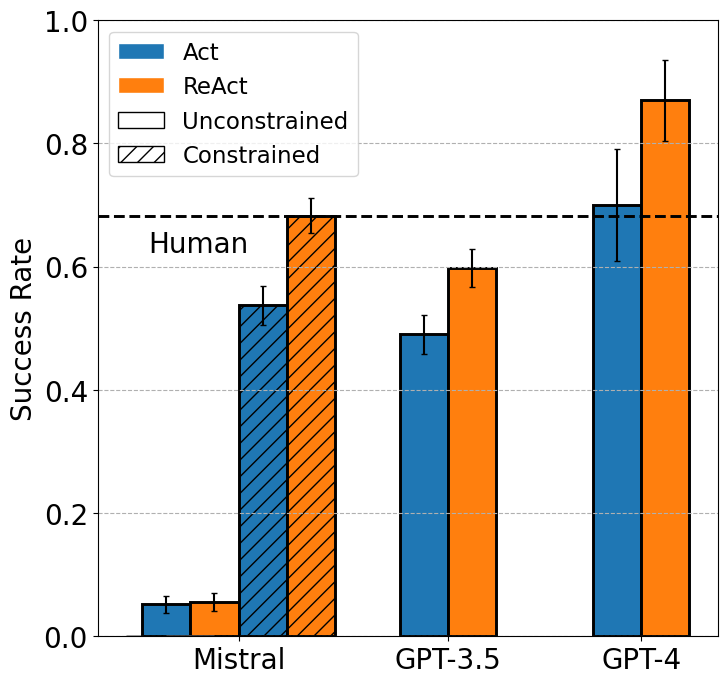

In [10]:
success_df = all_runs_df.query("is_finished==True").groupby(['model.model_name', 'agent.agent_name', 'prompting']).agg({'success':'mean'}).reset_index()
success_df['error'] = 1.96*all_runs_df.query("is_finished==True").groupby(['model.model_name', 'agent.agent_name', 'prompting']).agg({'success':'sem'}).reset_index()['success']

models = ['mistralai/Mistral-7B-Instruct-v0.2', 'gpt-3.5-turbo-1106', 'gpt-4-1106-preview']
model_names = ['Mistral', 'GPT-3.5', 'GPT-4']
prompting_types = success_df['prompting'].unique()
fontsize=20
markeredgewidth=2.5
linewidth=2.1


# Initialize the matplotlib figure
plt.figure(figsize=(8,8))

# Width of a bar
barWidth = 0.3

# Set positions of the bars on x-axis
positions = np.array([0,1.3,2.5])

# Each model is an x-tick with a bar for each prompting type
for i, model in enumerate(models):
    extra = barWidth/2 if "gpt" in model else -barWidth/2

    for j, prompting_type in enumerate(prompting_types):
        if 'ReAct' in prompting_type:
            color = 'tab:orange'
        else:
            color = 'tab:blue'
        if 'unconstrained' in prompting_type:
            hatch = ''
        else:
            hatch = '//'
        success_rate = success_df.query("`model.model_name`==@model and prompting==@prompting_type")['success'].values
        error = success_df.query("`model.model_name`==@model and prompting==@prompting_type")['error'].values
        if len(success_rate)==0:
            continue

        plt.bar(positions[i] + barWidth*j + extra, success_rate, yerr=error, color=color, edgecolor='black', width=barWidth, hatch=hatch, linewidth=linewidth, capsize=markeredgewidth)

# plot straight line with human success rate and the Text "Human" above the line
plt.axhline(y=human_success_rate, color='black', linestyle='--', linewidth=linewidth)
plt.text(0.05, human_success_rate-0.06, 'Human', fontsize=fontsize, color='black', horizontalalignment='center')

# create invisible bars for the legend
plt.bar(0,0, color='tab:blue', edgecolor='white', width=barWidth, label='Act')
plt.bar(0,0, color='tab:orange', edgecolor='white', width=barWidth, label='ReAct')
plt.bar(0,0, color='white', hatch='', fill=False,edgecolor='black', label='Unconstrained')
plt.bar(0.001,0.001, color='white', hatch='//', fill=False, edgecolor='black', label='Constrained')

# Add features to the plot
# plt.xlabel('Model', fontsize=fontsize)
plt.ylabel('Success Rate', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.ylim(0,1)
plt.yticks(fontsize=fontsize)
plt.xticks(positions + barWidth, model_names, fontsize=fontsize)
plt.legend(title_fontsize=fontsize, loc='upper left', fontsize=fontsize-3.5)

plt.savefig('plots/WWW_success_rate.pdf', bbox_inches='tight')
plt.show()


In [28]:
success_df

,model.model_name,agent.agent_name,prompting,success,error
0,gpt-3.5-turbo-1106,navigate/gpt_headings,Act_navigate_unconstrained,0.49000,0.031000
1,gpt-3.5-turbo-1106,navigate/gpt_headings_reason,ReAct_navigate_unconstrained,0.59800,0.030404
2,gpt-4-1106-preview,navigate/gpt_headings,Act_navigate_unconstrained,0.70000,0.090271
3,gpt-4-1106-preview,navigate/gpt_headings_reason,ReAct_navigate_unconstrained,0.87000,0.066248
4,mistralai/Mistral-7B-Instruct-v0.2,navigate/headings,Act_navigate_unconstrained,0.05125,0.015290
5,mistralai/Mistral-7B-Instruct-v0.2,navigate/headings_reason,ReAct_navigate_unconstrained,0.05000,0.015112
6,mistralai/Mistral-7B-Instruct-v0.2,navigate/lmql_headings,Act_navigate,0.53700,0.030921
7,mistralai/Mistral-7B-Instruct-v0.2,navigate/lmql_headings_reason,ReAct_navigate,0.68300,0.028854


In [27]:
all_runs_df.query("is_finished==True and agent_id<=99").groupby(['model.model_name', 'agent.agent_name', 'prompting']).agg({'success':'mean'}).reset_index()

,model.model_name,agent.agent_name,prompting,success
0,gpt-3.5-turbo-1106,navigate/gpt_headings,Act_navigate_unconstrained,0.64
1,gpt-3.5-turbo-1106,navigate/gpt_headings_reason,ReAct_navigate_unconstrained,0.68
2,gpt-4-1106-preview,navigate/gpt_headings,Act_navigate_unconstrained,0.70
3,gpt-4-1106-preview,navigate/gpt_headings_reason,ReAct_navigate_unconstrained,0.87
4,mistralai/Mistral-7B-Instruct-v0.2,navigate/headings,Act_navigate_unconstrained,0.07
5,mistralai/Mistral-7B-Instruct-v0.2,navigate/headings_reason,ReAct_navigate_unconstrained,0.03
6,mistralai/Mistral-7B-Instruct-v0.2,navigate/lmql_headings,Act_navigate,0.59
7,mistralai/Mistral-7B-Instruct-v0.2,navigate/lmql_headings_reason,ReAct_navigate,0.73


## Action statistics


In [6]:
all_runs_df['extracted_action'] = all_runs_df['action'].apply(lambda x: eval(x)['next_action'] if x.startswith('{') else x)

# all_runs_df['extracted_action'].value_counts().to_csv("actions.csv")


In [7]:
# the 'action' column are strings of the form "{...., 'next_action': 'scroll_down', ...}"". We want to extract the 'next_action' value after evaluating the str as a dict, and do a value_counts on it
all_runs_df['extracted_action'] = all_runs_df['action'].apply(lambda x: eval(x)['next_action'] if x.startswith('{') else "error")

models = ['mistralai/Mistral-7B-Instruct-v0.2', 'gpt-3.5-turbo-1106', 'gpt-4-1106-preview']
model_names = ['Mistral (1000 games)', 'GPT-3.5 (1000 games)', 'GPT-4 (100 games)']
actions=['scroll_down', 'jump_to', 'click', 'back', 'error']
prompting_types = all_runs_df['prompting'].unique()


for i,model in enumerate(models):
    print(f" ** Model = {model_names[i]} **")
    for prompting_type in prompting_types:
        print(f"\t* Prompting = {prompting_type.replace('_navigate', '')} *")
        value_counts = all_runs_df.query("`model.model_name`==@model and prompting==@prompting_type")['extracted_action'].value_counts().to_dict()
        if len(value_counts)==0:
            continue
        total = sum(value_counts.values())
        print(f"\tTotal actions: {total}")
        for action in actions:
            print(f"\t{action}: {value_counts[action]/total*100:.2f}%")
        print()

 ** Model = Mistral (1000 games) **
	* Prompting = ReAct_unconstrained *
	Total actions: 8025
	scroll_down: 39.83%
	jump_to: 4.88%
	click: 8.93%
	back: 1.50%
	error: 44.86%

	* Prompting = Act_unconstrained *
	Total actions: 61086
	scroll_down: 90.13%
	jump_to: 0.53%
	click: 1.72%
	back: 0.35%
	error: 7.27%

	* Prompting = ReAct *
	Total actions: 77080
	scroll_down: 55.67%
	jump_to: 15.54%
	click: 21.60%
	back: 6.62%
	error: 0.56%

	* Prompting = Act *
	Total actions: 238592
	scroll_down: 85.33%
	jump_to: 2.23%
	click: 10.36%
	back: 1.88%
	error: 0.20%

 ** Model = GPT-3.5 (1000 games) **
	* Prompting = ReAct_unconstrained *
	Total actions: 22998
	scroll_down: 7.58%
	jump_to: 1.01%
	click: 82.64%
	back: 0.38%
	error: 8.38%

	* Prompting = Act_unconstrained *
	Total actions: 26602
	scroll_down: 5.75%
	jump_to: 0.05%
	click: 80.00%
	back: 0.80%
	error: 13.40%

	* Prompting = ReAct *
	* Prompting = Act *
 ** Model = GPT-4 (100 games) **
	* Prompting = ReAct_unconstrained *
	Total actions:

## Click Ranking Analysis
Use hits@k metric to evaluate the ranking of the most common human page in the candidate list.

In [4]:
# Specify the paths to the folders containing the runs
folders = []

# Mistral constrained
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/click_mistral_0/2024-01-27_17-41-45/*/"))] 
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/click_mistral_1/2024-01-27_18-14-12/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/click_mistral_2/2024-01-27_18-14-21/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/click_mistral_3/2024-01-27_18-14-59/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/click_mistral_4/2024-01-27_18-14-59/*/"))]

# GPT-3.5
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/click_gpt_0/2024-01-28_17-46-01/*/"))] 
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/click_gpt_1/2024-01-28_18-22-51/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/click_gpt_2/2024-01-28_19-56-53/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/click_gpt_3/2024-01-28_21-16-36/*/"))]
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/click_gpt_4/2024-01-28_22-09-14/*/"))]

identifiers = ['model.model_name','agent.agent_name']
all_runs_df = get_all_runs_df(folders, identifiers)

# extract click from action
def extract_click(action):
    action_dict = eval(action) if action.startswith('{') else "error"
    if 'next_page' in action_dict:
        # for embeddings agents
        return action_dict['next_page']
    
    elif action_dict=='error' or action_dict['next_action']!='click':
        return None
    
    else:
        return action_dict['link']

all_runs_df['click'] = all_runs_df['action'].apply(lambda x: extract_click(x))

agent_clicks_df = all_runs_df.groupby(['agent.agent_name','src','tgt']).agg({'click': ['value_counts']}).reset_index()
agent_clicks_df.columns = ['agent.agent_name', 'src', 'tgt', 'click', 'count']

print(agent_clicks_df.columns)

{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings_reason', 'run_id': '1'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings_reason', 'run_id': '1'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings_reason', 'run_id': '1'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'navigate/lmql_headings_reason', 'run_id': '1'}
{'model.mode

In [5]:
# embeddings
folders = []
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/click_deepwalk_embeddings/2024-01-31_14-10-40/*/"))] 
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/click_openai_embeddings/2024-01-31_14-06-50/*/"))] 

identifiers = ['model.model_name','agent.agent_name']

embedding_runs_df = get_all_runs_df(folders, identifiers)

embedding_clicks_df = pd.DataFrame()
for row in embedding_runs_df.iterrows():
    row = row[1]
    action_dict = eval(row['response'])
    similarities = action_dict['similarities']
    links = action_dict['links']

    #create df with columns (src, tgt, click, similarity)
    df = pd.DataFrame()
    df['agent.agent_name'] = [row['agent.agent_name']]*len(links)
    df['src'] = [row['src']]*len(links)
    df['tgt'] = [row['tgt']]*len(links)
    df['click'] = links
    df['similarity'] = similarities
    embedding_clicks_df = pd.concat([embedding_clicks_df, df])

embedding_clicks_df = embedding_clicks_df.reset_index(drop=True)
# rename similarity to count
embedding_clicks_df['count'] = embedding_clicks_df['similarity']
embedding_clicks_df = embedding_clicks_df.drop('similarity', axis=1)

# concatenate with agent_clicks_df
agent_clicks_df = pd.concat([agent_clicks_df, embedding_clicks_df])

agent_clicks_df.head(5) 

{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/embedding_deepwalk_dfs', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.agent_name': 'link_click/embedding_openai_dfs', 'run_id': '0'}


,agent.agent_name,src,tgt,click,count
0,navigate/gpt_headings,Africa,Zebra,North_Africa,457.0
1,navigate/gpt_headings,Agriculture,Bean,Food,288.0
2,navigate/gpt_headings,Ancient_Egypt,Bean,Civilization,79.0
3,navigate/gpt_headings,Ancient_Egypt,Bean,Writing,20.0
4,navigate/gpt_headings,Ancient_Egypt,Bean,Literature,4.0


In [6]:
# We "unroll" the effective human paths into each click 
article_links_file = os.path.join(PATH_IN, 'article_links.tsv')
article_links_df = pd.read_csv(article_links_file, sep='\t')

# unroll paths: for example, the path Hand;Portugal;Fire;Burn becomes a df with columns (cur,tgt,click) like this [cur=Hand, tgt=Burn, click=Portugal; cur=Portugal, tgt=Burn, click=Fire; cur=Fire, tgt=Burn, click=Burn]
def unroll_paths(row, path_col='effective_path_so_far', agent_name=None):
    paths = []
    if len(row[path_col].split(';'))==1:
        return []
    for i, article in enumerate(row[path_col].split(';')):
        if i==0:
            continue
        row_to_append = [row['src'], row[path_col].split(';')[i-1], row['tgt'], article]
        if agent_name!=None:
            row_to_append.append(agent_name)
        paths.append(row_to_append)
    return paths

unrolled_human_paths_df = pd.DataFrame()
# data = filtered_paths_real_df.query("is_path_finished==1")
data = paths_real_df.query("is_path_finished==1")
for i in range(data.shape[0]):
    unrolled_human_paths_df = pd.concat([unrolled_human_paths_df, pd.DataFrame(unroll_paths(data.iloc[i], path_col='effective_path'))])

unrolled_human_paths_df.columns = ['src', 'cur', 'tgt', 'click']

# remove rows where tgt is in the list of links of cur
unrolled_human_paths_df = unrolled_human_paths_df[unrolled_human_paths_df.apply(lambda x: x['tgt'] not in article_links_df[article_links_df['article']==x['cur']]['links'].values[0].split(';'), axis=1)]
# remove rows where cur==tgt
unrolled_human_paths_df = unrolled_human_paths_df[unrolled_human_paths_df['cur']!=unrolled_human_paths_df['tgt']]

In [7]:
# Get the top 30 most clicked links, RUN ONLY ONCE
cur_tgt_df = unrolled_human_paths_df.groupby(['cur', 'tgt']).size().reset_index(name='count').query('count>=50').sort_values(by='count', ascending=False).head(30)

# change 'cur' to src
cur_tgt_df['src'] = cur_tgt_df['cur']
cur_tgt_df['shepl'] = 0
cur_tgt_df['shpl'] = 0

#for the embeddings agents, we dont need to repeat the rows, we just need to add the shepl and shpl columns
# cur_tgt_df.to_csv(PATH_IN+'top30_cur_tgt.tsv', index=False, sep='\t')

# # the df has columns cur, tgt, count. I want to turn the df into a new one with only cur,tgt and each cur,tgt has as many repeated rows as the count value
# cur_tgt_df = cur_tgt_df.loc[cur_tgt_df.index.repeat(cur_tgt_df['count'])].reset_index(drop=True)



# cur_tgt_df.drop(['cur', 'count'], axis=1, inplace=True)
# # there are 7583 rows in the df
# # save this in 5 files with these number of rows: 1500, 1500, 1500, 1500, 1583
# cur_tgt_df.iloc[:1500].to_csv(PATH_IN+'top30_cur_tgt_0.tsv', index=False, sep='\t')
# cur_tgt_df.iloc[1500:3000].to_csv(PATH_IN+'top30_cur_tgt_1.tsv', index=False, sep='\t')
# cur_tgt_df.iloc[3000:4500].to_csv(PATH_IN+'top30_cur_tgt_2.tsv', index=False, sep='\t')
# cur_tgt_df.iloc[4500:6000].to_csv(PATH_IN+'top30_cur_tgt_3.tsv', index=False, sep='\t')
# cur_tgt_df.iloc[6000:].to_csv(PATH_IN+'top30_cur_tgt_4.tsv', index=False, sep='\t')




In [8]:
# show most common click for each the top 30 cur-tgt most common pairs
cur_tgt_pairs = cur_tgt_df[['cur', 'tgt']].values

cur_tgt_df['top_click'] = cur_tgt_df.apply(lambda x: unrolled_human_paths_df.query("cur==@x['cur'] and tgt==@x['tgt']").groupby(['cur', 'tgt', 'click']).size().reset_index(name='count').sort_values(by='count', ascending=False).iloc[0]['click'], axis=1)
cur_tgt_df 

,cur,tgt,count,src,shepl,shpl,top_click
9453,Asteroid,Viking,1043,Asteroid,0,0,Earth
100915,Theatre,Zebra,907,Theatre,0,0,India
84944,Pyramid,Bean,642,Pyramid,0,0,Mexico
3205,Africa,Zebra,457,Africa,0,0,Lion
32015,Earth,Viking,383,Earth,0,0,Europe
39210,Europe,Viking,324,Europe,0,0,Norway
3488,Agriculture,Bean,288,Agriculture,0,0,Soybean
6907,Animal,Zebra,284,Animal,0,0,Mammal
54836,India,Zebra,212,India,0,0,Mammal
81971,Plant,Bean,211,Plant,0,0,Seed


### Hits@k

Model = GPT-3.5, Prompting = Act, Hits@1 = 0.167
Model = GPT-3.5, Prompting = ReAct, Hits@1 = 0.133
Model = Mistral, Prompting = Act, Hits@1 = 0.133
Model = Mistral, Prompting = ReAct, Hits@1 = 0.333
Model = Graph embed., Prompting = Embeddings, Hits@1 = 0.333
Model = Text embed., Prompting = Embeddings, Hits@1 = 0.300
Model = GPT-3.5, Prompting = Act, Hits@5 = 0.167
Model = GPT-3.5, Prompting = ReAct, Hits@5 = 0.200
Model = Mistral, Prompting = Act, Hits@5 = 0.200
Model = Mistral, Prompting = ReAct, Hits@5 = 0.433
Model = Graph embed., Prompting = Embeddings, Hits@5 = 0.833
Model = Text embed., Prompting = Embeddings, Hits@5 = 0.833


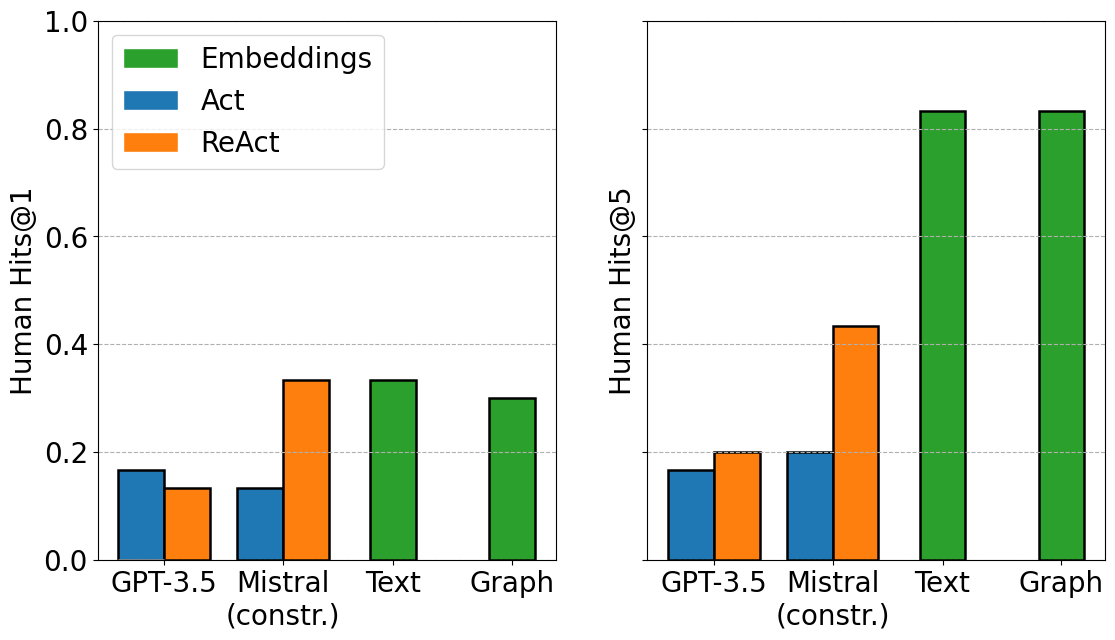

In [19]:
# Bar plot with hits_at_k_results_df, each bar is an agent

## Compute hits at k ##

def compute_hits_at_k_results_df(k):
    hits_at_k_df = pd.DataFrame()

    for i in range(cur_tgt_df.shape[0]):
        for agent in agent_clicks_df['agent.agent_name'].unique():
            cur = cur_tgt_df.iloc[i]['cur']
            tgt = cur_tgt_df.iloc[i]['tgt']
            top_human_click = cur_tgt_df.iloc[i]['top_click']
            agent_clicks = agent_clicks_df.query("`agent.agent_name`==@agent and src==@cur and tgt==@tgt")
            top_k_agent_clicks = agent_clicks.sort_values(by='count', ascending=False).head(k)['click'].values
            if top_human_click in top_k_agent_clicks:
                hit = 1
            else:
                hit = 0
            hits_at_k_df = pd.concat([hits_at_k_df, pd.DataFrame({'agent.agent_name': agent, 'src': cur, 'tgt': tgt, 'top_human_click': top_human_click, 'k_top_clicks': ';'.join(top_k_agent_clicks), 'hit': hit, 'k':k}, index=[0])])
            # hits_at_k_df.append({'agent.agent_name': agent, 'src': cur, 'tgt': tgt, 'top_human_click': top_human_click, 'k_top_clicks': ';'.join(top_k_agent_clicks), 'hit': hit, 'k':k}, ignore_index=True)

    hits_at_k_df['hits_at_k'] = hits_at_k_df.groupby(['agent.agent_name', 'k']).agg({'hit': ['mean']}).reset_index()['hit']
    hits_at_k_df['hits_at_k_error'] = hits_at_k_df.groupby(['agent.agent_name', 'k']).agg({'hit': ['sem']}).reset_index()['hit']['sem']*1.96

    hits_at_k_results_df = pd.DataFrame(columns=['agent.agent_name', 'k', 'hits_at_k', 'hits_at_k_error'])
    for agent in hits_at_k_df['agent.agent_name'].unique():
        for k in hits_at_k_df['k'].unique():
            hits_at_k = hits_at_k_df.query("`agent.agent_name`==@agent and k==@k").agg({'hit': ['mean']}).reset_index()['hit'].values[0]
            hits_at_k_error = hits_at_k_df.query("`agent.agent_name`==@agent and k==@k").agg({'hit': ['sem']}).reset_index()['hit'].values[0]*1.96
            row = {'agent.agent_name': agent, 'k': k, 'hits_at_k': hits_at_k, 'hits_at_k_error': hits_at_k_error}
            hits_at_k_results_df = pd.concat([hits_at_k_results_df, pd.DataFrame(row, index=[0])])
    return hits_at_k_results_df

hits_at_1_results_df = compute_hits_at_k_results_df(1)
hits_at_5_results_df = compute_hits_at_k_results_df(5)

fontsize=20
markersize=11
markeredgewidth=2.5
linewidth=2.5
barWidth = 0.5


agents = ['navigate/gpt_headings', 'navigate/gpt_headings_reason', 'navigate/lmql_headings', 'navigate/lmql_headings_reason', 'link_click/embedding_deepwalk_dfs', 'link_click/embedding_openai_dfs']
agents_to_prompting_model = {'navigate/gpt_headings': {"model": "GPT-3.5", "prompting": "Act"}, 'navigate/gpt_headings_reason': {"model": "GPT-3.5", "prompting": "ReAct"}, 'navigate/lmql_headings': {"model": "Mistral", "prompting": "Act"}, 'navigate/lmql_headings_reason': {"model": "Mistral", "prompting": "ReAct"},
                             'link_click/embedding_deepwalk_dfs': {"model": "Graph embed.", "prompting": "Embeddings"}, 'link_click/embedding_openai_dfs': {"model": "Text embed.", "prompting": "Embeddings"}}
prompt_to_color = {'Act': 'tab:blue', 'ReAct': 'tab:orange', 'Embeddings': 'tab:green'}
model_id = {'GPT-3.5': 0, 'Mistral': 1, 'Graph embed.': 2, 'Text embed.': 3}
positions = np.array([0,1.3, 2.5, 3.8])

# 2 bar plots, one for hits@1 and one for hits@5
fig, ax = plt.subplots(figsize=(13,7), nrows=1, ncols=2, sharey=True)

# set active axis to the first one
plt.sca(ax[0])
for agent in agents:
    hits_at_k = hits_at_1_results_df.query("`agent.agent_name`==@agent")['hits_at_k'].values
    error_hits_at_k = hits_at_1_results_df.query("`agent.agent_name`==@agent")['hits_at_k_error'].values
    model = agents_to_prompting_model[agent]['model']
    prompting = agents_to_prompting_model[agent]['prompting']
    print(f"Model = {model}, Prompting = {prompting}, Hits@1 = {hits_at_k[0]:.3f}")
    color = prompt_to_color[prompting]
    extra = 0
    if prompting=='Act':
        extra = -barWidth/2
    elif prompting=='ReAct':
        extra = +barWidth/2

    plt.bar(positions[model_id[model]] + barWidth/2 + extra, hits_at_k, color=color, edgecolor='black', width=barWidth, linewidth=linewidth-0.7, capsize=markeredgewidth)

# hidden bars for legend
plt.bar(0,0, color='tab:green', edgecolor='white', width=barWidth, label='Embeddings')
plt.bar(0,0, color='tab:blue', edgecolor='white', width=barWidth, label='Act')
plt.bar(0,0, color='tab:orange', edgecolor='white', width=barWidth, label='ReAct')

plt.xticks(positions + barWidth/2, ['GPT-3.5', 'Mistral\n(constr.)', 'Text', 'Graph'], fontsize=fontsize)
plt.yticks(fontsize=fontsize)
plt.ylim(0,1)
# plt.xlabel(fontsize=fontsize)
plt.ylabel(f'Human Hits@1', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.legend(title_fontsize=fontsize, loc='upper left', fontsize=fontsize)

# set active axis to the second one
plt.sca(ax[1])
for agent in agents:
    hits_at_k = hits_at_5_results_df.query("`agent.agent_name`==@agent")['hits_at_k'].values
    error_hits_at_k = hits_at_5_results_df.query("`agent.agent_name`==@agent")['hits_at_k_error'].values
    model = agents_to_prompting_model[agent]['model']
    prompting = agents_to_prompting_model[agent]['prompting']
    print(f"Model = {model}, Prompting = {prompting}, Hits@5 = {hits_at_k[0]:.3f}")
    color = prompt_to_color[prompting]
    extra = 0
    if prompting=='Act':
        extra = -barWidth/2
    elif prompting=='ReAct':
        extra = +barWidth/2
    plt.bar(positions[model_id[model]] + barWidth/2 + extra, hits_at_k, color=color, edgecolor='black', width=barWidth, linewidth=linewidth-0.7, capsize=markeredgewidth)
plt.xticks(positions + barWidth/2, ['GPT-3.5', 'Mistral\n(constr.)', 'Text', 'Graph'], fontsize=fontsize)
plt.yticks(fontsize=fontsize)
plt.ylim(0,1)
# plt.xlabel(fontsize=fontsize)
plt.ylabel(f'Human Hits@5', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.savefig('plots/hits_at_k.pdf', bbox_inches='tight')


### MRR (Mean Reciprocal Rank)

In [22]:
agent_clicks_df['top_human_click'] = agent_clicks_df.apply(lambda x: unrolled_human_paths_df.query("cur==@x['src'] and tgt==@x['tgt']").groupby(['cur', 'tgt', 'click']).size().reset_index(name='count').sort_values(by='count', ascending=False).iloc[0]['click'], axis=1)


In [23]:
def get_rank_of_top_human_click(row):
    """ Ranking of human top click in the agent clicks, 1 is the best"""
    src = row['src']
    tgt = row['tgt']
    agent_name = row['agent.agent_name']
    top_human_click = row['top_human_click']
    agent_clicks = agent_clicks_df.query("src==@src and tgt==@tgt and `agent.agent_name`==@agent_name").sort_values(by='count', ascending=False)['click'].values
    if top_human_click not in agent_clicks:
        return None
    return np.where(agent_clicks==top_human_click)[0][0]+1

agent_clicks_df['rank_top_of_human_click'] = agent_clicks_df.apply(get_rank_of_top_human_click, axis=1)
agent_clicks_df['inverse_rank_top_of_human_click'] = agent_clicks_df['rank_top_of_human_click'].apply(lambda x: 1/x if x!=None else None)

# turn the NaNs into 0s for the inverse rank
agent_clicks_df['inverse_rank_top_of_human_click'] = agent_clicks_df['inverse_rank_top_of_human_click'].fillna(0)

# compute MRR for each agent by summing the inverse ranks of the top human clicks for each unique src-tgt pair
mrr_df = pd.DataFrame(columns=['agent.agent_name', 'mrr'])
for agent in agent_clicks_df['agent.agent_name'].unique():
    mrr = agent_clicks_df.query("`agent.agent_name`==@agent").groupby(['src','tgt']).agg({'inverse_rank_top_of_human_click': 'first'}).reset_index()['inverse_rank_top_of_human_click'].sum()
    mrr = mrr/len(agent_clicks_df.query("`agent.agent_name`==@agent").groupby(['src','tgt']).agg({'inverse_rank_top_of_human_click': 'first'}))
    row = {"agent.agent_name": agent, "mrr": mrr}
    mrr_df = pd.concat([mrr_df, pd.DataFrame(row, index=[0])])

mrr_df


,agent.agent_name,mrr
0,navigate/gpt_headings,0.166667
0,navigate/gpt_headings_reason,0.182471
0,navigate/lmql_headings,0.158333
0,navigate/lmql_headings_reason,0.403662
0,link_click/embedding_openai_dfs,0.490241
0,link_click/embedding_deepwalk_dfs,0.509408


Model = GPT-3.5, Prompting = Act, MRR = 0.167
Model = GPT-3.5, Prompting = ReAct, MRR = 0.182
Model = Mistral, Prompting = Act, MRR = 0.158
Model = Mistral, Prompting = ReAct, MRR = 0.404
Model = Graph embed., Prompting = Embeddings, MRR = 0.509
Model = Text embed., Prompting = Embeddings, MRR = 0.490


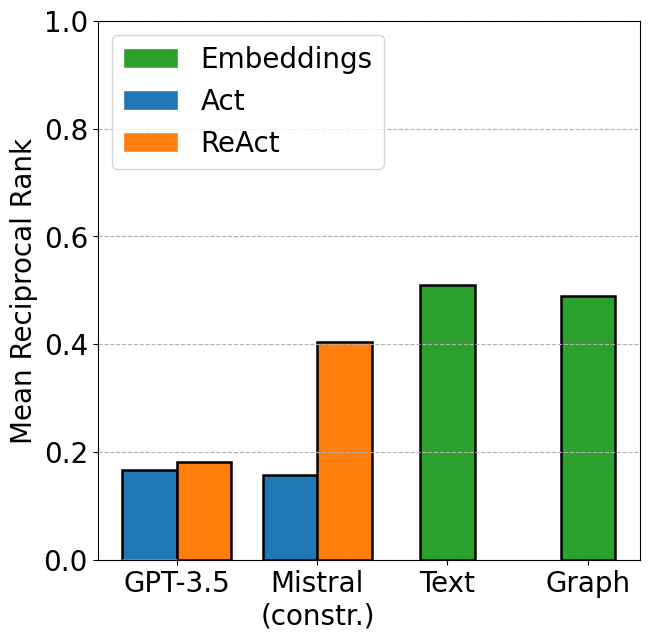

In [24]:
# Bar plot with mrr_df, each bar is an agent
fontsize=20
markersize=11
markeredgewidth=2.5
linewidth=2.5
barWidth = 0.5


agents = ['navigate/gpt_headings', 'navigate/gpt_headings_reason', 'navigate/lmql_headings', 'navigate/lmql_headings_reason', 'link_click/embedding_deepwalk_dfs', 'link_click/embedding_openai_dfs']
agents_to_prompting_model = {'navigate/gpt_headings': {"model": "GPT-3.5", "prompting": "Act"}, 'navigate/gpt_headings_reason': {"model": "GPT-3.5", "prompting": "ReAct"}, 'navigate/lmql_headings': {"model": "Mistral", "prompting": "Act"}, 'navigate/lmql_headings_reason': {"model": "Mistral", "prompting": "ReAct"},
                                'link_click/embedding_deepwalk_dfs': {"model": "Graph embed.", "prompting": "Embeddings"}, 'link_click/embedding_openai_dfs': {"model": "Text embed.", "prompting": "Embeddings"}}
prompt_to_color = {'Act': 'tab:blue', 'ReAct': 'tab:orange', 'Embeddings': 'tab:green'}
model_id = {'GPT-3.5': 0, 'Mistral': 1, 'Graph embed.': 2, 'Text embed.': 3}
positions = np.array([0,1.3, 2.5, 3.8])

# 2 bar plots, one for hits@1 and one for hits@5
plt.figure(figsize=(7,7))
for agent in agents:
    mrr = mrr_df.query("`agent.agent_name`==@agent")['mrr'].values
    model = agents_to_prompting_model[agent]['model']
    prompting = agents_to_prompting_model[agent]['prompting']
    print(f"Model = {model}, Prompting = {prompting}, MRR = {mrr[0]:.3f}")
    color = prompt_to_color[prompting]
    extra = 0
    if prompting=='Act':
        extra = -barWidth/2
    elif prompting=='ReAct':
        extra = +barWidth/2
    plt.bar(positions[model_id[model]] + barWidth/2 + extra, mrr, color=color, edgecolor='black', width=barWidth, linewidth=linewidth-0.7, capsize=markeredgewidth)
# hidden bars for legend
plt.bar(0,0, color='tab:green', edgecolor='white', width=barWidth, label='Embeddings')
plt.bar(0,0, color='tab:blue', edgecolor='white', width=barWidth, label='Act')
plt.bar(0,0, color='tab:orange', edgecolor='white', width=barWidth, label='ReAct')

plt.xticks(positions + barWidth/2, ['GPT-3.5', 'Mistral\n(constr.)', 'Text', 'Graph'], fontsize=fontsize)
plt.yticks(fontsize=fontsize)
plt.ylim(0,1)
# plt.xlabel(fontsize=fontsize)
plt.ylabel(f'Mean Reciprocal Rank', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.legend(title_fontsize=fontsize, loc='upper left', fontsize=fontsize)
plt.savefig('plots/mean_reciprocal_rank.pdf', bbox_inches='tight')


# Extra

In [4]:
# Specify the paths to the folders containing the runs
folders = []
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/random_nav_0/2023-12-22_18-08-48/*/"))]


identifiers = ['model.model_name','agent.fewshot','agent.agent_name']

all_runs_df = get_all_runs_df(folders, identifiers)

print(all_runs_df.columns)

{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 0, 'agent.agent_name': 'navigate/lmql_headings', 'run_id': '0'}
{'model.model_name': 'mistralai/Mistral-7B-Instruct-v0.2', 'agent.fewshot': 0, 'agent.agent_name': 'navigate/lmql_headings_reason', 'run_id': '1'}
Index(['agent_id', 'agent_name', 'agent_type', 'cur', 'src', 'tgt', 'response',
       'action', 'num_actions', 'num_tries', 'num_errors', 'is_finished',
       'is_finished_reason', 'path_so_far', 'user_prompt', 'hpl', 'path',
       'user_path_rating', 'spl', 'shepl', 'mhepl', 'error_type', 'path_len',
       'effective_path_so_far', 'effective_path_len', 'diff_from_best_human',
       'overhead_spl', 'overhead_shepl', 'overhead_mhepl',
       'human_overhead_spl', 'success', 'model.model_name', 'agent.fewshot',
       'agent.agent_name', 'run_id', 'prompting'],
      dtype='object')


                     model.model_name  agent.fewshot  \
1  mistralai/Mistral-7B-Instruct-v0.2              0   
0  mistralai/Mistral-7B-Instruct-v0.2              0   

                agent.agent_name       prompting  success  
1  navigate/lmql_headings_reason  ReAct_navigate    0.695  
0         navigate/lmql_headings    Act_navigate    0.550  


ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 0 with shape (2,) and arg 1 with shape (0,).

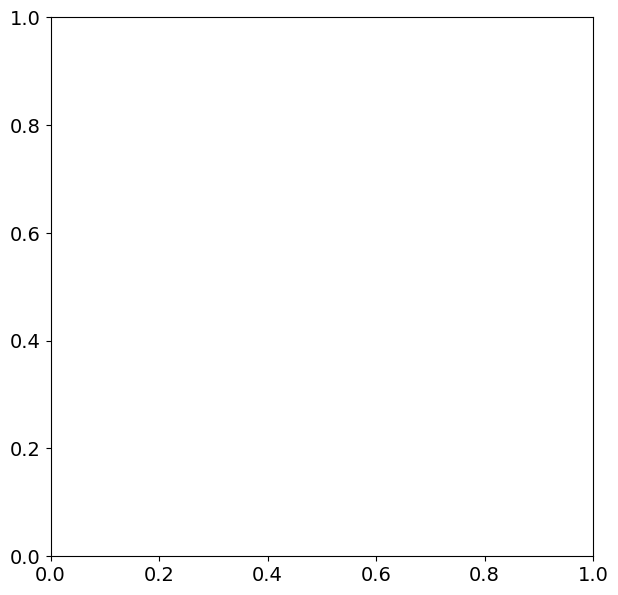

In [7]:
success_df = all_runs_df.query("is_finished==True").groupby(['model.model_name', 'agent.fewshot', 'agent.agent_name', 'prompting']).agg({'success':'mean'}).reset_index()

# Get unique model names and prompting types
# order the models by unconstrained success
success_df = success_df.sort_values(by=['prompting', 'success'], ascending=False)
print(success_df)

models = ['meta-llama/Llama-2-7b-chat-hf', 'mistralai/Mistral-7B-Instruct-v0.2', 'meta-llama/Llama-2-70b-chat-hf', 'gpt-3.5-turbo-1106']
prompting_types = success_df['prompting'].unique()
model_names = [model.split('/')[-1] for model in models]
fontsize=17

# Initialize the matplotlib figure
plt.figure(figsize=(7,7))

# Width of a bar
barWidth = 0.2

# Set positions of the bars on x-axis
positions = np.arange(len(prompting_types))

# Create bars for each model
for i, model in enumerate(models):
    model_data = success_df[success_df['model.model_name'] == model]
    if model=='gpt-3.5-turbo-1106':
        # only plot the unconstrained
        positions = np.arange(1)
    plt.bar(positions + i * barWidth, model_data['success'], width=barWidth, edgecolor='grey', label=model_names[i])

# Add features to the plot
plt.xlabel('Decoding Type', fontsize=fontsize)
plt.ylabel('Success Rate', fontsize=fontsize)
plt.grid(axis='y', linestyle='--')
plt.ylim(0,1)
plt.yticks(fontsize=fontsize)
#plt.xticks(np.arange(len(prompting_types)) + barWidth, ['Unconstrained', 'Constrained'], fontsize=fontsize)
plt.legend(title='Model', title_fontsize=fontsize, bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=fontsize)

# Create title & Show graphic
plt.show()


TypeError: 'Axes' object is not subscriptable

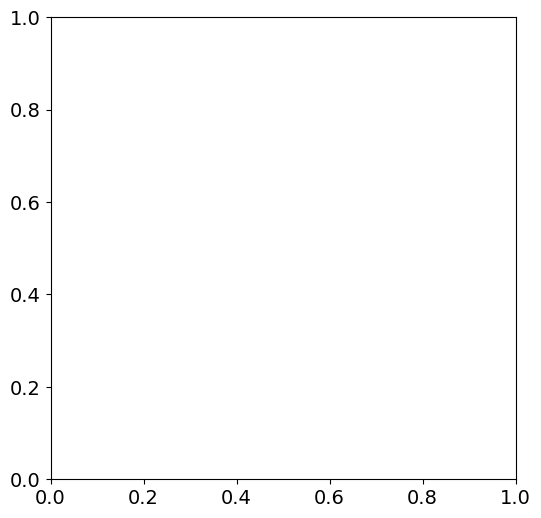

In [5]:
# all_runs_df has the columns: 'agent_id', 'agent_type', 'cur', 'src', 'tgt', 'response', 'action','num_actions', 'num_tries', 'num_errors', 'is_finished','is_finished_reason', 'path_so_far', 'user_prompt', 'hpl', 'path','user_path_rating', 'spl', 'path_len', 'effective_path_len','diff_from_best_human', 'diff_from_spl', 'success', 'model.model_name','agent.fewshot', 'run_id'

# for finished runs (is_finished == True), make a line plot: y=success rate, x=agent.fewshot, plot a line for each
lines = ["-","--","-.",":", "-","--","-.",":"]
markers = ['o', 'v', 's', 'p', '*', 'D', 'X']
colors = ['b', 'g', 'r', 'm', 'y', 'k', 'c']
bins = 20
n_games = all_runs_df.query('is_finished == True')['agent_id'].nunique()

# plot success rate vs fewshot for each, act vs react in each subplot

models = all_runs_df['model.model_name'].unique() 
# remove gpt-3.5-turbo-1106 from models
models = np.delete(models, np.where(models == 'gpt-3.5-turbo-1106'))
num_plots = len(models)
fig, axes = plt.subplots(1, num_plots, figsize=(6*num_plots, 6), sharey=True, sharex=True)

for i, model in enumerate(models):
    # plot horizontal line with 'gpt-3.5-turbo-1106' success rate
    gpt_df = all_runs_df[(all_runs_df['model.model_name'] == 'gpt-3.5-turbo-1106')].query('is_finished == True')
    axes[i].axhline(y=gpt_df[gpt_df['prompting'] == 'Act_linkclick_unconstrained']['success'].mean(), color='black', linestyle='--', label='Act ChatGPT fs=2')
    axes[i].axhline(y=gpt_df[gpt_df['prompting'] == 'ReAct_linkclick_unconstrained']['success'].mean(), color='blue', linestyle='--', label='ReAct ChatGPT fs=2')
    df = all_runs_df[(all_runs_df['model.model_name'] == model)].query('is_finished == True')
    df = df.groupby(['agent.fewshot', 'prompting']).agg({'success': 'mean'}).reset_index()
    for j, prompting in enumerate(df['prompting'].unique()):
        df_ = df[df['prompting'] == prompting]
        axes[i].plot(df_['agent.fewshot'], df_['success'], label=prompting, linestyle=lines[j], color=colors[j], marker=markers[j])
        axes[i].set_title(model, fontsize=12)
        axes[i].set_xlabel('fewshot')
        if i == 0:
            axes[i].set_ylabel('success rate')
        axes[i].legend(fontsize=9)
plt.suptitle(f'LinkClick Agent, n_games={n_games}')
plt.show()

# plot overhead_spl vs fewshot for each, act vs react in each subplot
fig, axes = plt.subplots(1, num_plots, figsize=(6*num_plots, 6), sharey=True, sharex=True)
for i, model in enumerate(models):
    df_all = all_runs_df[(all_runs_df['model.model_name'] == model)].query('success == 1')
    df = df_all.groupby(['agent.fewshot', 'prompting']).agg({'overhead_mhepl': 'mean'}).reset_index()

    # plot horizontal line with avg human_overhead_spl
    axes[i].axhline(y=df_all['human_overhead_spl'].mean(), color='black', linestyle='--', label='Avg Human')
    axes[i].axhline(y=1, color='red', linestyle='--', label='Optimal')

    for j, prompting in enumerate(df['prompting'].unique()):
        df_ = df[df['prompting'] == prompting]
        axes[i].plot(df_['agent.fewshot'], df_['overhead_mhepl'], label=prompting, linestyle=lines[j], color=colors[j], marker=markers[j])
        axes[i].set_title(model, fontsize=12)
        axes[i].set_xlabel('Fewshot')
        if i == 0:
            axes[i].set_ylabel('Overhead Factor')
        axes[i].legend(fontsize=9)
plt.suptitle(f'LinkClick Agent, random games, n_games={n_games}')
plt.show()

# plot overhead_spl vs spl for each, act vs react in each subplot
num_plots = len(all_runs_df['model.model_name'].unique())
fig, axes = plt.subplots(1, num_plots, figsize=(6*num_plots, 6), sharey=True, sharex=True)
for i, model in enumerate(all_runs_df['model.model_name'].unique()):
    axes[i].axhline(y=1, color='red', linestyle='--', label='Optimal')        
    for j, prompting in enumerate(df['prompting'].unique()):
        ###
        if not (model == "meta-llama/Llama-2-13b-chat-hf" and prompting=="Act_linkclick_unconstrained"):  
            df_all = all_runs_df[(all_runs_df['model.model_name'] == model)].query('success == 1')
            df = df_all.groupby(['spl', 'prompting']).agg({'overhead_mhepl': 'mean'}).reset_index()        
            df_ = df[df['prompting'] == prompting]
            axes[i].plot(df_['spl'], df_['overhead_mhepl'], label=prompting, linestyle=lines[j], color=colors[j], marker=markers[j])
            axes[i].set_title(model, fontsize=12)
            axes[i].set_xlabel('spl')
            if i == 0:
                axes[i].set_ylabel('Overhead Factor')
            axes[i].legend(fontsize=9)
plt.suptitle(f'LinkClick Agent, random games, n_games={n_games}')
plt.show()




num_plots = 2
fig, axes = plt.subplots(1, num_plots, figsize=(5*num_plots, 5), sharey=True, sharex=True)
mistral_linkclick_act = all_runs_df[(all_runs_df['model.model_name'] == 'teknium/OpenHermes-2.5-Mistral-7B') & (all_runs_df['prompting'] == 'Act_linkclick') & (all_runs_df['agent.fewshot'] == 2)]
mistral_linkclick_react = all_runs_df[(all_runs_df['model.model_name'] == 'teknium/OpenHermes-2.5-Mistral-7B') & (all_runs_df['prompting'] == 'ReAct_linkclick') & (all_runs_df['agent.fewshot'] == 1)]
mistral_navigate_act = all_runs_df[(all_runs_df['model.model_name'] == 'teknium/OpenHermes-2.5-Mistral-7B') & (all_runs_df['prompting'] == 'Act_navigate') & (all_runs_df['agent.fewshot'] == 0)]
llama_linkclick_act = all_runs_df[(all_runs_df['model.model_name'] == 'meta-llama/Llama-2-7b-chat-hf') & (all_runs_df['prompting'] == 'Act_linkclick') & (all_runs_df['agent.fewshot'] == 1)]
llama_linkclick_react = all_runs_df[(all_runs_df['model.model_name'] == 'meta-llama/Llama-2-7b-chat-hf') & (all_runs_df['prompting'] == 'ReAct_linkclick') & (all_runs_df['agent.fewshot'] == 3)]
df_list = [mistral_linkclick_act, mistral_linkclick_react, mistral_navigate_act, llama_linkclick_act, llama_linkclick_react]

for i, df in enumerate(df_list):
    if df['model.model_name'].unique()[0] == 'teknium/OpenHermes-2.5-Mistral-7B':
        ax_idx = 0
    else:
        ax_idx = 1
    df_ = df.query('success == 1').groupby(['spl']).agg({'overhead_spl': 'mean'}).reset_index()
    # do the same 
    axes[ax_idx].plot(df_['spl'], df_['overhead_spl'], label=df['prompting'].unique()[0], linestyle=lines[i], color=colors[i], marker=markers[i])
    axes[ax_idx].set_title(df['model.model_name'].unique()[0], fontsize=12)
    axes[ax_idx].set_xlabel('spl')
    if ax_idx == 0:
        axes[ax_idx].set_ylabel('eff len ratio to human')
    axes[ax_idx].legend(fontsize=9)
plt.suptitle(f'LinkClick Agent, random games, n_games={n_games}')
plt.show()




# plot_data(all_runs_df.query('prompting=="Act"'), plot_type='line', y_col='success', title=f'LinkClick Act Agent, n_games={n_games}', xlabel=f'{identifiers[1]}', ylabel='success rate')
# plot_data(all_runs_df.query('prompting=="ReAct"'), plot_type='line', y_col='success', title=f'LinkClick ReAct Agent, n_games={n_games}', xlabel=f'{identifiers[1]}', ylabel='success rate')

# # plot overhead_spl vs fewshot for each
# plot_data(all_runs_df, plot_type='line', y_col='overhead_spl', title=f'LinkClick Act Agent, n_games={n_games}', xlabel=f'{identifiers[1]}', ylabel='overhead (spl)')

# # plot overhead_mhepl vs fewshot for each
# plot_data(all_runs_df, plot_type='line', y_col='overhead_mhepl', title=f'LinkClick Act Agent, n_games={n_games}', xlabel=f'{identifiers[1]}', ylabel='overhead (median human path length)')

# fewshot = 1
# # plot histogram of final path lengths for each
# plot_data(all_runs_df, plot_type='histogram', y_col='effective_path_len', title=f'LinkClick Act Agent, fewshot={fewshot}, successful games', xlabel='eff path length', ylabel='freq', successful_only=True)


# # plot histogram of spl of successful paths for each fewshot
# fig, axes = plt.subplots(1, len(all_runs_df['agent.fewshot'].unique()), figsize=(5*len(all_runs_df['agent.fewshot'].unique()),5), sharey=True, sharex=True)
# axes = [axes] if not isinstance(axes, np.ndarray) else axes
# for i,fs in enumerate(all_runs_df['agent.fewshot'].unique()):
#     df = all_runs_df[(all_runs_df['agent.fewshot']==fs)].query('success==1')
#     df_all = all_runs_df[(all_runs_df['agent.fewshot']==fs)].query('is_finished==True')
#     bins_ = np.arange(df_all['spl'].min(), df_all['spl'].max()+1.5) - 0.5
#     axes[i].hist(df['spl'], label=f'fewshot={fs}', alpha=0.5, density=True, color=colors[i], bins=bins_)
#     #plot the true spl distribution aka for all games
#     axes[i].hist(df_all['spl'], label="true spl distribution", alpha=0.5, density=True, color='black', bins=bins_)
#     axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('successful games spl')
#     if i == 0:
#         axes[i].set_ylabel('freq')
#     axes[i].legend(fontsize=9)
# plt.suptitle(f'LinkClick Act Agent, n_games={n_games}')
# plt.show()




No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


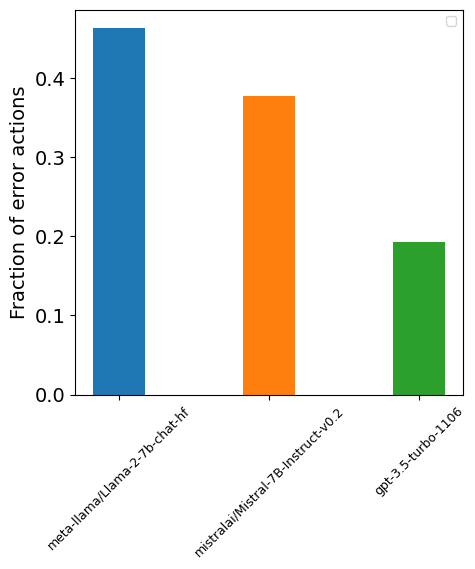

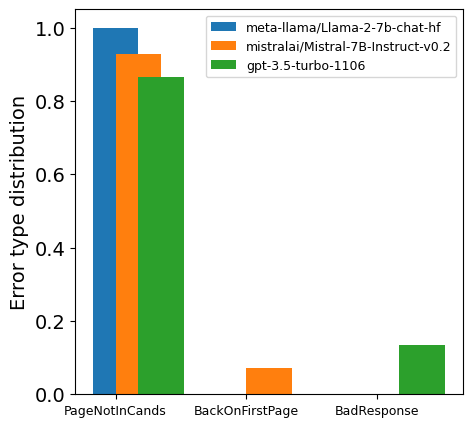

In [48]:
# plot error percentages
models = ['meta-llama/Llama-2-7b-chat-hf', 'mistralai/Mistral-7B-Instruct-v0.2', 'gpt-3.5-turbo-1106']
model_to_fs = {'meta-llama/Llama-2-7b-chat-hf': 2, 'mistralai/Mistral-7B-Instruct-v0.2': 1, 'gpt-3.5-turbo-1106': 2}
fig, ax = plt.subplots(figsize=(5,5))
width = 0.35
x = np.arange(len(models))
for i, model in enumerate(models):
    df = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['prompting'] == 'Act_linkclick_unconstrained') & (all_runs_df['agent.fewshot'] == model_to_fs[model])]
    error_percentage = len(df.query('error_type != "no_error"'))/len(df)
    ax.bar(x[i], error_percentage, width)
ax.set_xticks(x)
plt.xticks(fontsize=9,rotation=45)
ax.set_ylabel('Fraction of error actions')
ax.set_xticklabels(models)
ax.legend(fontsize=9)
plt.show()

# plot error type percentages. The x ticks are the error types, in each tick there is a bar for each model
error_types = ['PageNotInCands', 'BackOnFirstPage', 'BadResponse']
fig, ax = plt.subplots(figsize=(5,5))
width = 0.35
x = np.arange(len(error_types))
for i, model in enumerate(models):
    df = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['prompting'] == 'Act_linkclick_unconstrained') & (all_runs_df['agent.fewshot'] == model_to_fs[model])]
    error_type_percentages = []
    for error_type in error_types:
        error_type_percentages.append(len(df.query(f'error_type == "{error_type}"'))/len(df.query('error_type != "no_error"')))
    ax.bar(x+width/2*i, error_type_percentages, width, label=model)
ax.set_xticks(x)
plt.xticks(fontsize=9)
ax.set_ylabel('Error type distribution')
ax.set_xticklabels(error_types)
ax.legend(fontsize=9)
plt.show()


In [49]:
all_runs_df[
    (all_runs_df['model.model_name'] == 'gpt-3.5-turbo-1106') &
    (all_runs_df['error_type'] == 'BadResponse')
]

,agent_id,agent_name,agent_type,cur,src,tgt,response,action,num_actions,num_tries,...,overhead_spl,overhead_shepl,overhead_mhepl,human_overhead_spl,success,model.model_name,agent.fewshot,agent.agent_name,run_id,prompting
152,99,link_click/gpt_dfs_back_reason,GPTLinkClickDFSAgent,Abhidhamma_Pitaka,Abhidhamma_Pitaka,Zulu,"{'thought': 'To reach the target article, we need to find a link that takes us closer to the target. Since there are no relevant links to the target article in the provided options, you may need to explore other paths or use a search function to find a related article.', 'next_article': ''}",Error: Page name can't be empty. Choose a different action.,1,1,...,0.250000,0.166667,0.111111,2.250000,0,gpt-3.5-turbo-1106,2,link_click/gpt_dfs_reason,1,ReAct_linkclick_unconstrained
153,7,link_click/gpt_dfs_back_reason,GPTLinkClickDFSAgent,Saltasaurus,Saltasaurus,Battle_of_Stalingrad,"{'thought': 'To reach the target article, we need to find a link related to war or battles. Since there are no such links in the provided candidates, we may need to find a different route or start from a different source article.', 'next_article': ''}",Error: Page name can't be empty. Choose a different action.,1,1,...,0.333333,0.333333,0.250000,1.333333,0,gpt-3.5-turbo-1106,2,link_click/gpt_dfs_reason,1,ReAct_linkclick_unconstrained
188,119,link_click/gpt_dfs_back_reason,GPTLinkClickDFSAgent,Hawk,Hawk,Rococo,"{'thought': 'Since the target article is Rococo, which is related to art and design, we should try to find a link related to art or design. None of the provided links seem directly related, so we may need to rethink our approach.', 'next_article': ''}",Error: Page name can't be empty. Choose a different action.,1,1,...,0.250000,0.125000,0.125000,2.000000,0,gpt-3.5-turbo-1106,2,link_click/gpt_dfs_reason,1,ReAct_linkclick_unconstrained
235,119,link_click/gpt_dfs_back_reason,GPTLinkClickDFSAgent,Hawk,Hawk,Rococo,"{'thought': ""Since the target article is Rococo, which is related to art and design, we should try to find a link related to art or design. None of the provided links seem directly related, so let's try to find a different path to the target article."", 'next_article': ''}",Error: Page name can't be empty. Choose a different action.,2,2,...,0.250000,0.125000,0.125000,2.000000,0,gpt-3.5-turbo-1106,2,link_click/gpt_dfs_reason,1,ReAct_linkclick_unconstrained
467,119,link_click/gpt_dfs_back_reason,GPTLinkClickDFSAgent,Hawk,Hawk,Rococo,"{'thought': 'Since the target article is Rococo, which is related to art and design, we should try to find a link related to art or design. None of the provided links seem directly related, so we may need to rethink our approach.', 'next_article': ''}",Error: Page name can't be empty. Choose a different action.,3,3,...,0.250000,0.125000,0.125000,2.000000,0,gpt-3.5-turbo-1106,2,link_click/gpt_dfs_reason,1,ReAct_linkclick_unconstrained
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2637,12,link_click/gpt_dfs_back_reminder,GPTLinkClickDFSAgent,The_Beatles,Banana,Monty_Python,{'error': 'Monty_Python not found in the provided links'},Invalid action: {'error': 'Monty_Python not found in the provided links'},14,3,...,4.000000,NaN,NaN,NaN,0,gpt-3.5-turbo-1106,2,link_click/gpt_dfs,0,Act_linkclick_unconstrained
2779,171,link_click/gpt_dfs_back_reminder,GPTLinkClickDFSAgent,Lake_Mead,Arnold_Schwarzenegger,Chew_Valley_Lake,{'error': 'Chew_Valley_Lake not found in the links from Lake_Mead. Please provide valid links.'},Invalid action: {'error': 'Chew_Valley_Lake not found in the links from Lake_Mead. Please provide valid links.'},19,2,...,4.250000,NaN,NaN,NaN,0,gpt-3.5-turbo-1106,2,link_click/gpt_dfs,0,Act_linkclick_unconstrained
2810,171,link_click/gpt_dfs_back_reminder,GPTLinkClickDFSAgent,Lake_Mead,Arnold_Schwarzenegger,Chew_Valley_Lake,{'error': 'Chew_Valley_Lake not found in the links from Lake_Mead. Please provide valid links.'},Invalid action: {'error': 'Chew_Valley

In [3]:
lines = ["-","--","-.",":", "-","--","-.",":"]
colors = ['b', 'g', 'r', 'm', 'y', 'k', 'c']
bins = 20
n_games = all_runs_df.query('is_finished == True')['agent_id'].nunique()

def plot_data(all_runs_df,y_col, title, xlabel, ylabel, identifiers=identifiers, colors=colors, lines=lines, n_games=n_games,bins=bins, fewshot=1, plot_type='histogram', successful_only=False):
    unique_identifiers = all_runs_df[identifiers[0]].unique()
    num_plots = len(unique_identifiers)

    if plot_type == 'line':
        plt.figure(figsize=(8, 6))
        for i, identifier in enumerate(unique_identifiers):
            df = all_runs_df[all_runs_df[identifiers[0]] == identifier].query('is_finished == True')
            df = df.groupby(identifiers[1]).agg({y_col: 'mean'}).reset_index()
            plt.plot(df[identifiers[1]], df[y_col], label=identifier, linestyle=lines[i], color=colors[i])
            plt.xlabel(xlabel)
            plt.ylabel(ylabel)
        plt.legend()
    elif plot_type == 'histogram':
        fig, axes = plt.subplots(1, num_plots, figsize=(5*num_plots, 5), sharey=True, sharex=True)
        axes = [axes] if not isinstance(axes, np.ndarray) else axes
        for i, identifier in enumerate(unique_identifiers):
            if successful_only:
                df = all_runs_df[(all_runs_df[identifiers[0]] == identifier) & (all_runs_df['success']==1)].query('is_finished == True')
            else:
                df = all_runs_df[(all_runs_df[identifiers[0]] == identifier)].query('is_finished == True')
            axes[i].hist(df[y_col], bins=bins, alpha=0.5, density=True, color=colors[i], label=identifier)
            axes[i].set_title(identifier, fontsize=12)
            axes[i].set_xlabel(xlabel)
            if i == 0:
                axes[i].set_ylabel(ylabel)
            axes[i].legend()
    else:
        raise ValueError("Invalid plot type specified")

    plt.suptitle(title)
    plt.show()


In [15]:
test_df = paths_real_df[paths_real_df["is_path_finished"] == 1]
test_df['overhead_spl'] = test_df['mhepl']/test_df['spl']

test_df.groupby(["src", "tgt"]).agg({"is_path_finished": "count", "overhead_spl": "mean"}).reset_index().query("is_path_finished >= 4").reset_index()['overhead_spl'].mean()


/tmp/ipykernel_2910096/923625743.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df['overhead_spl'] = test_df['mhepl']/test_df['spl']


1.7279780564263323

In [14]:
# check how many games we have a non nan mhepl value
all_runs_df[all_runs_df['mhepl'].notnull()]['agent_id']

0          3
1          4
2          6
3          7
5         13
        ... 
73697    109
73707     77
73716    198
73721    109
73733    109
Name: agent_id, Length: 37825, dtype: int64

In [54]:
mistral_linkclick_react.query('src=="The_Cat_in_the_Hat" and tgt=="Sunlight"')[['user_prompt']]

,user_prompt
10810,"{""source"": ""The_Cat_in_the_Hat"", ""target"": ""Sunlight"", ""links"": ""Dr._Seuss;Latin""}\nRemember that I'm currently on the page The_Cat_in_the_Hat and I'm trying to reach the page Sunlight, in the least number of clicks possible. What article should I click on? Give me your thought process in making that decision. As an absolute last resort option, if no available link takes you closer to the target, select ""NA"" as the next article."
10995,"{""source"": ""Dr._Seuss"", ""target"": ""Sunlight"", ""links"": ""Adolf_Hitler;Benito_Mussolini;Communism;Elephant;Fascism;George_W._Bush;India;Jew;Literature;Macbeth;New_York_City;The_Cat_in_the_Hat;The_Holocaust;The_Lorax;United_States;Whale;William_Shakespeare;World_War_II""}\nRemember that I'm currently on the page Dr._Seuss and I'm trying to reach the page Sunlight, in the least number of clicks possible. What article should I click on? Give me your thought process in making that decision. As an absolute last resort option, if no available link takes you closer to the target, select ""NA"" as the next article."
11141,"{""source"": ""The_Cat_in_the_Hat"", ""target"": ""Sunlight"", ""links"": ""Latin""}\nRemember that I'm currently on the page The_Cat_in_the_Hat and I'm trying to reach the page Sunlight, in the least number of clicks possible. What article should I click on? Give me your thought process in making that decision. As an absolute last resort option, if no available link takes you closer to the target, select ""NA"" as the next article."
11246,"{""source"": ""Latin"", ""target"": ""Sunlight"", ""links"": ""18th_century;1st_century_BC;9th_century;Ancient_Rome;Bible;Byzantine_Empire;English_language;Europe;French_language;Great_Britain;Italy;Latin_alphabet;Law;Portugal;Portuguese_language;Roman_Catholic_Church;Roman_Empire;Rome;Science;Spanish_language;Split_infinitive;The_Adventures_of_Tintin;United_States;Vatican_City;Virgil;Vulgar_Latin;Western_Roman_Empire;William_I_of_England""}\nRemember that I'm currently on the page Latin and I'm trying to reach the page Sunlight, in the least number of clicks possible. What article should I click on? Give me your thought process in making that decision. As an absolute last resort option, if no available link takes you closer to the target, select ""NA"" as the next article."
11329,"{""source"": ""The_Cat_in_the_Hat"", ""target"": ""Sunlight"", ""links"": """"}\nRemember that I'm currently on the page The_Cat_in_the_Hat and I'm trying to reach the page Sunlight, in the least number of clicks possible. What article should I click on? Give me your thought process in making that decision. As an absolute last resort option, if no available link takes you closer to the target, select ""NA"" as the next article."
11410,Page name can't be empty. Choose a different action.
11478,Page name can't be empty. Choose a different action.


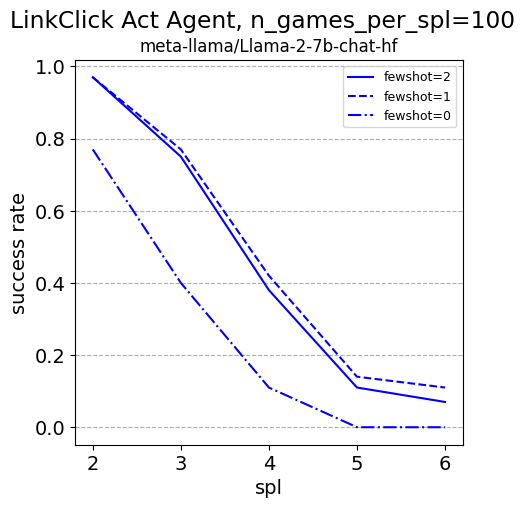

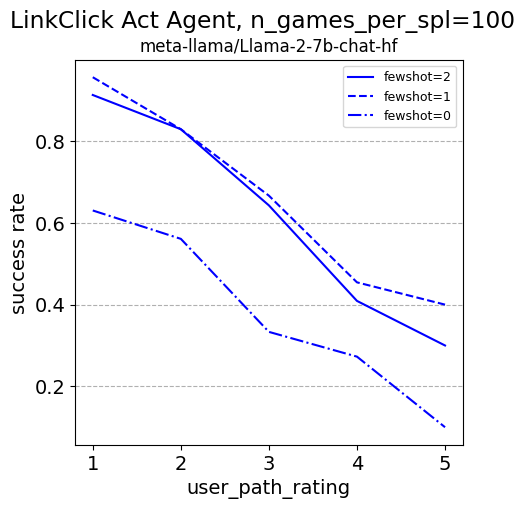

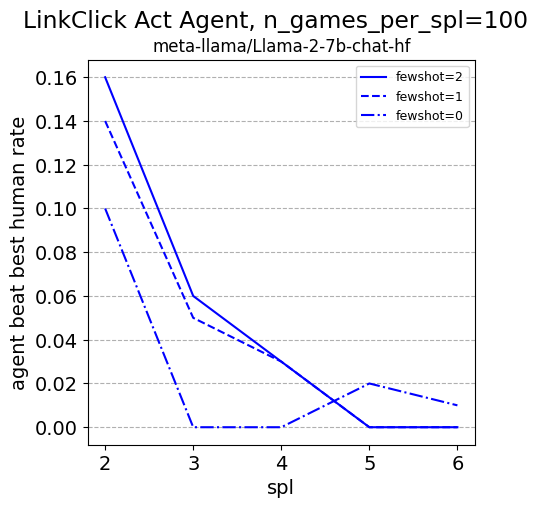

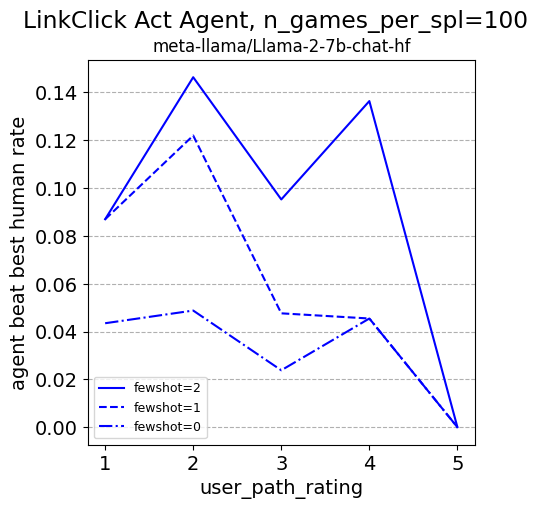

In [93]:
# line plot of success rate vs spl for each fewshot
fig, axes = plt.subplots(1, len(all_runs_df[identifiers[0]].unique()), figsize=(5*len(all_runs_df[identifiers[0]].unique()),5), sharey=True, sharex=True)
axes = [axes] if not isinstance(axes, np.ndarray) else axes
for i,identifier in enumerate(all_runs_df[identifiers[0]].unique()):
    for j,fs in enumerate(all_runs_df['agent.fewshot'].unique()):
        df = all_runs_df[(all_runs_df[identifiers[0]] == identifier) & (all_runs_df['agent.fewshot']==fs)].query('is_finished == True')
        df = df.groupby('spl').agg({'success':'mean'}).reset_index()
        axes[i].plot(df['spl'], df['success'], label=f'fewshot={fs}', linestyle=lines[j], color=colors[i])
    # add y grid
    axes[i].grid(axis='y', linestyle='--')
    axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('spl')
    if i == 0:
        axes[i].set_ylabel('success rate')
    axes[i].legend(fontsize=9)
plt.suptitle(f'LinkClick Act Agent, n_games_per_spl={n_games//5}')
plt.show()

# line plot of success rate vs user_path_rating for each fewshot
fig, axes = plt.subplots(1, len(all_runs_df[identifiers[0]].unique()), figsize=(5*len(all_runs_df[identifiers[0]].unique()),5), sharey=True, sharex=True)
axes = [axes] if not isinstance(axes, np.ndarray) else axes
for i,identifier in enumerate(all_runs_df[identifiers[0]].unique()):
    for j,fs in enumerate(all_runs_df['agent.fewshot'].unique()):
        df = all_runs_df[(all_runs_df[identifiers[0]] == identifier) & (all_runs_df['agent.fewshot']==fs)].query('is_finished == True')
        df = df.groupby('user_path_rating').agg({'success':'mean'}).reset_index()
        axes[i].plot(df['user_path_rating'], df['success'], label=f'fewshot={fs}', linestyle=lines[j], color=colors[i])
    # add y grid
    axes[i].grid(axis='y', linestyle='--')
    axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('user_path_rating')
    if i == 0:
        axes[i].set_ylabel('success rate')
    axes[i].legend(fontsize=9)
plt.suptitle(f'LinkClick Act Agent, n_games_per_spl={n_games//5}')
plt.show()

# plot percentage of times the agent beat the best human for each fewshot (effective_path_len < shepl)
fig, axes = plt.subplots(1, len(all_runs_df[identifiers[0]].unique()), figsize=(5*len(all_runs_df[identifiers[0]].unique()),5), sharey=True, sharex=True)
axes = [axes] if not isinstance(axes, np.ndarray) else axes
for i,identifier in enumerate(all_runs_df[identifiers[0]].unique()):
    for j,fs in enumerate(all_runs_df['agent.fewshot'].unique()):
        df = all_runs_df[(all_runs_df[identifiers[0]] == identifier) & (all_runs_df['agent.fewshot']==fs)].query('is_finished == True')
        df['agent_beat_best_human'] = df['effective_path_len'] < df['shepl']
        df = df.groupby('spl').agg({'agent_beat_best_human':'mean'}).reset_index()
        axes[i].plot(df['spl'], df['agent_beat_best_human'], label=f'fewshot={fs}', linestyle=lines[j], color=colors[i])
    # add y grid
    axes[i].grid(axis='y', linestyle='--')
    axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('spl')
    if i == 0:
        axes[i].set_ylabel('agent beat best human rate')
    axes[i].legend(fontsize=9)
plt.suptitle(f'LinkClick Act Agent, n_games_per_spl={n_games//5}')
plt.show()

# plot percentage of times the agent beat the best human for each fewshot (effective_path_len < shepl)
fig, axes = plt.subplots(1, len(all_runs_df[identifiers[0]].unique()), figsize=(5*len(all_runs_df[identifiers[0]].unique()),5), sharey=True, sharex=True)
axes = [axes] if not isinstance(axes, np.ndarray) else axes
for i,identifier in enumerate(all_runs_df[identifiers[0]].unique()):
    for j,fs in enumerate(all_runs_df['agent.fewshot'].unique()):
        df = all_runs_df[(all_runs_df[identifiers[0]] == identifier) & (all_runs_df['agent.fewshot']==fs)].query('is_finished == True')
        df['agent_beat_best_human'] = df['effective_path_len'] < df['shepl']
        df = df.groupby('user_path_rating').agg({'agent_beat_best_human':'mean'}).reset_index()
        axes[i].plot(df['user_path_rating'], df['agent_beat_best_human'], label=f'fewshot={fs}', linestyle=lines[j], color=colors[i])
    # add y grid
    axes[i].grid(axis='y', linestyle='--')
    axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('user_path_rating')
    if i == 0:
        axes[i].set_ylabel('agent beat best human rate')
    axes[i].legend(fontsize=9)
plt.suptitle(f'LinkClick Act Agent, n_games_per_spl={n_games//5}')
plt.show()

    


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


   spl  agent_beat_best_human
0    2                0.12987
1    3                0.00000
2    4                0.00000


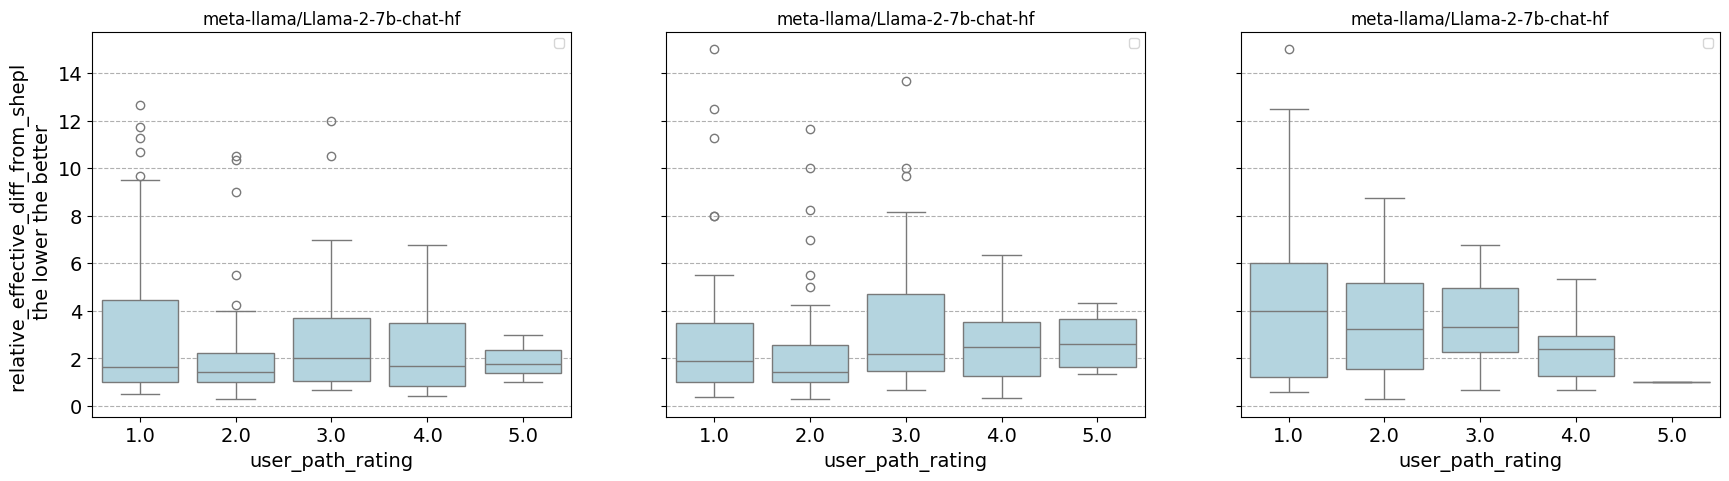

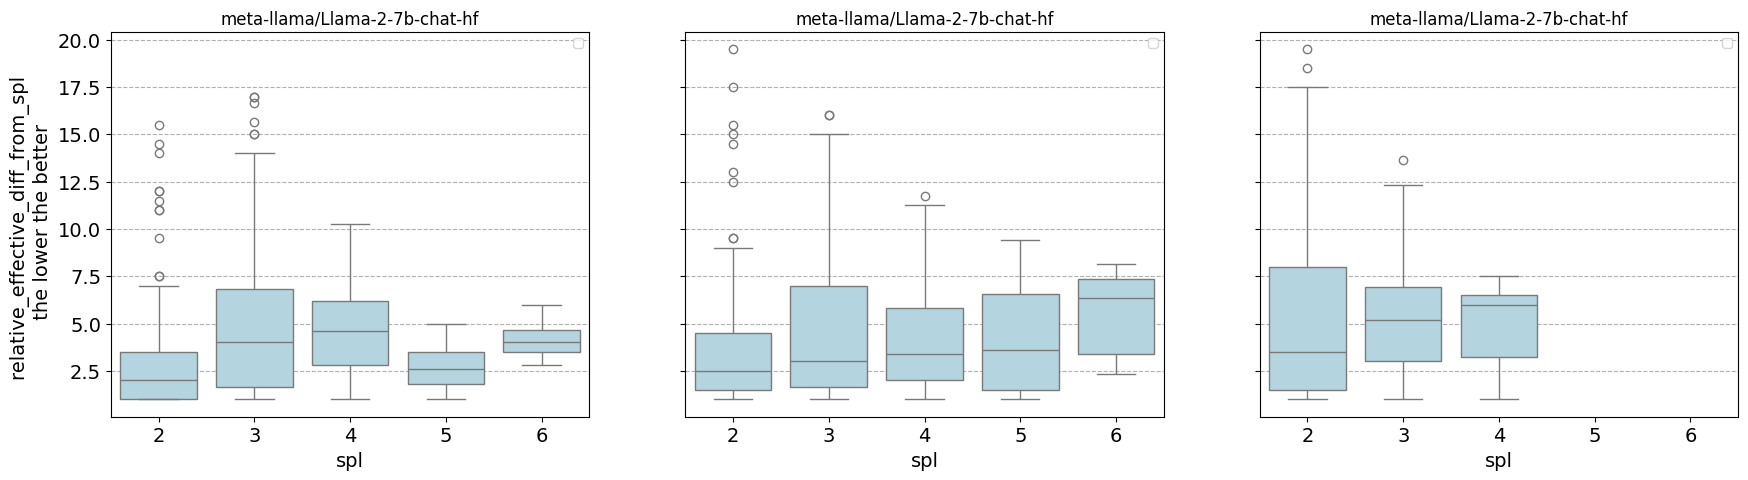

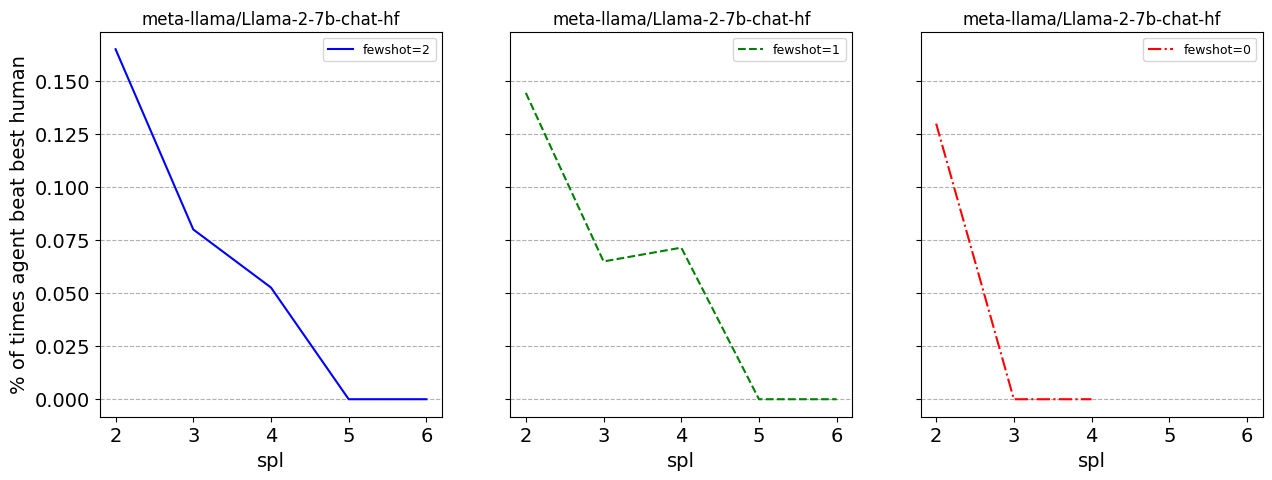

In [88]:
# line plot of median effective_diff_from_shepl vs spl for each fewshot vs spl for each fewshot
# fig, axes = plt.subplots(1, len(all_runs_df[identifiers[0]].unique()), figsize=(5*len(all_runs_df[identifiers[0]].unique()),5), sharey=True, sharex=True)
# axes = [axes] if not isinstance(axes, np.ndarray) else axes
# for i,identifier in enumerate(all_runs_df[identifiers[0]].unique()):
#     for j,fs in enumerate(all_runs_df['agent.fewshot'].unique()):
#         df = all_runs_df[(all_runs_df[identifiers[0]] == identifier) & (all_runs_df['agent.fewshot']==fs)].query('success==1')
#         df['relative_effective_diff_from_shepl'] = (df['shepl'] + df['effective_diff_from_shepl']) / df['shepl']
#         # plot error bars of 1 std
#         df = df.groupby('spl').agg({'relative_effective_diff_from_shepl': ['median', 'std']}).reset_index()
#         axes[i].errorbar(df['spl'], df['relative_effective_diff_from_shepl']['median'], yerr=df['relative_effective_diff_from_shepl']['std'], label=f'fewshot={fs}', linestyle=lines[j], color=colors[i], marker=markers[j])
#     # add y grid
#     axes[i].grid(axis='y', linestyle='--')
#     axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('spl')
#     if i == 0:
#         axes[i].set_ylabel('median relative_effective_diff_from_shepl \n the lower the better')
#     axes[i].legend(fontsize=9)
# plt.suptitle(f'LinkClick Act Agent, successful games')
# plt.show()

fig, axes = plt.subplots(1, len(all_runs_df['agent.fewshot'].unique()), figsize=(7*len(all_runs_df['agent.fewshot'].unique()),5), sharey=True, sharex=True)
axes = [axes] if not isinstance(axes, np.ndarray) else axes
for i,fs in enumerate(all_runs_df['agent.fewshot'].unique()):
    df = all_runs_df[(all_runs_df['agent.fewshot']==fs)].query('success==1')
    df['relative_effective_diff_from_shepl'] = (df['shepl'] + df['effective_diff_from_shepl']) / df['shepl']
    # box plot of relative_effective_diff_from_shepl
    sns.boxplot(x='user_path_rating', y='relative_effective_diff_from_shepl', data=df, ax=axes[i], color='lightblue')

    # add y grid
    axes[i].grid(axis='y', linestyle='--')
    axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('user_path_rating')
    if i == 0:
        axes[i].set_ylabel('relative_effective_diff_from_shepl \n the lower the better')
    axes[i].legend(fontsize=9)

fig, axes = plt.subplots(1, len(all_runs_df['agent.fewshot'].unique()), figsize=(7*len(all_runs_df['agent.fewshot'].unique()),5), sharey=True, sharex=True)
axes = [axes] if not isinstance(axes, np.ndarray) else axes
for i,fs in enumerate(all_runs_df['agent.fewshot'].unique()):
    df = all_runs_df[(all_runs_df['agent.fewshot']==fs)].query('success==1')
    df['relative_effective_diff_from_spl'] = (df['spl'] + df['effective_diff_from_spl']) / df['spl']
    # box plot of relative_effective_diff_from_shepl
    sns.boxplot(x='spl', y='relative_effective_diff_from_spl', data=df, ax=axes[i], color='lightblue')

    # add y grid
    axes[i].grid(axis='y', linestyle='--')
    axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('spl')
    if i == 0:
        axes[i].set_ylabel('relative_effective_diff_from_spl \n the lower the better')
    axes[i].legend(fontsize=9)

# plot percentage of times the agent beat the best human for each fewshot (effective_path_len < shepl)
fig, axes = plt.subplots(1, len(all_runs_df['agent.fewshot'].unique()), figsize=(5*len(all_runs_df['agent.fewshot'].unique()),5), sharey=True, sharex=True)
axes = [axes] if not isinstance(axes, np.ndarray) else axes
for i,fs in enumerate(all_runs_df['agent.fewshot'].unique()):
    df = all_runs_df[(all_runs_df['agent.fewshot']==fs)].query('success==1')
    df['agent_beat_best_human'] = df['effective_path_len'] < df['shepl']
    df = df.groupby('spl').agg({'agent_beat_best_human':'mean'}).reset_index()
    axes[i].plot(df['spl'], df['agent_beat_best_human'], label=f'fewshot={fs}', linestyle=lines[i], color=colors[i])
    # add y grid
    axes[i].grid(axis='y', linestyle='--')
    axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('spl')
    if i == 0:
        axes[i].set_ylabel('% of times agent beat best human')
    axes[i].legend(fontsize=9)

print(df)


In [75]:
all_runs_df[(all_runs_df['agent.fewshot']==0)].query('success==1')['user_path_rating'].value_counts()

user_path_rating
1.0    29
2.0    23
3.0    14
4.0     6
5.0     1
Name: count, dtype: int64

In [60]:
all_runs_df.query('spl==6 and shepl.notnull()')[['src', 'tgt', 'shepl', 'path']]

,src,tgt,shepl,path
237,Batman,Wikisource,8.0,Batman;Crime;United_States;Internet;World_Wide_Web;Library;Information;Mass_media;Literature;Publishing;Wikipedia;Open_source;<;Wikimedia_Foundation;Wikisource
238,Mind,Tropical_Storm_Odette_(2003),6.0,Mind;History_of_science;Meteorology;Tropical_cyclone;2005_Atlantic_hurricane_season;2003_Atlantic_hurricane_season;Tropical_Storm_Odette_(2003)
253,First_Macedonian_War,Upsilon_Andromedae_c,15.0,First_Macedonian_War;Ancient_Greece;19th_century;Napoleonic_Wars;Democracy;Liberal_democracy;Age_of_Enlightenment;Romanticism;Pre-Raphaelite_Brotherhood;<;20th_century;Quantum_mechanics;Special_relativity;Speed_of_light;Astronomy;Extrasolar_planet;Upsilon_Andromedae;Upsilon_Andromedae_c
259,Jehovah,Chromatophore,6.0,Jehovah;Switzerland;Energy;Photosynthesis;Pigment;Albinism;Chromatophore
263,Friedrich_Nietzsche,Tropical_Storm_Odette_(2003),10.0,Friedrich_Nietzsche;Jack_Kerouac;United_States;Puerto_Rico;Tsunami;Meteorology;El_Niño-Southern_Oscillation;Tropical_cyclone;2005_Atlantic_hurricane_season;Tropical_Storm_Delta_(2005);<;Tropical_Storm_Zeta_(2005);Tropical_cyclone;<;Tropical_cyclone;<;<;2003_Atlantic_hurricane_season;Tropical_Storm_Odette_(2003)
...,...,...,...,...
52692,Asparagus,Great_Comet_of_1882,8.0,Asparagus;United_States;Apollo_11;Moon;Solar_System;Comet;Kuiper_belt;Scattered_disc;<;<;Comet_Halley;<;Comet_Hale-Bopp;Great_comet;Great_Comet_of_1882
52695,Angel_shark,The_Country_Wife,7.0,Angel_shark;North_Sea;England;William_Shakespeare;Ben_Jonson;Augustan_literature;Restoration_comedy;The_Country_Wife
52768,Fossil_record,Great_Comet_of_1882,8.0,Fossil_record;Dinosaur;Geology;History_of_Earth;Solar_System;Comet;Kuiper_belt;<;Comet_Halley;<;Comet_Hale-Bopp;Great_comet;Great_Comet_of_1882
52782,Asparagus,Great_Comet_of_1882,8.0,Asparagus;United_States;Apollo_11;Moon;Solar_System;Comet;Kuiper_belt;Scattered_disc;<;<;Comet_Halley;<;Comet_Hale-Bopp;Great_comet;Great_Comet_of_1882


TypeError: 'Axes' object is not subscriptable

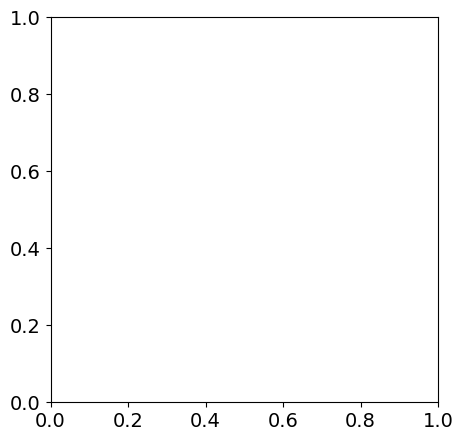

In [6]:
# Compare Act vs ReAct prompting

lines = ["-","--","-.",":", "-","--","-.",":"]
colors = ['b', 'g', 'r', 'm', 'y', 'k', 'c']
bins = 20
all_runs_df = all_runs_df[all_runs_df['agent.fewshot']<=1]

# plot success rate of each model, comparing Act vs ReAct prompting, fewshot=0
fig, axes = plt.subplots(1, len(all_runs_df['model.model_name'].unique()), figsize=(5*len(all_runs_df['model.model_name'].unique()),5), sharey=True, sharex=True)
fewshot = 0
for i,model in enumerate(all_runs_df['model.model_name'].unique()):
    df = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['agent.fewshot']==fewshot)].query('is_finished == True')
    df = df.groupby('prompting').agg({'success':'mean'}).reset_index()
    axes[i].bar(df['prompting'], df['success'], color=colors[i])
    axes[i].set_title(model, fontsize=12); axes[i].set_xlabel('prompting')
    if i == 0:
        axes[i].set_ylabel('success rate')
plt.suptitle('Constrained agent, n_games=100, fewshot=0')
plt.show()

# plot success rate of each model, comparing fewshot=0 vs fewshot=1, with ReAct prompting only
fig, axes = plt.subplots(1, len(all_runs_df['model.model_name'].unique()), figsize=(5*len(all_runs_df['model.model_name'].unique()),5), sharey=True, sharex=True)
prompting = 'ReAct'
for i,model in enumerate(all_runs_df['model.model_name'].unique()):
    df = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['prompting']==prompting)].query('is_finished == True')
    df = df.groupby('agent.fewshot').agg({'success':'mean'}).reset_index()
    axes[i].bar(df['agent.fewshot'], df['success'], color=colors[i])
    axes[i].set_title(model, fontsize=12); axes[i].set_xlabel('fewshot')
    if i == 0:
        axes[i].set_ylabel('success rate')
plt.suptitle('Constrained agent, n_games=100, ReAct prompting')
plt.show()


# plot success rate of each model, comparing Act vs ReAct prompting, fewshot=1
fig, axes = plt.subplots(1, len(all_runs_df['model.model_name'].unique()), figsize=(5*len(all_runs_df['model.model_name'].unique()),5), sharey=True, sharex=True)
fewshot = 1
for i,model in enumerate(all_runs_df['model.model_name'].unique()):
    df = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['agent.fewshot']==fewshot)].query('is_finished == True')
    df = df.groupby('prompting').agg({'success':'mean'}).reset_index()
    axes[i].bar(df['prompting'], df['success'], color=colors[i])
    axes[i].set_title(model, fontsize=12); axes[i].set_xlabel('prompting')
    if i == 0:
        axes[i].set_ylabel('success rate')
plt.suptitle('Constrained agent, n_games=100, fewshot=1')
plt.show()

# from now on, use fewshot=1
fewshot=1

# plot histogram of final path lengths for each model, comparing Act vs ReAct prompting
fig, axes = plt.subplots(1, len(all_runs_df['model.model_name'].unique()), figsize=(5*len(all_runs_df['model.model_name'].unique()),5), sharey=True, sharex=True)
for i,model in enumerate(all_runs_df['model.model_name'].unique()):
    df = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['agent.fewshot']==fewshot)].query('is_finished == True')
    df_act = df[df['prompting']=='Act']
    df_react = df[df['prompting']=='ReAct']
    axes[i].hist(df_act['path_len'], label='Act', bins=bins, alpha=0.5, density=True, color='blue')
    axes[i].hist(df_react['path_len'], label='ReAct', bins=bins, alpha=0.5, density=True, color='red')
    # use logaritmic scale
    axes[i].set_yscale('log')
    axes[i].set_title(model, fontsize=12); axes[i].set_xlabel('path length')
    if i == 0:
        axes[i].set_ylabel('count')
    axes[i].legend()
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()

# plot histogram of diff_from_best_human for each model, comparing Act vs ReAct prompting
fig, axes = plt.subplots(1, len(all_runs_df['model.model_name'].unique()), figsize=(5*len(all_runs_df['model.model_name'].unique()),5), sharey=True, sharex=True)
for i,model in enumerate(all_runs_df['model.model_name'].unique()):
    df = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['agent.fewshot']==fewshot)].query('success==1')
    df_act = df[df['prompting']=='Act']
    df_react = df[df['prompting']=='ReAct']
    axes[i].hist(df_act['diff_from_best_human'], label='Act', bins=bins, alpha=0.5, density=True, color='blue')
    axes[i].hist(df_react['diff_from_best_human'], label='ReAct', bins=bins, alpha=0.5, density=True, color='red')
    axes[i].set_yscale('log')
    axes[i].set_title(model, fontsize=12); axes[i].set_xlabel('path len diff_from_best_human')
    if i == 0:
        axes[i].set_ylabel('count')
    axes[i].legend()
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()

# plot histogram of diff_from_spl for each model, comparing Act vs ReAct prompting
fig, axes = plt.subplots(1, len(all_runs_df['model.model_name'].unique()), figsize=(5*len(all_runs_df['model.model_name'].unique()),5), sharey=True, sharex=True)
for i,model in enumerate(all_runs_df['model.model_name'].unique()):
    df = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['agent.fewshot']==fewshot)].query('success==1')
    df_act = df[df['prompting']=='Act']
    df_react = df[df['prompting']=='ReAct']
    axes[i].hist(df_act['effective_diff_from_spl'], label='Act', bins=bins, alpha=0.5, density=True, color='blue')
    axes[i].hist(df_react['effective_diff_from_spl'], label='ReAct', bins=bins, alpha=0.5, density=True, color='red')
    axes[i].set_yscale('log')
    axes[i].set_title(model, fontsize=12); axes[i].set_xlabel('effective_diff_from_spl')
    if i == 0:
        axes[i].set_ylabel('freq')
    axes[i].legend()
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()

# plot histogram of diff_from_shepl for each model, comparing Act vs ReAct prompting
fig, axes = plt.subplots(1, len(all_runs_df['model.model_name'].unique()), figsize=(5*len(all_runs_df['model.model_name'].unique()),5), sharey=True, sharex=True)
for i,model in enumerate(all_runs_df['model.model_name'].unique()):
    df = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['agent.fewshot']==fewshot)].query('success==1')
    df_act = df[df['prompting']=='Act']
    df_react = df[df['prompting']=='ReAct']
    axes[i].hist(df_act['effective_diff_from_shepl'], label='Act', bins=bins, alpha=0.5, density=True, color='blue')
    axes[i].hist(df_react['effective_diff_from_shepl'], label='ReAct', bins=bins, alpha=0.5, density=True, color='red')
    axes[i].set_yscale('log')
    axes[i].set_title(model, fontsize=12); axes[i].set_xlabel('effective_diff_from_shepl')
    if i == 0:
        axes[i].set_ylabel('freq')
    axes[i].legend()
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()

# plot histogram of spl of successful paths for each model, comparing Act vs ReAct prompting
fig, axes = plt.subplots(1, len(all_runs_df['model.model_name'].unique()), figsize=(5*len(all_runs_df['model.model_name'].unique()),5), sharey=True, sharex=True)
for i,model in enumerate(all_runs_df['model.model_name'].unique()):
    df = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['agent.fewshot']==fewshot)].query('success==1')
    df_all = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['agent.fewshot']==fewshot)].query('is_finished==True')
    bins_ = np.arange(df_all['spl'].min(), df_all['spl'].max()+1.5) - 0.5
    df_act = df[df['prompting']=='Act']
    df_react = df[df['prompting']=='ReAct']
    axes[i].hist(df_act['spl'], label='Act', bins=bins_, alpha=0.5, density=True, color='blue')
    axes[i].hist(df_react['spl'], label='ReAct', bins=bins_, alpha=0.5, density=True, color='red')
    #plot the true spl distribution aka for all games
    #axes[i].hist(df_all['spl'], label="true spl distribution", alpha=0.5, density=True, color='black', bins=bins_)
    axes[i].set_title(model, fontsize=12); axes[i].set_xlabel('successful games spl')
    if i == 0:
        axes[i].set_ylabel('freq')
    axes[i].legend()
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()

# plot histogram of user_path_rating of successful paths for each model, comparing Act vs ReAct prompting
fig, axes = plt.subplots(1, len(all_runs_df['model.model_name'].unique()), figsize=(5*len(all_runs_df['model.model_name'].unique()),5), sharey=True, sharex=True)
for i,model in enumerate(all_runs_df['model.model_name'].unique()):
    df = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['agent.fewshot']==fewshot)].query('success==1')
    df_all = all_runs_df[(all_runs_df['model.model_name'] == model) & (all_runs_df['agent.fewshot']==fewshot)].query('is_finished==True')
    bins_ = np.arange(df_all['user_path_rating'].min(), df_all['user_path_rating'].max()+1.5) - 0.5
    df_act = df[df['prompting']=='Act']
    df_react = df[df['prompting']=='ReAct']
    axes[i].hist(df_act['user_path_rating'], label='Act', bins=bins_, alpha=0.5, density=True, color='blue')
    axes[i].hist(df_react['user_path_rating'], label='ReAct', bins=bins_, alpha=0.5, density=True, color='red')
    #plot the true spl distribution aka for all games
    #axes[i].hist(df_all['spl'], label="true spl distribution", alpha=0.5, density=True, color='black', bins=bins_)
    axes[i].set_title(model, fontsize=12); axes[i].set_xlabel('successful games user_path_rating')
    if i == 0:
        axes[i].set_ylabel('freq')
    axes[i].legend()
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()




    

In [7]:
all_runs_df[all_runs_df['agent.fewshot']==1].query('is_finished == True and src=="A_Christmas_Carol" and tgt=="Volt"')[all_runs_df['model.model_name']=='Open-Orca/Mistral-7B-OpenOrca'][['src', 'tgt', 'effective_path_len', 'prompting']]

/tmp/ipykernel_2056695/2359634689.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  all_runs_df[all_runs_df['agent.fewshot']==1].query('is_finished == True and src=="A_Christmas_Carol" and tgt=="Volt"')[all_runs_df['model.model_name']=='Open-Orca/Mistral-7B-OpenOrca'][['src', 'tgt', 'effective_path_len', 'prompting']]


,src,tgt,effective_path_len,prompting
2902,A_Christmas_Carol,Volt,11,ReAct
53604,A_Christmas_Carol,Volt,9,Act


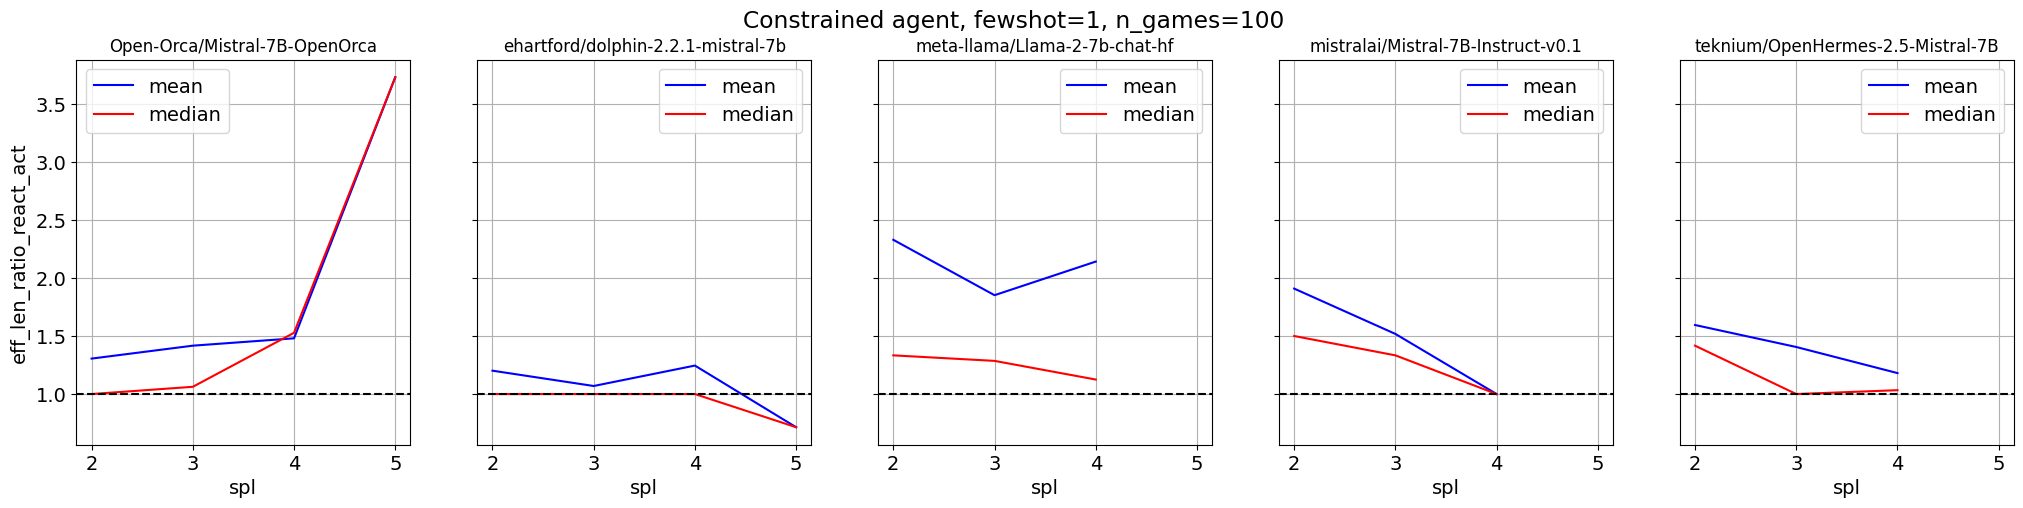

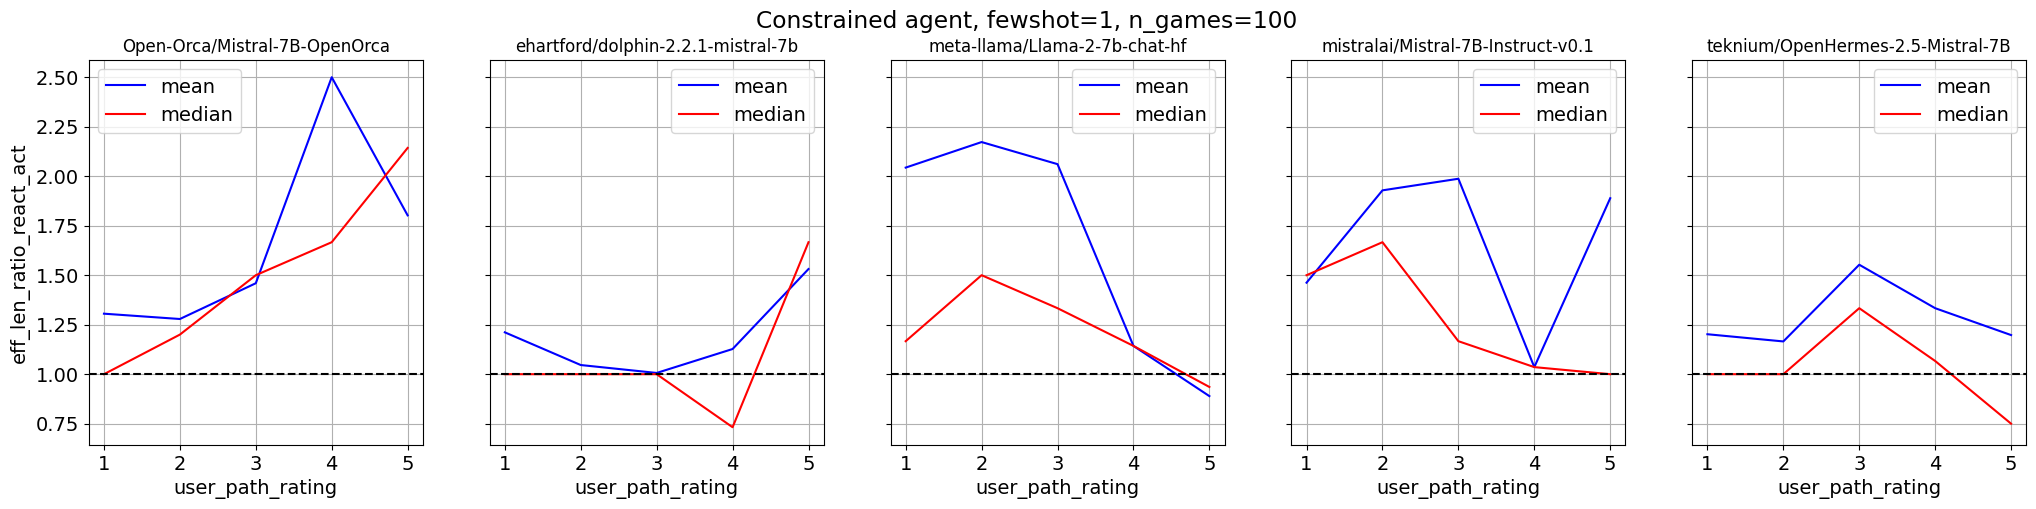

prompting                          eff_len_ratio_react_act          
                                                      mean    median
model.model_name                                                    
Open-Orca/Mistral-7B-OpenOrca                     1.546131  1.200000
ehartford/dolphin-2.2.1-mistral-7b                1.168963  1.000000
meta-llama/Llama-2-7b-chat-hf                     2.003206  1.166667
mistralai/Mistral-7B-Instruct-v0.1                1.637680  1.333333
teknium/OpenHermes-2.5-Mistral-7B                 1.358039  1.000000

In [36]:
# create a new df with the columns effective_path_act and effective_path_react for each src-tgt pair
df_act_vs_react = all_runs_df[all_runs_df['agent.fewshot']==1].query('success==1')

# column 'game_finished_react_and_act' indicates if the game (aka src,tgt pair) was finished by both Act and ReAct, for each model
df_act_vs_react['game_finished_react_and_act'] = df_act_vs_react.groupby(['src','tgt','model.model_name'])['prompting'].transform(lambda x: len(x)==2)

# eliminate games that were not finished by both Act and ReAct
df_act_vs_react = df_act_vs_react[df_act_vs_react['game_finished_react_and_act']==True]


df_act_vs_react = df_act_vs_react.groupby(['model.model_name', 'src','tgt','prompting']).agg({'effective_path_len':'mean'}).reset_index()
df_act_vs_react = df_act_vs_react.pivot_table(index=['model.model_name', 'src','tgt'], columns='prompting', values='effective_path_len').reset_index()

# get user_path_rating from all_runs_df
df_act_vs_react['spl'] = df_act_vs_react.apply(lambda x: all_runs_df[(all_runs_df['src']==x['src']) & (all_runs_df['tgt']==x['tgt'])]['spl'].iloc[0], axis=1)
df_act_vs_react['user_path_rating'] = df_act_vs_react.apply(lambda x: all_runs_df[(all_runs_df['src']==x['src']) & (all_runs_df['tgt']==x['tgt'])]['user_path_rating'].iloc[0], axis=1)

# what was the relative reduction in effective path length
df_act_vs_react['eff_len_ratio_react_act'] = df_act_vs_react['ReAct'] / df_act_vs_react['Act']

# describe for each model the difference between Act and ReAct, including median
df_describe = df_act_vs_react.groupby(['model.model_name']).agg({'eff_len_ratio_react_act':['mean','median']})
df_describe_user_path_rating = df_act_vs_react.groupby(['model.model_name','user_path_rating']).agg({'eff_len_ratio_react_act':['mean','median']})
df_describe_spl = df_act_vs_react.groupby(['model.model_name','spl']).agg({'eff_len_ratio_react_act':['mean','median']})

# make line plot of eff_len_ratio_react_act for each model, mean and median values, use spl as x-axis
fig, axes = plt.subplots(1, len(df_act_vs_react['model.model_name'].unique()), figsize=(5*len(df_act_vs_react['model.model_name'].unique()),5), sharey=True, sharex=True)
for i,model in enumerate(df_act_vs_react['model.model_name'].unique()):
    df = df_describe_spl.loc[model]
    axes[i].plot(df.index, df['eff_len_ratio_react_act']['mean'], label='mean', color='blue')
    axes[i].plot(df.index, df['eff_len_ratio_react_act']['median'], label='median', color='red')
    # set solid line at y=1
    axes[i].axhline(y=1, color='black', linestyle='--')
    # use y grid
    axes[i].grid(True)
    axes[i].set_title(model, fontsize=12); axes[i].set_xlabel('spl')
    if i == 0:
        axes[i].set_ylabel('eff_len_ratio_react_act')
    axes[i].legend()
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()

# make line plot of eff_len_ratio_react_act for each model, mean and median values, use user_path_rating as x-axis
fig, axes = plt.subplots(1, len(df_act_vs_react['model.model_name'].unique()), figsize=(5*len(df_act_vs_react['model.model_name'].unique()),5), sharey=True, sharex=True)
for i,model in enumerate(df_act_vs_react['model.model_name'].unique()):
    df = df_describe_user_path_rating.loc[model]
    axes[i].plot(df.index, df['eff_len_ratio_react_act']['mean'], label='mean', color='blue')
    axes[i].plot(df.index, df['eff_len_ratio_react_act']['median'], label='median', color='red')
    axes[i].axhline(y=1, color='black', linestyle='--')
    # use y grid
    axes[i].grid(True)
    axes[i].set_title(model, fontsize=12); axes[i].set_xlabel('user_path_rating')
    if i == 0:
        axes[i].set_ylabel('eff_len_ratio_react_act')
    axes[i].legend()
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()

df_describe


In [26]:
all_runs_df[
    (all_runs_df['agent.fewshot']==1) & 
    (all_runs_df['model.model_name']=='Open-Orca/Mistral-7B-OpenOrca') & 
    (all_runs_df['spl']==5) &
    (all_runs_df['success']==1)
][['src', 'tgt', 'effective_path_len', 'effective_path_so_far', 'prompting']]

,src,tgt,effective_path_len,effective_path_so_far,prompting
3449,Hammurabi,Tropical_Storm_Harvey_(2005),26,"Hammurabi;Mesopotamia;Iraq;Climate;Tropical_cyclone;Tropics;Temperate;Weather;Meteorology;North_America;Hudson_Bay;Canada;2005_Kashmir_earthquake;Earthquake;Tsunami;Tide;Ocean;Organism;Ecology;Natural_disaster;Tropical_Storm_Allison;United_States;Houston,_Texas;Galveston_Hurricane_of_1900;Hurricane_Katrina;2005_Atlantic_hurricane_season",ReAct
3453,Indus_Valley_Civilization,Pikachu,25,Indus_Valley_Civilization;Indus_River;Bird;Pigeon;Animal;Precambrian;Cambrian_explosion;Mammal;Pelycosaur;Scientific_classification;Arthropod;Insect;Invertebrate;Chordate;Vertebrate;Reptile;Dinosaur;Fiction;Computer_and_video_games;Nintendo_Entertainment_System;Nintendo;Super_Mario_Bros.;Japan;Mario;Sonic_the_Hedgehog_(character),ReAct
53737,Hammurabi,Tropical_Storm_Harvey_(2005),6,Hammurabi;Civilization;House;Natural_disaster;Hurricane_Katrina;2005_Atlantic_hurricane_season,Act
53876,Indus_Valley_Civilization,Pikachu,8,Indus_Valley_Civilization;Culture;Japan;Nintendo;PONG;Television;Computer_and_video_games;Pac-Man,Act


In [37]:
# Look at specific games for each model, and compare Act vs ReAct prompting
print(all_runs_df.columns)
# constants
src='Vampire'
tgt='Anglicanism'
fewshot=1

print(f"Game: {src} -> {tgt}")
print(f"Fewshot: {fewshot}\n\n")

df = all_runs_df[
    (all_runs_df['agent.fewshot']==fewshot) &
    (all_runs_df['src']==src) &
    (all_runs_df['tgt']==tgt)
]

# overall stats for this game, for each mode, comparing Act vs ReAct prompting
for model in df['model.model_name'].unique():
    print("\n---------- Model: ", model, "----------")
    df_model = df[df['model.model_name']==model].query('is_finished==True')
    df_model_act = df_model[df_model['prompting']=='Act']
    df_model_react = df_model[df_model['prompting']=='ReAct']
    print("Act:")
    print("total path: ", df_model_act['path_so_far'].iloc[0])
    print("\t path_len: ", df_model_act['path_len'].iloc[0])
    print("\t diff_from_best_human: ", df_model_act['diff_from_best_human'].iloc[0])
    print("effective path: ", df_model_act['effective_path_so_far'].iloc[0])
    print("\t effective_path_len: ", df_model_act['effective_path_len'].iloc[0])
    print("\t diff_from_spl: ", df_model_act['effective_diff_from_spl'].iloc[0])
    print("\t diff_from_shepl: ", df_model_act['effective_diff_from_shepl'].iloc[0])

    print("\nReAct:")
    print("total path: ", df_model_react['path_so_far'].iloc[0])
    print("\t path_len: ", df_model_react['path_len'].iloc[0])
    print("\t diff_from_best_human: ", df_model_react['diff_from_best_human'].iloc[0])
    print("effective path: ", df_model_react['effective_path_so_far'].iloc[0])
    print("\t effective_path_len: ", df_model_react['effective_path_len'].iloc[0])
    print("\t diff_from_spl: ", df_model_react['effective_diff_from_spl'].iloc[0])
    print("\t diff_from_shepl: ", df_model_react['effective_diff_from_shepl'].iloc[0])

    print("-----------------------------------\n")
    
#look at only the first move made by each of the models, compare Act vs ReAct
for model in df['model.model_name'].unique():
    print("\n---------- Model: ", model, "----------")
    df_model = df[df['model.model_name']==model]
    df_model_act = df_model[df_model['prompting']=='Act']
    df_model_react = df_model[df_model['prompting']=='ReAct']
    #look at only the first move made by each of the models, compare Act vs ReAct
    print("First move:")
    print("\tAct response: ", df_model_act.query('num_actions==1')['response'].iloc[0])
    print("\tReAct response: ", df_model_react.query('num_actions==1')['response'].iloc[0])
    print('\n')



Index(['agent_name', 'agent_type', 'cur', 'src', 'tgt', 'response', 'action',
       'num_actions', 'num_tries', 'num_errors', 'is_finished',
       'is_finished_reason', 'path_so_far', 'user_prompt', 'hpl', 'path',
       'user_path_rating', 'spl', 'shepl', 'path_len', 'effective_path_so_far',
       'effective_path_len', 'diff_from_best_human', 'effective_diff_from_spl',
       'effective_diff_from_shepl', 'success', 'model.model_name',
       'agent.fewshot', 'agent.agent_name', 'run_id', 'prompting', 'agent_id'],
      dtype='object')
Game: Vampire -> Anglicanism
Fewshot: 1



---------- Model:  teknium/OpenHermes-2.5-Mistral-7B ----------
Act:
total path:  Vampire;England
	 path_len:  2
	 diff_from_best_human:  0.0
effective path:  Vampire;England
	 effective_path_len:  2
	 diff_from_spl:  0.0
	 diff_from_shepl:  0.0

ReAct:
total path:  Vampire;England
	 path_len:  2
	 diff_from_best_human:  0.0
effective path:  Vampire;England
	 effective_path_len:  2
	 diff_from_spl:  0.0
	 dif

In [18]:
all_runs_df.query('is_finished==True')[['src','tgt','is_finished_reason', 'user_path_rating']]

,src,tgt,is_finished_reason,user_path_rating
15,Blade_Runner,Newspaper,success,NaN
29,Vampire,Anglicanism,success,1.0
57,Greece,Winston_Churchill,success,NaN
71,Order_of_the_Thistle,City_status_in_the_United_Kingdom,success,NaN
92,Desert,Tobacco,success,1.0
...,...,...,...,...
71551,Missouri_River,Isospin,max_actions,NaN
71554,Gas_tungsten_arc_welding,War_of_the_League_of_Cambrai,max_actions,NaN
71555,William_IV_of_the_United_Kingdom,Senegal,max_actions,1.0
71563,Somalia,Henry_III_of_England,max_actions,3.0


<Axes: >

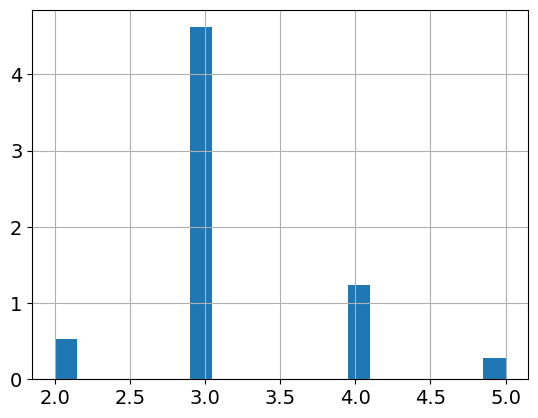

In [13]:
all_runs_df[all_runs_df['model.model_name']=='mistralai/Mistral-7B-Instruct-v0.1']['spl'].hist(bins=20, density=True))
# .query("`agent.fewshot`==1 and success == 1").sort_values(by='effective_diff_from_spl', ascending=True).head(10)

In [3]:
# Error types:
# - "Try a different page" = PageNotInCands
# - "Cannot go back any further" = BackOnFirstPage
# - else = BadResponse
for run in runs:
    print("\nRun config:")
    for key in run.keys():
        if key != 'df':
            print(f"\t{key} = {run[key]}")
    run_df = run['df']
    # add columns
    run_df = run_df.merge(shpl_paths_real_df, on=['src', 'tgt'], how='left')
    run_df['error_type'] = run_df['action'].apply(lambda x:
                                                "no_error" if "{'next_page'" in x else
                                                "PageNotInCands" if "Try a different page" in x else
                                                "BackOnFirstPage" if "Cannot go back any further" in x else
                                                "BadResponse")
    run_df['path_len'] = run_df['path_so_far'].apply(lambda x: len(x.split(';'))) #should be -1 but we automatically click on final page
    run_df['effective_path_len'] = run_df['path_so_far'].apply(lambda x: len(effective_path(x).split(';')))
    run_df['diff_from_best_human'] = run_df['path_len'] - run_df['hpl']
    run_df['success'] = run_df['is_finished_reason'].apply(lambda x: 1 if x=='success' else 0)

    num_runs = len(run_df.query('is_finished==True')) + 1e-10
    num_errors = run_df.query('is_finished==True')['num_errors'].sum() + 1e-10
    num_actions = run_df.query('is_finished==True')['num_actions'].sum()

    run['df'] = run_df
    
    print("Total number of runs:", int(num_runs))
    print("% of successful runs:", round(len(run_df.query('is_finished_reason=="success"'))/num_runs*100, 1))
    print("Number of back clicks:", run_df.apply(lambda x: x['action'] == "{'next_page': 'NA'}", axis=1).sum())

    print("Statistics on path length (successful runs):")
    print("\tMean:", round(run_df.query('is_finished==True and is_finished_reason=="success"')['path_len'].mean(), 1))
    print("\tMedian:", round(run_df.query('is_finished==True and is_finished_reason=="success"')['path_len'].median(), 1))
    print("\tMin:", run_df.query('is_finished==True and is_finished_reason=="success"')['path_len'].min())
    print("\tMax:", run_df.query('is_finished==True and is_finished_reason=="success"')['path_len'].max())

    print("Statistics on effective path length (successful runs):")
    print("\tMean:", round(run_df.query('is_finished==True and is_finished_reason=="success"')['effective_path_len'].mean(), 1))
    print("\tMedian:", round(run_df.query('is_finished==True and is_finished_reason=="success"')['effective_path_len'].median(), 1))
    print("\tMin:", run_df.query('is_finished==True and is_finished_reason=="success"')['effective_path_len'].min())
    print("\tMax:", run_df.query('is_finished==True and is_finished_reason=="success"')['effective_path_len'].max())

    print("Statistics on difference from best human path (successful runs AND there's a human finished path):")
    print("\tMean:", round(run_df.query('is_finished==True and is_finished_reason=="success" and hpl.notnull()')['diff_from_best_human'].mean(), 1))
    print("\tMedian:", round(run_df.query('is_finished==True and is_finished_reason=="success" and hpl.notnull()')['diff_from_best_human'].median(), 1))
    print("\tMin:", run_df.query('is_finished==True and is_finished_reason=="success" and hpl.notnull()')['diff_from_best_human'].min())
    print("\tMax:", run_df.query('is_finished==True and is_finished_reason=="success" and hpl.notnull()')['diff_from_best_human'].max())


    print("% of failed runs because of max_tries (too many errors):", round(len(run_df.query('is_finished_reason=="max_tries"'))/num_runs*100, 1))
    print("% of failed runs because of max_actions (too many actions):", round(len(run_df.query('is_finished_reason=="max_actions"'))/num_runs*100, 1))
    print("% of error actions:", round(run_df.query('is_finished==True')['num_errors'].sum()/run_df.query('is_finished==True')['num_actions'].sum()*100, 1))
    print("\tFrom which:")
    print("\t% of PageNotInCands:", round(len(run_df.query('error_type=="PageNotInCands"'))/num_errors*100, 1))
    print("\t% of BackOnFirstPage:", round(len(run_df.query('error_type=="BackOnFirstPage"'))/num_errors*100, 1))
    print("\t% of BadResponse:", round(len(run_df.query('error_type=="BadResponse"'))/num_errors*100, 1))
    


Run config:
	model.temperature = 0.1
	run_id = 1
Total number of runs: 100
% of successful runs: 53.0
Number of back clicks: 0
Statistics on path length (successful runs):
	Mean: 12.2
	Median: 10.0
	Min: 2
	Max: 39
Statistics on effective path length (successful runs):
	Mean: 12.2
	Median: 10.0
	Min: 2
	Max: 39
Statistics on difference from best human path (successful runs AND there's a human finished path):
	Mean: 7.1
	Median: 4.5
	Min: -6.0
	Max: 27.0
% of failed runs because of max_tries (too many errors): 7.0
% of failed runs because of max_actions (too many actions): 40.0
% of error actions: 29.1
	From which:
	% of PageNotInCands: 99.6
	% of BackOnFirstPage: 0.0
	% of BadResponse: 0.4

Run config:
	model.temperature = 0.25
	run_id = 6
Total number of runs: 100
% of successful runs: 50.0
Number of back clicks: 0
Statistics on path length (successful runs):
	Mean: 13.7
	Median: 9.5
	Min: 2
	Max: 39
Statistics on effective path length (successful runs):
	Mean: 13.7
	Median: 9.5
	Min

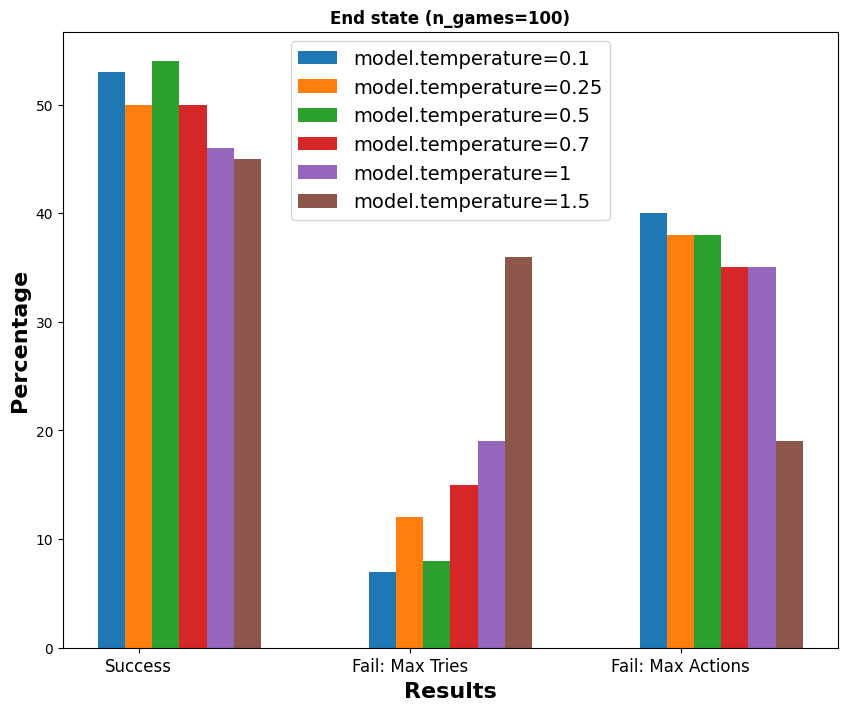

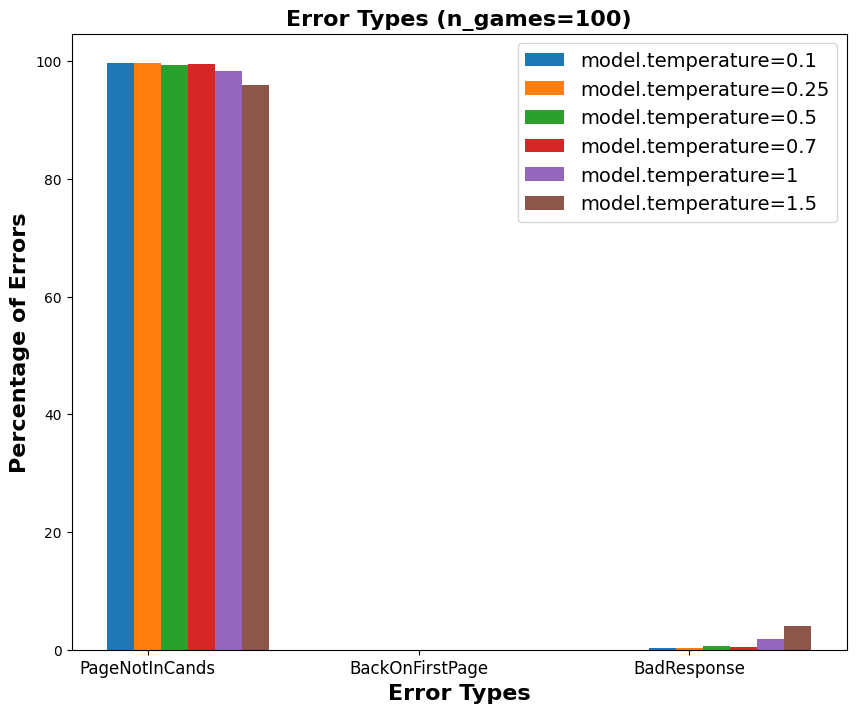

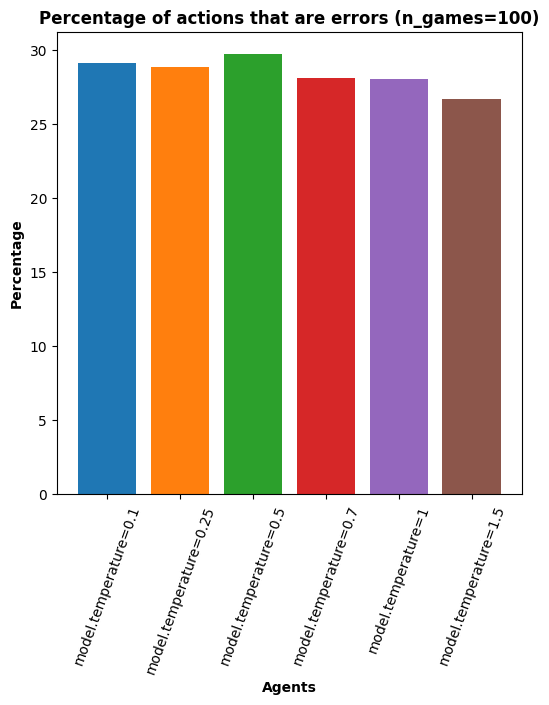

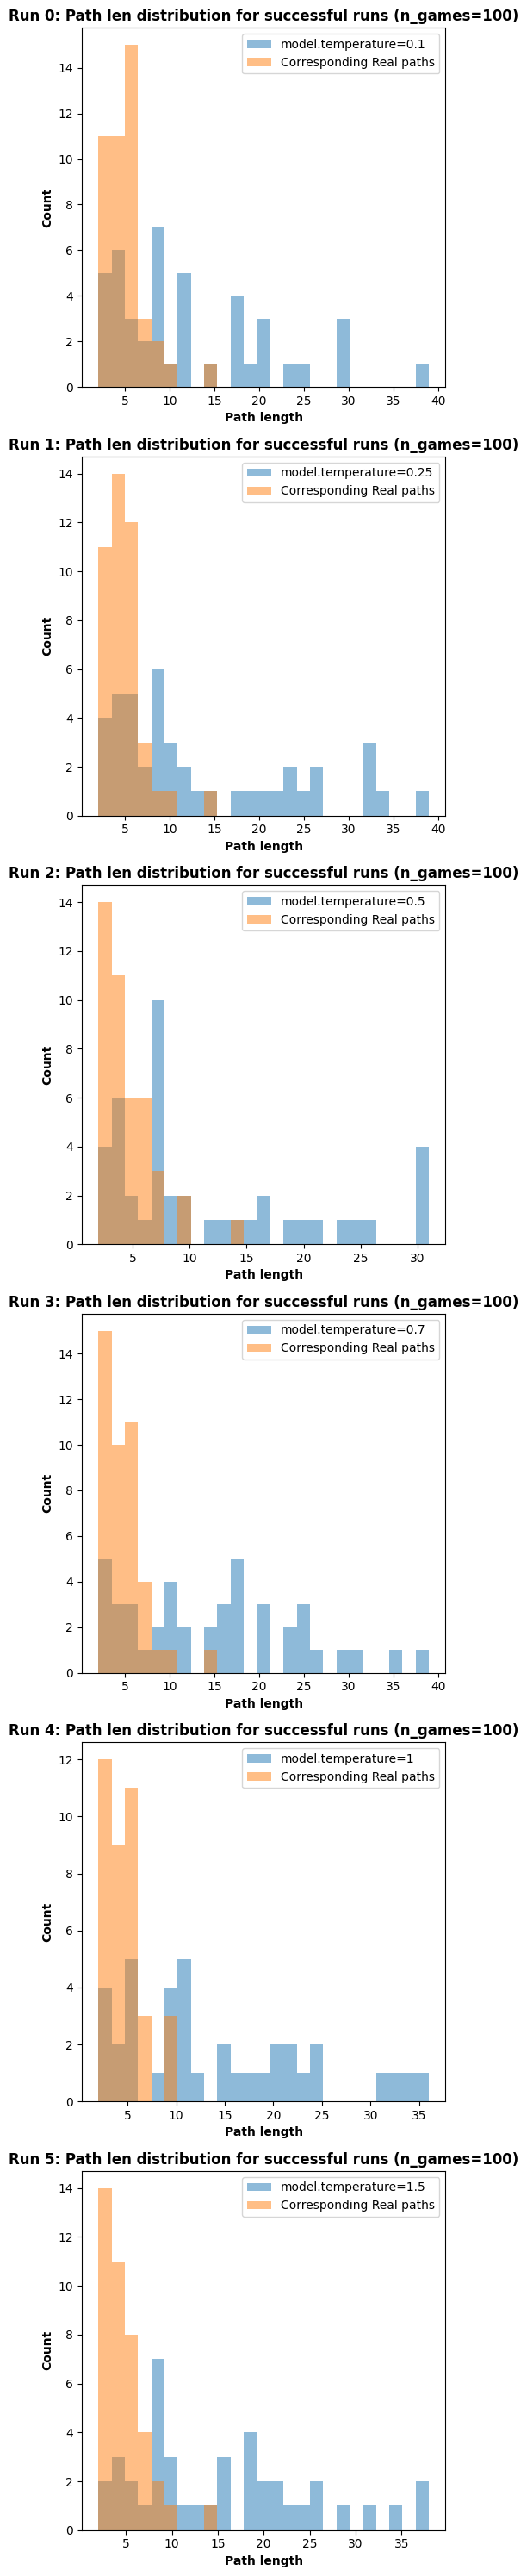

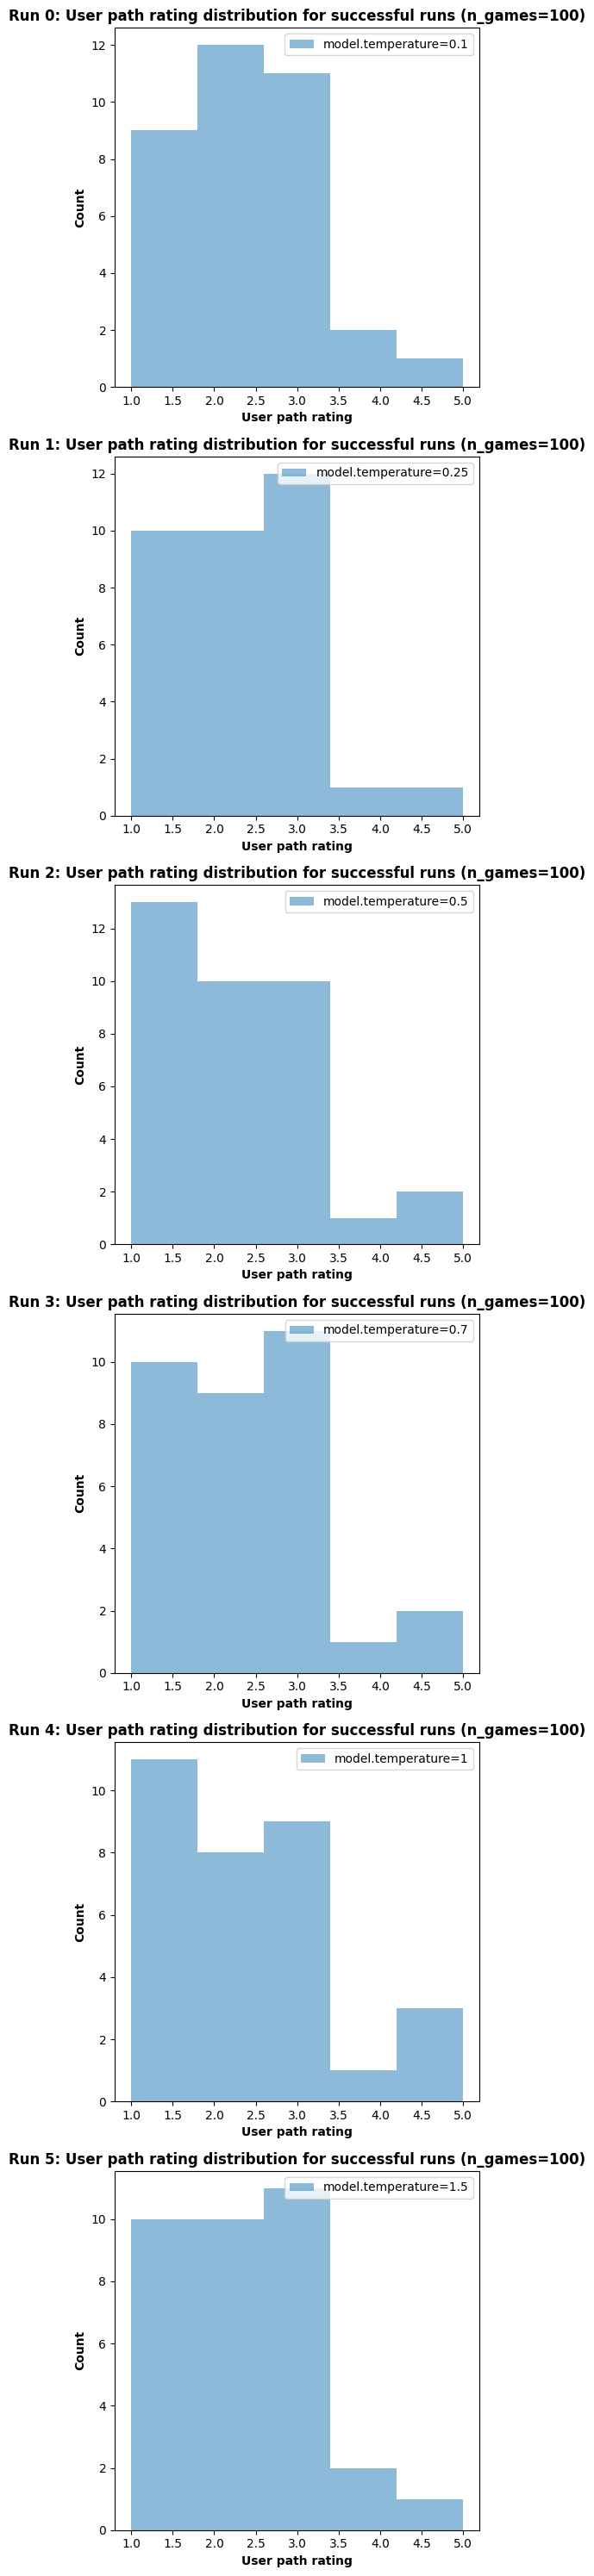

In [14]:
## For experiments with 1 identifier ##

import matplotlib.pyplot as plt
import numpy as np

# Number of runs
n_runs = len(runs)

# Lists for accumulating results and error types
successful_runs = []
max_tries_runs = []
max_actions_runs = []
num_errors_runs = []
percentage_of_back_clicks = []
successful_path_length={"vals":[], "stds":[]}

page_not_in_cands_errors = []
back_on_first_page_errors = []
bad_response_errors = []

for run in runs:
    run_df = run['df']
    num_runs = len(run_df.query('is_finished==True'))
    num_actions = run_df.query('is_finished==True')['num_actions'].sum()
    num_errors = run_df.query('is_finished==True')['num_errors'].sum()

    # Accumulate data for each run
    successful_runs.append(len(run_df.query('is_finished_reason=="success"'))/num_runs*100)
    max_tries_runs.append(len(run_df.query('is_finished_reason=="max_tries"'))/num_runs*100)
    max_actions_runs.append(len(run_df.query('is_finished_reason=="max_actions"'))/num_runs*100)
    percentage_of_back_clicks.append(run_df.apply(lambda x: x['action'] == "{'next_page': 'NA'}", axis=1).sum()/num_actions*100)
    successful_path_length["vals"].append(run_df.query('is_finished_reason=="success"')['path_len'].median())
    successful_path_length["stds"].append(run_df.query('is_finished_reason=="success"')['path_len'].std())
    
    num_errors_runs.append(num_errors/num_actions*100)
    page_not_in_cands_errors.append(len(run_df.query('error_type=="PageNotInCands"'))/num_errors*100)
    back_on_first_page_errors.append(len(run_df.query('error_type=="BackOnFirstPage"'))/num_errors*100)
    bad_response_errors.append(len(run_df.query('error_type=="BadResponse"'))/num_errors*100)

# run_name_to_label = {"constr_fewshot_exper": "Fixed demos sorted by performance", "constr_temp_fewshot": "Fixed demos in original order", "constr_fewshot_random_demos": "Random demos"}
# run_name_to_line_style = {"constr_fewshot_exper": "-", "constr_temp_fewshot": "--", "constr_fewshot_random_demos": "-."}
# # Line plot of identifier vs success rate
# plt.figure(figsize=(6,6))
# for run_name in ['constr_fewshot_exper', 'constr_temp_fewshot', 'constr_fewshot_random_demos']:
#     runs_subset = [run for run in runs if run['run_name']==run_name]
#     successful_runs_subset = [successful_runs[i] for i in range(len(runs)) if runs[i]['run_name']==run_name]
#     plt.plot([run['agent.fewshot'] for run in runs_subset], successful_runs_subset, label=run_name_to_label[run_name], linestyle=run_name_to_line_style[run_name])
# plt.grid(axis='y', alpha=0.75)
# plt.xlabel('agent.fewshot', fontweight='bold')
# plt.ylabel('Success rate', fontweight='bold')
# plt.legend()
# #choose high dpi to make the plot clearer
# plt.savefig('success_rate.png', dpi=300)
# plt.show()

# # plot of identifier vs number of back clicks
# plt.figure(figsize=(6,6))
# plt.plot([run[identifier] for run in runs], percentage_of_back_clicks)
# plt.xlabel(identifier, fontweight='bold')
# plt.ylabel('Percentage of back clicks', fontweight='bold')
# plt.legend()
# plt.show()


# # plot path length for successful runs vs identifier, where the values are the mean and the error bars are the std
# plt.figure(figsize=(6,6))
# plt.errorbar([run[identifier] for run in runs], successful_path_length["vals"], yerr=successful_path_length["stds"], fmt='o')
# plt.xlabel(identifier, fontweight='bold')
# plt.ylabel('Median Path length', fontweight='bold')

# plt.legend()
# plt.show()

bar_width = 0.1
r = np.arange(3)  # For three categories: 'success', 'max_tries', 'max_actions'
r_errors = np.arange(3)  # For three error types

# Plot for run results
plt.figure(figsize=(10,8))
for i in range(n_runs):
    offsets = [j+(bar_width*i) for j in r]
    plt.bar(offsets, [successful_runs[i], max_tries_runs[i], max_actions_runs[i]], width=bar_width, label=f"{identifier}={runs[i][identifier]}")

plt.xlabel('Results', fontweight='bold', fontsize=16)
plt.ylabel('Percentage', fontweight='bold', fontsize=16)
plt.xticks([r + bar_width for r in range(3)], ['Success', 'Fail: Max Tries', 'Fail: Max Actions'], fontsize=12)
# plt.xticks([r + bar_width for r in range(3)], ['Success'])
plt.title('End state (n_games=100)', fontweight='bold')
plt.legend(fontsize=14)
plt.show()

# Plot for error types
plt.figure(figsize=(10,8))
for i in range(n_runs):
    offsets = [j+(bar_width*i) for j in r_errors]
    plt.bar(offsets, [page_not_in_cands_errors[i], back_on_first_page_errors[i], bad_response_errors[i]], width=bar_width, label=f"{identifier}={runs[i][identifier]}")

plt.xlabel('Error Types', fontweight='bold', fontsize=16)
plt.ylabel('Percentage of Errors', fontweight='bold', fontsize=16)
# use a logy scale
plt.xticks([r + bar_width for r in range(3)], ['PageNotInCands', 'BackOnFirstPage', 'BadResponse'], fontsize=12)
plt.title('Error Types (n_games=100)', fontweight='bold', fontsize=16)
plt.legend(fontsize=14)
plt.savefig('error_types.png', dpi=300)
plt.show()

# Plot for number of errors
plt.figure(figsize=(6,6))
for i in range(n_runs):
    plt.bar(i, num_errors_runs[i], label=f"{identifier}={runs[i][identifier]}")

plt.xlabel('Agents', fontweight='bold')
plt.ylabel('Percentage', fontweight='bold')
plt.xticks([r for r in range(n_runs)], [f"{identifier}={runs[i][identifier]}" for i in range(n_runs)], rotation=70)
plt.title('Percentage of actions that are errors (n_games=100)', fontweight='bold')

# Plot path_len distribution for run 0 and 1 and real_paths for successful runs
n_runs = len(runs)
fig, axes = plt.subplots(n_runs, 1, figsize=(5, 5 * n_runs))  # Creates a column of subplots, one for each run
for i in range(n_runs):
    query_result = runs[i]['df'].query('is_finished==True and is_finished_reason=="success" and hpl.notnull()')
    
    _, bins, _ = axes[i].hist(query_result['path_len'], bins=25, alpha=0.5, label=f"{identifier}={runs[i][identifier]}")
    axes[i].hist(query_result['hpl'].astype(int), bins=bins, alpha=0.5, label=f"Corresponding Real paths")
    
    axes[i].set_xlabel('Path length', fontweight='bold')
    axes[i].set_ylabel('Count', fontweight='bold')
    axes[i].set_title(f'Run {i}: Path len distribution for successful runs (n_games=100)', fontweight='bold')
    axes[i].legend()
plt.tight_layout()
plt.show()

# Plot distribution of user_path_rating for successful runs
n_runs = len(runs)
fig, axes = plt.subplots(n_runs, 1, figsize=(5, 5 * n_runs))  
for i in range(n_runs):
    query_result = runs[i]['df'].query('is_finished==True and is_finished_reason=="success" and hpl.notnull()')
    
    axes[i].hist(query_result['user_path_rating'], bins=5, alpha=0.5, label=f"{identifier}={runs[i][identifier]}")
    
    axes[i].set_xlabel('User path rating', fontweight='bold')
    axes[i].set_ylabel('Count', fontweight='bold')
    axes[i].set_title(f'Run {i}: User path rating distribution for successful runs (n_games=100)', fontweight='bold')
    axes[i].legend()
plt.tight_layout()
plt.show()




In [3]:
## For experiments with 2 identifiers ##
# Assuming you have lists of unique fewshot values and temperature values
fewshot_values = sorted(set(run['agent.fewshot'] for run in runs))
temperature_values = sorted(set(run['model.temperature'] for run in runs))

# Initialize your matrices
success_rate_matrix = {"val":np.zeros((len(fewshot_values), len(temperature_values))), "error":np.zeros((len(fewshot_values), len(temperature_values)))}
mean_path_len_matrix = {"val":np.zeros_like(success_rate_matrix['val']), "error":np.zeros_like(success_rate_matrix['val'])}
error_percentage_matrix ={"val": np.zeros_like(success_rate_matrix['val']), "error": np.zeros_like(success_rate_matrix['val'])}
page_not_in_cands_errors_matrix = {"val":np.zeros_like(success_rate_matrix['val']), "error":np.zeros_like(success_rate_matrix['val'])}
backtrack_action_matrix = {"val":np.zeros_like(success_rate_matrix['val']), "error":np.zeros_like(success_rate_matrix['val'])}
diff_from_best_human_matrix ={"val": np.zeros_like(success_rate_matrix['val']), "error": np.zeros_like(success_rate_matrix['val'])}

# Populate the matrices with data from your runs
for run in runs:
    fewshot_index = fewshot_values.index(run['agent.fewshot'])
    temperature_index = temperature_values.index(run['model.temperature'])
    
    run_df = run['df']
    num_runs = len(run_df.query("is_finished==True"))
    num_errors = run_df.query("is_finished==True")['num_errors'].sum()
    num_actions = run_df.query("is_finished==True")['num_actions'].sum()


    # Compute statistics and store them in the matrices
    success_rate_matrix['val'][fewshot_index][temperature_index]=run_df.query('is_finished==True')['success'].mean(); success_rate_matrix['error'][fewshot_index][temperature_index]=2*run_df.query('is_finished==True')['success'].sem()
    mean_path_len_matrix['val'][fewshot_index][temperature_index]=run_df[run_df.success==1]['path_len'].mean(); mean_path_len_matrix['error'][fewshot_index][temperature_index]=2*run_df[run_df.success==1]['path_len'].sem()
    error_percentage_matrix['val'][fewshot_index][temperature_index]=run_df.apply(lambda x: 'error_type'!= 'no_error', axis=1).mean(); error_percentage_matrix['error'][fewshot_index][temperature_index]=2*run_df.apply(lambda x: 'error_type'!= 'no_error', axis=1).sem()
    page_not_in_cands_errors_matrix['val'][fewshot_index][temperature_index]=run_df.apply(lambda x: x['error_type'] == 'PageNotInCands', axis=1).mean(); page_not_in_cands_errors_matrix['error'][fewshot_index][temperature_index]=2*run_df.apply(lambda x: x['error_type'] == 'PageNotInCands', axis=1).sem()
    backtrack_action_matrix['val'][fewshot_index][temperature_index]=run_df.apply(lambda x: x['action'] == "{'next_page': 'NA'}", axis=1).mean(); backtrack_action_matrix['error'][fewshot_index][temperature_index]=2*run_df.apply(lambda x: x['action'] == "{'next_page': 'NA'}", axis=1).sem()
    diff_from_best_human_matrix['val'][fewshot_index][temperature_index] = run_df[run_df.success==1].apply(lambda x: x['diff_from_best_human'] <= 0, axis=1).mean(); diff_from_best_human_matrix['error'][fewshot_index][temperature_index] = 2*run_df[run_df.success==1].apply(lambda x: x['diff_from_best_human'] <= 0, axis=1).sem()


def make_line_plots(matrix, row_labels, col_labels, title, figsize=(8, 6)):
    fig, ax = plt.subplots(figsize=figsize)
    for j, label in enumerate(col_labels):
        ax.errorbar(row_labels, matrix['val'][:, j], yerr=matrix['error'][:, j], label=f"Temperature={label}")

    ax.set_xlabel('Agent Fewshot')
    ax.set_ylabel('Score')
    ax.set_xticks(row_labels)
    ax.set_title(title)
    ax.legend()
    plt.show()

make_line_plots(success_rate_matrix, fewshot_values, temperature_values, 'Success Rate (n_games=100)')
make_line_plots(mean_path_len_matrix, fewshot_values, temperature_values, 'Mean Path Length for Successful games (n_games=100)')
make_line_plots(error_percentage_matrix, fewshot_values, temperature_values, 'total_errors/total_actions (n_games=100)')
make_line_plots(page_not_in_cands_errors_matrix, fewshot_values, temperature_values, 'page_not_in_cands/total_errors (n_games=100)')
make_line_plots(backtrack_action_matrix, fewshot_values, temperature_values, 'Number of Backtrack Actions (n_games=100)')
make_line_plots(diff_from_best_human_matrix, fewshot_values, temperature_values, 'Number of times Agent beats or equals best human (n_games=100)')


NameError: name 'runs' is not defined

In [39]:
runs[23]['df'].query('error_type=="PageNotInCands"')

,agent_id,agent_type,cur,src,tgt,response,action,num_actions,num_tries,num_errors,...,path_so_far,user_prompt,hpl,path,user_path_rating,error_type,path_len,effective_path_len,diff_from_best_human,success
1585,37,LMQLLinkClickDFSAgent,Israel,John_Calvin,George_I_of_Great_Britain,{'next_page': 'Georgia_(country)$'},Link Georgia_(country)$ not on current page. Try a different page.,18,1,1,...,John_Calvin;Geneva;Frankenstein;Glacier;India;Gautama_Buddha;Buddhism;Abbasid;Iran;Iraq;Islam;Muhammad;Mecca;Damascus;Paul_of_Tarsus;Jesus;Jordan_River;Israel,"{""source"": ""Israel"", ""target"": ""George_I_of_Great_Britain"", ""links"": ""Afghanistan;Africa;Albania;Algeria;Arab-Israeli_conflict;Arabic_language;Argentina;Ariel_Sharon;Armenia;Asia;Assyria;Athletics_(track_and_field);Australia;Azerbaijan;Babylonia;Bahrain;Bangladesh;Basketball;Beirut;Bhutan;Bosnia_and_Herzegovina;Brunei;Buenos_Aires;Byzantine_Empire;Cambodia;Canada;Capital;Chemistry;Chess;Christmas_Island;Coal;Cocos_(Keeling)_Islands;Cold_War;Comoros;Country;Croatia;Currency;Cyprus;Dead_Sea;Democracy;Djibouti;Dutch_language;East_Timor;Egypt;Electronics;Engineering;English_language;Eritrea;Ethiopia;Europe;Folk_music;Football_(soccer);France;French_language;Gaza_Strip;Genetics;Georgia_(country);German_language;Greece;Hebrew_language;Hellenistic_Greece;Hip_hop_music;Indian_Ocean;Indonesia;Italy;Japan;Jerusalem;Jew;Jordan;Judaism;Kazakhstan;Kenya;Kuwait;Kyrgyzstan;Laos;League_of_Nations;Lebanon;Liberal_democracy;Libya;List_of_countries;List_of_countries_by_system_of_government;Literacy;L...",8.0,John_Calvin;Switzerland;Germany;European_Union;United_Kingdom;Great_Britain;James_I_of_England;British_monarchy;George_I_of_Great_Britain,NaN,PageNotInCands,18,18,10.0,0


In [22]:
run_df = runs[0]['df']
print(round(len(run_df.query('is_finished_reason=="success" and diff_from_best_human <= 0'))/ len(run_df.query('is_finished_reason=="success" and hpl.notnull()'))*100, 1))
run_df.query('is_finished_reason=="success" and hpl.notnull()')

32.0


,agent_id,agent_type,cur,src,tgt,response,action,num_actions,num_tries,num_errors,...,is_finished_reason,path_so_far,user_prompt,hpl,path,user_path_rating,error_type,path_len,effective_path_len,diff_from_best_human
13,13,LinkClickDFSAgent,Adolf_Hitler,Greece,Winston_Churchill,"{""next_page"": ""Adolf_Hitler""}",{'next_page': 'Adolf_Hitler'},1,0,0,...,success,Greece;Adolf_Hitler,"{""source"": ""Greece"", ""target"": ""Winston_Churchill"", ""links"": ""Adolf_Hitler;Africa;Albania;Algeria;Ancient_Greece;Andorra;Argentina;Aristotle;Armenia;Asia;Athena;Athens;Austria;Azerbaijan;Belarus;Belgium;Bosnia_and_Herzegovina;Bulgaria;Byzantine_Empire;Climate;Croatia;Currency;Cyprus;Czech_Republic;Democracy;Denmark;Drama;Egypt;Estonia;Euro;Europe;European_Space_Agency;European_Union;Fascism;Finland;France;Georgia_(country);Germany;Ghana;Hellenistic_Greece;Herodotus;Homer;Hungary;Iceland;Ireland;Israel;Italy;Japan;Jew;Kazakhstan;Latvia;Lebanon;Libya;Liechtenstein;List_of_countries;List_of_countries_by_system_of_government;Lithuania;Luxembourg;Macedon;Malta;Marshall_Plan;Mediterranean_Sea;Middle_East;Moldova;Monaco;Monarchy;Montenegro;Morocco;NATO;Netherlands;Norway;Olympic_Games;Ottoman_Empire;Owl;Parthenon;People's_Republic_of_China;Peru;Philosophy;Plato;Poland;Political_science;Portugal;Pythagoras;Qatar;Republic_of_Ireland;Republic_of_Macedonia;Republic_of_the_Congo;Roman_Greece;R...",3.0,Greece;United_Kingdom;World_War_II;Winston_Churchill,NaN,no_error,2,2,-1.0
20,20,LinkClickDFSAgent,Anatomy,Velociraptor,Science,"{""next_page"": ""Anatomy""}",{'next_page': 'Anatomy'},1,0,0,...,success,Velociraptor;Anatomy,"{""source"": ""Velociraptor"", ""target"": ""Science"", ""links"": ""Anatomy;Animal;Ankylosaurus;Archaeopteryx;BBC;Binomial_nomenclature;Bird;Canada;Carnivore;Cat;China;Chordate;Cold_War;Cretaceous;Deinonychus;Dinosaur;Dune;Feather;Fossil;Latin;Microraptor;Mongolia;Ostrich;Oviraptor;Paleontology;Poland;Protoceratops;Reptile;Saurischia;Scientific_classification;Soviet_Union;Theropoda;Turkey_(bird)""}",9.0,Velociraptor;Scientific_classification;Plant;Animal;<;<;<;Paleontology;Biology;Science,2.0,no_error,2,2,-7.0
213,16,LinkClickDFSAgent,Nazi_Germany,Aberration_of_light,Swastika,"{""next_page"": ""Nazi_Germany""}",{'next_page': 'Nazi_Germany'},3,0,0,...,success,Aberration_of_light;Galileo_Galilei;Nicolaus_Copernicus;Nazi_Germany,"{""source"": ""Nicolaus_Copernicus"", ""target"": ""Swastika"", ""links"": ""16th_century;1st_century;Anthropology;Archaeology;Aristotle;Astronomy;Basel;Bologna;Copper;Culture;DNA;Day;Earth;Europe;Friedrich_Nietzsche;German_language;God;Heliocentrism;History_of_science;Islam;Italy;Johannes_Kepler;Julius_Caesar;Latin;Law;Light;Medicine;Money;Nazi_Germany;Planet;Plato;Poland;Ptolemy;Pythagoras;Religion;Renaissance;Roman_Catholic_Church;Rome;Sanskrit;Science;Stroke;Sun;Trigonometry;Warsaw""}",4.0,Aberration_of_light;Isaac_Newton;Gottfried_Leibniz;Germany;World_War_II;Nazi_Germany;Swastika,2.0,no_error,4,4,0.0
226,30,LinkClickDFSAgent,Sumer,Peanut,Geometry,"{""next_page"": ""Sumer""}",{'next_page': 'Sumer'},3,0,0,...,success,Peanut;Botany;Agriculture;Sumer,"{""source"": ""Agriculture"", ""target"": ""Geometry"", ""links"": ""Africa;Alcohol;Ammonia;Andes;Arable_land;Barley;Beekeeping;Biodiesel;Cereal;Cocoa;Coffee;Cotton;Egg_(food);Egypt;Ethanol;Fertile_Crescent;Fertilizer;Fish;Flower;Food;Fossil_fuel;France;Fruit;Germany;Global_warming;History_of_the_world;Honey;Horse;Indonesia;Irrigation;Maize;Meat;Mesopotamia;Middle_Ages;Milk;Nitrogen;Nutrition;Pea;Phosphorus;Potato;Rice;River;Soil;Soil_salination;Sorghum;South_America;Soybean;Sugar;Sumer;Sweden;Tea;Tobacco;Vegetable;Virgil;Weed;Wheat""}",4.0,Peanut;Europe;Ancient_Greece;University;Geometry,2.0,no_error,4,4,0.0
247,51,LinkClickDFSAgent,Anglican_Communion,Maya_mythology,British_monarchy,"{""next_page"": ""Anglican_Communion""}",{'next_page': 'Anglican_Communion'},3,0,1,...,success,Maya_mythology;Christianity;Anglican_Communion,Link British_monarchy not on current pag

In [23]:
# Analyse paths that are not finished
run = runs[0]['df']
print("Total number of unsuccessful runs:", len(run.query('is_finished==True and is_finished_reason!="success"')))
print("Number of unsuccessful runs without finished human path:", len(run.query('is_finished==True and is_finished_reason!="success" and hpl.isnull()')))
print("Avg user rating for unsuccessful runs with finished human path:", run.query('is_finished==True and is_finished_reason!="success" and hpl.notnull()')['user_path_rating'].mean())
run.query('is_finished_reason=="max_actions" and hpl.notnull()')[['src','tgt','user_path_rating','hpl','path_so_far']]

Total number of unsuccessful runs: 71
Number of unsuccessful runs without finished human path: 22
Avg user rating for unsuccessful runs with finished human path: 2.5


,src,tgt,user_path_rating,hpl,path_so_far
3185,Ukraine,Great_Barrier_Reef,NaN,4.0,Ukraine;Agriculture;Sumer;Akkadian_Empire;Assyria;Akhenaten;Greece;Adolf_Hitler;Munich;Albert_Einstein;Niels_Bohr;Max_Planck;Quantum_mechanics;Electromagnetic_radiation;Matter;Photon;Chemistry;Alchemy;Antoine_Lavoisier;Astronomy;Astrology;Jupiter;Asteroid;Carl_Friedrich_Gauss;Euclid;Ancient_Greece;Hellenistic_Greece;Afghanistan;Somalia;Arabic_language;African_Union;Sudan;Africa;São_Tomé;Chennai;Bangalore;Indian_Standard_Time;Rail_transport_in_India;Indian_independence_movement;Mahatma_Gandhi;Rabindranath_Tagore;Ramayana;Sri_Lanka;Anglican_Communion;Michael_Ramsey;Cambridge;British_House_of_Commons;James_I_of_England;William_Shakespeare
3186,Calgary,Zebra,3.0,4.0,Calgary;Asia;Afghanistan;Alexander_the_Great;Achilles;Agamemnon;Helen;Athena;Athens;Barcelona;Ancient_Greece;Ancient_Rome;Agriculture;Africa;Abuja;Brasília;Rio_de_Janeiro;Atlantic_Ocean;Aberdeen;Zimbabwe;Zulu;Ladysmith_Black_Mambazo;Nelson_Mandela;Mahatma_Gandhi;Rabindranath_Tagore;Ramayana;Buddha;Gautama_Buddha;Buddhist_art;Angkor;Hinduism;Brahman;Deity;Allah;Bahá'í_Faith;Iran;Alcohol;Vanilla;Fruit;Apple;Albrecht_Dürer
3189,Lake_Toba,Windsor_Castle,4.0,9.0,"Lake_Toba;Indonesia;Buddhism;Abbasid;Muhammad;Allah;Bahá'í_Faith;Iran;Iraq;Hammurabi;Civilization;Afghanistan;Alexander_the_Great;Achilles;Agamemnon;Helen;Odyssey;Athena;Herodotus;Athens;Warsaw;Adolf_Hitler;Winston_Churchill;Aachen;Charlemagne;Raphael;Renaissance;Hungary;Austria;Wolfgang_Amadeus_Mozart;Aleksandr_Pushkin;Nikolai_Rimsky-Korsakov;Igor_Stravinsky;Pablo_Picasso;Chicago;Amtrak;Autorack;Washington,_D.C.;Thomas_Jefferson;Woodrow_Wilson;Abraham_Lincoln;Aircraft_carrier;Aircraft;Hot_air_balloon;Bristol"
3190,Vampire,Anglicanism,1.0,2.0,Vampire;Bat;Vampire_bat;Chordate;Bird;Scientific_classification;Binomial_nomenclature;Carolus_Linnaeus;Jean-Jacques_Rousseau;Civilization;Agriculture;Sumer;Akkadian_Empire;Assyria;Akhenaten;Gold;Australia;Agnosticism;Atheism;Bertrand_Russell;Adolf_Hitler;Battle_of_Britain;Battle_of_France;Battle_of_Normandy;Battle_of_the_Bulge;Aachen;Charlemagne;Raphael;Renaissance;Michelangelo;Humanism;Thomas_More;Richard_III_of_England;BBC;Arabic_language;Alchemy;Antoine_Lavoisier;Jacques-Louis_David;Napoleon_I_of_France;Arsenic;Integrated_circuit;Silicon;Granite;Batholith;Magma;Iron
3191,Richard_Nixon,Optical_telescope,3.0,4.0,Richard_Nixon;Bill_Clinton;Andrew_Jackson;Thomas_Jefferson;Abraham_Lincoln;Battle_of_Gettysburg;Ulysses_S._Grant;Andrew_Johnson;Fourteenth_Amendment_to_the_United_States_Constitution;Franklin_D._Roosevelt;Adolf_Hitler;Battle_of_Britain;Battle_of_France;Battle_of_Normandy;Battle_of_the_Bulge;Aachen;Charlemagne;Raphael;Michelangelo;Renaissance;Niccolò_Machiavelli;Italian_Renaissance;19th_century;10th_century;11th_century;12th_century;Richard_I_of_England;John_of_England;Llywelyn_the_Great;Aberystwyth;Birmingham;Arthur_Sullivan;Felix_Mendelssohn;Johann_Sebastian_Bach;Rococo;Thomas_Gainsborough;John_Constable;Romanticism;Franz_Schubert
3193,The_Marriage_of_Figaro,Rainbow,5.0,9.0,The_Marriage_of_Figaro;Vienna;Wolfgang_Amadeus_Mozart;Aleksandr_Pushkin;Romanticism;Age_of_Enlightenment;Renaissance;Renaissance_music;Johannes_Ockeghem;Lille;Roman_Catholic_Church;Rome;Roman_Empire;Romulus_Augustus;Attila_the_Hun;Raphael;Bologna;Charlemagne;Gold;Sulfur;Acid_rain;Rain;Africa;Sudan;Afghanistan;Somalia;African_Union;Rwanda;Angola;Democratic_Republic_of_the_Congo;Rainforest;Amazon_Rainforest;Biodiversity;Cambrian_explosion;Evolution;Galápagos_Islands;Genoa;Ancient_Rome;Roman_road;Greece
3194,Mount_Kilimanjaro,Sony,1.0,4.0,Mount_Kilimanjaro;Austria;Ancient_Rome;Ancient_Greece;Socrates;Athens;Barcelona;Rome;Renaissance;Michelangelo;Humanism;Agnosticism;Atheism;Bertrand_Russell;Adolf_Hitler;Attack_on_Pearl_Harbor;Aircraft;Hot_air_balloon;Bristol;Abbey;Westminster_Abbey;Charles_Darwin;Andes;Cretaceous;Triceratops;Carnivore;Tiger;Scientific_classification;Binomial_nomenclature;Carolus_Linnaeus;Sri_Lanka;Angl

In [57]:
runs_df = runs[0]['df'].query('is_finished==True')

# merge runs_df with shpl_paths_real_df
runs_df_new = runs_df.query('is_finished==True').merge(shpl_paths_real_df, on=['src', 'tgt'], how='left')

# see rows that are in runs_df_new but not in runs_df
runs_df_new


,agent_id,agent_type,cur,src,tgt,response,action,num_actions,num_tries,num_errors,...,path,hpl,spl,duration_in_sec,target_in_degree,user_path_rating,effective_path,hepl,shpl_y,shepl
0,9,LMQLLinkClickDFSAgent,Rome,History_of_democracy,Romania,{'next_page': 'Rome'},{'next_page': 'Rome'},1,0,0,...,History_of_democracy;Rome;Europe;Romania,3.0,2.0,50.0,151.0,1.0,History_of_democracy;Rome;Europe;Romania,3.0,3.0,3.0
1,54,LMQLLinkClickDFSAgent,Edinburgh,Order_of_the_Thistle,City_status_in_the_United_Kingdom,{'next_page': 'Edinburgh'},{'next_page': 'Edinburgh'},1,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,89,LMQLLinkClickDFSAgent,World_War_II,Aleksandr_Vasilevsky,Luxembourg,{'next_page': 'World_War_II'},{'next_page': 'World_War_II'},1,0,0,...,Aleksandr_Vasilevsky;Russian_language;United_Nations;<;<;World_War_II;Luxembourg,6.0,2.0,205.0,86.0,1.0,Aleksandr_Vasilevsky;World_War_II;Luxembourg,2.0,6.0,2.0
3,30,LMQLLinkClickDFSAgent,Mathematics,Peanut,Geometry,{'next_page': 'Mathematics'},{'next_page': 'Mathematics'},2,0,0,...,Peanut;Europe;Ancient_Greece;University;Geometry,4.0,3.0,123.0,49.0,2.0,Peanut;Europe;Ancient_Greece;University;Geometry,4.0,4.0,4.0
4,56,LMQLLinkClickDFSAgent,Somalia,William_IV_of_the_United_Kingdom,Senegal,{'next_page': 'Somalia'},{'next_page': 'Somalia'},2,0,0,...,William_IV_of_the_United_Kingdom;United_Kingdom;European_Union;France;Algeria;<;Sub-Saharan_Africa;Senegal,7.0,3.0,98.0,82.0,1.0,William_IV_of_the_United_Kingdom;United_Kingdom;European_Union;France;Sub-Saharan_Africa;Senegal,5.0,7.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,23,LMQLLinkClickDFSAgent,Radon,Hammurabi,Tropical_Storm_Harvey_(2005),{'next_page': 'Radon'},{'next_page': 'Radon'},50,0,0,...,Hammurabi;Mesopotamia;Iraq;Country;United_States;Atlantic_Ocean;Tropical_cyclone;Eye_(cyclone);<;2005_Atlantic_hurricane_season;Tropical_Storm_Harvey_(2005),10.0,5.0,167.0,1.0,NaN,Hammurabi;Mesopotamia;Iraq;Country;United_States;Atlantic_Ocean;Tropical_cyclone;2005_Atlantic_hurricane_season;Tropical_Storm_Harvey_(2005),8.0,10.0,8.0
101,71,LMQLLinkClickDFSAgent,Hernán_Cortés,First_Council_of_Nicaea,Spanish_Inquisition,{'next_page': 'Hernán_Cortés'},{'next_page': 'Hernán_Cortés'},50,0,0,...,First_Council_of_Nicaea;Christianity;16th_century;Spanish_conquest_of_the_Inca_Empire;Spain;Spanish_Inquisition,5.0,3.0,74.0,19.0,3.0,First_Council_of_Nicaea;Christianity;16th_century;Spanish_conquest_of_the_Inca_Empire;Spain;Spanish_Inquisition,5.0,5.0,5.0
102,96,LMQLLinkClickDFSAgent,Mali,Gas_tungsten_arc_welding,War_of_the_League_of_Cambrai,{'next_page': 'Mali'},{'next_page': 'Mali'},50,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
103,51,LMQLLinkClickDFSAgent,Portugal,Maya_mythology,British_monarchy,{'next_page': 'Portugal'},{'next_page': 'Portugal'},50,0,0,...,Maya_mythology;10th_century;Scotland;United_Kingdom;British_monarchy,4.0,3.0,46.0,65.0,NaN,Maya_mythology;10th_century;Scotland;United_Kingdom;British_monarchy,4.0,4.0,4.0


In [40]:
run_df = runs[0]['df']
run_df.query('is_finished==True and is_finished_reason!="success"')

,agent_id,agent_type,cur,src,tgt,response,action,num_actions,num_tries,num_errors,is_finished,is_finished_reason,path_so_far,user_prompt,error_type,path_len,effective_path_len
2677,44,LMQLLinkClickDFSAgent,Poland,Dutch_language,Doctor_Who,{'next_page': 'Poland'},{'next_page': 'Poland'},50,0,0,True,max_actions,Dutch_language;Flanders;Martin_Luther;Nazism;Richard_Wagner;Israel;Jordan;Dead_Sea;Red_Sea;Africa;Eritrea;Ethiopia;Madagascar;Martinique;France;Time_zone;India;Mumbai;Medicine;Hippocrates;Plato;Niels_Bohr;Albert_Einstein;Einsteinium;Fermium;Nobelium;Russia;Sputnik_1;Moon;Neil_Armstrong;Mars;Doom;Bill_Gates;Japan;Tokyo;Moscow;Numismatics;Gold;Rubidium;Krypton;Electron;Quantum_mechanics;John_von_Neumann;Trinity_test;Richard_Feynman;Robert_Oppenheimer;Netherlands;Democracy;Lebanon;Lithuania;Poland,"{""source"": ""Lithuania"", ""target"": ""Doctor_Who"", ""links"": ""14th_century;20th_century;Austria;Baltic_Sea;Belarus;Black_Sea;Climate;Currency;Estonia;Euro;Europe;European_Union;Germany;Iceland;Islam;Judaism;Latvia;Liberalism;List_of_countries_by_system_of_government;Monaco;NATO;Parliamentary_system;Poland;Polish-Lithuanian_Commonwealth;Pope_John_Paul_II;Roman_Catholic_Church;Soviet_Union;Sweden;The_Holocaust;Ukraine;United_Nations;United_States;World_Trade_Organization;World_War_II""}",no_error,50,50
2693,15,LMQLLinkClickDFSAgent,Lithuania,Somalia,Henry_III_of_England,{'next_page': 'Lithuania'},{'next_page': 'Lithuania'},50,0,0,True,max_actions,Somalia;Indonesia;Hinduism;Akbar;Mecca;Muhammad;Iran;Islamic_republic;Pakistan;Afghanistan;Alexander_the_Great;Paris;Adolf_Hitler;Benito_Mussolini;Italy;Holy_Roman_Empire;Martin_Luther;Johann_Sebastian_Bach;Felix_Mendelssohn;Richard_Wagner;Nazism;Nazi_Germany;Hebrew_language;Jerusalem;Jordan;International_Court_of_Justice;France;Julius_Caesar;Genghis_Khan;Iranian_peoples;Herodotus;Persian_Empire;Heraclius;Syria;Paul_of_Tarsus;Greece;Homer;Athens;Bulgaria;Hungary;Attila_the_Hun;Timur;India;Sikhism;Mauritius;Portugal;Portuguese_language;Mozambique;Honduras;Lebanon;Lithuania,"{""source"": ""Lebanon"", ""target"": ""Henry_III_of_England"", ""links"": ""Africa;Agriculture;Albania;Algeria;Arab_League;Arabic_language;Argentina;Armenia;Art;Asia;Australia;Austria;Azerbaijan;Bahrain;Bangladesh;Beirut;Belgium;Benin;Bhutan;Bible;Bosnia_and_Herzegovina;Brazil;British_English;Brunei;Burkina_Faso;Burundi;Byzantine_Empire;Côte_d'Ivoire;Cambodia;Cameroon;Canada;Cape_Verde;Capitalism;Central_African_Republic;Chad;Citizenship;Colombia;Comoros;Computer;Croatia;Currency;Cyprus;Czech_Republic;Damascus;Democratic_Republic_of_the_Congo;Djibouti;Dominica;East_Timor;Eastern_Orthodox_Church;Economics;Education;Egypt;English_language;Epic_of_Gilgamesh;Equatorial_Guinea;Eritrea;Ethiopia;Europe;European_Union;French_Guiana;French_language;Gabon;Geography;Georgia_(country);Germany;Ghana;Great_Britain;Guadeloupe;Guinea;Guinea-Bissau;Guyana;Haiti;History;Human_rights;Humanities;Industry;Infrastructure;Iraq;Israel;Japan;Jew;Kazakhstan;Kuwait;Kyrgyzstan;Laos;Law;Library;Libya;List_of_countries;L...",no_error,50,50
2717,94,LMQLLinkClickDFSAgent,United_States,Canadian_Senate,Stanley_Baldwin,{'next_page': 'United_States'},{'next_page': 'United_States'},50,0,0,True,max_actions,"Canadian_Senate;Stephen_Harper;Ottawa;Time_zone;Rail_transport;Boston,_Massachusetts;Boston_RFC;France;British_Empire;Tibet;Mongolia;Moscow;Mikhail_Gorbachev;Ronald_Reagan;Alexander_Hamilton;Thomas_Jefferson;Jean-Jacques_Rousseau;Geneva;John_Calvin;Martin_Luther;Nazism;Adolf_Hitler;Benito_Mussolini;Italy;Turin;Napoleon_I_of_France;Austria;Germany;Baltic_Sea;Peter_I_of_Russia;Sweden;Stone_Age;Stonehenge;British_House_of_Commons;Charles_I_of_England;Anthony_van_Dyck;Rembrandt;The_Hague;Warsaw;Poland;Nicolaus_Copernicus;Nazi_Germany;Sigmund_Freud;Karl_Popper;Agnosticism;Bertrand_Russell;Albert_Einstein;Stuttgart;Munich;Henrik_Ibsen;United_States","{""source"": ""Henrik_Ibsen"", ""target"": ""Stanley_Baldwin"", ""links"": ""Art;Dresden;India;Norway;Osl

/tmp/ipykernel_1312355/2958376329.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  runs_df['last_page'] = runs_df['visited_pages'].apply(lambda x: x.split(';')[-1])
/tmp/ipykernel_1312355/2958376329.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  runs_df['num_links_on_last_page'] = runs_df['last_page'].apply(lambda x: article_links_df.query('article==@x')['num_links'].values[0] if x in article_links_df['article'].values else 0)


Run configuration:
[('agent.fewshot', '5'), ('agent.max_actions', '100'), ('agent', 'link_click_dfs_agent'), ('+agent.use_feedback', 'False'), ('+agent.fewshot_click_types', 'None'), ('run_name', 'agent_sweep'), ('run_id', 0)]

 Total number of runs: 95

Percentage of successful runs: 22.1

Percentage of failed runs because of max_tries (too many errors) 77.9

Percentage of failed runs because of max_actions (too many actions) 0.0

Top 5 longest paths:
                 src                                  tgt  path_length
72    Water_Buffalo                           EastEnders           86
30             Dove                             Hawk-Eye           75
33         Bushbuck                      Acorn_Computers           65
81  Carcinus_maenas                       Mount_Pinatubo           65
2    Arctic_Monkeys  National_parks_of_England_and_Wales           44

Top 5 pages that it gets stuck on the most with errors last_page
France        3
Iran          3
India         3
Islam   

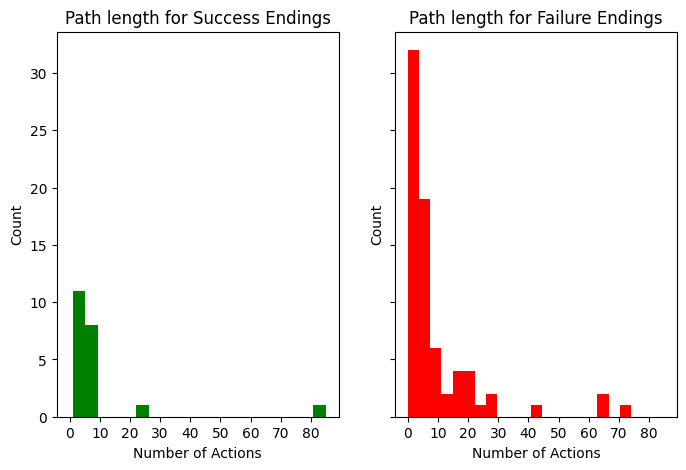

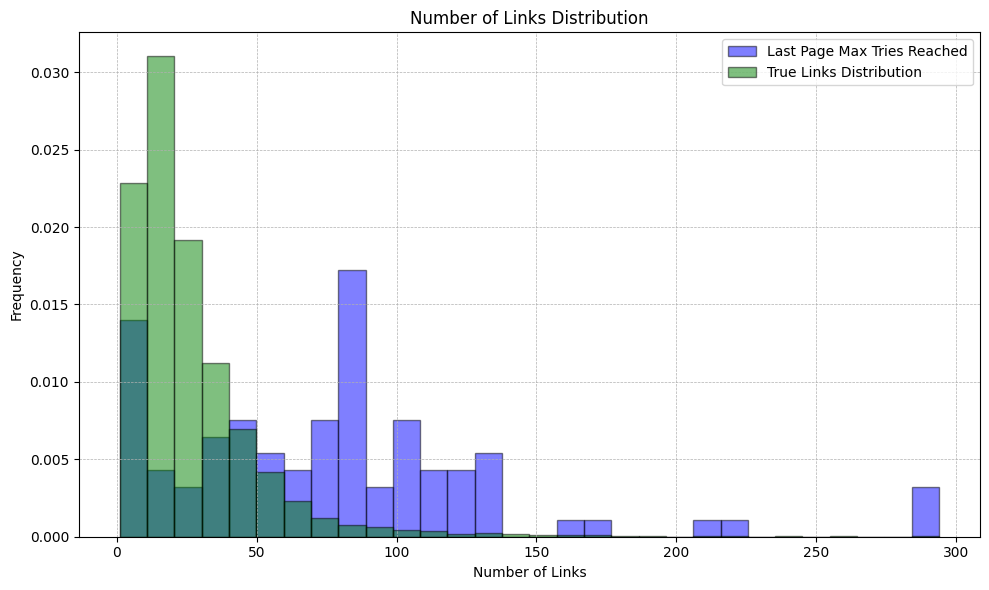

In [89]:
# get article links for some analysis
article_links_df = pd.read_csv(os.path.join(PATH_IN, "article_links.tsv"), sep="\t")
article_links_df['num_links'] = article_links_df.apply(lambda x: len(x['links'].split(";")), axis=1)

runs_df = runs[0]['df'].query('spl>1')
runs_df['last_page'] = runs_df['visited_pages'].apply(lambda x: x.split(';')[-1])
runs_df['num_links_on_last_page'] = runs_df['last_page'].apply(lambda x: article_links_df.query('article==@x')['num_links'].values[0] if x in article_links_df['article'].values else 0)

print("Run configuration:")
print([(key, runs[0][key]) for key in runs[0].keys() if key != 'df'])
print("\n Total number of runs:", len(runs_df))
print("\nPercentage of successful runs:", round(len(runs_df.query('ending=="success"'))/len(runs_df)*100, 1))
print("\nPercentage of failed runs because of max_tries (too many errors)", round(len(runs_df.query('ending=="max_tries"'))/len(runs_df)*100, 1))
print("\nPercentage of failed runs because of max_actions (too many actions)", round(len(runs_df.query('ending=="max_actions"'))/len(runs_df)*100, 1))
print("\nTop 5 longest paths:\n", runs_df.sort_values(by='path_length', ascending=False).head(5)[['src', 'tgt', 'path_length']])
print("\nTop 5 pages that it gets stuck on the most with errors", runs_df.query("ending=='max_tries'")['last_page'].value_counts().head(5))

# Plotting histograms
fig, axs = plt.subplots(1, 2, figsize=(8, 5), sharey=True, sharex=True)
axs[0].set_xticks(range(0, max(runs_df['num_actions']), 10))
axs[1].set_xticks(range(0, max(runs_df['num_actions']), 10))
axs[0].hist(runs_df[runs_df['ending'] == 'success']['num_actions'], bins=20, color='green')
axs[0].set_title('Path length for Success Endings')
axs[0].set_xlabel('Number of Actions')
axs[0].set_ylabel('Count')

axs[1].hist(runs_df[runs_df['ending'] != 'success']['num_actions'], bins=20, color='red')
axs[1].set_title('Path length for Failure Endings')
axs[1].set_xlabel('Number of Actions')
axs[1].set_ylabel('Count')

plt.show()

plt.figure(figsize=(10, 6))

# Histogram for runs_df
plt.hist(runs_df['num_links_on_last_page'], bins=30, color='blue', edgecolor='black', alpha=0.5, label='Last Page Max Tries Reached', density=True)
plt.xlabel('Number of Links')
plt.ylabel('Frequency')
plt.title('Number of Links Distribution')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)

# Histogram for article_links_df
plt.hist(article_links_df['num_links'], bins=30, color='green', edgecolor='black', density=True, alpha=0.5, label='True Links Distribution')

# Add legend
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

Notes:
 - When there are a very low amount of links, the agent seems to make up stuff.
    - Example: last_page=Inductance, response_history = ... '{"next_page": "Electric_circuit"}', '{"next_page": "Galvani"}', '{"next_page": "Galvanism"}'
 - If the page has too many links, it just tries to click on the target: India (81 links), Iran (108 links) France (85 links), etc
    - Example: last_page=France, tgt=Marshall_Plan, response_history = ... '{"next_page": "Marshall_Plan"}', '{"next_page": "Marshall_Plan"}', '{"next_page": "Marshall_Plan"}'
    - Example: last_page=India, tgt=Bill_Gates, response_history = .. '{"next_page": "Bill Gates"}', '{"next_page": "Bill Gates"}', '{"next_page": "Bill Gates"}'
    - **curiously** it only got stuck on United_States 1 time, while the other big pages it got stuck 3 or 2

In [68]:
runs_df.query("ending=='max_tries' and last_page=='Iran'")[['src', 'tgt', 'last_page', 'num_links_on_last_page', 'ending', 'num_actions', 'path', 'response_history']]
#article_links_df.query("article=='Inductance'")

,src,tgt,last_page,num_links_on_last_page,ending,num_actions,path,response_history
27,Tooth_development,Train,Iran,108,max_tries,5,Tooth_development;Vitamin;Thiamine;Sulfur;Turkmenistan;Iran,"['{""next_page"": ""Vitamin""}', '{""next_page"": ""Thiamine""}', '{""next_page"": ""Sulfur""}', '{""next_page"": ""Train""}', '{""next_page"": ""Train""}', '{""next_page"": ""Turkmenistan""}', '{""next_page"": ""Iran""}', '{""next_page"": ""Train""}', '{""next_page"": ""Train""}', '{""next_page"": ""Train""}']"
66,Kosovo,Giant_Panda,Iran,108,max_tries,3,Kosovo;Islam;Qur'an;Iran,"['{""next_page"": ""Islam""}', '{""next_page"": ""Qur\'an""}', '{""next_page"": ""Iran""}', '{""next_page"": ""Giant Panda""}', '{""next_page"": ""Giant Panda""}', '{""next_page"": ""Giant Panda""}']"
89,William_N._Page,African_Grey_Parrot,Iran,108,max_tries,11,William_N._Page;Italy;Austria;Holy Roman Empire;Aachen;Paul of Tarsus;Athens;Parthenon;Persian_Empire;Islam;Mongol Empire;Iran,"['{""next_page"": ""Italy""}', '{""next_page"": ""African_Grey_Parrot""}', '{""next_page"": ""Austria""}', '{""next_page"": ""Austria""}', '{""next_page"": ""Austrian_Czars""}', '{""next_page"": ""Holy Roman Empire""}', '{""next_page"": ""Aachen""}', '{""next_page"": ""Paul of Tarsus""}', '{""next_page"": ""Athens""}', '{""next_page"": ""Africa""}', '{""next_page"": ""Athens""}', '{""next_page"": ""Parthenon""}', '{""next_page"": ""Persian_Empire""}', '{""next_page"": ""Islam""}', '{""next_page"": ""Mongol Empire""}', '{""next_page"": ""Iran""}', '{""next_page"": ""African_Grey_Parrot""}', '{""next_page"": ""African_Grey_Parrot""}', '{""next_page"": ""African_Grey_Parrot""}']"


In [36]:
runs_df['path'].apply(lambda x: x.split(';')[-1]).value_counts().head(10)

path
United States    3
India            3
France           3
Iran             3
Tanzania         3
Sulfur           2
Russia           2
Somalia          2
Gold             2
Islam            2
Name: count, dtype: int64

In [15]:
for run in runs:
    print(f"Config run_id={run['run_id']}, agent type={run['agent']}, fewshot={run['agent.fewshot']}")
    print(f"Number of completed games: {len(run['df'].query('reached_goal==True'))}")
    print()

runs[0]['df'].query("reached_goal == False")[['src', 'tgt', 'path', 'num_actions', 'response_history']]

Config run_id=0, agent type=link_click_dfs_agent, fewshot=5


UndefinedVariableError: name 'reached_goal' is not defined

In [26]:
# Add extra columns to the dfs

# get the llama2 tokenizer
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-2-7b-chat-hf")

# get article links for some analysis
article_links_df = pd.read_csv(os.path.join(PATH_IN, "article_links.tsv"), sep="\t")
article_links_df['num_links'] = article_links_df.apply(lambda x: len(x['links'].split(";")), axis=1)

for run in runs:
    print(run['run_id'])
    run['df']['end_page'] = run['df'].apply(lambda x: x['path'].split(";")[-1], axis=1)
    # response history is a string of the form ['response1', 'response2', ...], we have to use parse
    run['df']['end_response'] = run['df'].apply(lambda x: ast.literal_eval(x['response_history'])[-1], axis=1)
    run['df']["end_user_prompt"]=run['df'].apply(lambda x: ast.literal_eval(x['user_prompt_history'])[-1], axis=1)
    run['df']["end_user_prompt_num_tokens"]=run['df'].apply(lambda x: len(tokenizer.tokenize(x['end_user_prompt'])), axis=1)
    run['df']['end_next_page'] = run['df'].apply(lambda x: parse.search("\"next_page\": \"{}\"", x['end_response'])[0], axis=1)
    run['df']['reached_goal'] = run['df'].apply(lambda x: x['end_page'] == x['tgt'], axis=1)
    run['df']['path_length'] = run['df'].apply(lambda x: len(x['path'].split(";")) - 1, axis=1)
    run['df']['end_response_extracted_json'] = run['df'].apply(lambda x: extract_json_from_response(x['end_response']), axis=1)
    run['df'] = pd.merge(run['df'], article_links_df, left_on='end_page', right_on='article', how='left')

    # rename num_links to end_page_num_links
    run['df'].rename(columns={'num_links': 'end_page_num_links'}, inplace=True)
    run['df'].rename(columns={'links': 'end_page_links'}, inplace=True)



0
1


TypeError: 'NoneType' object is not subscriptable

# Analyse agent run data

In [100]:
PATH_RUNS = "../../logs/inference/multiruns/multiturn_demo_comparison/2023-10-11_17-46-25"

system_demo_df = pd.read_csv(os.path.join(PATH_RUNS, "0/agent_runs.tsv"), sep="\t")
multiturn_demo_df = pd.read_csv(os.path.join(PATH_RUNS, "1/agent_runs.tsv"), sep="\t")

# get the llama2 tokenizer
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-2-7b-chat-hf")

# get article links for some analysis
article_links_df = pd.read_csv(os.path.join(PATH_IN, "article_links.tsv"), sep="\t")
article_links_df['num_links'] = article_links_df.apply(lambda x: len(x['links'].split(";")), axis=1)

# unite these two dfs, and add a column to indicate which system it is
system_demo_df['fewshot_mode'] = 'system_prompt'
multiturn_demo_df['fewshot_mode'] = 'multiturn'
runs_df = pd.concat([system_demo_df, multiturn_demo_df], ignore_index=True)

runs_df['end_page'] = runs_df.apply(lambda x: x['path'].split(";")[-1], axis=1)
# response history is a string of the form ['response1', 'response2', ...], we have to use parse
runs_df['end_response'] = runs_df.apply(lambda x: ast.literal_eval(x['response_history'])[-1], axis=1)
runs_df["end_user_prompt"]=runs_df.apply(lambda x: ast.literal_eval(x['user_prompt_history'])[-1], axis=1)
runs_df["end_user_prompt_num_tokens"]=runs_df.apply(lambda x: len(tokenizer.tokenize(x['end_user_prompt'])), axis=1)
runs_df['end_next_page'] = runs_df.apply(lambda x: parse.search("\"next_page\": \"{}\"", x['end_response'])[0], axis=1)
runs_df['reached_goal'] = runs_df.apply(lambda x: x['end_page'] == x['tgt'], axis=1)
runs_df['path_length'] = runs_df.apply(lambda x: len(x['path'].split(";")) - 1, axis=1)
runs_df['end_response_extracted_json'] = runs_df.apply(lambda x: extract_json_from_response(x['end_response']), axis=1)
runs_df = pd.merge(runs_df, article_links_df, left_on='end_page', right_on='article', how='left')

# rename num_links to end_page_num_links
runs_df.rename(columns={'num_links': 'end_page_num_links'}, inplace=True)
runs_df.rename(columns={'links': 'end_page_links'}, inplace=True)


In [72]:
runs_df.head()


,agent_id,agent_type,src,tgt,path,fewshot,num_actions,num_errors,user_prompt_history,response_history,...,end_response,end_user_prompt,end_user_prompt_num_tokens,end_next_page,reached_goal,path_length,end_response_extracted_json,article,links,end_page_num_links
0,0,LinkClickAgent,Albinism,Tungsten,Albinism;Niger;United_States;Vietnam;Cambodia;...,3,8,2,"[""User: I'm currently on the page Albinism and...","['Assistant:\n{\n ""next_page"": ""Niger""\n}', '...",...,"Assistant:\n{\n ""next_page"": ""Tungsten""\n}",User: I'm currently on the page United_States ...,1869,Tungsten,False,8,"{\n ""next_page"": ""Tungsten""\n}",United_States,Abraham_Lincoln;Advertising;Agriculture;Americ...,294.0
1,1,LinkClickAgent,Heraclius,Gender,Heraclius;Muhammad;Islam;Sultan;Egypt;Sudan,3,5,2,"[""User: I'm currently on the page Heraclius an...","['Assistant:\n{\n ""next_page"": ""Muhammad""\n}'...",...,"Assistant:\n{\n ""next_page"": ""Gender""\n}",User: I'm currently on the page Sudan and the ...,747,Gender,False,5,"{\n ""next_page"": ""Gender""\n}",Sudan,Afghanistan;Africa;African_Union;Albania;Alger...,132.0
2,2,LinkClickAgent,"Salt_Lake_City,_Utah",Drum_and_bass,"Salt_Lake_City,_Utah;Jazz;Miles_Davis;Jazz;Mil...",3,7,2,"[""User: I'm currently on the page Salt_Lake_Ci...","['Assistant:\n{\n ""next_page"": ""Jazz""\n}', 'A...",...,"Assistant:\n{\n ""next_page"": ""Drum_and_bass""\n}",User: I'm currently on the page United_States ...,1873,Drum_and_bass,False,7,"{\n ""next_page"": ""Drum_and_bass""\n}",United_States,Abraham_Lincoln;Advertising;Agriculture;Americ...,294.0
3,3,LinkClickAgent,History_of_post-Soviet_Russia,Oviraptor,History_of_post-Soviet_Russia;Vladimir_Lenin;M...,3,4,2,"[""User: I'm currently on the page History_of_p...","['Assistant:\n{\n ""next_page"": ""Vladimir_Leni...",...,"Assistant:\n{\n ""next_page"": ""Oviraptor""\n}",User: I'm currently on the page United_States ...,1871,Oviraptor,False,4,"{\n ""next_page"": ""Oviraptor""\n}",United_States,Abraham_Lincoln;Advertising;Agriculture;Americ...,294.0
4,4,LinkClickAgent,Archbishop_of_Canterbury,Dead_Sea,Archbishop_of_Canterbury;Thomas_Cranmer;Willia...,3,5,2,"[""User: I'm currently on the page Archbishop_o...","['Assistant:\n{\n ""next_page"": ""Thomas_Cranme...",...,"Assistant:\n{\n ""next_page"": ""Dead_Sea""\n}",User: I'm currently on the page London and the...,666,Dead_Sea,False,5,"{\n ""next_page"": ""Dead_Sea""\n}",London,Alfred_the_Great;Ancient_Rome;Anglicanism;Arse...,102.0


In [77]:
runs_df['end_response_extracted_json'].value_counts()

end_response_extracted_json
{\n  "next_page": "Florida_East_Coast_Railway"\n}    2
{\n  "next_page": "Franklin_D._Roosevelt"\n}         2
{\n  "next_page": "Unix"\n}                          2
{\n  "next_page": "Mark_Twain_House"\n}              2
{\n  "next_page": "Magellanic_Penguin"\n}            2
{\n  "next_page": "Uzbekistan"\n}                    2
{\n  "next_page": "Oviraptor"\n}                     2
{\n  "next_page": "Drum_and_bass"\n}                 2
{\n  "next_page": "Indonesia"\n}                     2
{\n  "next_page": "Nazi_Germany"\n}                  1
{\n  "next_page": "Sega"\n}                          1
{\n  "next_page": "Tibet"\n\n}                       1
{\n  "next_page": "Ireland"\n\n}                     1
{\n  "next_page": "Dr._Seuss"\n}                     1
{\n  "next_page": "Law"\n\n}                         1
{\n  "next_page": "Malaria"\n}                       1
{\n  "next_page": "Tanzania"\n}                      1
{\n  "next_page": "Domestic_goat"\n} 

## Fewshot in system prompt

In [50]:
print("Number of failed runs because of too many actions: ", runs_df.query("fewshot_mode == 'system_prompt' and reached_goal == False and num_actions==15").count().iloc[0])
print("Number of failed runs because of too many invalid actions: ", runs_df.query("fewshot_mode == 'system_prompt' and reached_goal == False and num_errors==2").count().iloc[0])

Number of failed runs because of too many actions:  2
Number of failed runs because of too many invalid actions:  22


In [93]:
print("Number of unparseable json outputs: ", runs_df.query("fewshot_mode == 'system_prompt' and reached_goal == False and end_response_extracted_json.isna()").count().iloc[0])
print(runs_df.query("fewshot_mode == 'system_prompt' and end_response_extracted_json.isna()").end_response.tolist())

Number of unparseable json outputs:  0
[]


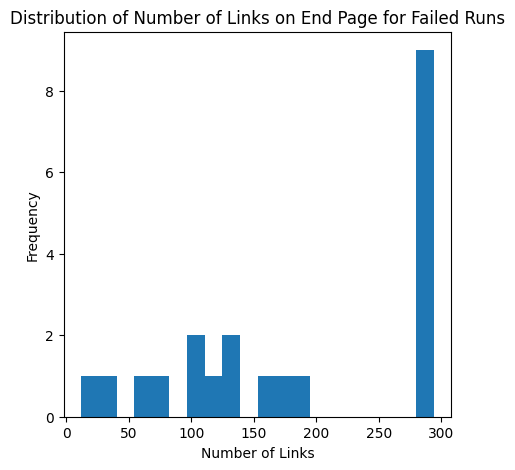

In [64]:
plt.figure(figsize=(5, 5))

runs_df.query("fewshot_mode == 'system_prompt' and num_errors == 2").end_page_num_links.hist(bins=20, grid=False)

plt.title('Distribution of Number of Links on End Page for Failed Runs')
plt.xlabel('Number of Links')
plt.ylabel('Frequency')

plt.show()


In [78]:
runs_df.query("fewshot_mode == 'system_prompt' and num_errors == 2 and end_page == 'United_States'")[['src', 'tgt', 'path', 'num_errors', 'end_page', 'end_response', 'end_response_extracted_json', 'end_next_page']]


,src,tgt,path,num_errors,end_page,end_response,end_response_extracted_json,end_next_page
0,Albinism,Tungsten,Albinism;Niger;United_States;Vietnam;Cambodia;...,2,United_States,"Assistant:\n{\n ""next_page"": ""Tungsten""\n}","{\n ""next_page"": ""Tungsten""\n}",Tungsten
2,"Salt_Lake_City,_Utah",Drum_and_bass,"Salt_Lake_City,_Utah;Jazz;Miles_Davis;Jazz;Mil...",2,United_States,"Assistant:\n{\n ""next_page"": ""Drum_and_bass""\n}","{\n ""next_page"": ""Drum_and_bass""\n}",Drum_and_bass
3,History_of_post-Soviet_Russia,Oviraptor,History_of_post-Soviet_Russia;Vladimir_Lenin;M...,2,United_States,"Assistant:\n{\n ""next_page"": ""Oviraptor""\n}","{\n ""next_page"": ""Oviraptor""\n}",Oviraptor
5,Taoism,Franklin_D._Roosevelt,Taoism;Buddhism;India;United_States,2,United_States,"Assistant:\n{\n ""next_page"": ""Franklin_D._Roo...","{\n ""next_page"": ""Franklin_D._Roosevelt""\n}",Franklin_D._Roosevelt
7,Seawater,Tripoli,Seawater;Ocean;Northern_Mariana_Islands;United...,2,United_States,"Assistant:\n{\n ""next_page"": ""Bahamas""\n}","{\n ""next_page"": ""Bahamas""\n}",Bahamas
10,Romania,U2,Romania;Nadia_Comăneci;Pelé;David_Beckham;Mich...,2,United_States,"Assistant:\n{\n ""next_page"": ""Uzbekistan""\n}","{\n ""next_page"": ""Uzbekistan""\n}",Uzbekistan
13,Novel,Mark_Twain_House,Novel;James_Bond;United_States,2,United_States,"Assistant:\n{\n ""next_page"": ""Mark_Twain_Hous...","{\n ""next_page"": ""Mark_Twain_House""\n}",Mark_Twain_House
16,Star_Trek__Deep_Space_Nine,Zinc,Star_Trek__Deep_Space_Nine;Soviet_Union;Moscow...,2,United_States,"Assistant:\n{\n ""next_page"": ""Zinc""\n}","{\n ""next_page"": ""Zinc""\n}",Zinc
18,Axe,Florida_East_Coast_Railway,Axe;France;United_States,2,United_States,"Assistant:\n{\n ""next_page"": ""Florida_East_Co...","{\n ""next_page"": ""Florida_East_Coast_Railway""\n}",Florida_East_Coast_Railway


In [12]:
# how many paths include United_States
runs_df["includes_us"] = runs_df.apply(lambda x: 'United_States' in x['path'].split(";"), axis=1)
runs_df.query("fewshot_mode == 'system_prompt' and includes_us == True").count()

agent_id                      11
agent_type                    11
src                           11
tgt                           11
path                          11
fewshot                       11
num_actions                   11
num_errors                    11
user_prompt_history           11
response_history              11
fewshot_mode                  11
end_page                      11
end_response                  11
end_user_prompt               11
end_user_prompt_num_tokens    11
end_next_page                 11
reached_goal                  11
path_length                   11
includes_us                   11
dtype: int64

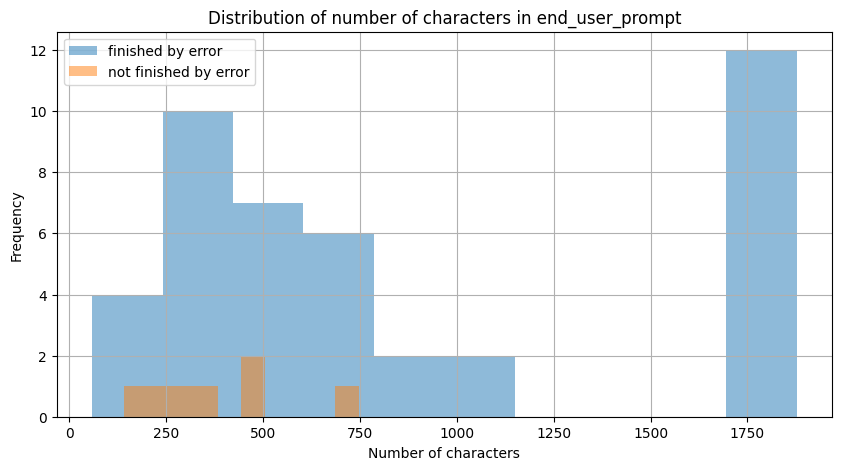

In [13]:
# runs_df.query("fewshot_mode == 'system_prompt' and num_errors == 2").end_user_prompt.tolist()
# runs_df.end_user_prompt.str.len().hist()
# plt.xlabel('Number of characters')
# plt.ylabel('Frequency')
# plt.title('Distribution of number of characters in end_user_prompt')

plt.figure(figsize=(10, 5))

runs_df[runs_df['num_errors'] == 2].end_user_prompt_num_tokens.hist(alpha=0.5, label='finished by error')
runs_df[runs_df['num_errors'] != 2].end_user_prompt_num_tokens.hist(alpha=0.5, label='not finished by error')

plt.xlabel('Number of characters')
plt.ylabel('Frequency')
plt.title('Distribution of number of characters in end_user_prompt')
plt.legend()

plt.show()


## Fewshot multi-turn

In [24]:
runs_df.query("fewshot_mode == 'multiturn' and reached_goal == True")

,agent_id,agent_type,src,tgt,path,fewshot,num_actions,num_errors,user_prompt_history,response_history,fewshot_mode,end_page,end_response,end_user_prompt,end_user_prompt_num_tokens,end_next_page,reached_goal,path_length,includes_us
31,6,LinkClickAgent,Milk,Domestic_goat,Milk;Domestic_goat,3,1,0,"[""I'm currently on the page Milk and the targe...","['{\n ""next_page"": ""Domestic_goat""\n}']",multiturn,Domestic_goat,"{\n ""next_page"": ""Domestic_goat""\n}",I'm currently on the page Milk and the target ...,285,Domestic_goat,True,1,False
38,13,LinkClickAgent,Novel,Mark_Twain_House,Novel;Miguel_de_Cervantes;William_Shakespeare;...,3,8,0,"[""I'm currently on the page Novel and the targ...","['{\n ""next_page"": ""Miguel_de_Cervantes""\n}',...",multiturn,Mark_Twain_House,"{\n ""next_page"": ""Mark_Twain_House""\n}",I'm currently on the page Mark_Twain and the t...,141,Mark_Twain_House,True,8,False
47,22,LinkClickAgent,Nile,Indonesia,Nile;Egypt;Islam;Indonesia,3,3,0,"[""I'm currently on the page Nile and the targe...","['{\n ""next_page"": ""Egypt""\n\n}', '{\n ""next...",multiturn,Indonesia,"{\n ""next_page"": ""Indonesia""\n}",I'm currently on the page Islam and the target...,458,Indonesia,True,3,False


In [28]:
print("Number of failed runs because of too many actions: ", runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False and num_actions==15").count().iloc[0])
print("Number of failed runs because of too many invalid actions: ", runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False and num_errors==2").count().iloc[0])

Number of failed runs because of too many actions:  1
Number of failed runs because of too many invalid actions:  21


In [99]:
runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False and num_errors==0").path.tolist()

['Giant_Panda;DNA;Thomas_Jefferson;Washington, D.C.;Economics;Market;Money;Coin;India;Ramayana;Sanskrit;Vowel;French_language;Vietnam;China;Tibet']

In [30]:
runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False").end_page.value_counts()

end_page
United_States              3
Phosphorus                 1
Great_comet                1
Vietnam                    1
Sound                      1
Los_Angeles,_California    1
Bristol                    1
Moscow                     1
Human                      1
Russia                     1
Tibet                      1
Rhine                      1
Ukraine                    1
Germany                    1
Physics                    1
Volcano                    1
Jerusalem                  1
France                     1
United_Kingdom             1
Time_zone                  1
Name: count, dtype: int64

In [94]:
print("Number of unparseable json outputs: ", runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False and end_response_extracted_json.isna()").count().iloc[0])
print(runs_df.query("fewshot_mode == 'multiturn' and end_response_extracted_json.isna()").end_response.tolist())
runs_df.query("fewshot_mode == 'multiturn' and end_response_extracted_json.isna()")[['src', 'tgt', 'path', 'end_page', 'end_response', 'end_next_page', 'end_response_extracted_json']]

Number of unparseable json outputs:  4
['{\n  "next_page": "Sexism"', '{\n  "next_page": "Metallurgy"\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\necause zinc is a metal, you should click on the "Metallurgy" link to get closer to the target page.', '{\n  "next_page": "Sports"\n\nFrom there, you can click on "Football (soccer)" to get to the page "Boston RFC".', '{\n  "next_page": "Tobacco"']


,src,tgt,path,end_page,end_response,end_next_page,end_response_extracted_json
26,Heraclius,Gender,Heraclius;Muhammad;Women's_rights;Suffrage;Fra...,Rhine,"{\n ""next_page"": ""Sexism""",Sexism,None
41,Star_Trek__Deep_Space_Nine,Zinc,Star_Trek__Deep_Space_Nine;Soviet_Union;Moscow,Moscow,"{\n ""next_page"": ""Metallurgy""\n\n\n\n\n\n\n\n...",Metallurgy,None
42,British_Isles,Boston_RFC,British_Isles;River_Severn;Wales;Rugby_World_C...,Bristol,"{\n ""next_page"": ""Sports""\n\nFrom there, you ...",Sports,None
48,Llywelyn_the_Great,Kuru_(disease),Llywelyn_the_Great;Tower_of_London;H5N1;Vietnam,Vietnam,"{\n ""next_page"": ""Tobacco""",Tobacco,None


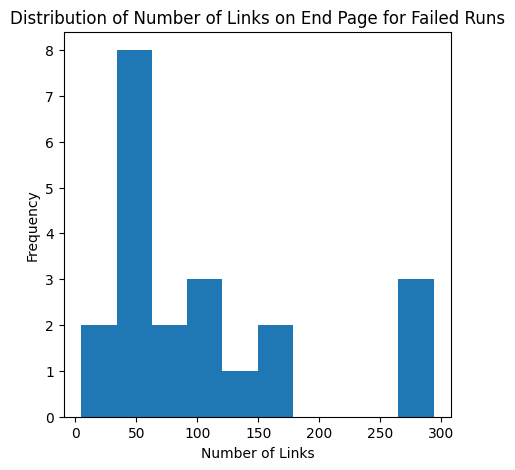

In [67]:
plt.figure(figsize=(5, 5))

runs_df.query("fewshot_mode == 'multiturn' and num_errors == 2").end_page_num_links.hist(grid=False)

plt.title('Distribution of Number of Links on End Page for Failed Runs')
plt.xlabel('Number of Links')
plt.ylabel('Frequency')

plt.show()

In [112]:
# Cases where the tgt page was in the end_page_links but the agent didn't reach it
runs_df.query("not end_page_links.isna()")[runs_df.query("not end_page_links.isna()").apply(lambda x: x['tgt'] in x['end_page_links'].split(";"), axis=1).values]

,agent_id,agent_type,src,tgt,path,fewshot,num_actions,num_errors,user_prompt_history,response_history,...,end_response,end_user_prompt,end_user_prompt_num_tokens,end_next_page,reached_goal,path_length,end_response_extracted_json,article,end_page_links,end_page_num_links
29,4,LinkClickAgent,Archbishop_of_Canterbury,Dead_Sea,Archbishop_of_Canterbury;Rome;Jerusalem,3,2,2,"[""I'm currently on the page Archbishop_of_Cant...","['{\n ""next_page"": ""Rome""\n}', '{\n ""next_pa...",...,"{\n ""next_page"": ""Dead_Sea Scrolls""\n\n}",I'm currently on the page Jerusalem and the ta...,276,Dead_Sea Scrolls,False,2,"{\n ""next_page"": ""Dead_Sea Scrolls""\n\n}",Jerusalem,Albert_Einstein;Ancient_Egypt;Arab-Israeli_con...,40.0
31,6,LinkClickAgent,Milk,Domestic_goat,Milk;Domestic_goat,3,1,0,"[""I'm currently on the page Milk and the targe...","['{\n ""next_page"": ""Domestic_goat""\n}']",...,"{\n ""next_page"": ""Domestic_goat""\n}",I'm currently on the page Milk and the target ...,285,Domestic_goat,True,1,"{\n ""next_page"": ""Domestic_goat""\n}",Domestic_goat,Animal;Bangladesh;Belize;Bible;Brain;Brazil;Bu...,34.0


# Explore Wikispeedia data

In [33]:
article_links_df = pd.read_csv(os.path.join(PATH_IN, "article_links.tsv"), sep="\t")
article_links_df['num_links'] = article_links_df.apply(lambda x: len(x['links'].split(";")), axis=1)
article_links_df.head()

,article,links,num_links
0,Áedán_mac_Gabráin,Bede;Columba;Dál_Riata;Great_Britain;Ireland;I...,11
1,Åland,20th_century;Baltic_Sea;Crimean_War;Currency;E...,19
2,Édouard_Manet,Absinthe;Beer;Claude_Monet;Diego_Velázquez;Edg...,20
3,Éire,Canada;English_language;George_VI_of_the_Unite...,8
4,Óengus_I_of_the_Picts,Dál_Riata;Durham;England;Great_Britain;Ireland...,10


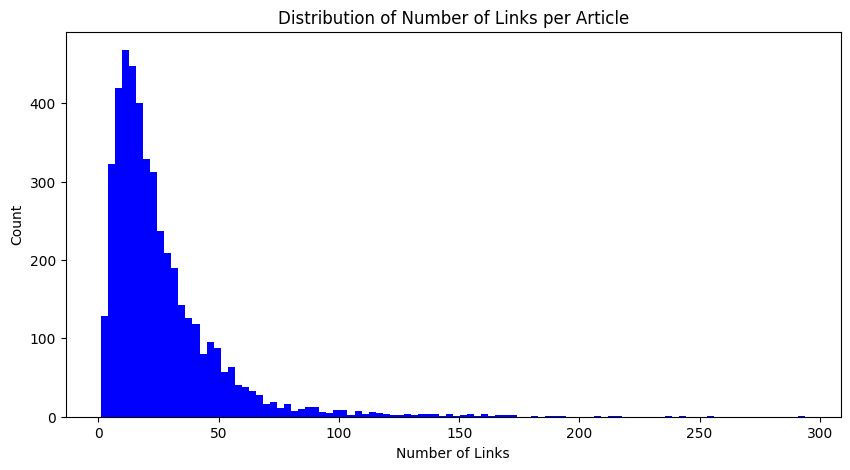

Quantiles of number of links: 0.25    11.0
0.50    19.0
0.75    33.0
0.90    51.0
0.95    67.0
Name: num_links, dtype: float64


In [117]:

plt.figure(figsize=(10, 5))
plt.hist(article_links_df['num_links'], bins=100, color='blue')#, log=True)
plt.xlabel('Number of Links')
plt.ylabel('Count')
plt.title('Distribution of Number of Links per Article')
plt.show()

print(f"Quantiles of number of links: {article_links_df['num_links'].quantile([0.25, 0.5, 0.75, 0.9, 0.95])}")

In [116]:
# average number of links per article
article_links_df['num_links'].mean()

26.13516459559625

In [47]:
# top 10 pages with most links
from pprint import pprint
pprint([(row['article'], row['num_links']) for _, row in article_links_df.sort_values(by='num_links', ascending=False).head(10).iterrows()])


[('United_States', 294),
 ('Driving_on_the_left_or_right', 255),
 ('List_of_countries', 244),
 ('List_of_circulating_currencies', 236),
 ('List_of_sovereign_states', 216),
 ('Africa', 212),
 ('List_of_countries_by_system_of_government', 207),
 ('Lebanon', 192),
 ('Interpol', 191),
 ('Armenia', 186)]


# Build paths_real_processed_df
`paths_real_df` (from Akhil) has the columns:
 - hashed_ip: user identifier
 - timestamp: time of the game
 - src, tgt: source and target pages
 - is_path_finished: whether the user reached the target page
 - failure_type: reason for failure (restart, timout, ...)
 - path: path taken (including backtracks)
 - hpl: Human Path Length (number of clicks by human, including backtracks)
 - spl: Shortest Path Length (shortest possible path length for that pair)
 - duration_in_sec: time taken by user
 - target_in_degree: number of incoming links to target page
 - user_path_rating: 1-5 rating of path difficulty by user

We're gonna add:
 - shpl: Shortest Human Path Length (lowest number of clicks by human, for that pair)
 - effective_path: path taken by user excluding backtracks
 - shortest_effective_path: shortest effective path made by human, for that pair
 - hepl: Human Effective Path Length (effective path length for that game instance)
 - shepl: Shortest Human Effective Path Length (shortest effective path length made by human, for that pair)

The final df is `paths_real_processed_df`

In [115]:
# `paths_real_df` (from Akhil) has the columns:
#  - hashed_ip: user identifier
#  - timestamp: time of the game
#  - src, tgt: source and target pages
#  - is_path_finished: whether the user reached the target page
#  - failure_type: reason for failure (restart, timout, ...)
#  - path: path taken (including backtracks)
#  - hpl: Human Path Length (number of clicks by human, including backtracks)
#  - spl: Shortest Path Length (shortest possible path length for that pair)
#  - duration_in_sec: time taken by user
#  - target_in_degree: number of incoming links to target page
#  - user_path_rating: 1-5 rating of path difficulty by user

# We're gonna add:
#  - shpl: Shortest Human Path Length (lowest number of clicks by human, for that pair)
#  - effective_path: path taken by user excluding backtracks
#  - shortest_effective_path: shortest effective path made by human, for that pair
#  - hepl: Human Effective Path Length (effective path length for that game instance)
#  - shepl: Shortest Human Effective Path Length (shortest effective path length made by human, for that pair)

# The final df is `paths_real_processed_df`

paths_real_processed_df = pd.read_csv(PATH_IN + 'paths_real_df.csv')

paths_real_processed_df["effective_path"] = paths_real_processed_df.apply(lambda row: effective_path(row["path"]), axis=1)
paths_real_processed_df["hepl"] = paths_real_processed_df.apply(lambda row: len(row["effective_path"].split(";"))-1, axis=1)

# add a column that is the shortest human path length for that pair, by choosing the minimum path_length for all games with that pair
shpl = paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hpl": "min"}).reset_index().rename(columns={"hpl": "shpl"})
shepl = paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hepl": "min"}).reset_index().rename(columns={"hepl": "shepl"})
# the shortest effective path is the path with the minimum hepl for that pair
paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hepl": "min"}).reset_index().rename(columns={"effective_path": "shortest_effective_path"})

# paths_real_processed_df = pd.merge(paths_real_processed_df, shpl, on=['src', 'tgt'], how='left')
# paths_real_processed_df = pd.merge(paths_real_processed_df, shepl, on=['src', 'tgt'], how='left')
# paths_real_processed_df = pd.merge(paths_real_processed_df, shortest_effective_path, on=['src', 'tgt'], how='left')

# paths_real_processed_df

,src,tgt,hepl
0,10th_century,11th_century,1
1,10th_century,Banknote,4
2,10th_century,Country,2
3,10th_century,Harlem_Globetrotters,3
4,10th_century,History_of_democracy,5
...,...,...,...
28713,Zulu,Language,2
28714,Zulu,Slovenia,3
28715,Zürich,Billie_Holiday,4
28716,Zürich,Mediterranean_Sea,3


In [ ]:
paths_real_processed_df.to_csv(PATH_IN + 'paths_real_processed.tsv', sep='\t', index=False)